# Import and Helpers

In [1]:
import mitsuba as mi
import drjit as dr

import numpy as np
from math import ceil

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from copy import copy

import importlib
import sys
from pathlib import Path

from PIL import Image

import os

if os.name == 'nt':
    sys.path.append(os.getcwd() + "\\..\\src")    
else:
    sys.path.append(os.getcwd() + "/../src")

# print(sys.path)
# print(mi.variants())

# mi.set_variant("llvm_ad_rgb")

os.environ["OPENCV_IO_ENABLE_OPENEXR"]="1"
import cv2

mi.set_variant("cuda_ad_rgb")

import torch
import numpy as np
import tqdm
import time

import pickle

import normflows as nf

import tinycudann as tcnn
import pprint

from scipy.ndimage import gaussian_filter1d

import matplotlib.pyplot as plt
from dataclasses import dataclass

from coordinate_system import CoordinateSystem

import renderers
import scenes
import targets
import models
import priors
import normalizing_flows
import input_encodings
import kernels
import utils
import contexts

importlib.reload(renderers)
importlib.reload(scenes)
importlib.reload(targets)
importlib.reload(models)
importlib.reload(priors)
importlib.reload(normalizing_flows)
importlib.reload(input_encodings)
importlib.reload(kernels)
importlib.reload(utils)
importlib.reload(contexts)

import renderers as rr
import scenes
import targets
import models
import priors
import normalizing_flows
from input_encodings import (build_hashgrid_encoding_conf, 
                             build_identity_encoding_conf, 
                             build_one_blob_encoding_conf,
                             build_spherical_harmonics_encoding)
import utils
import kernels
from contexts import Context

jitc_llvm_init(): LLVM API initialization failed ..
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\tinycudann\modules.py:58: UserWarning: tinycudann was built for lower compute capability (52) than the system's (86). Performance may be suboptimal.
  warnings.warn(f"tinycudann was built for lower compute capability ({cc}) than the system's ({system_compute_capability}). Performance may be suboptimal.")


In [2]:
def get_encodings(input_dim, 
                  normal_context_size, 
                  in_dir_context_size,
                  pos_context_size, 
                  pos_is_hash_grid=True,
                  encode_normal_each_flow = False, 
                  encode_in_dir_each_flow = False,
                  encode_pos_each_flow = True,
                  hash_grid_log2_size: int = 19, 
                  latent_to_hash_enc = False):
    direction_encoding, latent_context_size = build_one_blob_encoding_conf(input_dim, 32)

    pos_hash_grid_size = pos_context_size
    if latent_to_hash_enc:
        pos_hash_grid_size += 1

    # normal_encoding, normal_enc_out = build_one_blob_encoding_conf(normal_context_size, 32) 

    # normal_encoding, normal_enc_out = (build_hashgrid_encoding_conf(normal_context_size, 16, 2) 
    #                                     if normal_context_size == 2 or normal_context_size == 3
    #                                     else build_one_blob_encoding_conf(normal_context_size, 16))
    
    normal_encoding, normal_enc_out = (build_spherical_harmonics_encoding(normal_context_size, 4) 
                                        if normal_context_size == 2 or normal_context_size == 3
                                        else build_one_blob_encoding_conf(normal_context_size, 8))

    # in_dir_encoding, in_dir_enc_out = build_one_blob_encoding_conf(in_dir_context_size, 16)

    in_dir_encoding, in_dir_enc_out = (build_spherical_harmonics_encoding(in_dir_context_size, 4) 
                                        if in_dir_context_size == 2 or in_dir_context_size == 3
                                        else build_one_blob_encoding_conf(in_dir_context_size, 8))

    if pos_is_hash_grid:
        positional_encoding, pos_enc_out = (build_hashgrid_encoding_conf(pos_hash_grid_size, levels=8, features_per_level=2, log2_hashmap_size=hash_grid_log2_size)                                         
                                            if pos_hash_grid_size == 2 or pos_hash_grid_size == 3 or pos_hash_grid_size == 4
                                            else build_one_blob_encoding_conf(pos_hash_grid_size, 16))
    else:
        positional_encoding, pos_enc_out = build_one_blob_encoding_conf(pos_hash_grid_size, 32)


    flow_normal_input = (normal_context_size if encode_normal_each_flow else normal_enc_out) if normal_context_size > 0 else 0
    flow_in_dir_input = (in_dir_context_size if encode_in_dir_each_flow else in_dir_enc_out) if in_dir_context_size > 0 else 0
    flow_pos_input =    (pos_context_size if encode_pos_each_flow else pos_enc_out)          if pos_context_size    > 0 else 0

    identity_normal_encoding, _ = build_identity_encoding_conf(flow_normal_input)
    identity_in_dir_encoding, _ = build_identity_encoding_conf(flow_in_dir_input)
    identity_position_encoding, _ = build_identity_encoding_conf(flow_pos_input)

    model_enc_list = []
    if normal_context_size > 0: model_enc_list.append(normal_encoding if not encode_normal_each_flow  else identity_normal_encoding)
    if in_dir_context_size > 0: model_enc_list.append(in_dir_encoding if not encode_in_dir_each_flow  else identity_in_dir_encoding)
    if pos_context_size > 0: model_enc_list.append(positional_encoding if not encode_pos_each_flow    else identity_position_encoding)

    model_enc = None
    model_encoding_config = None
    if len(model_enc_list) > 0:
        model_encoding_config = {
            "otype": "Composite",
            "nested": model_enc_list
        }
        model_encoding_input_size = normal_context_size + in_dir_context_size + pos_context_size

        model_enc = tcnn.Encoding(model_encoding_input_size, model_encoding_config)


    flow_enc_list = []
    
    if latent_context_size > 0: flow_enc_list.append(direction_encoding)
    if normal_context_size > 0: flow_enc_list.append(normal_encoding  if encode_normal_each_flow  else identity_normal_encoding)
    if in_dir_context_size > 0: flow_enc_list.append(in_dir_encoding  if encode_in_dir_each_flow  else identity_in_dir_encoding)
    if pos_context_size > 0: flow_enc_list.append(positional_encoding if encode_pos_each_flow     else identity_position_encoding)


    flow_encoding_config = {
        "otype": "Composite",
        "nested": flow_enc_list
    }

    model_context_out = model_enc.n_output_dims if model_enc else 0
    flow_enc = tcnn.Encoding(model_context_out + 1, flow_encoding_config)

    return model_encoding_config, flow_encoding_config, flow_normal_input + flow_in_dir_input + flow_pos_input


In [3]:
def build_Normflow_model(prior, 
                         domain,
                         coordinate_system,
                         scene: mi.Scene,
                         num_flows = 4,
                         num_bins = 8,
                         hidden_units = 32, 
                         hidden_layers = 2,
                         do_normal_encoding = True, 
                         do_in_dir_encoding = False, 
                         do_pos_encoding = False,
                         encode_normal_each_flow = False,
                         encode_in_dir_each_flow = False,
                         pos_is_hash_grid = True, 
                         encode_pos_each_flow = True,
                         hash_grid_log2_size = 19, 
                         latent_to_hash_enc = False,
                         scaling_grid_sizes = False,
                         grid_resolutions = None,
                         levels           = None,     
                         scale_factors    = None) -> models.AbstractModel:
    

    input_dim           = 1 if not latent_to_hash_enc else 0

    normal_context_size = 3 if do_normal_encoding else 0
    in_dir_context_size = 3 if do_in_dir_encoding else 0
    pos_context_size    = 3 if do_pos_encoding    else 0

    if latent_to_hash_enc and not encode_pos_each_flow:
        raise RuntimeError("If latent variable is hash encoded positional encoding needs to be encoded for each flow")

    model_enc_config, flow_enc_config, flow_context_size = get_encodings(input_dim, 
                                                                         normal_context_size, 
                                                                         in_dir_context_size,
                                                                         pos_context_size, 
                                                                         pos_is_hash_grid=pos_is_hash_grid, 
                                                                         encode_normal_each_flow=encode_normal_each_flow,
                                                                         encode_in_dir_each_flow=encode_in_dir_each_flow,
                                                                         encode_pos_each_flow=encode_pos_each_flow,
                                                                         hash_grid_log2_size=hash_grid_log2_size,
                                                                         latent_to_hash_enc=latent_to_hash_enc)

    # pprint.pprint(model_enc_config)
    # print("------")
    # pprint.pprint(flow_enc_config)
    # print("------")
    # print(flow_context_size)


    net_config = {
        "otype": "FullyFusedMLP",    # Component type.
        "activation": "ReLU",        # Activation of hidden layers.
        "output_activation": "None", # Activation of the output layer.
        "n_neurons": hidden_units,            # Neurons in each hidden layer.
                                    # May only be 16, 32, 64, or 128.
        "n_hidden_layers": hidden_layers,        # Number of hidden layers.
    }
    

    flows = []
    # grid_resolutions = [4 , 4 , 8 , 8 , 16 , 16 , 32 , 32]
    if grid_resolutions is None:
        grid_resolutions = [16] * num_flows
    
    if levels is None:
        levels = [8] * num_flows

    if scale_factors is None:
        scale_factors = [2.0] * num_flows


    # grid_resolutions = [4 , 4 , 6 , 6 , 8 , 8 , 12 , 12]
    # levels           = [2  , 2  , 4  , 4  , 5  , 5  , 6  , 6]       
    # scale_factors     = [1.0, 1.0, 1.5, 1.5, 2.0, 2.0, 3.0, 3.0]

    # grid_resolutions = [16] * 8
    # levels           = [8] * 8     
    # scale_factor     = [2.0] * 8

    

    for i in range(num_flows):
        if do_pos_encoding and scaling_grid_sizes:

            # Compute index where the hash grid encoding is
            pos_encodings_index = 1 if do_normal_encoding else 0
            if not latent_to_hash_enc:
                pos_encodings_index += 1

            if do_in_dir_encoding:
                pos_encodings_index += 1

            flow_enc_config['nested'][pos_encodings_index]['n_levels']        = levels[i]
            flow_enc_config['nested'][pos_encodings_index]['per_level_scale'] = scale_factors[i]
            flow_enc_config['nested'][pos_encodings_index]['base_resolution'] = grid_resolutions[i]

        flows += [normalizing_flows.NeuralSplineFlow(num_bins, flow_context_size, flow_enc_config, net_config, latent_to_hash_grid = latent_to_hash_enc)]

    

    return models.NormalizingFlowModel(prior, 
                                       flows, 
                                       normal_context_size + in_dir_context_size + pos_context_size,
                                       coordinate_system,
                                       scene_bbox = scene.bbox(),
                                       has_normal_encoding = do_normal_encoding,
                                       has_incoming_encoding = do_in_dir_encoding,
                                       has_positional_encoding = do_pos_encoding,
                                       context_encoding_conf = model_enc_config,
                                       domain=domain)

def buildReparamModel(features, 
                    prior, 
                    encoding,
                    domain,
                    hidden_layers = 2, 
                    hidden_units = 16):
    hidden_layers = [hidden_units] * (hidden_layers + 1)

    return models.ReparameterizationModel(features, prior, encoding, hidden_layers, domain=domain)

def buildNaiveModel(features, 
                    prior, 
                    encoding,
                    domain,
                    hidden_layers = 2, 
                    hidden_units = 16):
    hidden_layers = [hidden_units] * (hidden_layers + 1)

    return models.NaiveForwardModel(features, prior, encoding, hidden_layers, domain=domain)

def sample_normals(num_samples, device):
    domain = torch.tensor([[2 * torch.pi, torch.pi]], device = device)
    phi_theta = torch.rand((num_samples, 2), device = device) * domain
    return utils.to_vec3_torch(phi_theta[..., 0], phi_theta[..., 1])

def sample_random_dirs(num_samples, device):
    pos = torch.randn((num_samples, 3), device = device, dtype=torch.float32)
    return torch.nn.functional.normalize(pos, dim = -1)

def load_reference(scene_name):
    ref_dir = "../../thesis_assets/images/references"
    file_path = f"{ref_dir}/reference_{scene_name}.exr"

    img = cv2.imread(file_path, cv2.IMREAD_ANYCOLOR | cv2.IMREAD_ANYDEPTH)
    if img is not None:
        return img[:, :, ::-1]
    
    return None

def compute_reference(renderer, w, h, ref_spp, bounces = 4):
    rCtx = Context(bounces=bounces, spp=ref_spp, bsdf_sampling=True, emitter_sampling=True, mis_beta=2)
    return renderer.render(w, h, rCtx)

def compute_error_on_images(image, ref, metric = 'MAPE'):
    eps = 0.01
    if metric is 'MAPE':
        return np.mean(np.abs(image - ref) / (np.abs(ref) + eps), axis = None) 
    elif metric is 'SMAPE':
        error_image_smape = np.abs(image - ref) / (np.abs(ref) + np.abs(image) + eps)
        return 2 * np.mean(error_image_smape, axis = None) 
    elif metric is 'MAE':
        return np.mean(np.abs(image - ref), axis = None)
    elif metric is 'RMSE':
        return np.sqrt(np.mean(np.square(image - ref), axis = None))
    else:
        raise RuntimeError(f"Not a valid error metric: {metric}")

def compute_error_metric(renderer, 
                model, 
                w, 
                h, 
                ref_image = None, 
                ref_spp = 128, 
                model_spp = 1, 
                plot = True,
                num_test_images = 1, 
                tonemap = True, 
                gamma_correct = True, 
                show_error_image = True,
                display_error_metric = 'MAPE', # Can currently compute MAPE, SMAPE, MAE, MRSE
                ref_image_label = None,
                rCtx = None):
    
    if rCtx is None:
        rCtx = Context(bounces=4, spp=ref_spp, bsdf_sampling=True, emitter_sampling=True, mis_beta=2)
    
    rCtx.spp = ref_spp
    was_none = False
    if ref_image is None:
        was_none = True
        ref_image_dr = compute_reference(renderer, w, h, ref_spp)
        ref_image = utils.res_to_numpy_3(ref_image_dr, w, h)

        if tonemap:
            ref_image = utils.tonemap(ref_image)

        if gamma_correct:
            ref_image = utils.gamma_correct(ref_image)
    
    
    
    rCtx.spp = model_spp
    MAPE =  0
    SMAPE = 0
    MAE =   0
    RMSE =  0

    for i in range(num_test_images):
        model_res_dr = renderer.render_with_model(w, h, model, rCtx)
        model_res = utils.res_to_numpy_3(model_res_dr, w, h)

        if tonemap:
            model_res = utils.tonemap(model_res)

        if gamma_correct:
            model_res = utils.gamma_correct(model_res)

        # eps = 0.01
        # abs_diff = np.abs(model_res - ref_image)

        # error_image_mape = abs_diff / (ref_image + eps)
        # MAPE += np.mean(error_image_mape, axis = None) 
            
        # error_image_smape = abs_diff / (np.abs(ref_image) + np.abs(model_res) + eps)
        # SMAPE += 2 * np.mean(error_image_smape, axis = None) 

        # error_image_mae = abs_diff
        # MAE += np.mean(error_image_mae, axis = None)
        
        # error_image_rmse = np.square(model_res - ref_image)
        # RMSE += np.sqrt(np.mean(error_image_rmse, axis = None))



        eps = 0.01
        MAPE += np.mean(np.abs(model_res - ref_image) / (ref_image + eps), axis = None) 

        error_image_smape = np.abs(model_res - ref_image) / (np.abs(ref_image) + np.abs(model_res) + eps)
        SMAPE += 2 * np.mean(error_image_smape, axis = None) 

        MAE += np.mean(np.abs(model_res - ref_image), axis = None)
        
        RMSE += np.sqrt(np.mean(np.square(model_res - ref_image), axis = None))
        
    
    mean_MAPE  = MAPE.item()  / num_test_images
    mean_SMAPE = SMAPE.item() / num_test_images
    mean_MAE   = MAE.item()   / num_test_images
    mean_RMSE  = RMSE.item()  / num_test_images

    error_dict = {
        'MAPE':  mean_MAPE,
        'SMAPE': mean_SMAPE,
        'MAE':   mean_MAE,
        'RMSE':  mean_RMSE
    }

    if not plot:
        return error_dict

    
    fig, axs = plt.subplots(1, 3, figsize = (15, 5)) if show_error_image else plt.subplots(1, 2, figsize = (10, 5))

    axs[0].imshow(model_res)
    axs[0].set_title(f"model path guided ({model_spp} spp)")

    ref_caption = f"reference ({ref_spp} spp)" if was_none else "reference"
    if ref_image_label is not None:
        ref_caption = f"{ref_image_label} ({ref_spp} spp)"

    axs[1].set_title(ref_caption)

    if show_error_image:
        error_image = None
        if display_error_metric == 'MAPE':
            error_image = error_image_mape
        elif display_error_metric == 'SMAPE':
            error_image = error_image_smape
        elif display_error_metric == 'MAE':
            error_image = error_image_mae
        elif display_error_metric == 'RMSE':
            error_image = error_image_rmse
        else:
            raise RuntimeError("Not a valid error metric given for pixelwise display")

        err_image_np  = utils.res_to_numpy_3(error_image, w, h)

        axs[2].imshow(err_image_np)
        axs[2].set_title(f"pixelwise error ({display_error_metric})")

    return fig, error_dict

<>:158: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
<>:160: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
<>:163: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
<>:165: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
C:\Users\janlu\AppData\Local\Temp\ipykernel_2576\1927239985.py:158: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  if metric is 'MAPE':
C:\Users\janlu\AppData\Local\Temp\ipykernel_2576\1927239985.py:160: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  elif metric is 'SMAPE':
C:\Users\janlu\AppData\Local\Temp\ipykernel_2576\1927239985.py:163: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  elif metric is 'MAE':
C:\Users\janlu\AppData\Local\Temp\ipykernel_2576\1927239985.py:165: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  elif metric is 'RMSE':


In [4]:
@dataclass
class ExperimentSetup:
    # Setup Info
    coordinate_system: CoordinateSystem
    prior_str: str
    scene_name: str

    # NN info
    num_flows: int
    num_bins: int
    hidden_units: int
    hidden_layers: int

    # learning rate
    lr: float

    # Encoding Info
    do_normal_encoding: bool
    do_in_dir_encoding: bool
    do_pos_encoding: bool
    
    pos_is_hash_grid: bool
    encode_pos_each_flow: bool
    latent_to_hashgrid: bool
    do_scaling_grid_sizes: bool

    grid_resolutions: list[int]
    grid_levels: list[int]
    grid_scale_factors: list[float]
    hash_grid_log2_size: int = 19 # Need to do this because I am not sure I can automatically load older versions otherwise

@dataclass
class Experiment:
    setup: ExperimentSetup

    # Info from training
    trained_iterations: int
    sample_gen_strategy: str
    sample_model: bool
    losses: list[int]
    tracked_errors: bool
    tracked_error_every: int
    mape_list: list[int]
    smape_list: list[int]
    mae_list: list[int]
    rmse_list: list[int]
    error_calcs_clipped: bool
    model: models.NormalizingFlowModel | None
    model_path: str | None = None



In [5]:
def create_model(
        coordinate_system,
        prior_str,
        scene,
        do_normal_encoding = True,
        do_in_dir_encoding = True,
        do_pos_encoding    = True,
        num_flows = 8,
        num_bins = 8,
        hidden_units = 64, 
        hidden_layers = 2,
        pos_is_hash_grid = True,
        encode_pos_each_flow = True,
        latent_to_hash_enc = True,
        hash_grid_log2_size = 19,
        scaling_grid_sizes = False):
    
    
    enable_cuda = True
    device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')

    # coordinate_system = CoordinateSystem.Cylindrical
    domain = utils.get_domain_from_coords(coordinate_system, device)


    if prior_str == 'cosine':
        prior = priors.CosineWeighted(coordinate_system)
    elif prior_str == 'uniform':
        prior = priors.UniformPrior(domain, coordinate_system)
    else:
        raise RuntimeError(f"{prior_str} is not a valid prior string.")
    
    model: models.AbstractModel = build_Normflow_model(prior, 
                                                    domain, 
                                                    coordinate_system,
                                                    scene=scene,
                                                    num_flows = num_flows, 
                                                    num_bins = num_bins, 
                                                    hidden_units=hidden_units, 
                                                    hidden_layers=hidden_layers,
                                                    do_normal_encoding=do_normal_encoding,
                                                    do_in_dir_encoding=do_in_dir_encoding,
                                                    do_pos_encoding=do_pos_encoding,
                                                    pos_is_hash_grid = pos_is_hash_grid,
                                                    encode_pos_each_flow = encode_pos_each_flow,
                                                    hash_grid_log2_size = hash_grid_log2_size,
                                                    latent_to_hash_enc   = latent_to_hash_enc,
                                                    scaling_grid_sizes   = scaling_grid_sizes,
                                                    grid_resolutions = None,
                                                    levels           = None,     
                                                    scale_factors    = None)



    model.to(device)
    print(f"using device: {device}")

    # fig = model.visualize(renderer)
    # plt.show()

    return model


def create_model_from_Setup(setup: ExperimentSetup):
    enable_cuda = True
    device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')

    # coordinate_system = CoordinateSystem.Cylindrical
    domain = utils.get_domain_from_coords(setup.coordinate_system, device)


    if setup.prior_str == 'cosine':
        prior = priors.CosineWeighted(setup.coordinate_system)
    elif setup.prior_str == 'uniform':
        prior = priors.UniformPrior(domain, setup.coordinate_system)
    else:
        raise RuntimeError(f"{setup.prior_str} is not a valid prior string.")
    
    scene = scenes.get_scene_by_name(setup.scene_name)

    model: models.AbstractModel = build_Normflow_model(prior, 
                                                    domain, 
                                                    setup.coordinate_system,
                                                    scene=scene,
                                                    num_flows = setup.num_flows, 
                                                    num_bins = setup.num_bins, 
                                                    hidden_units=setup.hidden_units, 
                                                    hidden_layers=setup.hidden_layers,
                                                    do_normal_encoding=setup.do_normal_encoding,
                                                    do_in_dir_encoding=setup.do_in_dir_encoding,
                                                    do_pos_encoding=setup.do_pos_encoding,
                                                    pos_is_hash_grid = setup.pos_is_hash_grid,
                                                    encode_pos_each_flow = setup.encode_pos_each_flow,
                                                    hash_grid_log2_size = setup.hash_grid_log2_size,
                                                    latent_to_hash_enc   = setup.latent_to_hashgrid,
                                                    scaling_grid_sizes   = setup.do_scaling_grid_sizes,
                                                    grid_resolutions = setup.grid_resolutions,
                                                    levels           = setup.grid_levels,     
                                                    scale_factors    = setup.grid_scale_factors)



    model.to(device)
    print(f"using device: {device}")

    # fig = model.visualize(renderer)
    # plt.show()

    return model

In [6]:
def load_model_from_experiment(exp: Experiment):
    return exp.model

def renderer_from_experiment(exp: Experiment, w, h, bounces, spp):
    scene = scenes.get_scene_by_name(exp.setup.scene_name)

    rCtx = contexts.Context(
        bounces = bounces,
        spp = spp,
        width = w,
        height = h
    )
    return rr.Renderer(scene, rCtx, exp.setup.coordinate_system)

In [7]:
### Functions to build visualizations

def find_error_metric_by_name(exp: Experiment, error_metric, start_index = 0, end_index = None):
    if error_metric == 'MAPE':
        return exp.mape_list[start_index: end_index]
    elif error_metric == 'SMAPE':
        return exp.smape_list[start_index: end_index]
    elif error_metric == 'MAE':
        return exp.mae_list[start_index: end_index]
    elif error_metric == 'RMSE':
        return exp.rmse_list[start_index: end_index]
    else:
        raise RuntimeError(f"Invalid error metric {error_metric}")

def compare_error_metrics(experiments: list[Experiment], 
                          labels: list[str], 
                          error_metric: str, 
                          target_dir = "",
                          legend: bool = True, 
                          logx: bool = False, 
                          logy: bool = False, 
                          save: bool = True, 
                          display: bool = False, 
                          line_width: float | list[float] = 1.0,
                          start_index: int = 0, 
                          end_index: int = None,
                          smooth_lines: bool = False,
                          transparent_unsmoothed = False, 
                          kernel_sigma: int = 5.0,
                          axis_labels = True):
    if len(experiments) is not len(labels):
        raise RuntimeError("each experiment needs a label")

    if type(line_width) is float or type(line_width) is int:
        line_width = [line_width] * len(experiments)

    max_train_its = max([exp.trained_iterations for exp in experiments])

    error_lists = [find_error_metric_by_name(e, error_metric, start_index, end_index) for e in experiments]

    smoothed = [gaussian_filter1d(e, kernel_sigma, mode='reflect') for e in error_lists] if smooth_lines else []


    fig_all = plt.figure()

    ax_all = fig_all.add_subplot(111)

    for i in range(len(error_lists)):
        fig = plt.figure()

        ax = fig.add_subplot(111)

        if smooth_lines:
            p = ax.plot(smoothed[i], label=labels[i], linewidth=line_width[i])
            if transparent_unsmoothed:
                ax.plot(error_lists[i], linewidth=1, alpha=0.3, color=p[0].get_color())
        else:
            ax.plot(error_lists[i], label=labels[i], linewidth=line_width[i])

        if legend:
            ax.legend()
        if axis_labels:
            ax.set_xlabel("Training Iterations")
            ax.set_ylabel(error_metric)
        if logx and logy:
            ax.loglog()
        elif logx:
            ax.semilogx()
        elif logy:
            ax.semilogy()

        ax.xaxis.set_major_formatter(lambda x, pos: f"{experiments[0].tracked_error_every * x:g}")

        if save:
            fig.savefig(f"{target_dir}/{error_metric}_over_training_{labels[i]}.pdf", bbox_inches='tight')
        plt.close()

        if smooth_lines:
            p = ax_all.plot(smoothed[i], label=labels[i], linewidth=line_width[i])
            if transparent_unsmoothed:
                ax_all.plot(error_lists[i], linewidth=1, alpha=0.3, color=p[0].get_color())
        else:
            ax_all.plot(error_lists[i], label=labels[i], linewidth=line_width[i])

    if legend:
        ax_all.legend()
    if axis_labels:
        ax_all.set_xlabel("Training Iterations")
        ax_all.set_ylabel(error_metric)
    if logx and logy:
        ax_all.loglog()
    elif logx:
        ax_all.semilogx()
    elif logy:
        ax_all.semilogy()

    ax_all.xaxis.set_major_formatter(lambda x, pos: f"{experiments[0].tracked_error_every * x:g}")

    if save:
        # plt.savefig(f"{target_dir}/{error_metric}_over_training.png", dpi = 300)
        fig_all.savefig(f"{target_dir}/{error_metric}_over_training.pdf", bbox_inches='tight')
    
    if display:
        fig_all.show()
    else:
        plt.close()


def apply_patches_and_save(image, 
                           patch_list: list[patches.Rectangle], 
                           color_list, 
                           label, 
                           target_dir, 
                           spp: int, 
                           save: bool = True,
                           display: bool = False, 
                           error_metric = 'MAPE', 
                           error = 0.0, 
                           patch_outline_width = 2, 
                           axis_off = True, 
                           patch_has_outline = True,
                           is_reference = True):
    fig = plt.figure(frameon=False)
    dpi_scale = 100

    H, W = image.shape[:2]
    fig.set_size_inches(W / dpi_scale, H / dpi_scale) 
    ax = plt.Axes(fig, [0, 0, 1, 1])
    if axis_off:
        ax.set_axis_off()
            
    fig.add_axes(ax)

    for i, patch in enumerate(patch_list):
        patch_color = color_list[i]
        patch_c = copy(patch)
        patch_c.set_edgecolor(patch_color)
        ax.add_patch(patch_c)

        
        bbox = patch.get_bbox()
        patch_image = image[int(bbox.y0): int(bbox.y1), int(bbox.x0): int(bbox.x1)]

        fig_sliced = plt.figure(frameon=False)

        H_s, W_s = patch_image.shape[:2]
        fig_sliced.set_size_inches(W_s / dpi_scale, H_s / dpi_scale) 
        ax_sliced = plt.Axes(fig_sliced, [0, 0, 1, 1])
        if axis_off:
            ax_sliced.set_axis_off()
                        
        fig_sliced.add_axes(ax_sliced)


                
        if patch_has_outline:
            rect = patches.Rectangle([-float(patch_outline_width) / 2, -float(patch_outline_width) / 2], 
                                bbox.x1 - bbox.x0 - patch_outline_width + 1, 
                                bbox.y1 - bbox.y0 - patch_outline_width + 1, 
                                linewidth = patch_outline_width,
                                edgecolor = patch_color,
                                facecolor = 'none')
            ax_sliced.add_patch(rect)

        ax_sliced.imshow(patch_image, interpolation='none', aspect='auto')

        if save:
            fig_sliced.savefig(f"{target_dir}/patch_{patch_color}_{label}.png", dpi=dpi_scale, bbox_inches='tight', pad_inches=0)
        
        if not display:
            plt.close()

    ax.imshow(image)
    if save:
        print("NaNs:", np.isnan(image).any())
        print("Infs:", np.isinf(image).any())

        print(np.max(image, axis=(0,1)))
        print(np.min(image, axis=(0,1)))
        if is_reference:
            fig.savefig(f"{target_dir}/render_{label}.png", dpi=dpi_scale, bbox_inches='tight', pad_inches=0)
        else:
            fig.savefig(f"{target_dir}/render_{label}_{spp}spp_{error_metric}_{error}.png", dpi=dpi_scale, bbox_inches='tight', pad_inches=0)

    if not display:
        plt.close()

import math

def compare_experiments(
                    experiments: list[Experiment], 
                    labels: list[str], 
                    patch_colors: list[str],
                    patch_anchors: list[list[int]],
                    patch_dims: list[list[int]],
                    render_context: Context,
                    target_dir: str,
                    save: bool = True, 
                    display: bool = False,
                    save_ref: bool = False, 
                    use_saved_ref = True, 
                    ref_spp: int = 256,
                    include_path_traced: bool = False, 
                    width: int = None, 
                    height: int = None,
                    tonemap: bool = True,
                    gamma_correct: bool = True, 
                    axis_off: bool = True,
                    patch_has_outline: bool = True,
                    rect_line_width = 2,
                    patch_outline_width = 2,
                    compute_error = True,
                    error_metric = 'MAPE',
                    error_calc_iterations = 1
                    ):
    """
    Implicit assumptions: same scene, same coordinate system
    """

    if len(experiments) is not len(labels):
        raise RuntimeError("each experiment needs a label")
    
    if len(patch_anchors) is not len(patch_dims):
        raise RuntimeError("each patch needs a an anchor and a dimension")

    if len(patch_anchors) is not len(patch_colors):
        raise RuntimeError("each patch needs a color")

    scene_name = experiments[0].setup.scene_name
    scene = scenes.get_scene_by_name(scene_name)
    renderer = rr.Renderer(scene, render_context, experiments[0].setup.coordinate_system)

    sensor = scene.sensors()[0]
    if width is None or height is None:
        width = sensor.m_film.size()[0]
        height = sensor.m_film.size()[1]

    patch_list = []
    for i in range(len(patch_anchors)):
        dims = patch_dims[i]
        anchor = patch_anchors[i]
        patch_list.append(patches.Rectangle(anchor, 
                                            dims[0], 
                                            dims[0], 
                                            linewidth = rect_line_width,
                                            facecolor = 'none'))

    ### Reference


    
    # ref_dir = "../../thesis_assets/images/references"
    # file_path = f"{ref_dir}/reference_{scene_name}.exr"

    ref_image = None

    if use_saved_ref:
        ref_image = load_reference(scene_name)
        # ref_image = cv2.imread(file_path, cv2.IMREAD_ANYCOLOR | cv2.IMREAD_ANYDEPTH)
    
    if ref_image is None:
        ref_image_dr = compute_reference(renderer, width, height, ref_spp, bounces = render_context.bounces)
        
        ref_image = utils.res_to_numpy_3(ref_image_dr, width, height)
    # else:
    #     ref_image = ref_image[:, :, ::-1] # opencv loads in BGR instead of RGB -> swap last dimension

    if tonemap:
        ref_image = utils.tonemap(ref_image)

    if gamma_correct:
        ref_image = utils.gamma_correct(ref_image)

    
    
    print(f"Rendering reference")

    if save_ref:
        apply_patches_and_save(ref_image, 
                                        patch_list, 
                                        patch_colors, 
                                        "reference", 
                                        save=save_ref,
                                        display=display, 
                                        spp = ref_spp, 
                                        axis_off=axis_off,
                                        target_dir=target_dir, 
                                        is_reference=True,
                                        patch_outline_width=patch_outline_width, 
                                        patch_has_outline=patch_has_outline)
    
    ### Path traced

    if include_path_traced:
        print(f"Rendering path traced")
        
        error = 0.0
        err_squared = 0.0
        for i in range(error_calc_iterations):
            pt_out = renderer.render(width, 
                                    height, 
                                    render_context)
            
            pt_image = utils.res_to_numpy_3(pt_out,
                                        width, 
                                        height)
            
            if tonemap:
                pt_image = utils.tonemap(pt_image)

            if gamma_correct:
                pt_image = utils.gamma_correct(pt_image)


            if compute_error:
                new_error = compute_error_on_images(pt_image, ref_image, error_metric)
                print(f"new_error: {new_error}")
                error += new_error
                err_squared += new_error * new_error

                print(f"{error_metric}: {error}")

        error /= error_calc_iterations
        err_squared /= error_calc_iterations

        variance_est = err_squared - error * error

        print(f"\t\tmean error estimate path traced: {error}")
        print(f"\t\tvariance estimate path traced: {variance_est}")
        print(f"\t\tstddev estimate path traced: {math.sqrt(variance_est)}")
        apply_patches_and_save(pt_image, 
                                    patch_list, 
                                    patch_colors, 
                                    "path_traced", 
                                    spp=render_context.spp,
                                    save=save,
                                    display=display, 
                                    is_reference=False,
                                    target_dir=target_dir,
                                    error_metric=error_metric, 
                                    error=error, 
                                    patch_outline_width=patch_outline_width)


        print(f"----")  


    ### experiments

    for i in range(len(experiments)):
        print(f"Rendering {labels[i]}")
        
        error = 0.0
        err_squared = 0.0
        for _ in range(error_calc_iterations):
            out = renderer.render_with_model(width, 
                                            height, 
                                            experiments[i].model, 
                                            render_context)
            
            result = utils.res_to_numpy_3(out,
                                        width, 
                                        height)
            
            if tonemap:
                result = utils.tonemap(result)

            if gamma_correct:
                result = utils.gamma_correct(result)

            if compute_error:
                new_error = compute_error_on_images(result, ref_image, error_metric)
                print(f"new_error: {new_error}")
                error += new_error
                err_squared += new_error * new_error
                print(f"{error_metric}: {error}")

        error /= error_calc_iterations
        err_squared /= error_calc_iterations

        variance_est = err_squared - error * error
        
        print(f"\t\tmean error estimate {labels[i]}: {error}")
        print(f"\t\tvariance estimate {labels[i]}: {variance_est}")
        print(f"\t\tstddev estimate {labels[i]}: {math.sqrt(variance_est)}")
        fig = apply_patches_and_save(result, 
                                patch_list, 
                                patch_colors, 
                                labels[i], 
                                spp=render_context.spp,
                                save=save,
                                display=display, 
                                target_dir=target_dir,
                                error_metric=error_metric, 
                                is_reference=False, 
                                error=error, 
                                patch_outline_width=patch_outline_width)
        


    if display:
        plt.show()

    return ref_image

def build_distribution_from_model(model, si, resolution):
        xx, yy = torch.meshgrid(
            torch.linspace(model.domain[1][0], model.domain[1][1], resolution[1]),
            torch.linspace(model.domain[0][0], model.domain[0][1], resolution[0])
        )

        zz = torch.cat([yy.unsqueeze(2), xx.unsqueeze(2)], 2).view(-1, 2)
        zz = zz.to(next(model.parameters()).device)


        N = si.n.torch().transpose(0, 1)
        wi = si.to_world(si.wi).torch().transpose(0, 1)
        P = si.p.torch().transpose(0, 1)

        log_prob = model.log_prob(zz, N, wi, P)
        prob = log_prob.exp()
        return prob.detach().cpu().numpy()


def compute_point_distributions(
    experiments: list[Experiment], 
    labels: list[str], 
    points: list[list[int]],
    target_dir: str, 
    patch_colors: list[str],
    include_ref: bool = True, 
    include_ref_render_with_points: bool = True,
    ref_image = None, 
    dist_ref_spp = 256, 
    render_ref_spp = 256, 
    save: bool = True, 
    display: bool = False, 
    image_width: int = None, 
    image_height: int = None,
    vis_width: int = 512, 
    vis_height: int = 512,
    spp: int = 4,
    axis_off: bool = True, # TODO would have to add spherical coordinates ticks to make this make sense for False
    rect_around: bool = True, 
    rect_line_width = 1,
    cmap = 'viridis',
    tonemap = False,
    tonemap_render = True, 
    gamma_correct_render = True, 
    use_saved_ref = True, 
    circle_diameter = 5
):
    if len(experiments) is not len(labels):
        raise RuntimeError("each experiment needs a label")
    
    if len(points) is not len(patch_colors):
        raise RuntimeError("each point needs a color")
    
    render_context = Context(bounces = 6, spp = spp)

    scene = scenes.get_scene_by_name(experiments[0].setup.scene_name)
    renderer = rr.Renderer(scene, render_context, experiments[0].setup.coordinate_system)

    sensor = scene.sensors()[0]
    if image_width is None or image_height is None:
        image_width = sensor.m_film.size()[0]
        image_height = sensor.m_film.size()[1]

    ### Render image with points showing locations of distributions
    if include_ref_render_with_points:
        if ref_image is None and use_saved_ref:
            ref_image = load_reference(experiments[0].setup.scene_name)
        # ref_image = cv2.imread(file_path, cv2.IMREAD_ANYCOLOR | cv2.IMREAD_ANYDEPTH)
    
        if ref_image is None:
            ref_image_dr = compute_reference(renderer, image_width, image_height, dist_ref_spp, bounces = render_context.bounces)
        
            ref_image = utils.res_to_numpy_3(ref_image_dr, image_width, image_height)
    # else:
    #     ref_image = ref_image[:, :, ::-1] # opencv loads in BGR instead of RGB -> swap last dimension

        if tonemap_render:
            ref_image = utils.tonemap(ref_image)

        if gamma_correct_render:
            ref_image = utils.gamma_correct(ref_image)

        render_ref_fig = plt.figure()
        
        ax = plt.Axes(render_ref_fig, [0, 0, 1, 1])
        if axis_off:
            ax.set_axis_off()
        ax.imshow(ref_image)

        render_ref_fig.add_axes(ax)

        for i, point in enumerate(points):
            circle = patches.Circle((point[0], point[1]), circle_diameter, color = patch_colors[i])
            ax.add_patch(circle)

        if save:
            render_ref_fig.savefig(f"{target_dir}/distribution__locations.png", bbox_inches='tight', pad_inches=0)

        if not display:
            plt.close()

    for i, point in enumerate(points):
        ### Get Point
        norm_x = float(point[0]) / image_width
        norm_y = float(point[1]) / image_height
        si = renderer.sample_sensor_at_point([norm_x, norm_y])

        if include_ref:
            render_context.spp = dist_ref_spp
            result = utils.res_to_numpy_1(renderer.build_distribution_on_surface(
                                                        si, 
                                                        resolution = [vis_width, vis_height],
                                                        coordinate_system = CoordinateSystem.Spherical,
                                                        include_brdf = True, 
                                                        render_context = render_context), 
                                            vis_width, 
                                            vis_height)
            
            if tonemap:
                result = utils.tonemap(result)

            print(f"Visualizing reference distribution of point #{i + 1}")


            fig_ref = plt.figure(frameon=False)
            ax = plt.Axes(fig_ref, [0, 0, 1, 1])
            if axis_off:
                ax.set_axis_off()
                    
            fig_ref.add_axes(ax)

                
            if rect_around:
                rect = patches.Rectangle([0, 0], 
                    vis_width - 1, 
                    vis_height - 1, 
                    linewidth = rect_line_width,
                    edgecolor = patch_colors[i],
                    facecolor = 'none')
                ax.add_patch(rect)

                # rect = patches.Rectangle([0, 480], 
                #                 512, 
                #                 32, 
                #                 color = patch_colors[i])
                # ax.add_patch(rect)
                        
                
            ax.imshow(result, cmap = cmap)

            if save:
                fig_ref.savefig(f"{target_dir}/distribution_{patch_colors[i]}_reference.png", bbox_inches='tight', pad_inches=0)

            if not display:
                plt.close()


        ### Distributions of Experiments

        for j in range(len(experiments)):
            result = utils.res_to_numpy_1(
                build_distribution_from_model(experiments[j].model, si, [vis_width, vis_height]),
                vis_width, 
                vis_height)
            
            if tonemap:
                result = utils.tonemap(result)

            print(f"Visualizing dist of {labels[j]} for point #{i + 1}")

            fig = plt.figure(frameon=False)
            ax = plt.Axes(fig, [0, 0, 1, 1])
            if axis_off:
                ax.set_axis_off()
                
            fig.add_axes(ax)

            
            if rect_around:
                rect = patches.Rectangle([0, 0], 
                    vis_width - 1, 
                    vis_height - 1, 
                    linewidth = rect_line_width,
                    edgecolor = patch_colors[i],
                    facecolor = 'none')
                ax.add_patch(rect)

                # rect = patches.Rectangle([0, 480], 
                #                 512, 
                #                 32, 
                #                 color = patch_colors[i])
                # ax.add_patch(rect)
                    
            
            img = ax.imshow(result, cmap = cmap)

            if save:
                fig.savefig(f"{target_dir}/distribution_{patch_colors[i]}_{labels[j]}.png", bbox_inches='tight', pad_inches=0)

            if not display:
                plt.close()

        if display:
            plt.show()
        
        


def print_model_sizes(experiments: list[Experiment], labels: list[str]):
    if len(experiments) is not len(labels):
        raise RuntimeError("each experiment needs a label")
    
    for i, exp in enumerate(experiments):
        model = exp.model

        print(f"Network sizes for model: {labels[i]}")

        initial_enc_size = 0
        if model.context_encoding is not None:
            initial_enc_size = model.context_encoding.params.numel()
        
        print(f"\tSize of initial encoding: {initial_enc_size}\n")

        sum_flow_sizes = 0
        for j, flow in enumerate(model.network.flows):
            flow_size = flow.network.params.numel()
            print(f"\tSize of flow {j}: {flow_size}")
            sum_flow_sizes += flow_size

        print(f"\tSize of all flows: {sum_flow_sizes}")
        print(f"\tTotal size of model: {initial_enc_size + sum_flow_sizes}")


In [8]:
def train(model, 
          renderer,
          scene_name, 
          iterations, 
          train_context, 
          error_image_width,
          error_image_height,
          num_plots = 10, 
          lr = 1e-4, 
          track_error_metric = False,
          track_error_every = 10,
          reference_spp = 128,
          test_spp = 4,
          tonemap = True, 
          gamma_correct = True, 
          clip_grad = True,
          grad_clip_value = 10):

    plot_every = int(iterations / num_plots if num_plots > 0 else iterations + 1)

    loss_hist  = np.array([])
    mape_hist  = np.array([])
    smape_hist = np.array([])
    mae_hist   = np.array([])
    rmse_hist  = np.array([])

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    torch.autograd.set_detect_anomaly(False)

    ref_image = None
    if track_error_metric:
        ref_image = load_reference(scene_name)

        if ref_image is None:
            ref_image_dr = compute_reference(renderer=renderer, w=error_image_width, h=error_image_height, ref_spp=reference_spp)
            ref_image = utils.res_to_numpy_3(ref_image_dr, error_image_width, error_image_height)

        if tonemap:
            ref_image = utils.tonemap(ref_image)

        if gamma_correct:
            ref_image = utils.gamma_correct(ref_image)

    generate_samples_time = 0.0
    compute_gradient_time = 0.0
    nan_check_clip_time   = 0.0
    optimizer_time        = 0.0

    reset_opt = True

    tdqm_smoothing = 1.0 / track_error_every

    for it in tqdm.tqdm(range(iterations), smoothing=tdqm_smoothing):
        if reset_opt:
            optimizer.zero_grad()
            reset_opt = False

        start = time.time()

        with torch.no_grad():
            values, angles, normal, in_dir, pos, sample_pdf, bsdf_pdf, si = renderer.generate_samples(train_context, model.coordinate_system, model)

            values = values.mean(dim=-1)
            generate_samples_time += time.time() - start
        
        start = time.time()
        loss = model.compute_batch_gradient(probs_p = values,
                                            batch = angles, 
                                            normal=normal, 
                                            in_dir = in_dir,
                                            position=pos,
                                            batch_pdf = sample_pdf, 
                                            bsdf_pdf=bsdf_pdf, 
                                            si = si, 
                                            rng = renderer.rng,
                                            bsdf_prior = train_context.bsdf_prior, 
                                            mis_aware=train_context.MIS_aware_training, 
                                            mis_beta=train_context.model_MIS_beta)
        

        # if it > 100:
        #     mult = 1.13
        #     if (loss > loss_hist[-1] * mult and
        #         loss > loss_hist[-2] * mult and
        #         loss > loss_hist[-3] * mult):

        #         print(f"Found increasing loss over the last 5 in iteration {it}")

        #         base_path = "./../../data/run_saves/"

        #         np.savetxt(base_path + f"values_{it}.txt", values.cpu().detach().numpy())
        #         np.savetxt(base_path + f"angles_{it}.txt", angles.cpu().detach().numpy())
        #         np.savetxt(base_path + f"normal_{it}.txt", normal.cpu().detach().numpy())
        #         np.savetxt(base_path + f"in_dir_{it}.txt", in_dir.cpu().detach().numpy())
        #         np.savetxt(base_path + f"pos_{it}.txt", pos.cpu().detach().numpy())
        #         np.savetxt(base_path + f"pdf_{it}.txt", sample_pdf.cpu().detach().numpy())


        compute_gradient_time += time.time() - start


        start = time.time()
        for p in model.parameters():
            if p.grad is not None:
                p.grad = torch.nan_to_num(p.grad)

        if clip_grad:
            ### Network and Encoding clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=grad_clip_value)

        nan_check_clip_time += time.time() - start


        loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())


        start = time.time()

        if it % 1 == 0 or it == iterations - 1:        
            optimizer.step()
            reset_opt = True
        optimizer_time = time.time() - start
        
        if (it != 0 or plot_every < iterations) and it % plot_every == 0: 
            fig = model.visualize(renderer, only_direct = train_context.only_direct, only_indirect = train_context.only_indirect)
            plt.show()

        if track_error_metric and it % track_error_every == 0: 
            err_dict = compute_error_metric(renderer, 
                                            model, 
                                            w=error_image_width,
                                            h=error_image_height,
                                            plot = False,
                                            ref_image=ref_image,
                                            model_spp=test_spp,
                                            tonemap=tonemap, 
                                            gamma_correct=gamma_correct,
                                            rCtx = train_context)
            
            mape_hist  = np.append(mape_hist,  err_dict['MAPE'])
            smape_hist = np.append(smape_hist, err_dict['SMAPE'])
            mae_hist   = np.append(mae_hist,   err_dict['MAE'])
            rmse_hist  = np.append(rmse_hist,  err_dict['RMSE'])
            


    print(f"average generate_samples_time time {generate_samples_time / iterations}")
    print(f"average compute_gradient_time time {compute_gradient_time / iterations}")
    print(f"average nan_check_clip_time time {nan_check_clip_time / iterations}")
    print(f"average optimizer_time time {optimizer_time / iterations}")


    fig = model.visualize(renderer, only_direct = train_context.only_direct, only_indirect = train_context.only_indirect)
    plt.show()

    plt.figure(figsize=(10, 10))
    plt.plot(loss_hist, label='loss')
    plt.legend()
    plt.show()

    if track_error_metric:
        plt.figure(figsize=(10, 10))
        plt.plot(mape_hist, label='MAPE')
        plt.plot(smape_hist, label='SMAPE')
        plt.plot(mae_hist, label='MAE')
        plt.plot(rmse_hist, label='RMSE')
        plt.legend()
        plt.show()

    return loss_hist, (mape_hist, smape_hist, mae_hist, rmse_hist)

In [9]:
def save_model(model, path):
    # how to load
    # https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html
    torch.save(model.state_dict(), path)

def load_model(model, path):
    model.load_state_dict(torch.load(path, weights_only=False))

def del_model(model):
    del model
    torch.cuda.empty_cache()

def save_Experiment(exp: Experiment, file_name: str):
    dir = '../../data/experiments/'
    models_dir = dir + 'models/'
    path = dir + file_name
    model_path = models_dir + file_name
    exp.model_path = model_path

    save_model(exp.model, model_path)
    with open(path, 'wb') as outp:
        pickle.dump(exp, outp, pickle.HIGHEST_PROTOCOL)

def load_Experiment(file_name: str):
    path = '../../data/experiments/' + file_name
    with open(path, 'rb') as inp:
        exp: Experiment = pickle.load(inp)
    
    if exp.model_path is not None:
        model = create_model_from_Setup(exp.setup)
        load_model(model, exp.model_path)
        exp.model = model

    return exp

In [10]:
def run_experiment(setup: ExperimentSetup, training_context: Context, name: str, width = None, height = None):
    scene = scenes.get_scene_by_name(setup.scene_name)
    print("loaded scene")

    model = create_model_from_Setup(setup)
    print("created model")
    renderer = rr.Renderer(scene, training_context, model.coordinate_system)

    print("starting training")

    sensor = scene.sensors()[0]
    if width is None or height is None:
        width = sensor.m_film.size()[0]
        height = sensor.m_film.size()[1]

    losses, errors = train(model,
                        renderer, 
                        scene_name=setup.scene_name,
                        error_image_width=width,
                        error_image_height=height,
                        iterations=training_context.iterations,
                        train_context=training_context,
                        track_error_metric=training_context.track_error,
                        track_error_every=training_context.track_error_every,
                        test_spp=training_context.test_spp,
                        tonemap=training_context.tonemap_error_calc,
                        gamma_correct=training_context.gammacorrect_error_calc,
                        num_plots=10,
                        lr = setup.lr)

    exp = Experiment(
        setup=setup,

        trained_iterations=training_context.iterations,
        sample_gen_strategy=training_context.sample_generation_strategy,
        sample_model=training_context.sample_model,
        losses = losses,
        tracked_errors=training_context.track_error,
        tracked_error_every=training_context.track_error_every,
        mape_list=errors[0],
        smape_list=errors[1],
        mae_list=errors[2],
        rmse_list=errors[3],
        error_calcs_clipped=training_context.clip_error_calcs,
        model=model
    )

    save_Experiment(exp, name)

    return exp

# Experiment Compares

## Inverted Cbox

In [15]:
### example compoare

# test = load_Experiment("test_inv_cbox_50k_uniform_hash_grid.pkl")

cosine = load_Experiment("inv_cbox_50k_cosine_hash_grid.pkl")

exps =      [
            cosine 
             ]
labels =    [ 
             "COS"
             ]

print(cosine.mape_list[0: 5])

target_dir = "../../thesis_assets/images/inv_cbox_example"
# target_dir = "../../thesis_assets/images/tests"



rCtx = Context(bounces = 4, spp = 4)

patch_anchors = []
patch_dims = []
patch_colors = []

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True,
    error_calc_iterations=4)


using device: cuda
[0.880835   0.86032277 0.74380511 0.65467751 0.64665383]
Rendering reference
NaNs: False
Infs: False
[0.98632735 0.97319144 0.95181954]
[0. 0. 0.]
Rendering path traced
new_error: 0.5318169593811035
MAPE: 0.5318169593811035
new_error: 0.5305424332618713
MAPE: 1.06235933303833
new_error: 0.5305137038230896
MAPE: 1.5928730964660645
new_error: 0.5307920575141907
MAPE: 2.1236650943756104
		mean error estimate path traced: 0.5309162735939026
		variance estimate path traced: 2.980232238769531e-07
		stddev estimate path traced: 0.0005459150335692846
NaNs: False
Infs: False
[0.98956865 0.98136246 0.96661943]
[0. 0. 0.]
----
Rendering COS
new_error: 0.2140628844499588
MAPE: 0.2140628844499588
new_error: 0.23806335031986237
MAPE: 0.45212623476982117
new_error: 0.24207602441310883
MAPE: 0.6942022442817688
new_error: 0.22360843420028687
MAPE: 0.9178106784820557
		mean error estimate COS: 0.22945266962051392
		variance estimate COS: 0.00012612342834472656
		stddev estimate COS: 0

In [11]:


### Test bsdf Compare

# test = load_Experiment("test_inv_cbox_50k_uniform_hash_grid.pkl")

uniform = load_Experiment("inv_cbox_50k_uniform_hash_grid.pkl")
cosine = load_Experiment("inv_cbox_50k_cosine_hash_grid.pkl")
neg3 = load_Experiment("inv_cbox_50k_cosine_hash_grid1eneg3.pkl")

exps =      [
            # test
            uniform,
            cosine,
            neg3
             ]
labels =    [ 
            # "test"
             "uniform", 
             "cosine",
             "neg3"
             ]

print(cosine.mape_list[0: 5])

target_dir = "../../thesis_assets/images/test"
# target_dir = "../../thesis_assets/images/tests"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 4, spp = 4)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda
using device: cuda
using device: cuda
[0.880835   0.86032277 0.74380511 0.65467751 0.64665383]
Rendering reference
NaNs: False
Infs: False
[0.98632735 0.97319144 0.95181954]
[0. 0. 0.]
Rendering path traced
MAPE: 0.5318169593811035
NaNs: False
Infs: False
[0.99003077 0.9821514  0.96799374]
[0. 0. 0.]
----


d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:78: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_x, x) - 1


Rendering uniform
MAPE: 0.2772253155708313
NaNs: False
Infs: False
[0.9891291  0.98058784 0.9652665 ]
[0. 0. 0.]
Rendering cosine
MAPE: 0.21981781721115112
NaNs: False
Infs: False
[0.9882362 0.9790171 0.9625309]
[0. 0. 0.]
Rendering neg3
MAPE: 0.21339865028858185
NaNs: False
Infs: False
[0.999995   0.99998844 0.9999778 ]
[0. 0. 0.]


RuntimeError: dr.if_stmt(): encountered an exception (see above).

d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda
using device: cuda
using device: cuda
Network sizes for model: UNIF
	Size of initial encoding: 5840896

	Size of flow 0: 21504
	Size of flow 1: 21504
	Size of flow 2: 21504
	Size of flow 3: 21504
	Size of all flows: 86016
	Total size of model: 5926912
Network sizes for model: COS
	Size of initial encoding: 5840896

	Size of flow 0: 21504
	Size of flow 1: 21504
	Size of flow 2: 21504
	Size of flow 3: 21504
	Size of all flows: 86016
	Total size of model: 5926912
[0.880835   0.86032277 0.74380511 0.65467751 0.64665383]


C:\Users\janlu\AppData\Local\Temp\ipykernel_10920\1919744546.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_all.show()


Rendering reference
NaNs: False
Infs: False
[0.98632735 0.97319144 0.95181954]
[0. 0. 0.]
Rendering path traced
new_error: 0.5318169593811035
MAPE: 0.5318169593811035
new_error: 0.5305424332618713
MAPE: 1.06235933303833
new_error: 0.5305137038230896
MAPE: 1.5928730964660645
new_error: 0.5307920575141907
MAPE: 2.1236650943756104
		mean error estimate path traced: 0.5309162735939026
		variance estimate path traced: 2.980232238769531e-07
		stddev estimate path traced: 0.0005459150335692846
NaNs: False
Infs: False
[0.98956865 0.98136246 0.96661943]
[0. 0. 0.]
----
Rendering UNIF


d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:78: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_x, x) - 1


new_error: 0.27104827761650085
MAPE: 0.27104827761650085
new_error: 0.29502880573272705
MAPE: 0.5660771131515503
new_error: 0.2973221242427826
MAPE: 0.8633992671966553
new_error: 0.28438684344291687
MAPE: 1.1477861404418945
		mean error estimate UNIF: 0.28694653511047363
		variance estimate UNIF: 0.0001080632209777832
		stddev estimate UNIF: 0.010395346121115121
NaNs: False
Infs: False
[0.98893327 0.9802431  0.9646651 ]
[0. 0. 0.]
Rendering COS
new_error: 0.22898872196674347
MAPE: 0.22898872196674347
new_error: 0.278684139251709
MAPE: 0.5076728463172913
new_error: 0.24990145862102509
MAPE: 0.7575743198394775
new_error: 0.23503804206848145
MAPE: 0.992612361907959
		mean error estimate COS: 0.24815309047698975
		variance estimate COS: 0.0003686174750328064
		stddev estimate COS: 0.019199413403351843
NaNs: False
Infs: False
[0.9895626  0.98138237 0.96658725]
[0. 0. 0.]
Visualizing reference distribution of point #1


p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Visualizing dist of UNIF for point #1
Visualizing dist of COS for point #1
Visualizing reference distribution of point #2
Visualizing dist of UNIF for point #2
Visualizing dist of COS for point #2


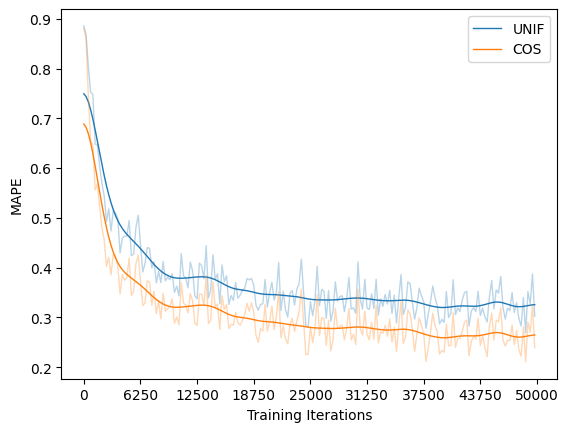

In [11]:
### Prior Compare

# test = load_Experiment("test_inv_cbox_50k_uniform_hash_grid.pkl")

mueller = load_Experiment("inv_cbox_50k_mueller.pkl")
uniform = load_Experiment("inv_cbox_50k_uniform_hash_grid.pkl")
cosine = load_Experiment("inv_cbox_50k_cosine_hash_grid.pkl")

exps =      [
            # mueller,
            uniform,
            cosine 
             ]
labels =    [ 
             # "Mueller", 
             "UNIF", 
             "COS"
             ]

print_model_sizes(exps, labels)

print(cosine.mape_list[0: 5])

target_dir = "../../thesis_assets/images/inv_cbox_prior"
# target_dir = "../../thesis_assets/images/tests"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      display=True, 
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 4, spp = 4)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True,
    error_calc_iterations=4)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
    tonemap_render=False, 
    gamma_correct_render=False
)

In [11]:
### Encoding Compare


oneblob = load_Experiment("inv_cbox_50k_cosine_oneblob.pkl")
hashgrid = load_Experiment("inv_cbox_50k_cosine_hash_grid.pkl")

exps =      [
            oneblob,
            hashgrid 
             ]
labels =    [ 
             "ONE-BLOB", 
             "COS-GRID"
             ]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/inv_cbox_encoding"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 4, spp = 4)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True,
    error_calc_iterations=4)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
    tonemap_render=False, 
    gamma_correct_render=False
)

using device: cuda
using device: cuda
Network sizes for model: ONE-BLOB
	Size of initial encoding: 0

	Size of flow 0: 26624
	Size of flow 1: 26624
	Size of flow 2: 26624
	Size of flow 3: 26624
	Size of all flows: 106496
	Total size of model: 106496
Network sizes for model: COS-GRID
	Size of initial encoding: 5840896

	Size of flow 0: 21504
	Size of flow 1: 21504
	Size of flow 2: 21504
	Size of flow 3: 21504
	Size of all flows: 86016
	Total size of model: 5926912
Rendering reference
NaNs: False
Infs: False
[0.98632735 0.97319144 0.95181954]
[0. 0. 0.]
Rendering path traced
new_error: 0.5318169593811035
MAPE: 0.5318169593811035
new_error: 0.5305424332618713
MAPE: 1.06235933303833
new_error: 0.5305137038230896
MAPE: 1.5928730964660645
new_error: 0.5307920575141907
MAPE: 2.1236650943756104
		mean error estimate path traced: 0.5309162735939026
		variance estimate path traced: 2.980232238769531e-07
		stddev estimate path traced: 0.0005459150335692846
NaNs: False
Infs: False
[0.98956865 0.98

d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:78: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_x, x) - 1


new_error: 0.23602014780044556
MAPE: 0.23602014780044556
new_error: 0.2600589096546173
MAPE: 0.49607905745506287
new_error: 0.2643944323062897
MAPE: 0.7604734897613525
new_error: 0.2462330013513565
MAPE: 1.0067064762115479
		mean error estimate ONE-BLOB: 0.25167661905288696
		variance estimate ONE-BLOB: 0.00012668967247009277
		stddev estimate ONE-BLOB: 0.011255650690657239
NaNs: False
Infs: False
[0.995465   0.9918362  0.98517895]
[0. 0. 0.]
Rendering COS-GRID
new_error: 0.22883236408233643
MAPE: 0.22883236408233643
new_error: 0.2785399854183197
MAPE: 0.5073723793029785
new_error: 0.25048720836639404
MAPE: 0.7578595876693726
new_error: 0.23607860505580902
MAPE: 0.9939382076263428
		mean error estimate COS-GRID: 0.2484845519065857
		variance estimate COS-GRID: 0.0003618597984313965
		stddev estimate COS-GRID: 0.01902261281820656
NaNs: False
Infs: False
[0.9878662  0.97836727 0.9614024 ]
[0. 0. 0.]
Visualizing reference distribution of point #1


p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Visualizing dist of ONE-BLOB for point #1
Visualizing dist of COS-GRID for point #1
Visualizing reference distribution of point #2
Visualizing dist of ONE-BLOB for point #2
Visualizing dist of COS-GRID for point #2


In [12]:
### Single vs Multiple Grids

single = load_Experiment("inv_cbox_50k_cosine_hash_grid.pkl")
mult = load_Experiment("inv_cbox_50k_cosine_hash_grid_multiple.pkl")
small = load_Experiment("inv_cbox_50k_cosine_hash_grid_multiple_small.pkl")

exps =      [
            single,
            mult,
            small 
             ]
labels =    [ 
             "COS-GRID", 
             "MULT",
             "SMALL"
             ]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/inv_cbox_multiple"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 4, spp = 4)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True,
    error_calc_iterations=4)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
    tonemap_render=False, 
    gamma_correct_render=False 
)

using device: cuda
using device: cuda
using device: cuda
Network sizes for model: COS-GRID
	Size of initial encoding: 5840896

	Size of flow 0: 21504
	Size of flow 1: 21504
	Size of flow 2: 21504
	Size of flow 3: 21504
	Size of all flows: 86016
	Total size of model: 5926912
Network sizes for model: MULT
	Size of initial encoding: 0

	Size of flow 0: 5862400
	Size of flow 1: 5862400
	Size of flow 2: 5862400
	Size of flow 3: 5862400
	Size of all flows: 23449600
	Total size of model: 23449600
Network sizes for model: SMALL
	Size of initial encoding: 0

	Size of flow 0: 1668096
	Size of flow 1: 1668096
	Size of flow 2: 1668096
	Size of flow 3: 1668096
	Size of all flows: 6672384
	Total size of model: 6672384
Rendering reference
NaNs: False
Infs: False
[0.98632735 0.97319144 0.95181954]
[0. 0. 0.]
Rendering path traced
new_error: 0.5318169593811035
MAPE: 0.5318169593811035
new_error: 0.5305424332618713
MAPE: 1.06235933303833
new_error: 0.5305137038230896
MAPE: 1.5928730964660645
new_error: 

In [13]:
### Staggered Grids

single = load_Experiment("inv_cbox_50k_cosine_hash_grid.pkl")
mult = load_Experiment("inv_cbox_50k_cosine_hash_grid_multiple.pkl")
slight = load_Experiment("inv_cbox_50k_cosine_hash_grid_multiple_stagger_slight.pkl")
aggressive = load_Experiment("inv_cbox_50k_cosine_hash_grid_multiple_stagger_aggressive.pkl")

exps =      [
            single,
            mult,
            slight, 
            aggressive 
             ]
labels =    [ 
             "COS-GRID", 
             "MULT",
             "SLIGHT",
             "AGGRESSIVE"
             ]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/inv_cbox_stagger"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 4, spp = 4)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True,
    error_calc_iterations=4)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
    tonemap_render=False, 
    gamma_correct_render=False
)

using device: cuda
using device: cuda
using device: cuda
using device: cuda
Network sizes for model: COS-GRID
	Size of initial encoding: 5840896

	Size of flow 0: 21504
	Size of flow 1: 21504
	Size of flow 2: 21504
	Size of flow 3: 21504
	Size of all flows: 86016
	Total size of model: 5926912
Network sizes for model: MULT
	Size of initial encoding: 0

	Size of flow 0: 5862400
	Size of flow 1: 5862400
	Size of flow 2: 5862400
	Size of flow 3: 5862400
	Size of all flows: 23449600
	Total size of model: 23449600
Network sizes for model: SLIGHT
	Size of initial encoding: 0

	Size of flow 0: 207536
	Size of flow 1: 2385200
	Size of flow 2: 4451120
	Size of flow 3: 5862400
	Size of all flows: 12906256
	Total size of model: 12906256
Network sizes for model: AGGRESSIVE
	Size of initial encoding: 0

	Size of flow 0: 21888
	Size of flow 1: 77024
	Size of flow 2: 2791216
	Size of flow 3: 5862400
	Size of all flows: 8752528
	Total size of model: 8752528
Rendering reference
NaNs: False
Infs: False
[

In [14]:
### Latent Encode

mult = load_Experiment("inv_cbox_50k_cosine_hash_grid_multiple.pkl")
latent = load_Experiment("inv_cbox_50k_cosine_hash_grid_multiple_latent.pkl")

exps =      [
            mult,
            latent 
             ]
labels =    [ 
             "MULT", 
             "LATENT"
             ]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/inv_cbox_latent"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 4, spp = 4)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True,
    error_calc_iterations=4)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
    tonemap_render=False, 
    gamma_correct_render=False 
)

using device: cuda
using device: cuda
Network sizes for model: MULT
	Size of initial encoding: 0

	Size of flow 0: 5862400
	Size of flow 1: 5862400
	Size of flow 2: 5862400
	Size of flow 3: 5862400
	Size of all flows: 23449600
	Total size of model: 23449600
Network sizes for model: LATENT
	Size of initial encoding: 0

	Size of flow 0: 7490560
	Size of flow 1: 7490560
	Size of flow 2: 7490560
	Size of flow 3: 7490560
	Size of all flows: 29962240
	Total size of model: 29962240
Rendering reference
NaNs: False
Infs: False
[0.98632735 0.97319144 0.95181954]
[0. 0. 0.]
Rendering path traced
new_error: 0.5318169593811035
MAPE: 0.5318169593811035
new_error: 0.5305424332618713
MAPE: 1.06235933303833
new_error: 0.5305137038230896
MAPE: 1.5928730964660645
new_error: 0.5307920575141907
MAPE: 2.1236650943756104
		mean error estimate path traced: 0.5309162735939026
		variance estimate path traced: 2.980232238769531e-07
		stddev estimate path traced: 0.0005459150335692846
NaNs: False
Infs: False
[0.9

In [15]:
### Full Compare

mueller = load_Experiment("inv_cbox_50k_mueller.pkl")
cos_grid = load_Experiment("inv_cbox_50k_cosine_hash_grid.pkl")
full = load_Experiment("inv_cbox_50k_full.pkl")

exps =      [
    mueller,
    cos_grid,
    full
]

labels = [ 
    "MUELLER",
    "COS-GRID",
    "COMBINED"
]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/inv_cbox_full"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 4, spp = 4)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True,
    error_calc_iterations=4)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
    tonemap_render=False, 
    gamma_correct_render=False 
)

d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda
using device: cuda
using device: cuda
Network sizes for model: MUELLER
	Size of initial encoding: 0

	Size of flow 0: 26624
	Size of flow 1: 26624
	Size of flow 2: 26624
	Size of flow 3: 26624
	Size of all flows: 106496
	Total size of model: 106496
Network sizes for model: COS-GRID
	Size of initial encoding: 5840896

	Size of flow 0: 21504
	Size of flow 1: 21504
	Size of flow 2: 21504
	Size of flow 3: 21504
	Size of all flows: 86016
	Total size of model: 5926912
Network sizes for model: COMBINED
	Size of initial encoding: 0

	Size of flow 0: 21232
	Size of flow 1: 1327648
	Size of flow 2: 4644208
	Size of flow 3: 7490560
	Size of all flows: 13483648
	Total size of model: 13483648
Rendering reference
NaNs: False
Infs: False
[0.98632735 0.97319144 0.95181954]
[0. 0. 0.]
Rendering path traced
new_error: 0.5318169593811035
MAPE: 0.5318169593811035
new_error: 0.5305424332618713
MAPE: 1.06235933303833
new_error: 0.5305137038230896
MAPE: 1.5928730964660645
new_error: 0.5307

In [16]:


### Full Compare no mueller

#mueller = load_Experiment("inv_cbox_50k_mueller.pkl")
cos_grid = load_Experiment("inv_cbox_50k_cosine_hash_grid.pkl")
full = load_Experiment("inv_cbox_50k_full.pkl")

exps =      [
    cos_grid,
    full
]

labels = [ 
    "COS-GRID",
    "COMBINED"
]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/inv_cbox_full_compare"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 4, spp = 4)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True,
    error_calc_iterations=4)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
    tonemap_render=False, 
    gamma_correct_render=False 
)

using device: cuda
using device: cuda
Network sizes for model: COS-GRID
	Size of initial encoding: 5840896

	Size of flow 0: 21504
	Size of flow 1: 21504
	Size of flow 2: 21504
	Size of flow 3: 21504
	Size of all flows: 86016
	Total size of model: 5926912
Network sizes for model: COMBINED
	Size of initial encoding: 0

	Size of flow 0: 21232
	Size of flow 1: 1327648
	Size of flow 2: 4644208
	Size of flow 3: 7490560
	Size of all flows: 13483648
	Total size of model: 13483648
Rendering reference
NaNs: False
Infs: False
[0.98632735 0.97319144 0.95181954]
[0. 0. 0.]
Rendering path traced
new_error: 0.5318169593811035
MAPE: 0.5318169593811035
new_error: 0.5305424332618713
MAPE: 1.06235933303833
new_error: 0.5305137038230896
MAPE: 1.5928730964660645
new_error: 0.5307920575141907
MAPE: 2.1236650943756104
		mean error estimate path traced: 0.5309162735939026
		variance estimate path traced: 2.980232238769531e-07
		stddev estimate path traced: 0.0005459150335692846
NaNs: False
Infs: False
[0.989

In [ ]:


### Full Compare no mueller

#mueller = load_Experiment("inv_cbox_50k_mueller.pkl")
cos_grid = load_Experiment("inv_cbox_50k_cosine_hash_grid.pkl")
full = load_Experiment("inv_cbox_50k_full.pkl")

exps =      [
    # mueller,
    cos_grid,
    full
]

labels = [ 
    #"mueller",
    "Cos-grid",
    "Full"
]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/test_dists"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 4, spp = 4)

patch_anchors = [[0, 200], [400, 200]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    dist_ref_spp=64, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

using device: cuda
using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.98632735 0.97319144 0.95181954]
[0. 0. 0.]
Rendering path traced
MAPE: 0.5318169593811035
NaNs: False
Infs: False
[0.99003077 0.9821514  0.96799374]
[0. 0. 0.]
----
Rendering Cos-grid
MAPE: 0.2201196700334549
NaNs: False
Infs: False
[0.9913532  0.98451585 0.97215503]
[0. 0. 0.]
Rendering Full
MAPE: 0.2023102045059204
NaNs: False
Infs: False
[0.98943883 0.9811336  0.96621937]
[0. 0. 0.]
Visualizing reference distribution of point #1
Visualizing dist of Cos-grid for point #1
Visualizing dist of Full for point #1
Visualizing reference distribution of point #2
Visualizing dist of Cos-grid for point #2
Visualizing dist of Full for point #2


## Kitchen

In [16]:
### Encoding compare

# test = load_Experiment("test_inv_cbox_50k_uniform_hash_grid.pkl")

one_blob = load_Experiment("kitchen_50k_cosine_oneblob.pkl")

exps =      [
    one_blob, 
]

labels = [ 
    "One blob", 
]

target_dir = "../../thesis_assets/images/kitchen_example"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 8, model_MIS_beta = 2)

patch_anchors = []
patch_dims = []
patch_colors = []



ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True)


using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.9728715 0.9728715 0.9728715]
[0.00846976 0.00828997 0.00821678]
Rendering path traced
new_error: 0.3472440838813782
MAPE: 0.3472440838813782
		mean error estimate path traced: 0.3472440838813782
		variance estimate path traced: 0.0
		stddev estimate path traced: 0.0
NaNs: False
Infs: False
[0.99955195 0.99955183 0.9995517 ]
[0. 0. 0.]
----
Rendering One blob
new_error: 0.24435438215732574
MAPE: 0.24435438215732574
		mean error estimate One blob: 0.24435438215732574
		variance estimate One blob: 0.0
		stddev estimate One blob: 0.0
NaNs: False
Infs: False
[0.9999973 0.9999973 0.9999973]
[0. 0. 0.]


In [ ]:
### Sample count compare

exp_14 = load_Experiment("2_14_samples_kitchen_1k_cosine_hash_grid.pkl")
exp_16 = load_Experiment("2_16_samples_kitchen_1k_cosine_hash_grid.pkl")
exp_18 = load_Experiment("2_18_samples_kitchen_1k_cosine_hash_grid.pkl")

exps =      [
    exp_14, 
    exp_16,
    exp_18 
]

labels = [ 
    "Exp 14", 
    "Exp 16",
    "Exp 18"    
]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/kitchen_samples"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 8, model_MIS_beta = 2)

patch_anchors = [[270, 395], [1100, 450]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

# patch_anchors = []
# patch_dims = []
# patch_colors = []


ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

using device: cuda
using device: cuda
using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.9728715 0.9728715 0.9728715]
[0.00846976 0.00828997 0.00821678]
Rendering path traced
MAPE: 0.3473704755306244
NaNs: False
Infs: False
[0.99978083 0.9997808  0.9997808 ]
[0. 0. 0.]
----
Rendering Exp 14
MAPE: 0.5626133680343628
NaNs: False
Infs: False
[0.99982816 0.99982816 0.99982816]
[0. 0. 0.]
Rendering Exp 16
MAPE: 0.5028083324432373
NaNs: False
Infs: False
[0.9996496 0.9996495 0.9996495]
[0. 0. 0.]
Rendering Exp 18
MAPE: 0.4598972201347351
NaNs: False
Infs: False
[0.9996233  0.99962324 0.99962324]
[0. 0. 0.]
Visualizing reference distribution of point #1
Visualizing dist of Exp 14 for point #1
Visualizing dist of Exp 16 for point #1
Visualizing dist of Exp 18 for point #1


KeyboardInterrupt: 

In [ ]:
### Encoding compare

# test = load_Experiment("test_inv_cbox_50k_uniform_hash_grid.pkl")

mueller = load_Experiment("kitchen_50k_mueller.pkl")
one_blob = load_Experiment("kitchen_50k_cosine_oneblob.pkl")
hash_grid = load_Experiment("kitchen_50k_cosine_hash_grid.pkl")

exps =      [
    mueller, 
    one_blob, 
    hash_grid 
]

labels = [ 
    "mueller", 
    "One blob", 
    "Hash grid"    
]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/kitchen_encoding"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 8, model_MIS_beta = 2)

patch_anchors = [[270, 395], [1100, 450]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

# patch_anchors = []
# patch_dims = []
# patch_colors = []


ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

# compute_point_distributions(
#     experiments=exps, 
#     labels=labels, 
#     points=points, 
#     ref_image=ref_image,
#     target_dir=target_dir,
#     patch_colors=patch_colors, 
#     rect_line_width=8, 
# )

d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda
using device: cuda
using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.9728715 0.9728715 0.9728715]
[0.00846976 0.00828997 0.00821678]
Rendering path traced
MAPE: 0.3473704755306244
NaNs: False
Infs: False
[0.99978083 0.9997808  0.9997808 ]
[0. 0. 0.]
----


d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:78: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_x, x) - 1


Rendering mueller
MAPE: 0.2715110182762146
NaNs: False
Infs: False
[0.999997 0.999997 0.999997]
[0. 0. 0.]
Rendering One blob
MAPE: 0.24225427210330963
NaNs: False
Infs: False
[0.9999986 0.9999986 0.9999986]
[0. 0. 0.]
Rendering Hash grid
MAPE: 0.24988999962806702
NaNs: False
Infs: False
[0.9998915 0.9998915 0.9998915]
[0. 0. 0.]


In [19]:
### Full Compare


mueller = load_Experiment("kitchen_50k_mueller.pkl")
cos_grid = load_Experiment("kitchen_50k_cosine_hash_grid.pkl")
full = load_Experiment("kitchen_50k_full.pkl")

exps =      [
    mueller,
    cos_grid,
    full
]

labels = [ 
    "MUELLER",
    "COS-GRID",
    "COMBINED"
]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/kitchen_full"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 8, model_MIS_beta = 2)

patch_anchors = [[270, 395], [1100, 450]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']



ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=4,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True,
    error_calc_iterations=4)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    dist_ref_spp=16, 
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
    tonemap_render=False, 
    gamma_correct_render=False 
)

d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda
using device: cuda
using device: cuda
Network sizes for model: MUELLER
	Size of initial encoding: 0

	Size of flow 0: 26624
	Size of flow 1: 26624
	Size of flow 2: 26624
	Size of flow 3: 26624
	Size of all flows: 106496
	Total size of model: 106496
Network sizes for model: COS-GRID
	Size of initial encoding: 5840896

	Size of flow 0: 21504
	Size of flow 1: 21504
	Size of flow 2: 21504
	Size of flow 3: 21504
	Size of all flows: 86016
	Total size of model: 5926912
Network sizes for model: COMBINED
	Size of initial encoding: 0

	Size of flow 0: 21232
	Size of flow 1: 1327648
	Size of flow 2: 4644208
	Size of flow 3: 7490560
	Size of all flows: 13483648
	Total size of model: 13483648
Rendering reference
NaNs: False
Infs: False
[0.9728715 0.9728715 0.9728715]
[0.00846976 0.00828997 0.00821678]
Rendering path traced
new_error: 0.3472353219985962
MAPE: 0.3472353219985962
new_error: 0.34775426983833313
MAPE: 0.6949895620346069
new_error: 0.34758976101875305
MAPE: 1.042579293

In [ ]:
### Backrest compare


### Full Compare


mueller = load_Experiment("kitchen_50k_mueller.pkl")
cos_grid = load_Experiment("kitchen_50k_cosine_hash_grid.pkl")
full = load_Experiment("kitchen_50k_full.pkl")

exps =      [
    mueller,
    cos_grid,
    full
]

labels = [ 
    "MUELLER",
    "COS-GRID",
    "COMBINED"
]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/kitchen_back_rest"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 8, model_MIS_beta = 2)

patch_anchors = [[725, 420], [1100, 450]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']



# ref_image = compare_experiments( 
#     experiments=exps, 
#     labels=labels, 
#     render_context=rCtx, 
#     include_path_traced=True, 
#     ref_spp=128,
#     use_saved_ref=True, 
#     save_ref=True,
#     target_dir=target_dir,
#     patch_anchors=patch_anchors, 
#     patch_dims=patch_dims, 
#     patch_colors=patch_colors,
#     rect_line_width=4,
#     tonemap = True,
#     gamma_correct=True, 
#     patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=None,
    dist_ref_spp=48, 
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

using device: cuda
using device: cuda
using device: cuda
Visualizing reference distribution of point #1
Visualizing dist of mueller for point #1
Visualizing dist of cos grid for point #1
Visualizing dist of full for point #1
Visualizing reference distribution of point #2
Visualizing dist of mueller for point #2
Visualizing dist of cos grid for point #2
Visualizing dist of full for point #2


## Spaceship

In [ ]:
### Prior Compare

# test = load_Experiment("test_inv_cbox_50k_uniform_hash_grid.pkl")


uniform = load_Experiment("spaceship_50k_uniform_hash_grid.pkl")
cosine = load_Experiment("spaceship_50k_cosine_hash_grid.pkl")

exps =      [
    uniform, 
    cosine 
]

labels = [ 
    "Uniform", 
    "Cosine"    
]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/spaceship_prior"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 32, model_MIS_beta = 2)

# patch_anchors = [[50, 80], [360, 380]]
# patch_dims = [[100, 100], [100, 100]]
# patch_colors = ['red', 'blue']

patch_anchors = []
patch_dims = []
patch_colors = []


ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda
using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.96742594 0.89863616 0.890253  ]
[0.01618956 0.01618854 0.01653314]
Rendering path traced
MAPE: 0.1646401286125183
NaNs: False
Infs: False
[0.99597436 0.99395555 0.9945547 ]
[0. 0. 0.]
----
Rendering Uniform
MAPE: 0.10875555127859116
NaNs: False
Infs: False
[0.99998164 0.9999814  0.9999833 ]
[0. 0. 0.]
Rendering Cosine
MAPE: 0.0966261476278305
NaNs: False
Infs: False
[0.9999489  0.9999489  0.99995404]
[0. 0. 0.]


In [18]:
### Full Compare


mueller = load_Experiment("spaceship_50k_mueller.pkl")
cos_grid = load_Experiment("spaceship_50k_cosine_hash_grid.pkl")
full = load_Experiment("spaceship_50k_full.pkl")

exps =      [
    mueller,
    cos_grid,
    full
]

labels = [ 
    "MUELLER",
    "COS-GRID",
    "COMBINED"
]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/spaceship_full"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 8, model_MIS_beta = 2)

# patch_anchors = []
# patch_dims = []
# patch_colors = []

patch_anchors = [[900, 470], [480, 330]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']


ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=4,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True,
    error_calc_iterations=4)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
    tonemap_render=False, 
    gamma_correct_render=False 
)

d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda
using device: cuda
using device: cuda
Network sizes for model: MUELLER
	Size of initial encoding: 0

	Size of flow 0: 26624
	Size of flow 1: 26624
	Size of flow 2: 26624
	Size of flow 3: 26624
	Size of all flows: 106496
	Total size of model: 106496
Network sizes for model: COS-GRID
	Size of initial encoding: 5840896

	Size of flow 0: 21504
	Size of flow 1: 21504
	Size of flow 2: 21504
	Size of flow 3: 21504
	Size of all flows: 86016
	Total size of model: 5926912
Network sizes for model: COMBINED
	Size of initial encoding: 0

	Size of flow 0: 21232
	Size of flow 1: 1327648
	Size of flow 2: 4644208
	Size of flow 3: 7490560
	Size of all flows: 13483648
	Total size of model: 13483648
Rendering reference
NaNs: False
Infs: False
[0.96742594 0.89863616 0.890253  ]
[0.01618956 0.01618854 0.01653314]
Rendering path traced
new_error: 0.23053184151649475
MAPE: 0.23053184151649475
new_error: 0.2305159717798233
MAPE: 0.46104782819747925
new_error: 0.2303154319524765
MAPE: 0.69136

## Veach Ajar

In [ ]:
### Prior Compare

# test = load_Experiment("test_inv_cbox_50k_uniform_hash_grid.pkl")


mueller = load_Experiment("veach_ajar_50k_mueller.pkl")
cos_grid = load_Experiment("veach_ajar_50k_cosine_hash_grid.pkl")

exps =      [
    mueller,
    cos_grid 
]

labels = [ 
    "mueller",
    "cos grid" 
]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/veach_ajar_basic"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 8, model_MIS_beta = 2)

patch_anchors = [[365, 400], [730, 450]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']



ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=2,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda
using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.9621852  0.9599237  0.95944303]
[0.08080643 0.08196948 0.03518704]
Rendering path traced
MAPE: 0.6304584741592407
NaNs: False
Infs: False
[0.99880356 0.9987901  0.9987943 ]
[0. 0. 0.]
----


d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:78: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_x, x) - 1


Rendering mueller
MAPE: 0.4211301803588867
NaNs: False
Infs: False
[0.9994294  0.99942285 0.9994239 ]
[0. 0. 0.]
Rendering cos grid
MAPE: 0.3271386921405792
NaNs: False
Infs: False
[0.9999997 0.9999997 0.9999997]
[0. 0. 0.]
Visualizing reference distribution of point #1


p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Visualizing dist of mueller for point #1
Visualizing dist of cos grid for point #1
Visualizing reference distribution of point #2
Visualizing dist of mueller for point #2
Visualizing dist of cos grid for point #2


In [17]:
### Full Compare


mueller = load_Experiment("veach_ajar_50k_mueller.pkl")
cos_grid = load_Experiment("veach_ajar_50k_cosine_hash_grid.pkl")
full = load_Experiment("veach_ajar_50k_full.pkl")

exps =      [
    mueller,
    cos_grid,
    full
]

labels = [ 
    "MUELLER",
    "COS-GRID",
    "COMBINED"
]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/veach_ajar_full"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 8, model_MIS_beta = 2)

patch_anchors = [[365, 400], [730, 450]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']



ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=4,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True,
    error_calc_iterations=4)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
    tonemap_render=False, 
    gamma_correct_render=False 
)

d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda
using device: cuda
using device: cuda
Network sizes for model: MUELLER
	Size of initial encoding: 5840896

	Size of flow 0: 21504
	Size of flow 1: 21504
	Size of flow 2: 21504
	Size of flow 3: 21504
	Size of all flows: 86016
	Total size of model: 5926912
Network sizes for model: COS-GRID
	Size of initial encoding: 5840896

	Size of flow 0: 21504
	Size of flow 1: 21504
	Size of flow 2: 21504
	Size of flow 3: 21504
	Size of all flows: 86016
	Total size of model: 5926912
Network sizes for model: COMBINED
	Size of initial encoding: 0

	Size of flow 0: 21232
	Size of flow 1: 1327648
	Size of flow 2: 4644208
	Size of flow 3: 7490560
	Size of all flows: 13483648
	Total size of model: 13483648
Rendering reference
NaNs: False
Infs: False
[0.9621852  0.9599237  0.95944303]
[0.08080643 0.08196948 0.03518704]
Rendering path traced
new_error: 0.6304584741592407
MAPE: 0.6304584741592407
new_error: 0.6308319568634033
MAPE: 1.261290431022644
new_error: 0.6310997009277344
MAPE: 1.892

## Living Room

In [ ]:
### Test

test = load_Experiment("living_room_50k_cosine_hash_grid.pkl")


exps =      [
    test,
]

labels = [ 
    "test",
]

target_dir = "../../thesis_assets/images/living_room_test"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 8, model_MIS_beta = 2)

# patch_anchors = [[365, 400], [750, 450]]
# patch_dims = [[100, 100], [100, 100]]
# patch_colors = ['red', 'blue']


patch_anchors = [[550, 470]]
patch_dims = [[100, 100]]
patch_colors = ['red']



ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=2,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    dist_ref_spp=8,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=0, 
)

using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.97543085 0.97543085 0.97543085]
[0.02776818 0.028304   0.01065102]
Rendering path traced
MAPE: 0.16138452291488647
NaNs: False
Infs: False
[0.99462783 0.9946227  0.9946207 ]
[0. 0. 0.]
----


d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:78: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_x, x) - 1


Rendering test
MAPE: 0.237050399184227
NaNs: False
Infs: False
[0.99998087 0.99998087 0.99998087]
[0. 0. 0.]
Visualizing reference distribution of point #1


p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Visualizing dist of test for point #1


## Cbox

In [ ]:
### Full Compare


mueller = load_Experiment("cbox_50k_mueller.pkl")
cos_grid = load_Experiment("cbox_50k_cosine_hash_grid.pkl")
full = load_Experiment("cbox_50k_full.pkl")

exps =      [
    mueller,
    cos_grid,
    full
]

labels = [ 
    "mueller",
    "cos grid",
    "full"
]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/cbox_full"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 2, model_MIS_beta = 2)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=2,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda
using device: cuda
using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.99112797 0.9873179  0.9781244 ]
[0. 0. 0.]
Rendering path traced
MAPE: 0.23618845641613007
NaNs: False
Infs: False
[0.9910392  0.9872767  0.97806674]
[0. 0. 0.]
----
Rendering mueller
MAPE: 0.36171436309814453
NaNs: False
Infs: False
[0.9928725  0.9872767  0.98084223]
[0. 0. 0.]
Rendering cos grid
MAPE: 0.269091933965683
NaNs: False
Infs: False
[0.9910392  0.9872767  0.97806674]
[0. 0. 0.]
Rendering full
MAPE: 0.24749012291431427
NaNs: False
Infs: False
[0.99270177 0.9872767  0.97806674]
[0. 0. 0.]
Visualizing reference distribution of point #1
Visualizing dist of mueller for point #1
Visualizing dist of cos grid for point #1
Visualizing dist of full for point #1
Visualizing reference distribution of point #2
Visualizing dist of mueller for point #2
Visualizing dist of cos grid for point #2
Visualizing dist of full for point #2


In [ ]:
### wrap compare


mueller = load_Experiment("cbox_50k_mueller.pkl")
cos_grid = load_Experiment("cbox_50k_cosine_hash_grid.pkl")
full = load_Experiment("cbox_50k_full.pkl")

exps =      [
    mueller,
    cos_grid,
    full
]

labels = [ 
    "mueller",
    "cos grid",
    "full"
]

print_model_sizes(exps, labels)

target_dir = "../../thesis_assets/images/cbox_wrap"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 2, model_MIS_beta = 2)

patch_anchors = []
patch_dims = []
patch_colors = []

# ref_image = compare_experiments( 
#     experiments=exps, 
#     labels=labels, 
#     render_context=rCtx, 
#     include_path_traced=True, 
#     ref_spp=128,
#     use_saved_ref=True, 
#     save_ref=True,
#     target_dir=target_dir,
#     patch_anchors=patch_anchors, 
#     patch_dims=patch_dims, 
#     patch_colors=patch_colors,
#     rect_line_width=2,
#     tonemap = True,
#     gamma_correct=True, 
#     patch_has_outline=True)

scene_name = full.setup.scene_name
scene = scenes.get_scene_by_name(scene_name)
renderer = rr.Renderer(scene, rCtx, full.setup.coordinate_system)


out = renderer.render_with_model(512, 
        512, 
        full.model, 
        rCtx)
        
result = utils.res_to_numpy_3(out,
                                512, 
                                512)
        
result = utils.tonemap(result)
result = utils.gamma_correct(result)

patch_anchors = [[392, 200], [425, 200]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['blue', 'red']

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=result,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=0, 
    tonemap=True,
    tonemap_render=False, 
    gamma_correct_render=False
)

using device: cuda
using device: cuda
using device: cuda
Visualizing reference distribution of point #1
Visualizing dist of mueller for point #1
Visualizing dist of cos grid for point #1
Visualizing dist of full for point #1
Visualizing reference distribution of point #2
Visualizing dist of mueller for point #2
Visualizing dist of cos grid for point #2
Visualizing dist of full for point #2


## Env scene sphere

In [ ]:
### Evn scene sphere


sphere = load_Experiment("env_sphere_1k_example.pkl")

exps =      [
    sphere
]

labels = [ 
    "Sphere"
]

target_dir = "../../thesis_assets/images/sphere"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 2, spp = 1, model_MIS_beta = 2)

# patch_anchors = [[78, 78]]
# patch_dims = [[100, 100]]
# patch_colors = ['red']

patch_anchors = []
patch_dims = []
patch_colors = []

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    include_path_traced=True, 
    ref_spp=512,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.69200724 0.59000355 0.5277103 ]
[0.09068388 0.07377293 0.01245443]
Rendering path traced
MAPE: 0.18878857791423798
NaNs: False
Infs: False
[0.804435  0.6847929 0.6810786]
[0.00738887 0.         0.        ]
----
Rendering Sphere
MAPE: 0.13898517191410065
NaNs: False
Infs: False
[0.72949433 0.67516536 0.6592871 ]
[0.02282133 0.00708521 0.00524694]


# Experiments

In [ ]:
### Template

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 500
)

exp = run_experiment(setup, training_context, "")
del(exp)

## Inverted Cbox

loaded scene
using device: cuda
created model
starting training


d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))
  0%|          | 0/50000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:110: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
100%|██████████| 50000/50000 [37:51<00:00, 22.01it/s]
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:

average generate_samples_time time 0.005544284200668335
average compute_gradient_time time 0.029867479395866394
average nan_check_clip_time time 0.0005611710023880005
average optimizer_time time 8.225440979003907e-09


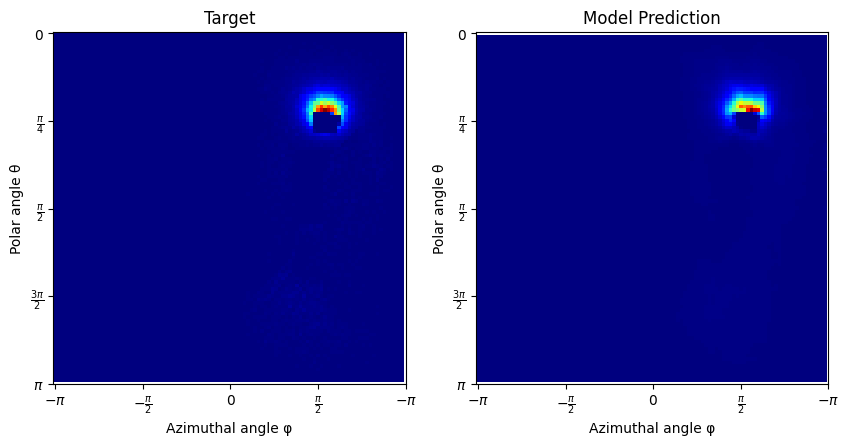

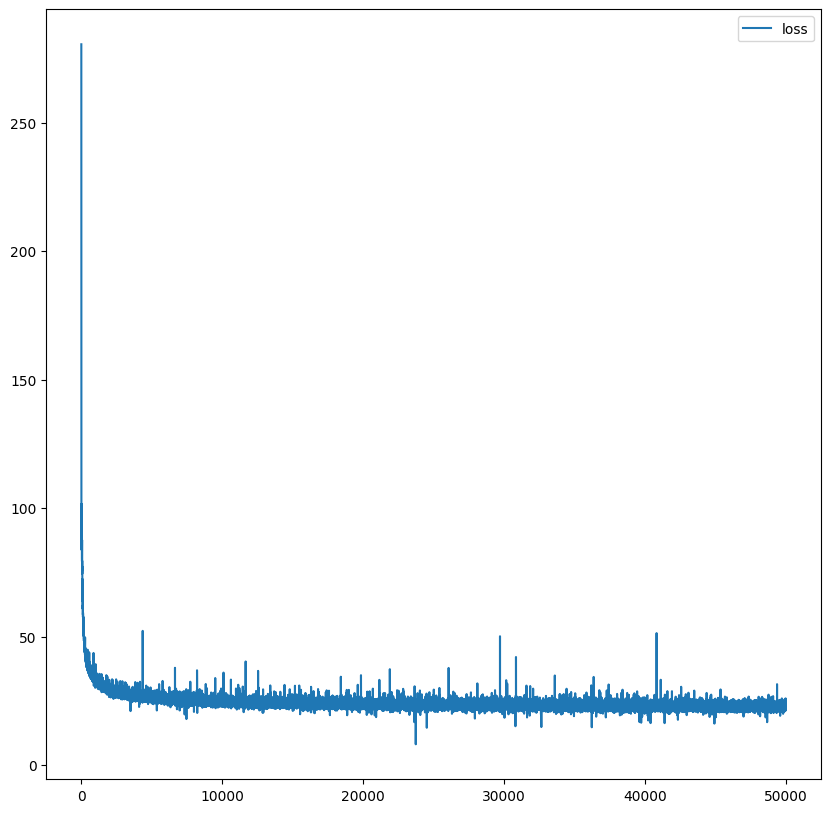

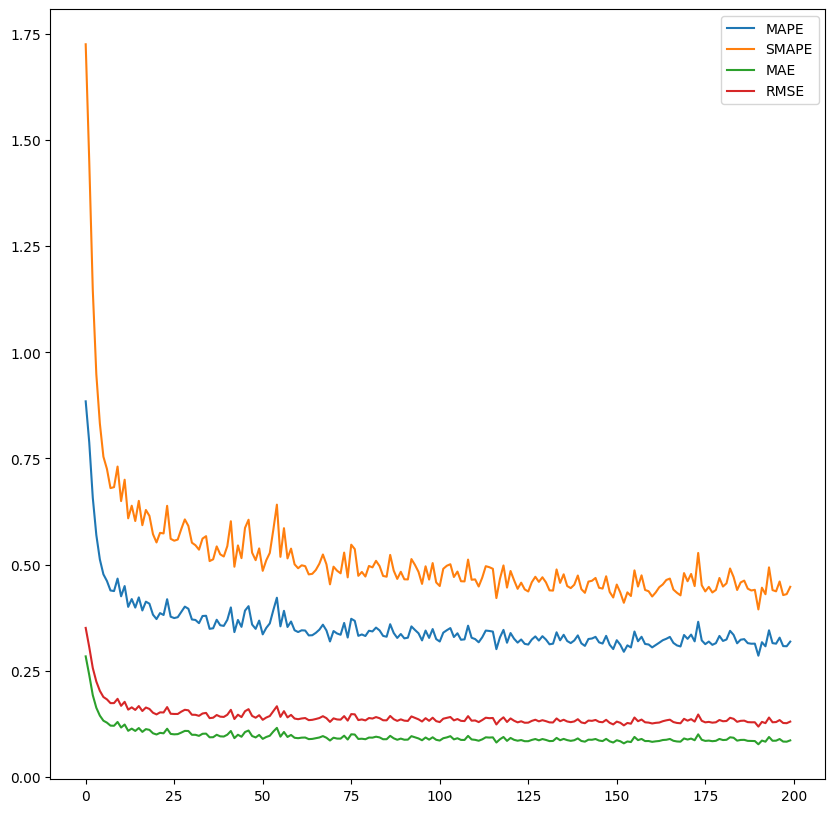

In [ ]:
### 1. Inv cbox Mueller

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='uniform',
    # prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=False,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = False,
    tonemap_error_calc = True, 
    gammacorrect_error_calc = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "inv_cbox_50k_mueller.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))
  0%|          | 0/50000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:110: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
100%|██████████| 50000/50000 [39:24<00:00, 21.15it/s]
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:

average generate_samples_time time 0.006365454049110412
average compute_gradient_time time 0.03072244475364685
average nan_check_clip_time time 0.0005937393474578857
average optimizer_time time 9.708404541015625e-09


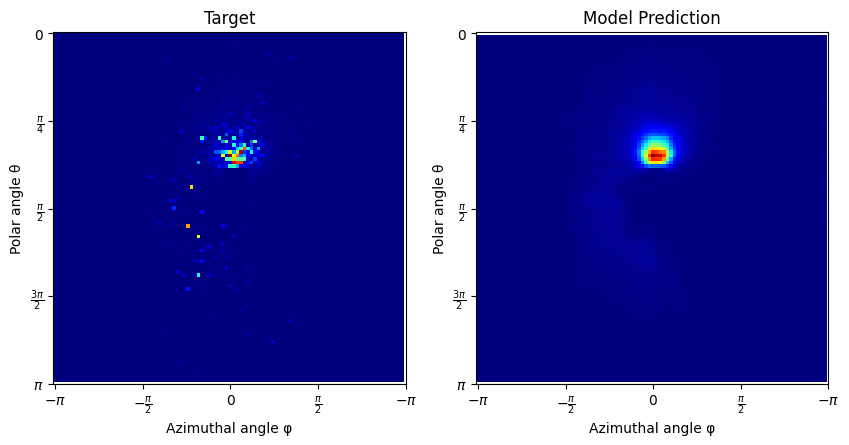

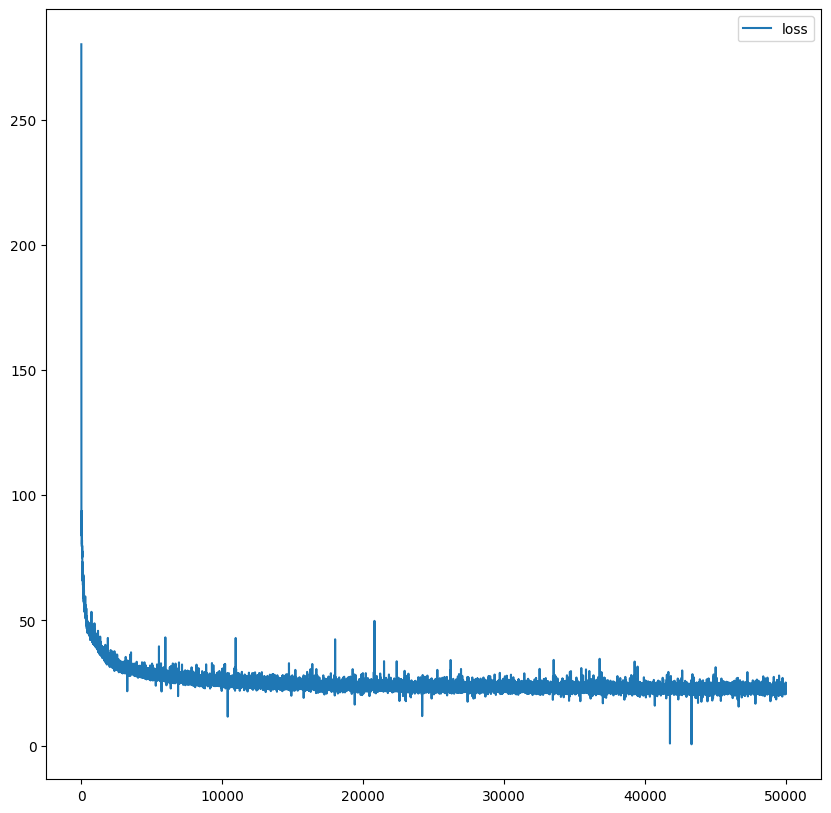

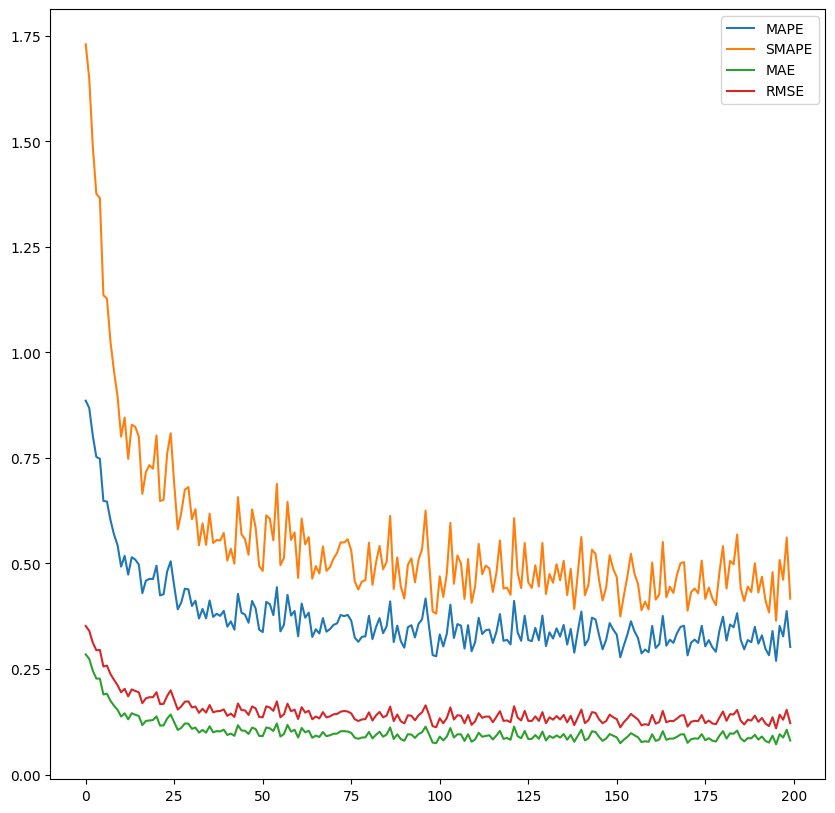

In [ ]:
### 1. Inv cbox uniform prior

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='uniform',
    # prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = False,
    tonemap_error_calc = True, 
    gammacorrect_error_calc = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "inv_cbox_50k_uniform_hash_grid.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


100%|██████████| 50000/50000 [42:29<00:00, 19.61it/s]


average generate_samples_time time 0.015288520879745483
average compute_gradient_time time 0.03046536262989044
average nan_check_clip_time time 0.0005660290002822876
average optimizer_time time 8.912086486816405e-09


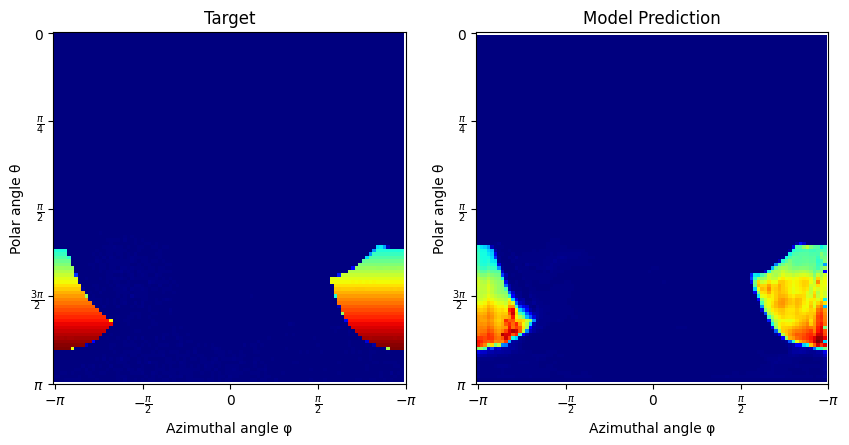

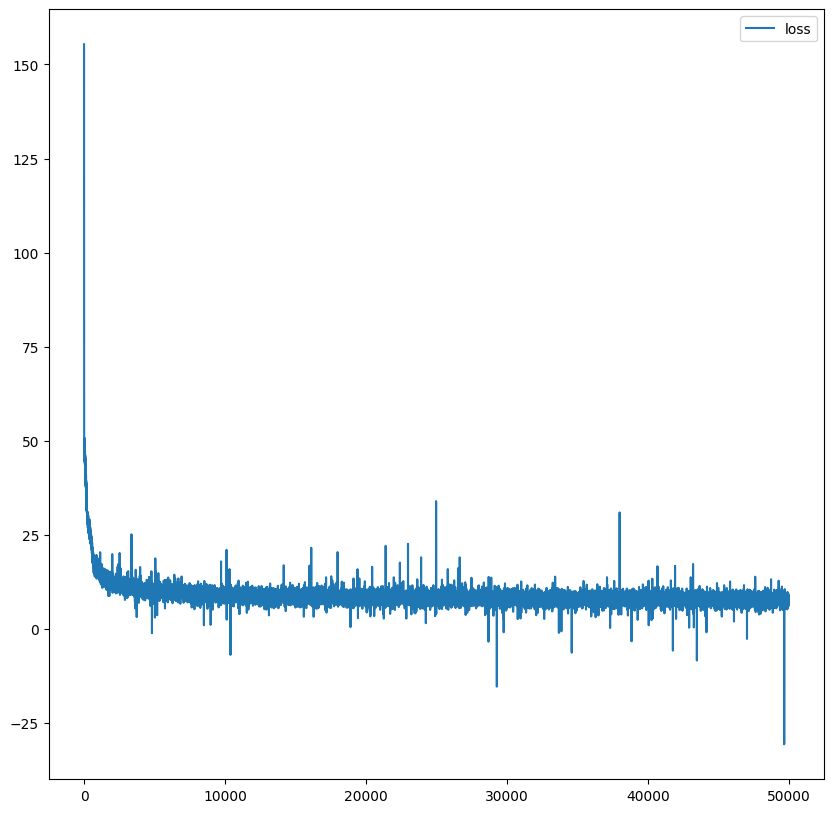

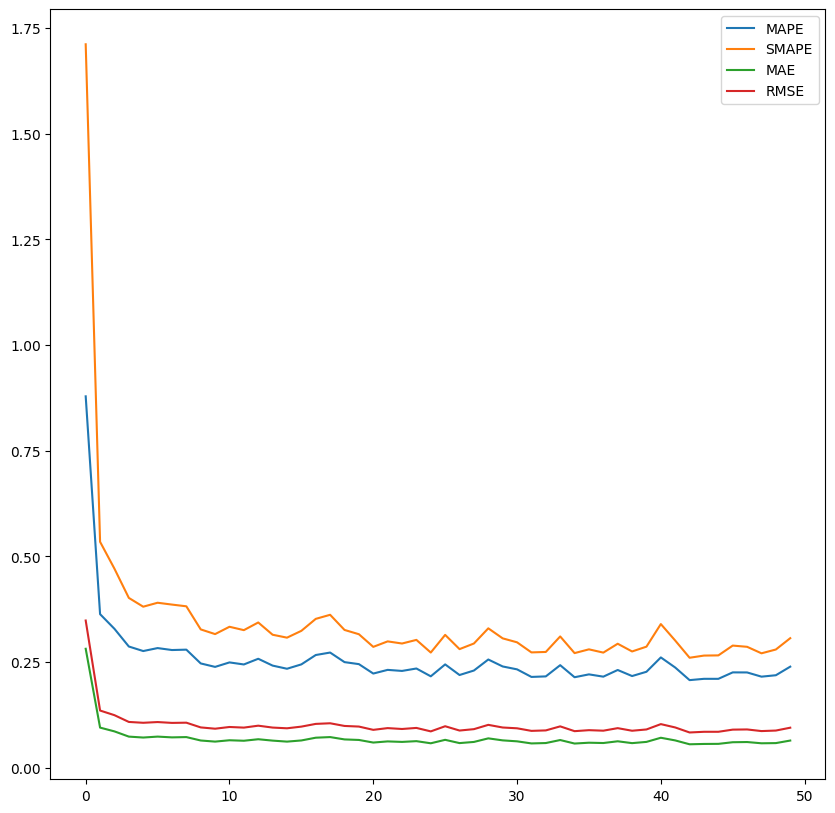

In [ ]:
### 2. Inv cbox cosine prior

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 1e-3,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 1000
)


exp = run_experiment(setup, training_context, "inv_cbox_50k_cosine_hash_grid1eneg3.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/10000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:110: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


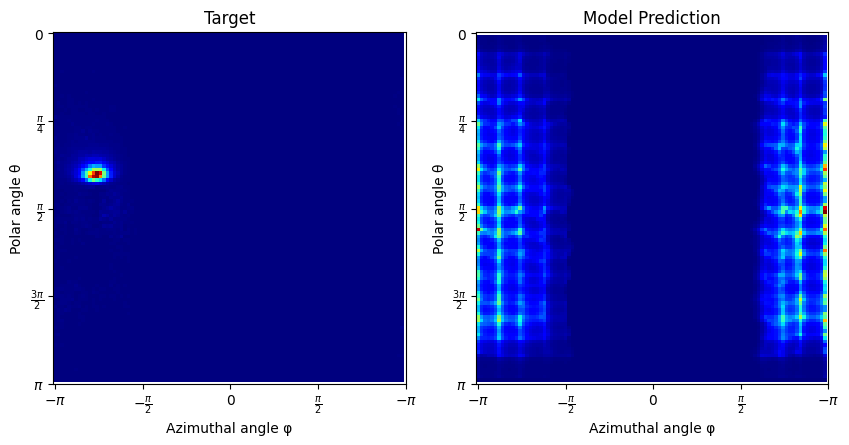

 10%|▉         | 999/10000 [00:53<07:27, 20.10it/s] 

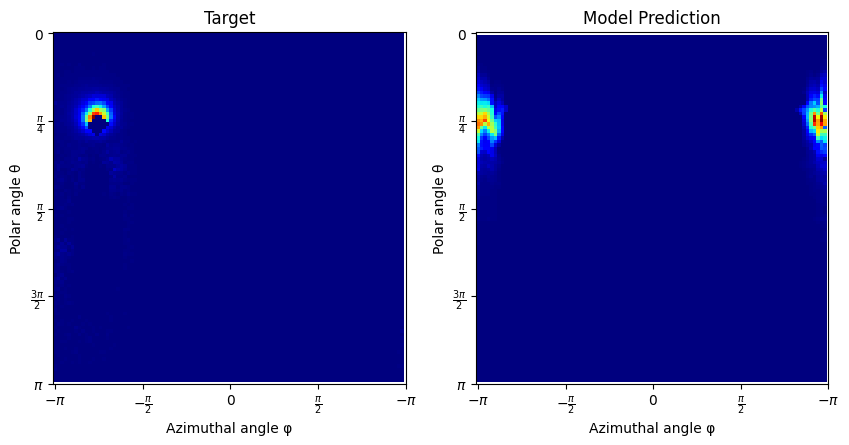

 20%|█▉        | 1998/10000 [01:44<06:31, 20.43it/s]

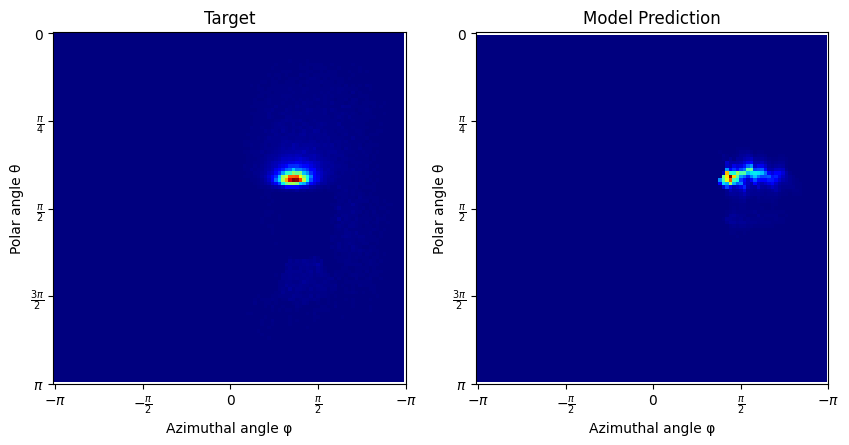

 30%|███       | 3000/10000 [02:35<05:41, 20.49it/s]

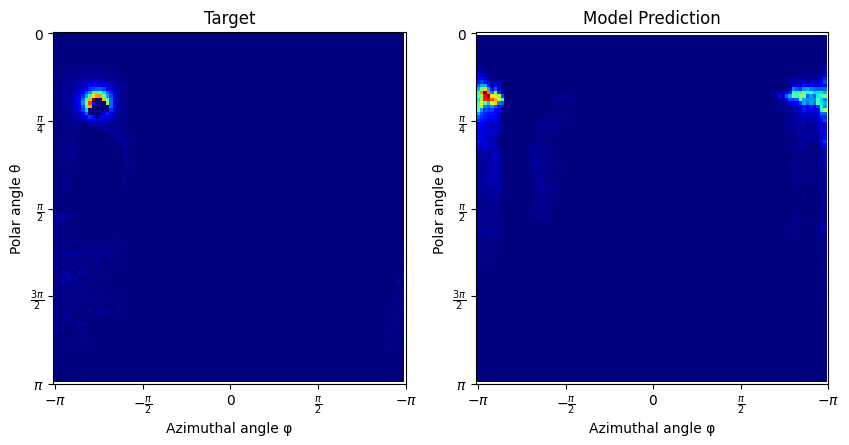

 40%|███▉      | 3999/10000 [03:26<04:50, 20.65it/s]

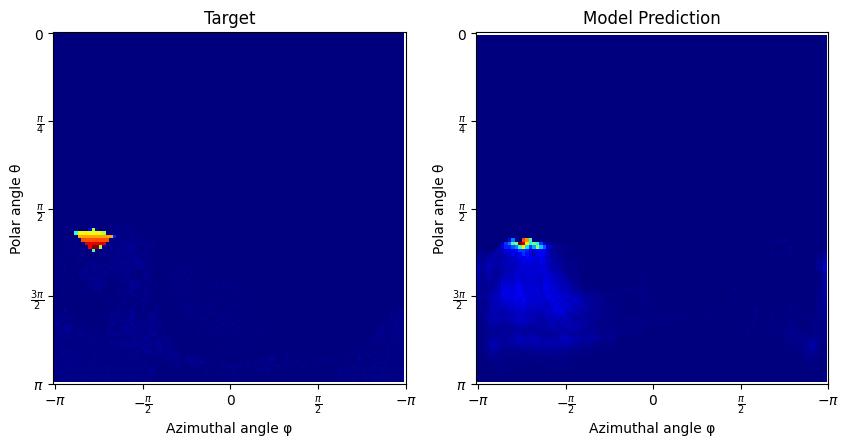

 50%|████▉     | 4998/10000 [04:16<04:00, 20.76it/s]

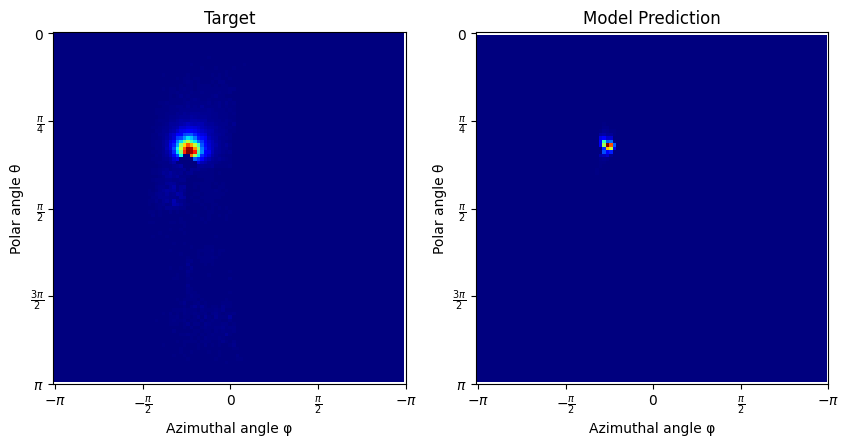

 60%|██████    | 6000/10000 [05:06<03:11, 20.85it/s]

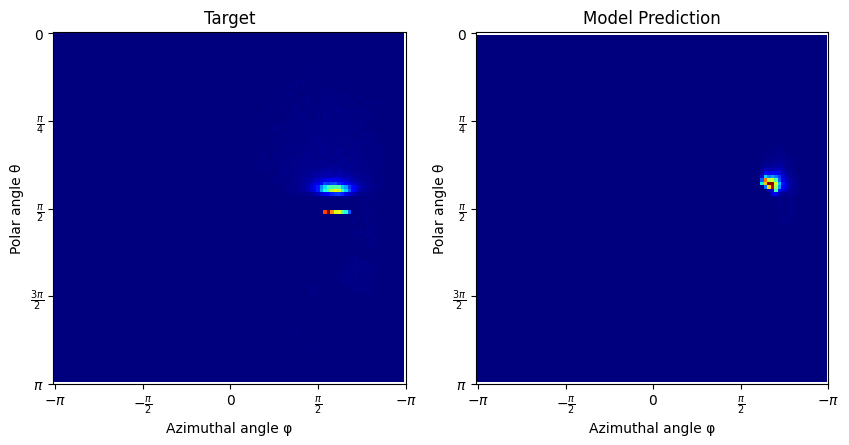

 68%|██████▊   | 6750/10000 [05:45<02:37, 20.68it/s]d:\Studium\Masters\Masters\scripts\..\src\utils.py:156: RuntimeWarning: invalid value encountered in power
  return value ** (1.0 / 2.2)
 70%|██████▉   | 6999/10000 [05:57<02:24, 20.82it/s]

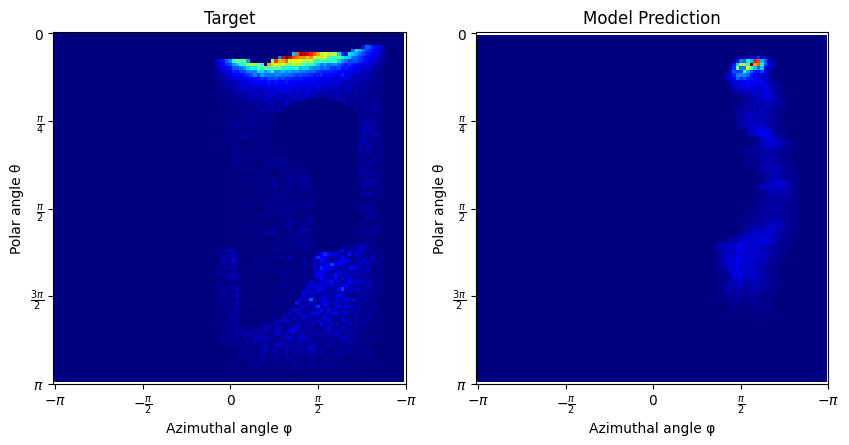

 80%|███████▉  | 7998/10000 [06:47<01:35, 20.88it/s]

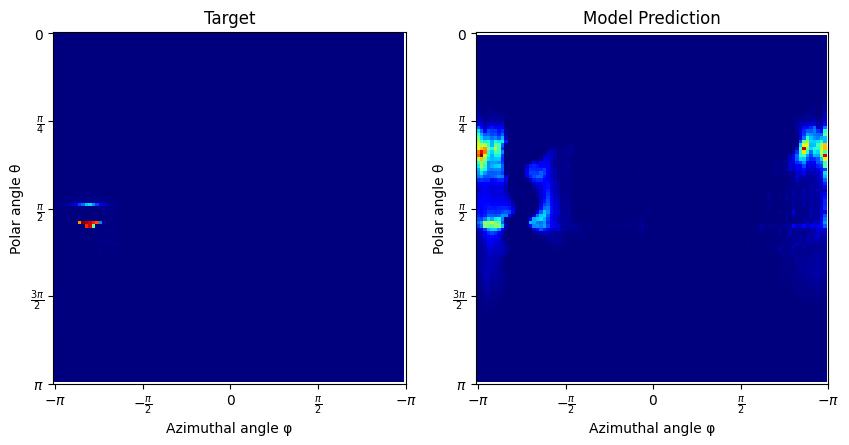

 90%|█████████ | 9000/10000 [07:37<00:48, 20.80it/s]

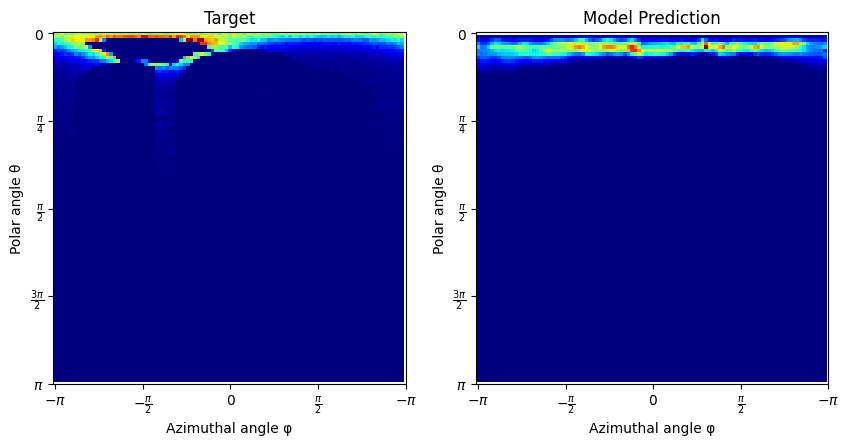

100%|██████████| 10000/10000 [08:28<00:00, 19.68it/s]


average generate_samples_time time 0.006584731698036194
average compute_gradient_time time 0.03054749994277954
average nan_check_clip_time time 0.0005844462156295776
average optimizer_time time 4.355907440185547e-08


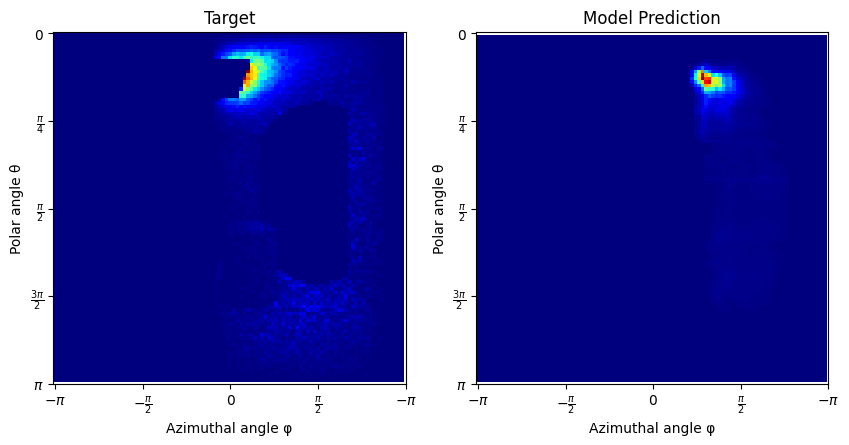

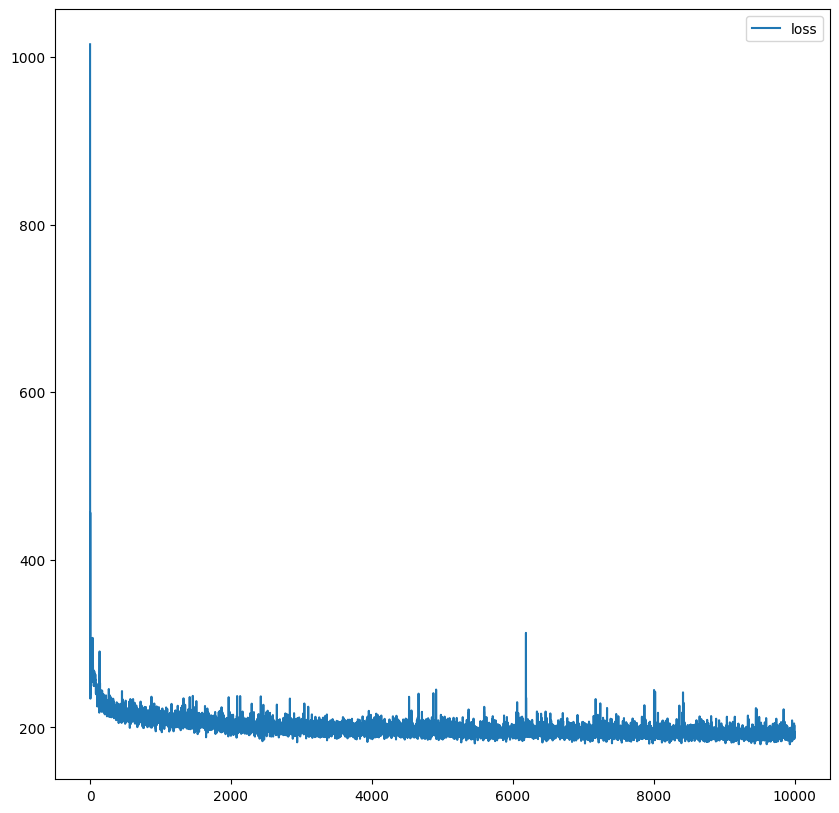

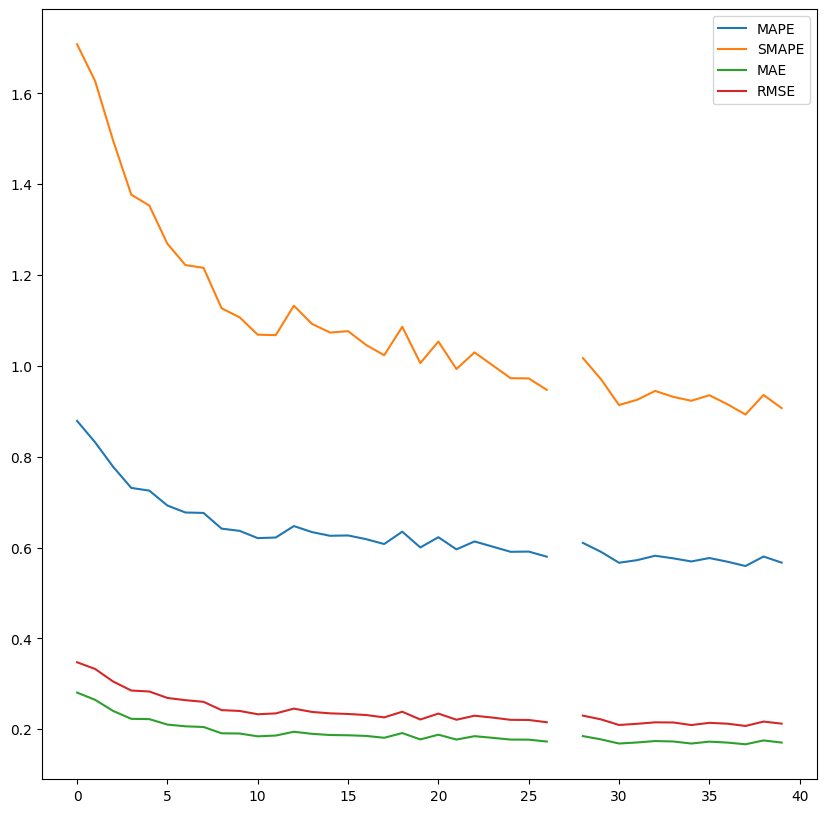

In [ ]:
### 2. Inv cbox bsdf prior

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 10000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250,
    bsdf_prior = True
)


exp = run_experiment(setup, training_context, "inv_cbox_10k_bsdf_hash_grid.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


100%|██████████| 50000/50000 [39:43<00:00, 20.98it/s]


average generate_samples_time time 0.006941763563156128
average compute_gradient_time time 0.03101308928489685
average nan_check_clip_time time 0.0006001805877685547
average optimizer_time time 8.726119995117188e-09


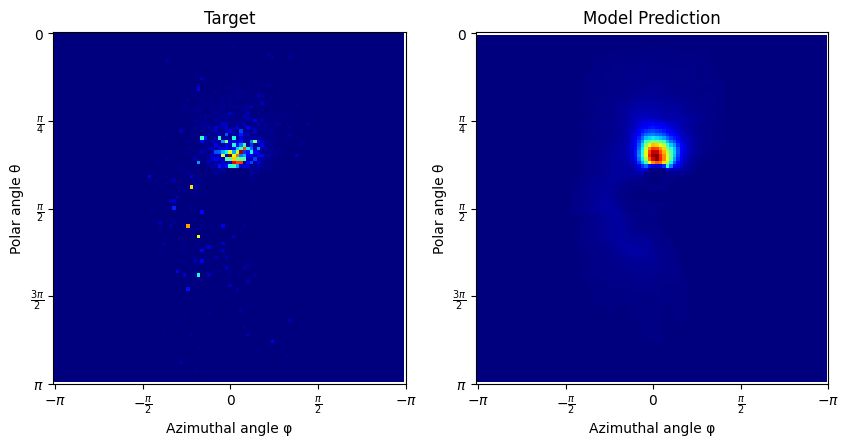

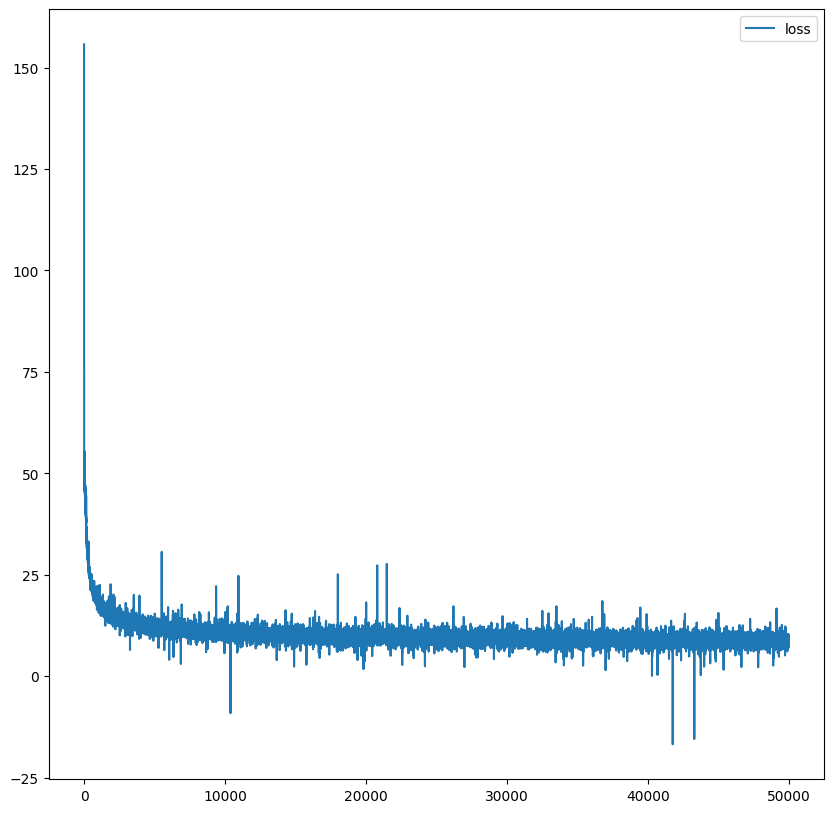

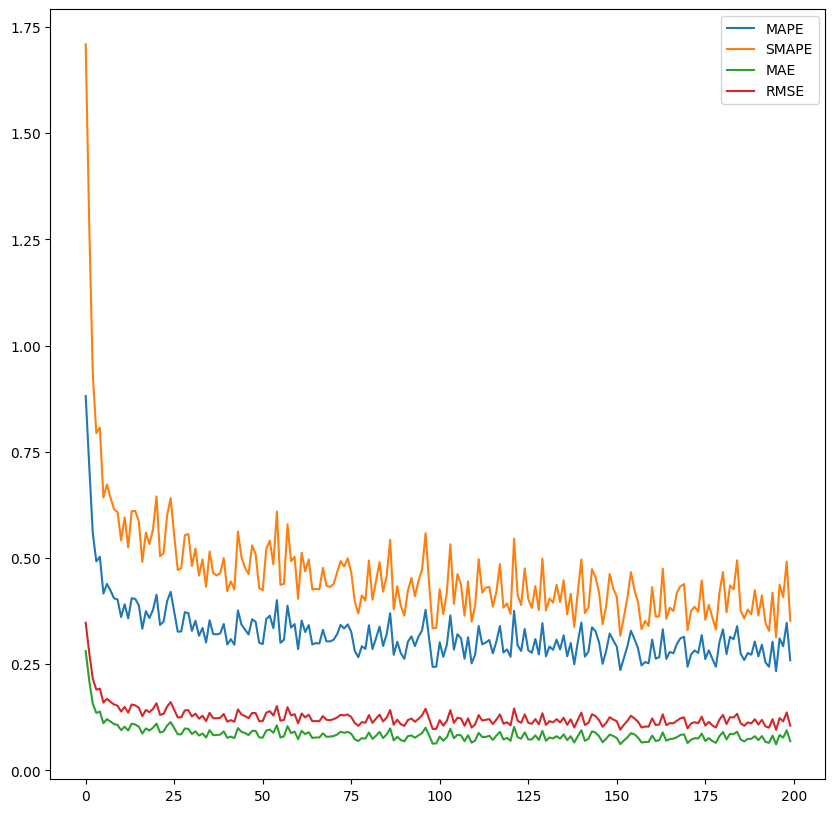

In [ ]:
### 3. Inv cbox one blob

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=False,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "inv_cbox_50k_cosine_oneblob.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


100%|██████████| 50000/50000 [47:30<00:00, 17.54it/s]


average generate_samples_time time 0.012879466423988342
average compute_gradient_time time 0.03130411870956421
average nan_check_clip_time time 0.0005611457586288452
average optimizer_time time 9.355545043945312e-09


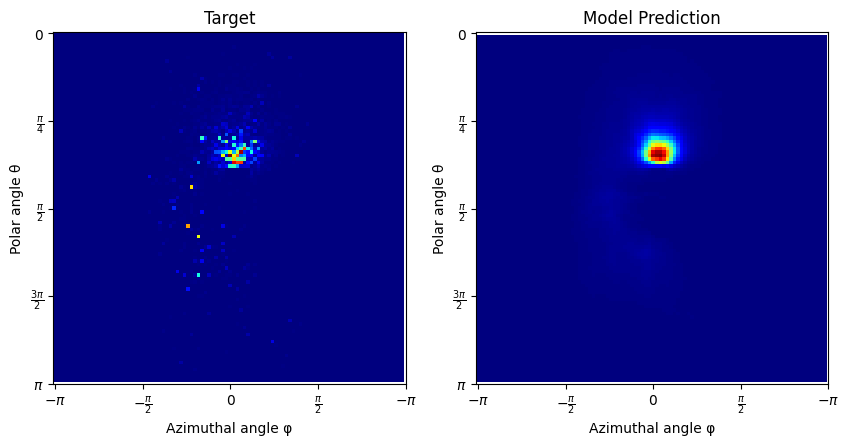

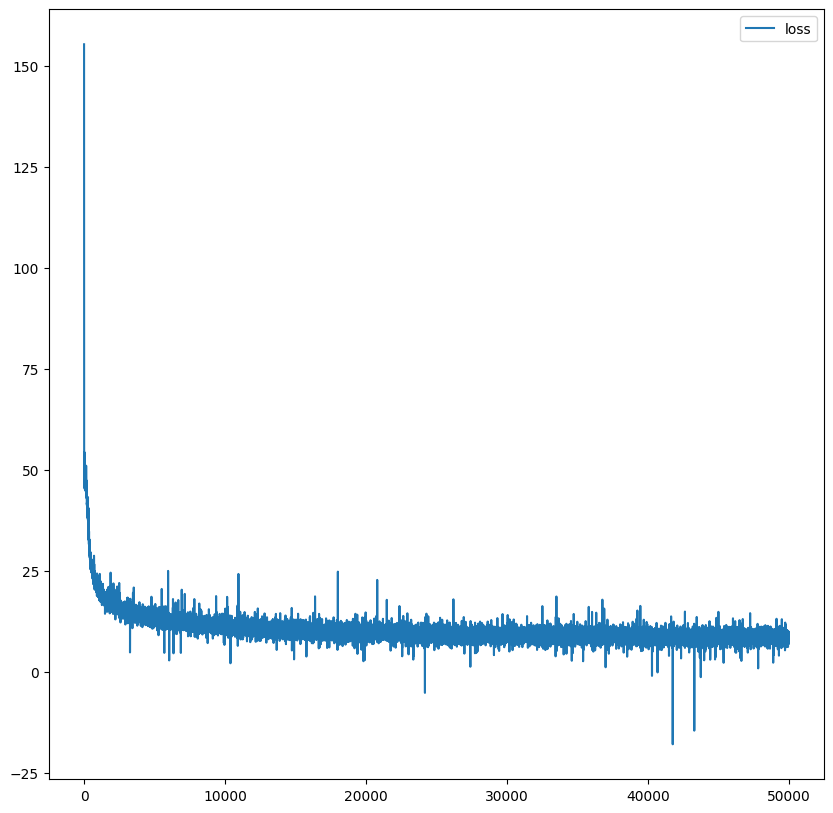

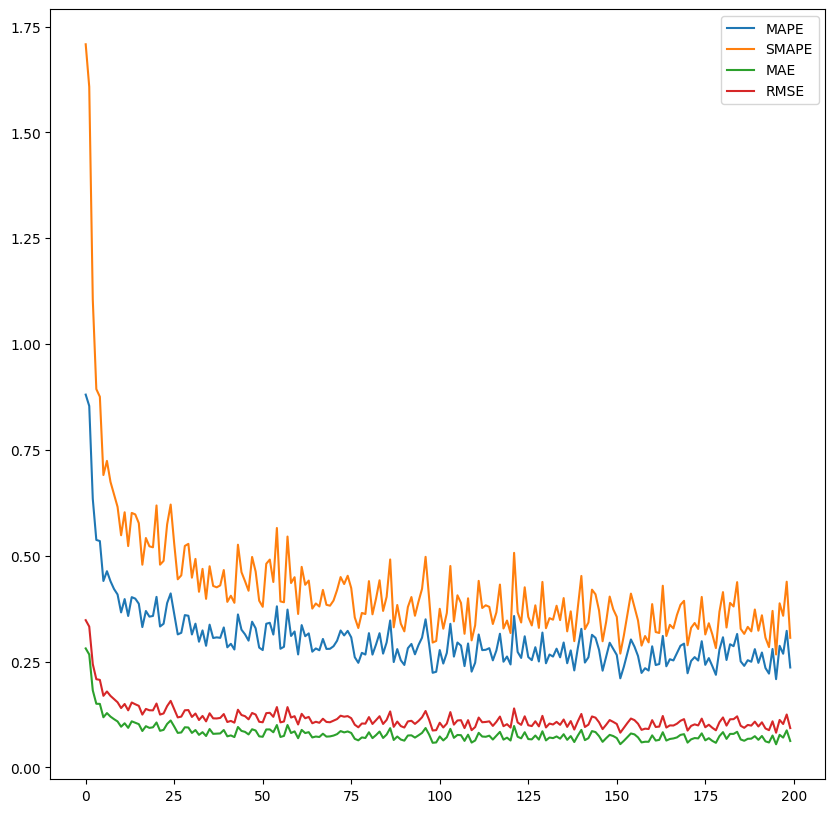

In [ ]:
### 4. Inv cbox multiple grids

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "inv_cbox_50k_cosine_hash_grid_multiple.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


100%|██████████| 50000/50000 [41:24<00:00, 20.13it/s]


average generate_samples_time time 0.007907443809509277
average compute_gradient_time time 0.030913932933807373
average nan_check_clip_time time 0.000572238564491272
average optimizer_time time 9.431838989257812e-09


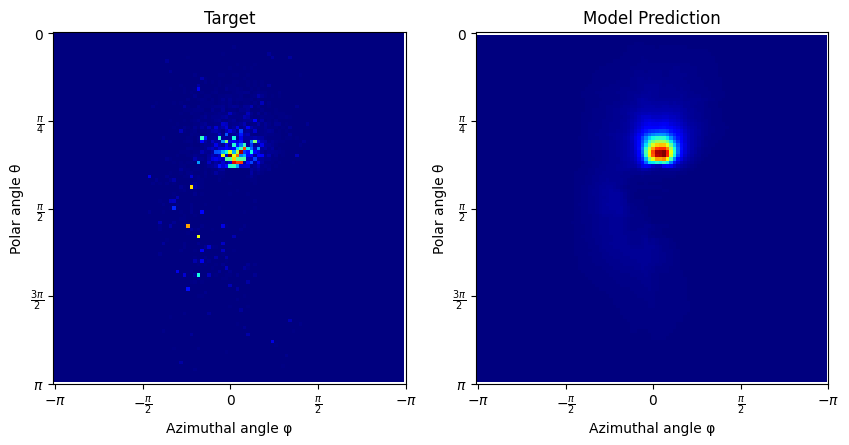

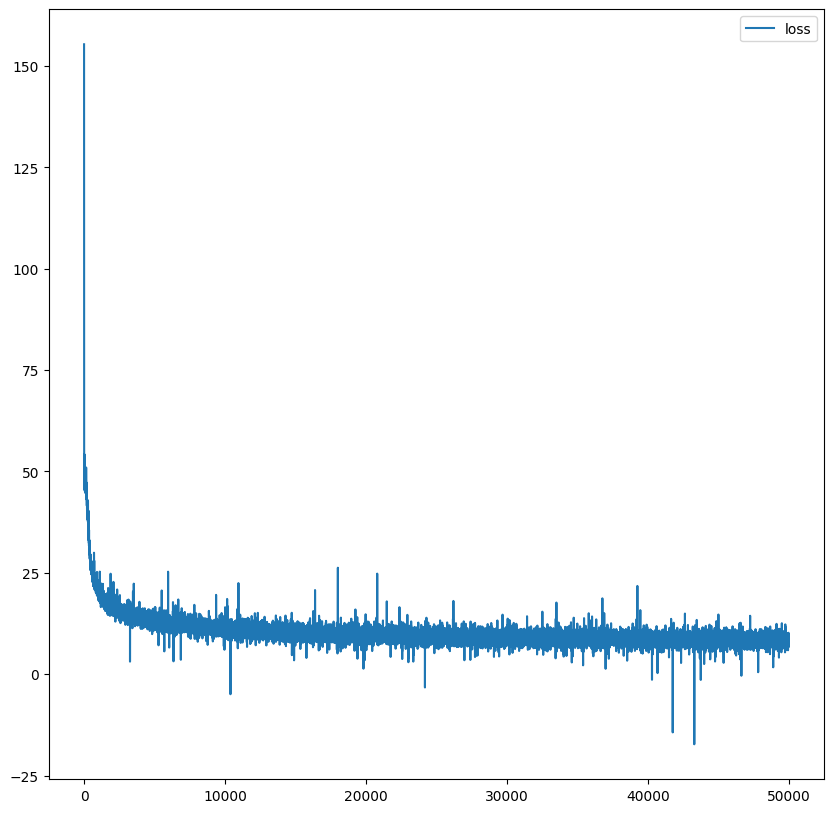

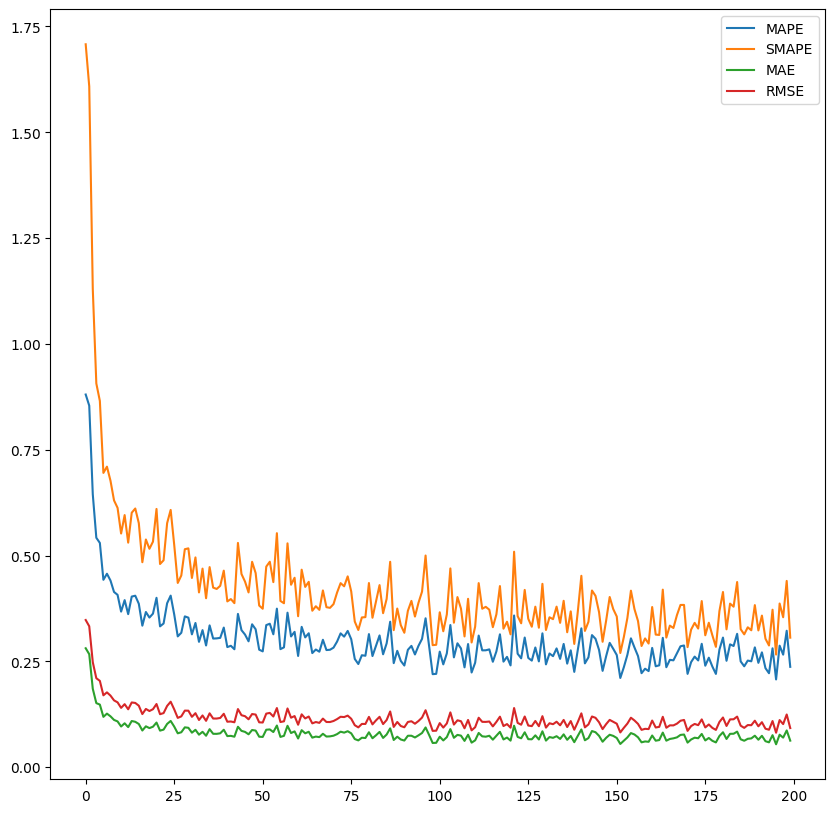

In [ ]:
### 5. Inv cbox multiple grids small

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],

    hash_grid_log2_size = 17,
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "inv_cbox_50k_cosine_hash_grid_multiple_small.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


100%|██████████| 50000/50000 [43:17<00:00, 19.25it/s]


average generate_samples_time time 0.009113979706764221
average compute_gradient_time time 0.031034179067611696
average nan_check_clip_time time 0.0005712599086761474
average optimizer_time time 8.945465087890624e-09


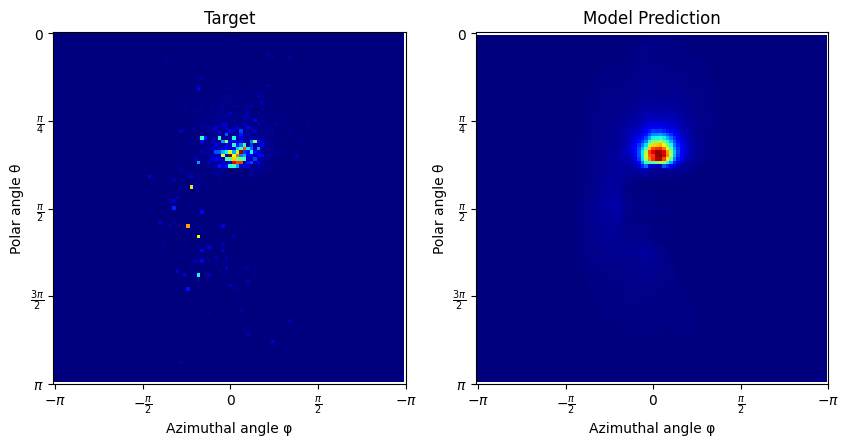

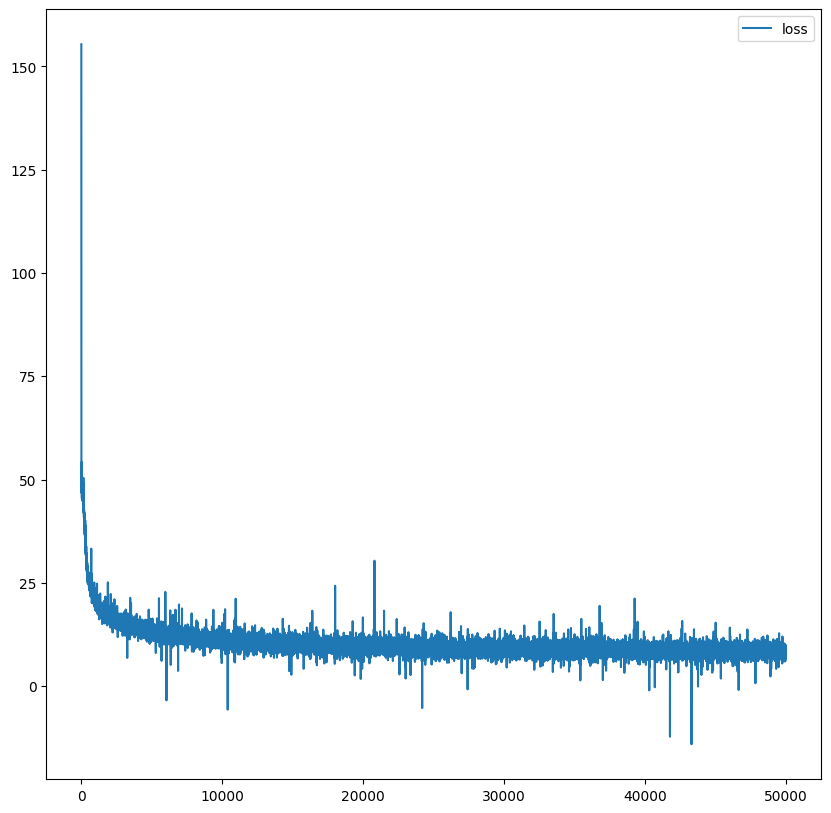

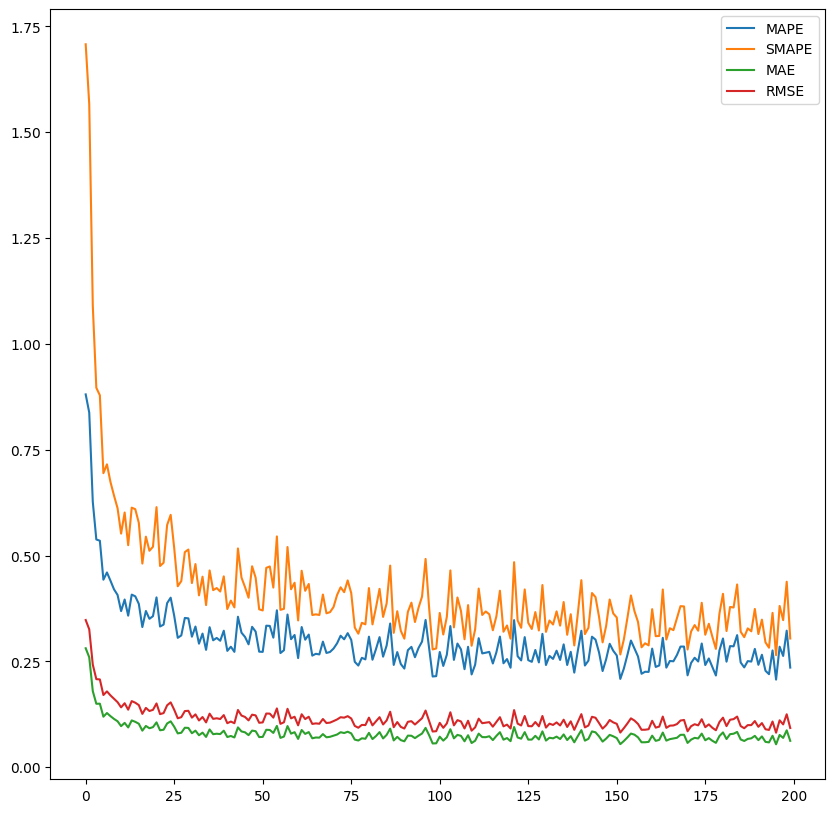

In [ ]:
### 6. Inv cbox slight stagger

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = True,

    grid_resolutions=[10, 12, 14, 16],
    grid_levels=[5, 6, 7, 8],
    grid_scale_factors=[1.4, 1.6, 1.8, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "inv_cbox_50k_cosine_hash_grid_multiple_stagger_slight.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


100%|██████████| 50000/50000 [43:46<00:00, 19.04it/s]


average generate_samples_time time 0.010017683510780334
average compute_gradient_time time 0.030722302341461182
average nan_check_clip_time time 0.0005972869300842285
average optimizer_time time 8.935928344726562e-09


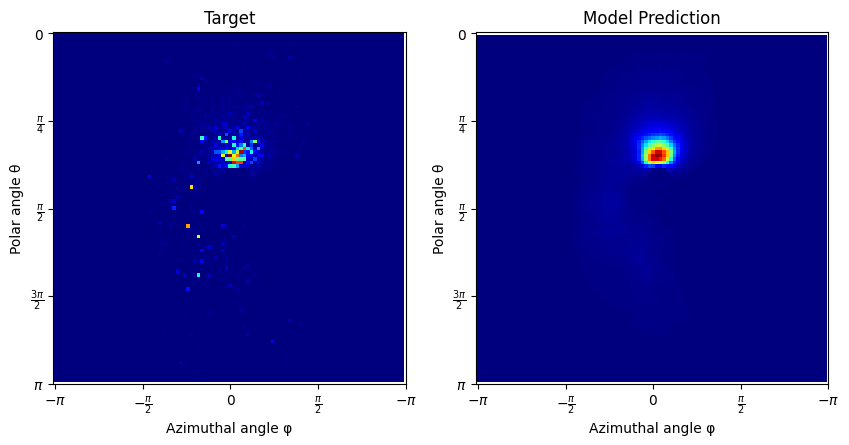

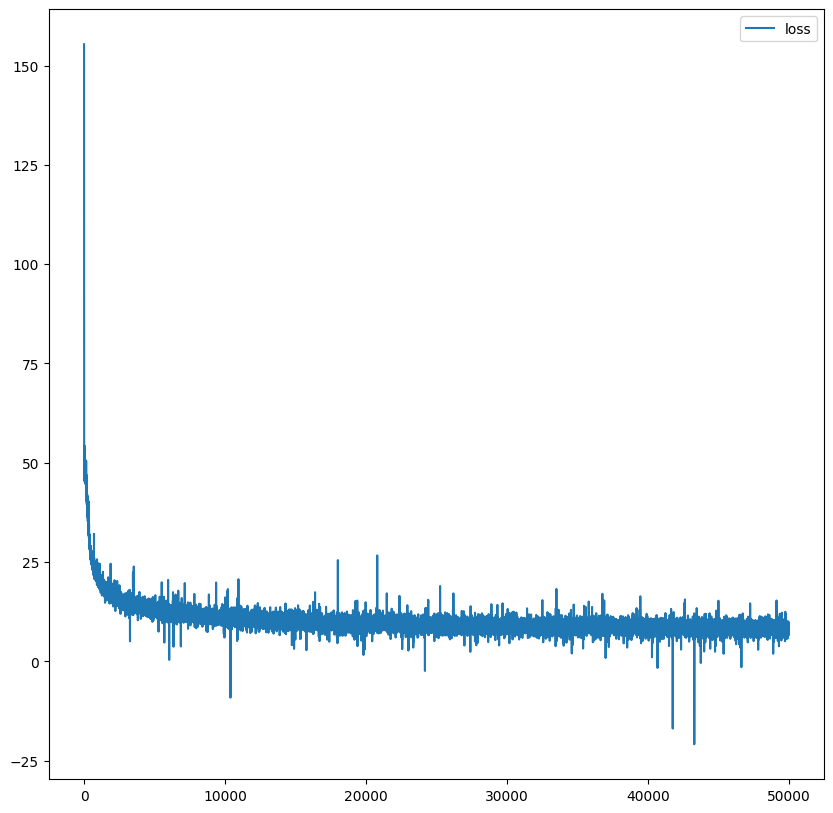

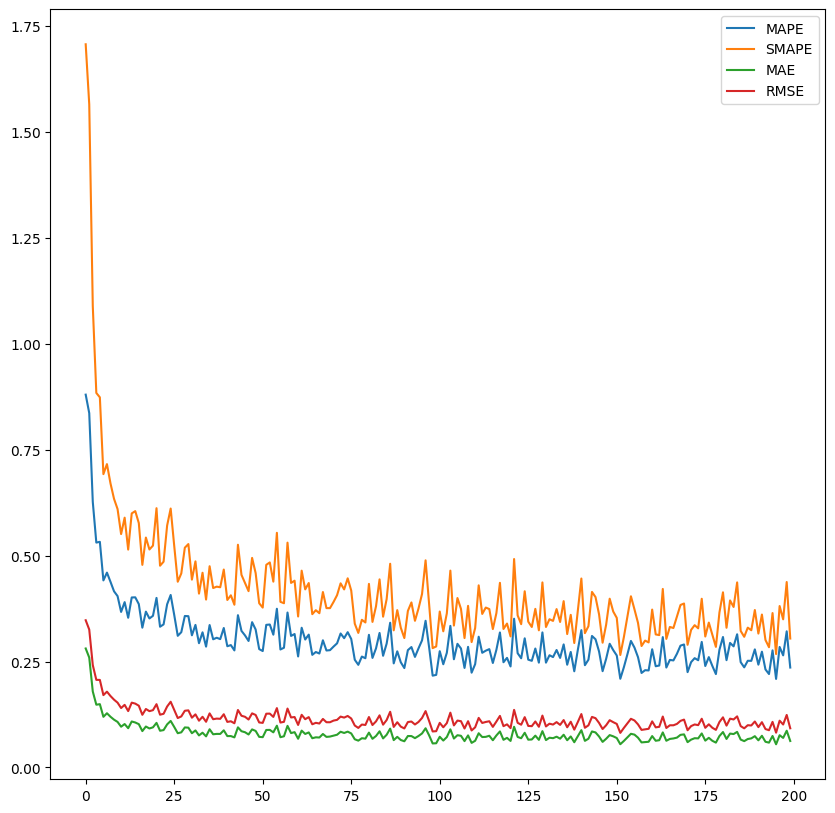

In [ ]:
### 7. Inv cbox aggressive stagger

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = True,

    grid_resolutions=[4, 8, 12, 16],
    grid_levels=[2, 4, 6, 8],
    grid_scale_factors=[1.25, 1.5, 1.75, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "inv_cbox_50k_cosine_hash_grid_multiple_stagger_aggressive.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


100%|██████████| 50000/50000 [57:42<00:00, 14.44it/s]


average generate_samples_time time 0.01618461738586426
average compute_gradient_time time 0.03519790808677673
average nan_check_clip_time time 0.00057038330078125
average optimizer_time time 1.2569427490234376e-08


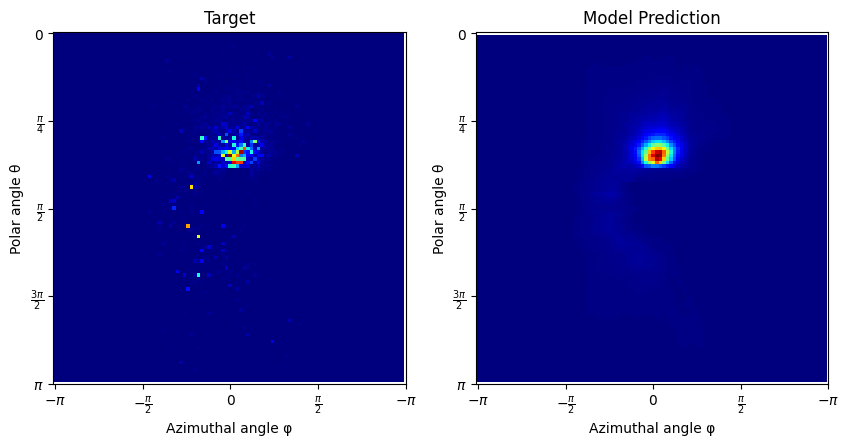

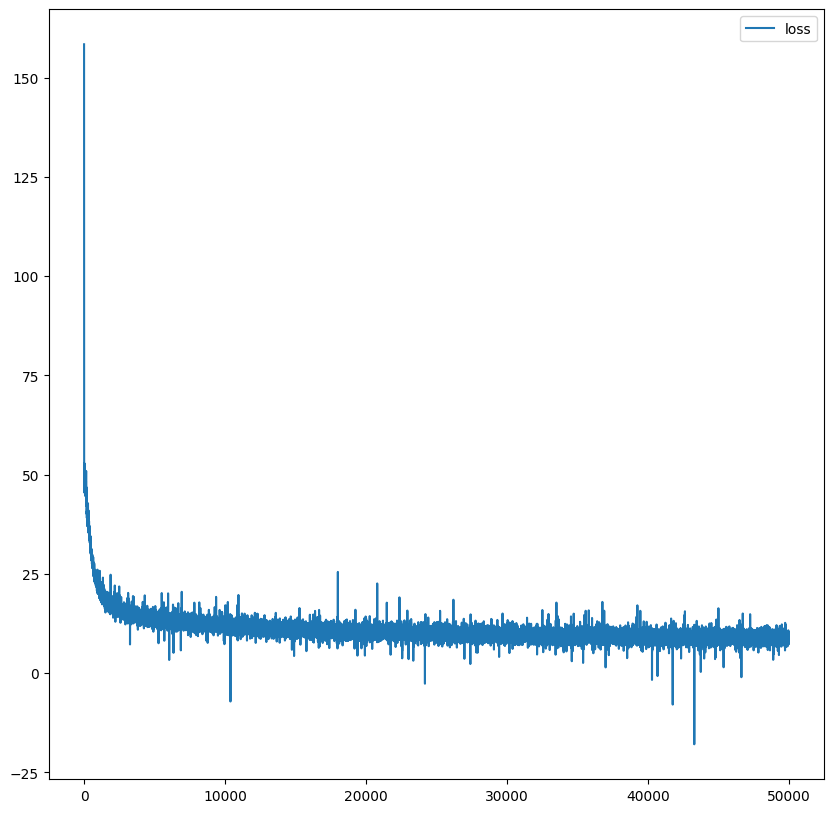

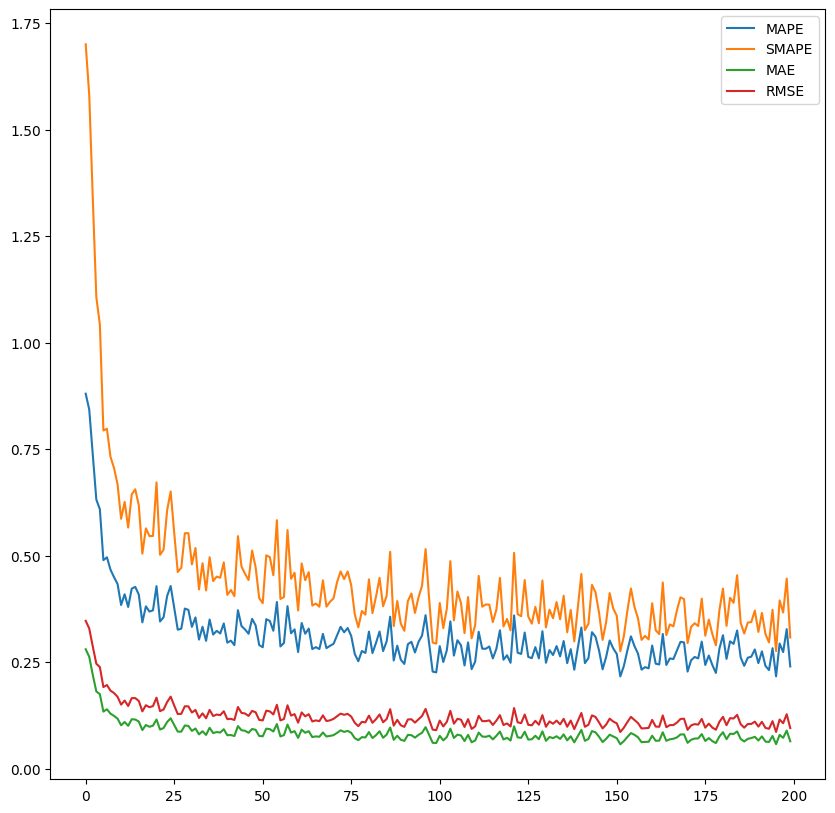

In [ ]:
### 8. Inv cbox latent encode

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "inv_cbox_50k_cosine_hash_grid_multiple_latent.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:110: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


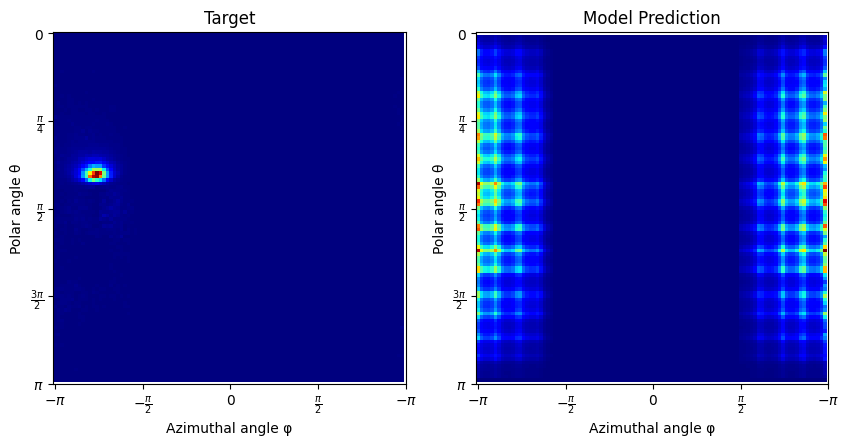

 10%|▉         | 4998/50000 [04:20<36:54, 20.32it/s] 

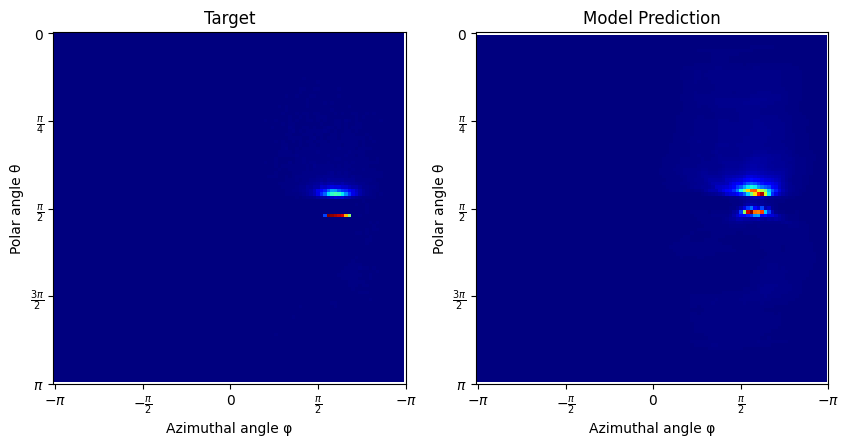

 20%|█▉        | 9999/50000 [08:31<32:34, 20.46it/s]

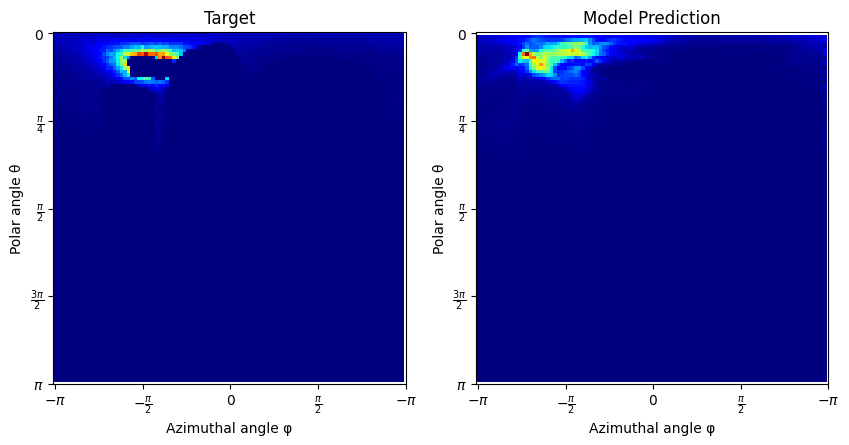

 30%|███       | 15000/50000 [12:40<28:20, 20.58it/s]

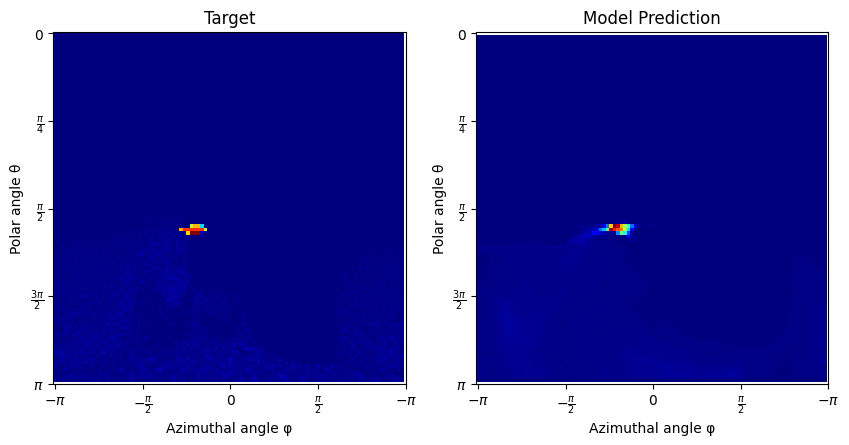

 40%|███▉      | 19998/50000 [16:50<24:27, 20.45it/s]

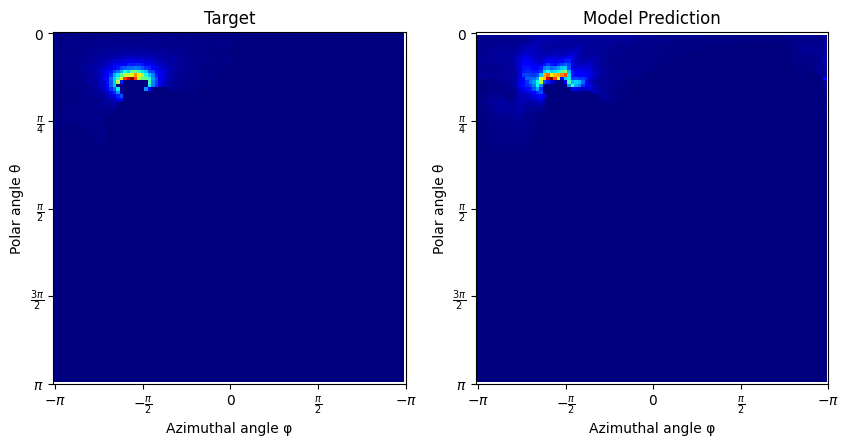

 50%|████▉     | 24999/50000 [21:00<20:16, 20.54it/s]

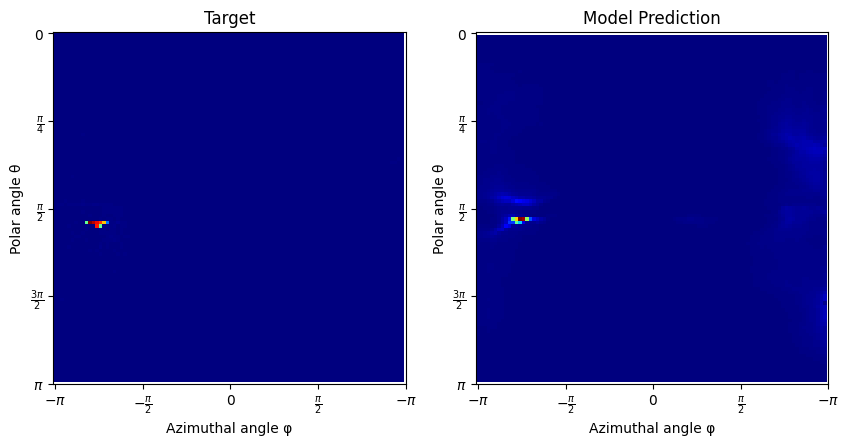

 60%|██████    | 30000/50000 [25:11<16:14, 20.53it/s]

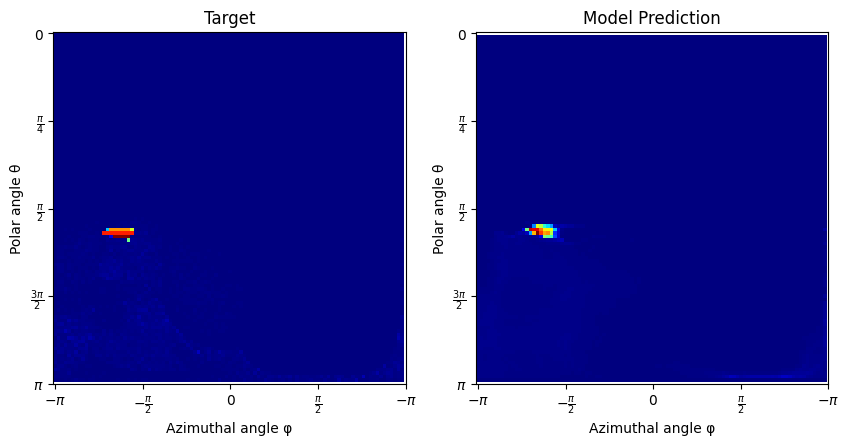

 70%|██████▉   | 34998/50000 [29:22<12:13, 20.44it/s]

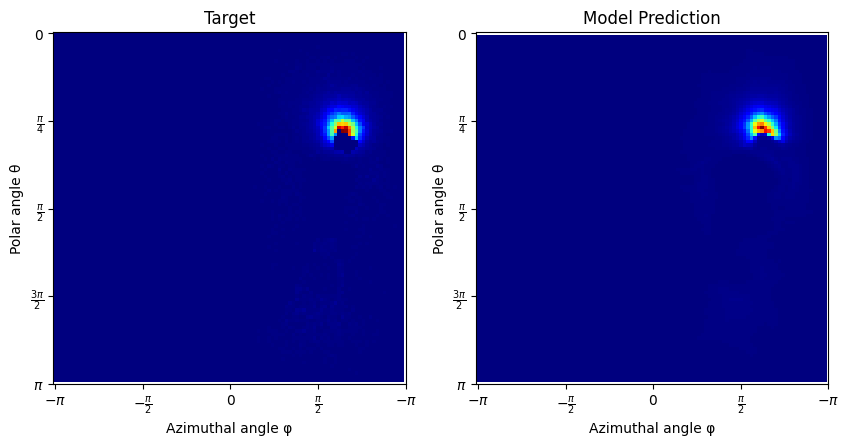

 80%|███████▉  | 39999/50000 [33:33<08:09, 20.44it/s]

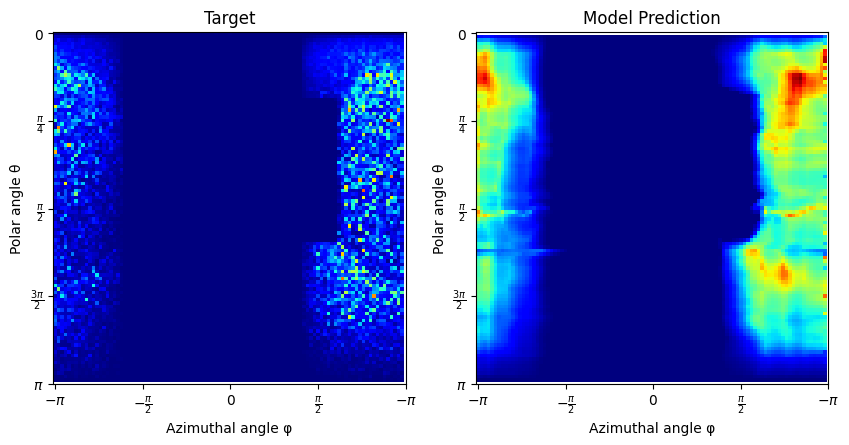

 90%|█████████ | 45000/50000 [37:43<04:04, 20.49it/s]

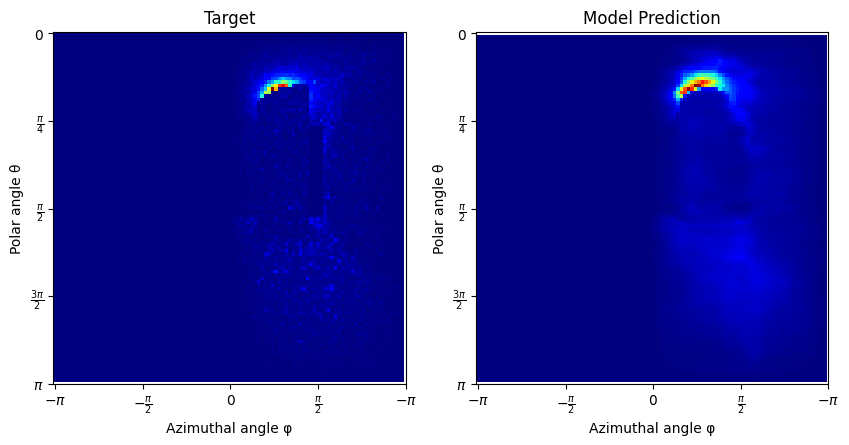

100%|██████████| 50000/50000 [41:54<00:00, 19.88it/s]


average generate_samples_time time 0.008134317011833191
average compute_gradient_time time 0.03066065584182739
average nan_check_clip_time time 0.0005287333488464356
average optimizer_time time 8.535385131835937e-09


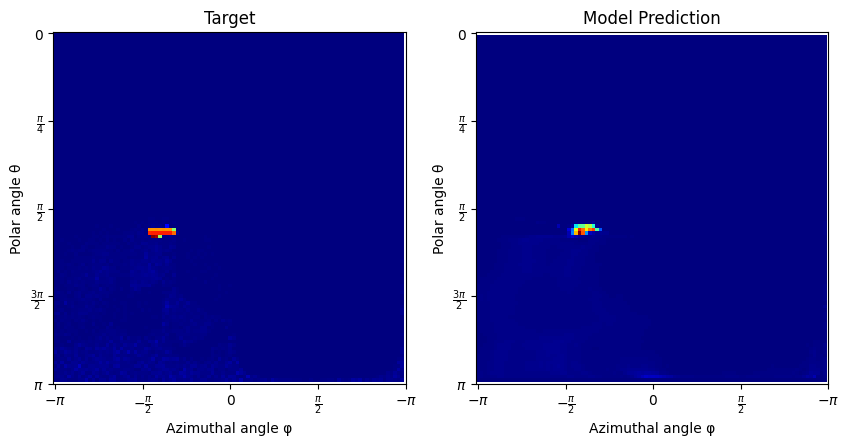

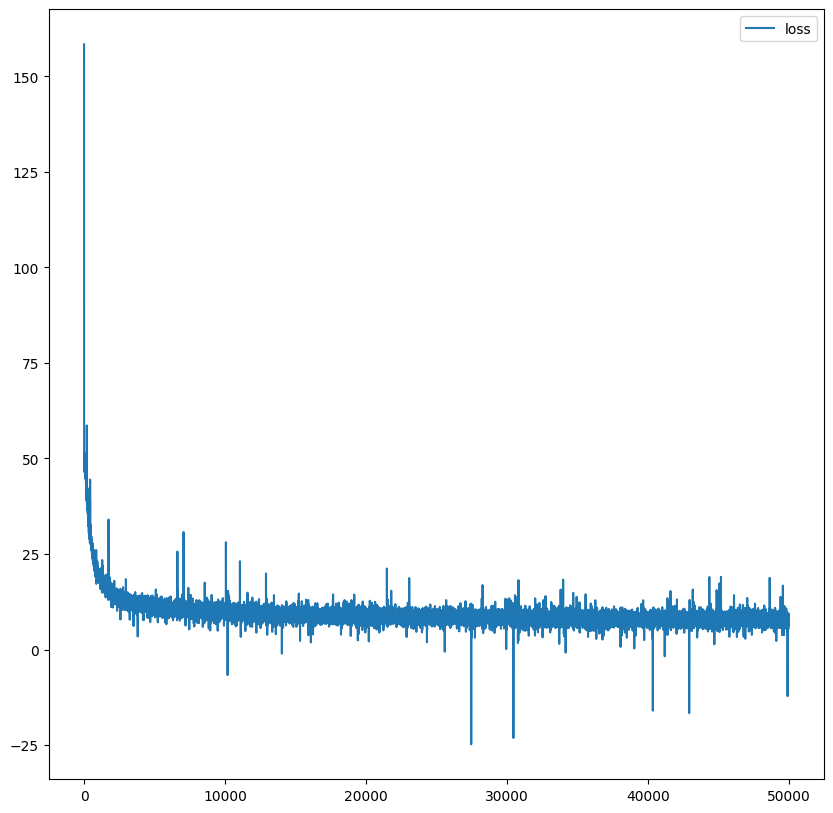

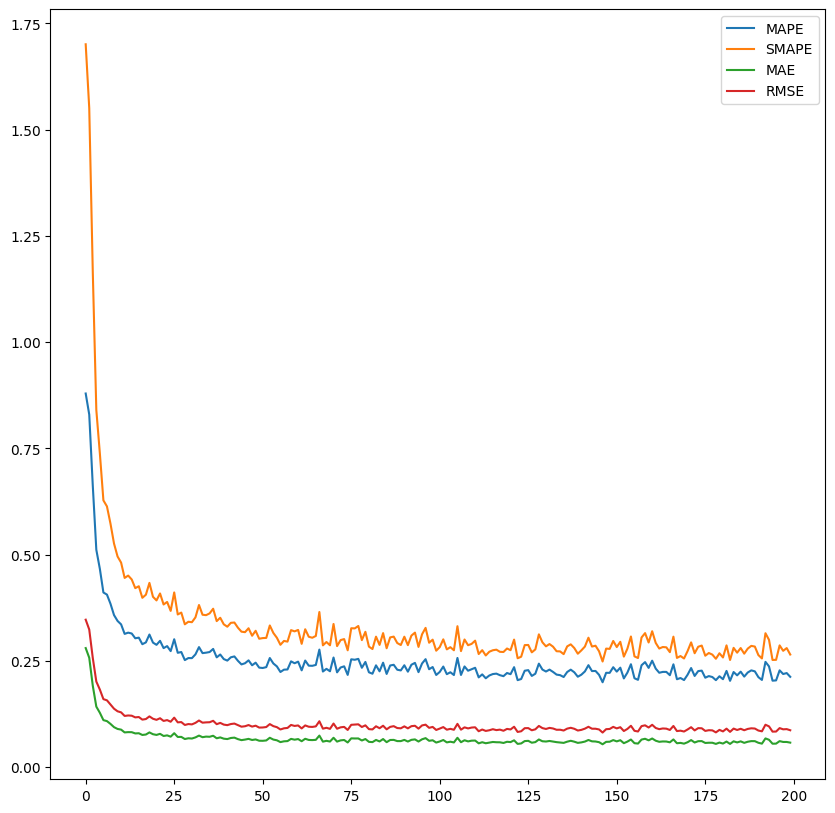

In [ ]:
### 8. Inv cbox full

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid= True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = True,

    grid_resolutions=[4, 8, 12, 16],
    grid_levels=[2, 4, 6, 8],
    grid_scale_factors=[1.25, 1.5, 1.75, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "inv_cbox_50k_full.pkl")
del(exp)

## Spaceship

loaded scene


d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda
created model
starting training


100%|██████████| 50000/50000 [1:06:24<00:00, 12.55it/s]


average generate_samples_time time 0.03398671196937561
average compute_gradient_time time 0.030159245438575746
average nan_check_clip_time time 0.0005196831941604614
average optimizer_time time 1.0662078857421876e-08


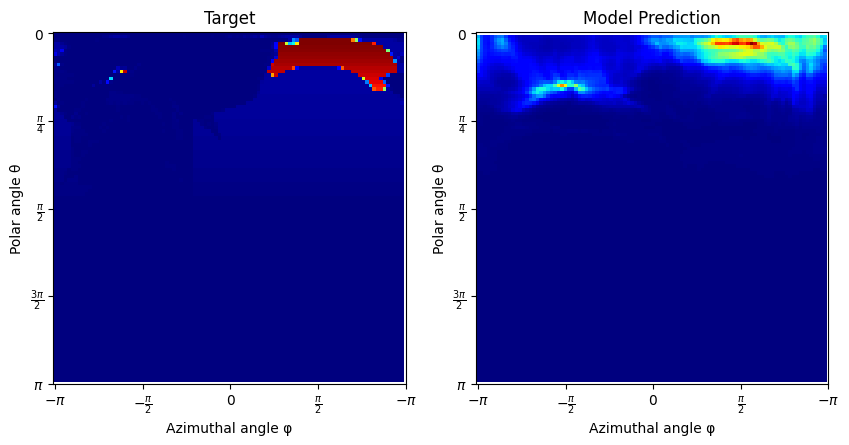

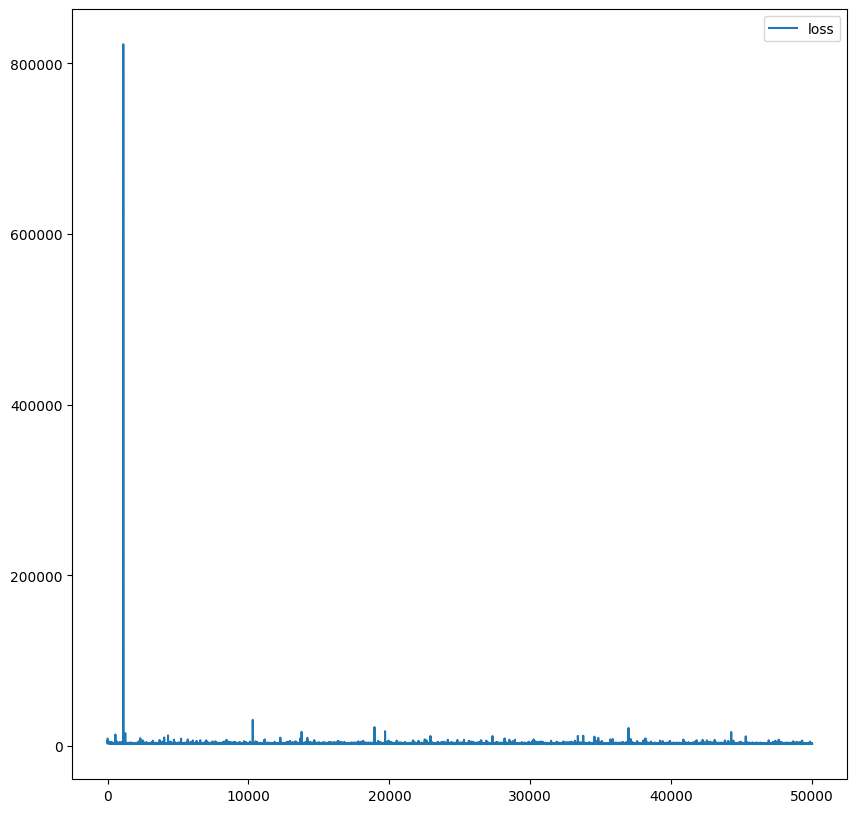

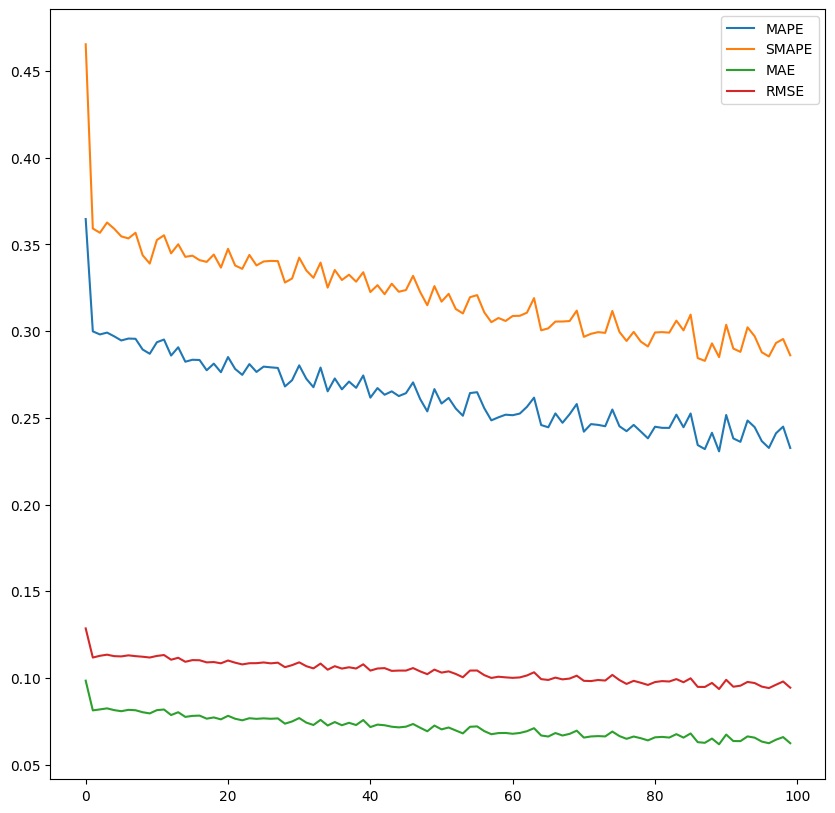

In [ ]:
### Spaceship Mueller prior

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='uniform',
    scene_name = 'spaceship',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=False,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=5, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 500
)

exp = run_experiment(setup, training_context, "spaceship_50k_mueller.pkl")
 
del(exp)

loaded scene


d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:110: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
100%|██████████| 50000/50000 [1:02:56<00:00, 13.24it/s]
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


average generate_samples_time time 0.03204023537158966
average compute_gradient_time time 0.029609901266098023
average nan_check_clip_time time 0.0005670744609832764
average optimizer_time time 8.95977020263672e-09


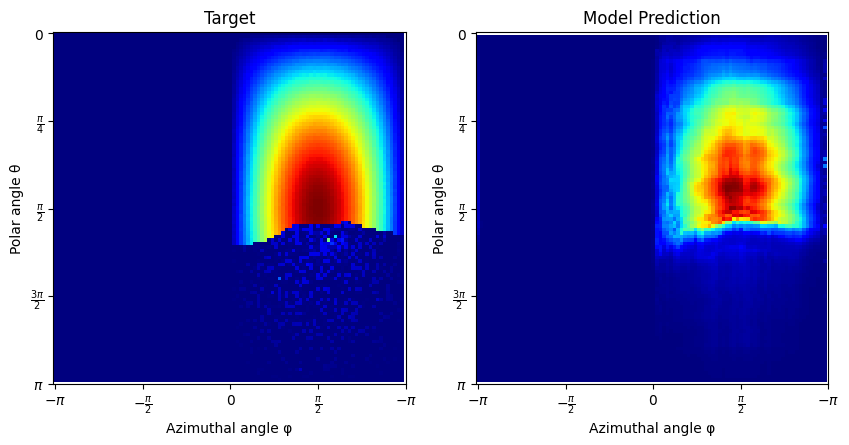

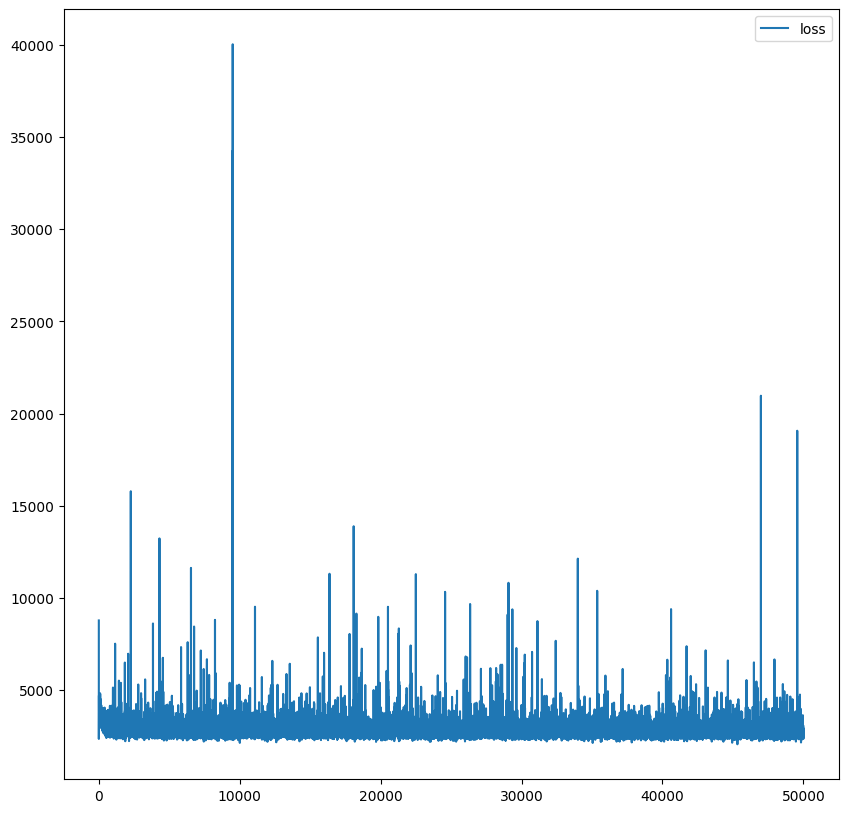

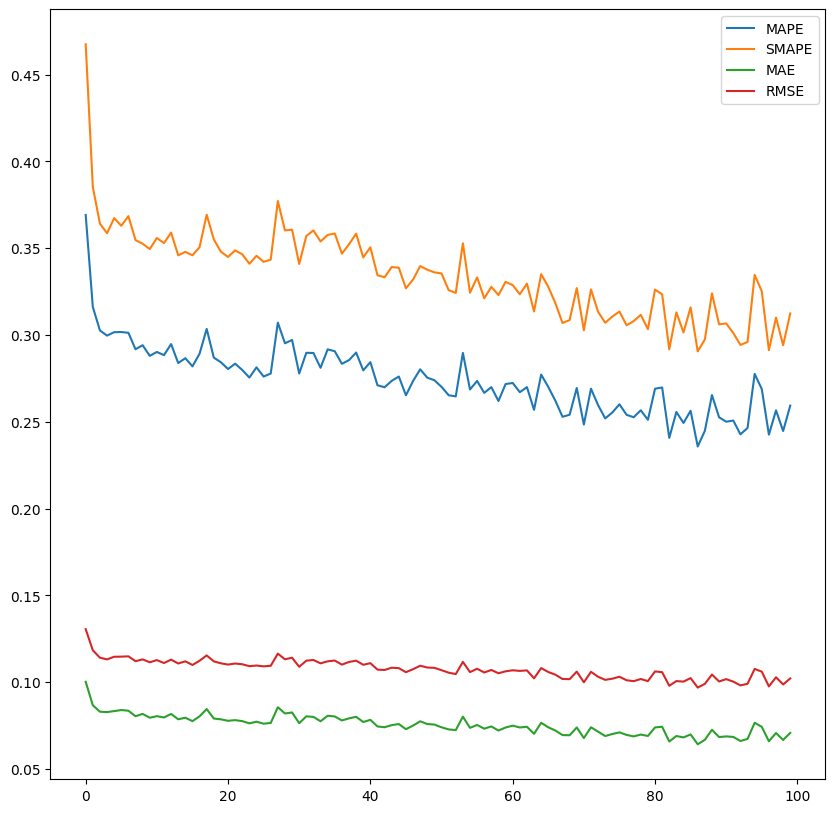

In [ ]:
### Spaceship uniform prior

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='uniform',
    scene_name = 'spaceship',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=5, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 500
)

exp = run_experiment(setup, training_context, "spaceship_50k_uniform_hash_grid.pkl")
 
del(exp)

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]

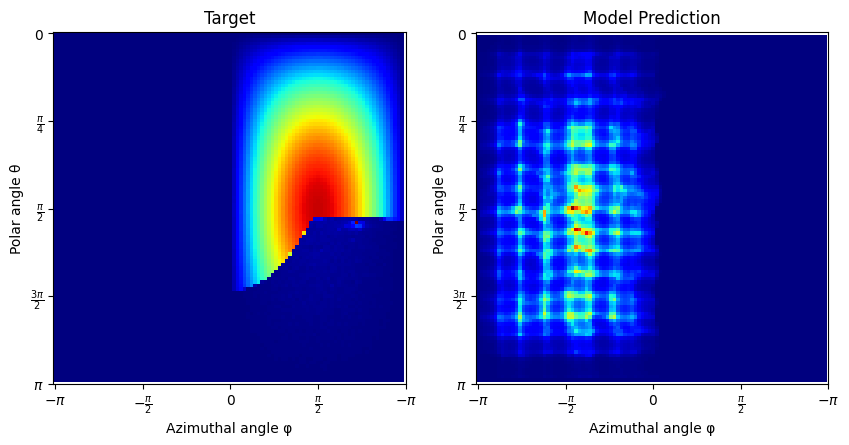

 10%|▉         | 4999/50000 [07:20<1:00:03, 12.49it/s]

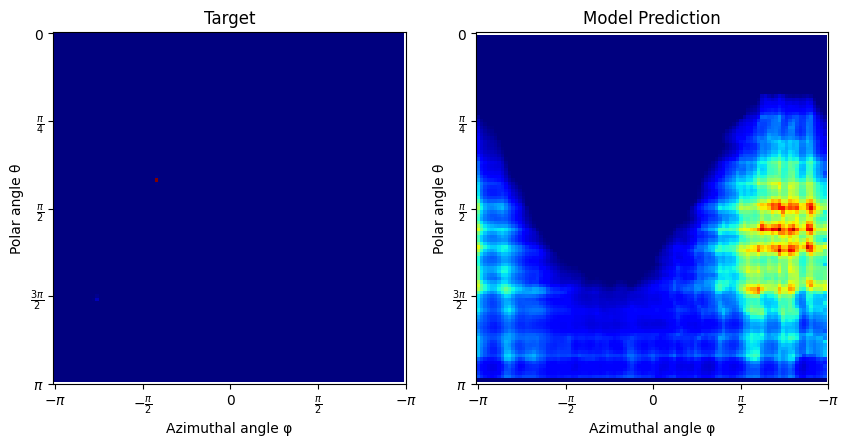

 20%|█▉        | 9999/50000 [14:41<53:53, 12.37it/s]  

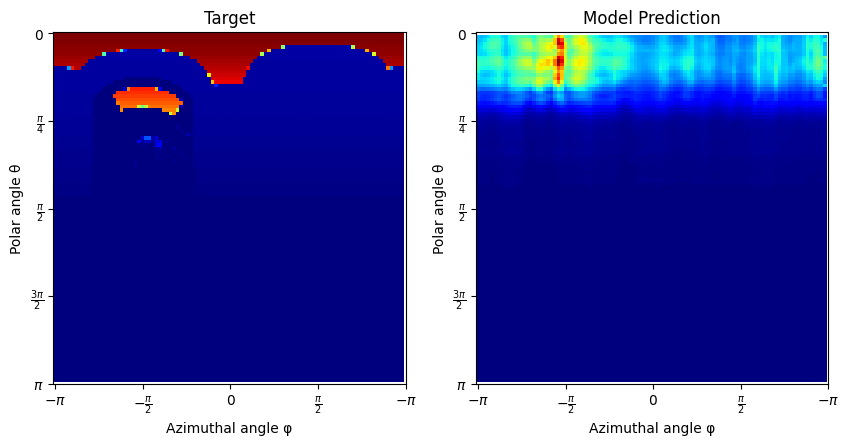

 30%|██▉       | 14999/50000 [22:01<46:52, 12.44it/s]  

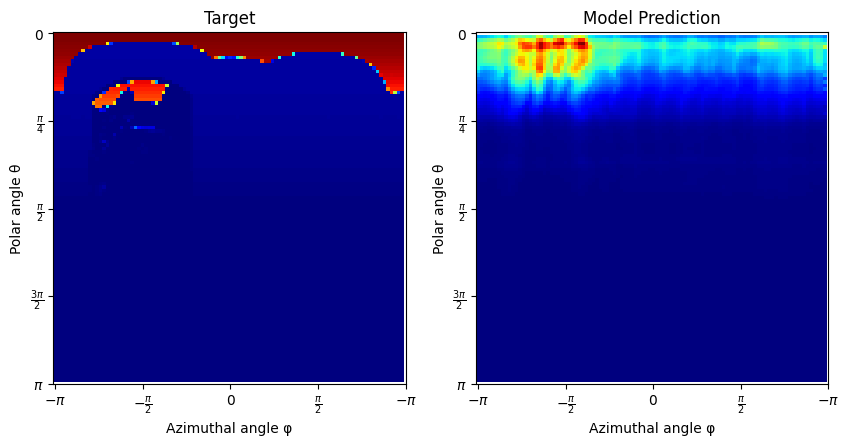

 40%|███▉      | 19999/50000 [29:11<40:19, 12.40it/s]  

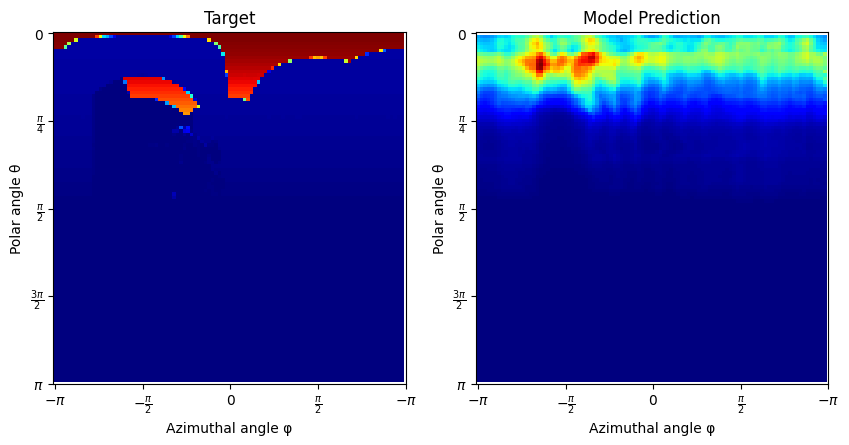

 50%|████▉     | 24999/50000 [36:32<33:45, 12.35it/s]

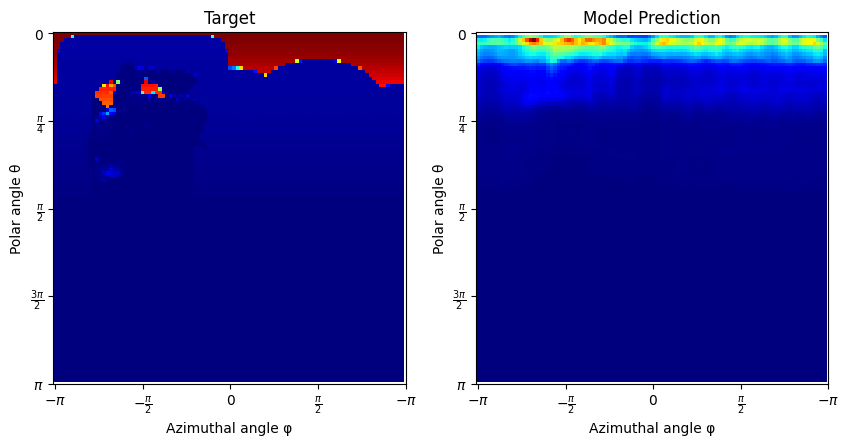

 60%|█████▉    | 29999/50000 [43:42<26:54, 12.39it/s]

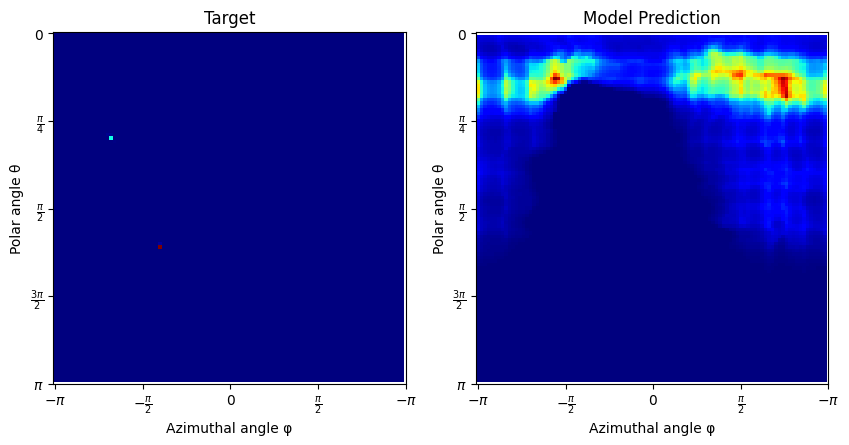

 70%|██████▉   | 34999/50000 [51:02<20:54, 11.95it/s]

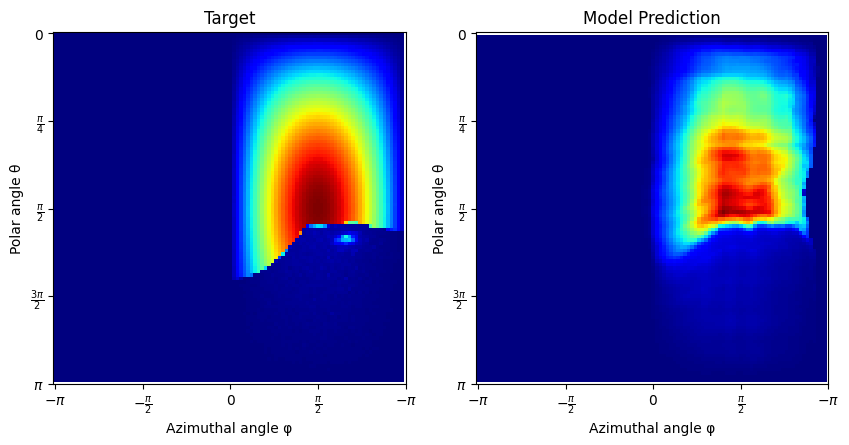

 80%|████████  | 40000/50000 [58:33<13:40, 12.19it/s]

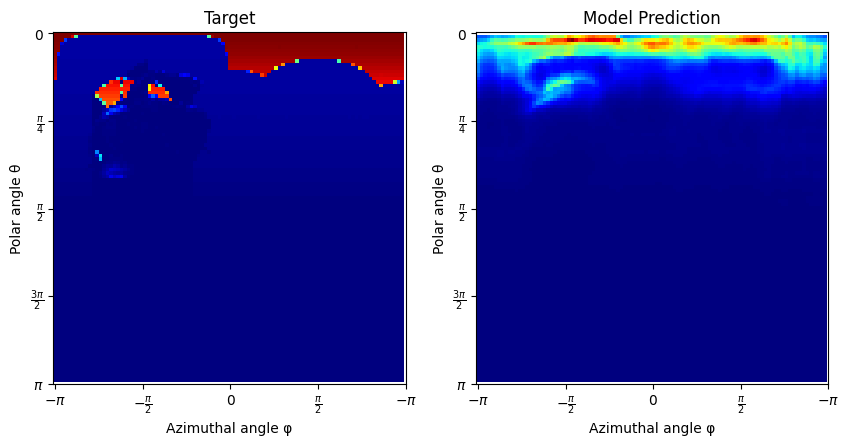

 90%|████████▉ | 44999/50000 [1:05:53<06:52, 12.13it/s]

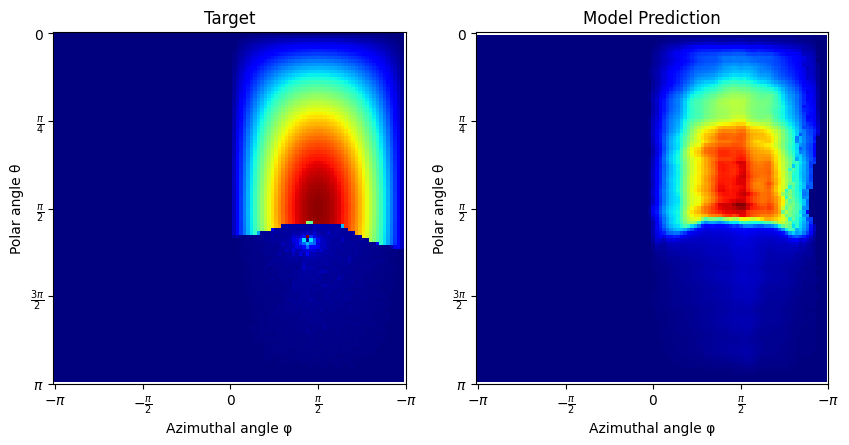

100%|██████████| 50000/50000 [1:13:05<00:00, 11.40it/s]


average generate_samples_time time 0.038375988469123844
average compute_gradient_time time 0.0310098757982254
average nan_check_clip_time time 0.00058581787109375
average optimizer_time time 1.1758804321289063e-08


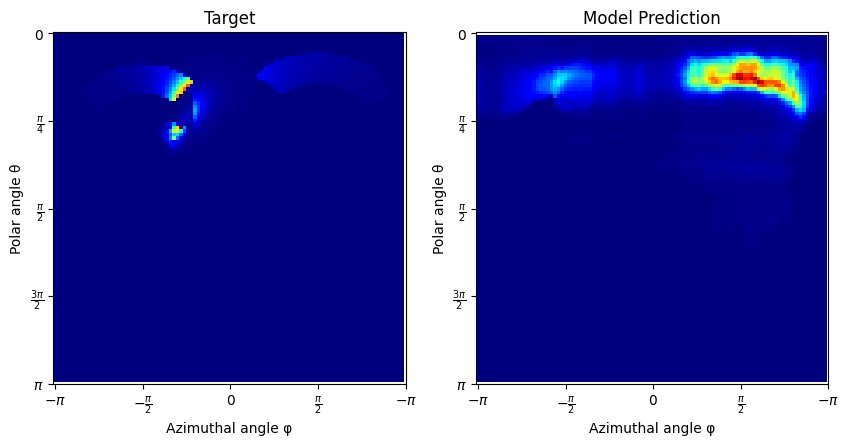

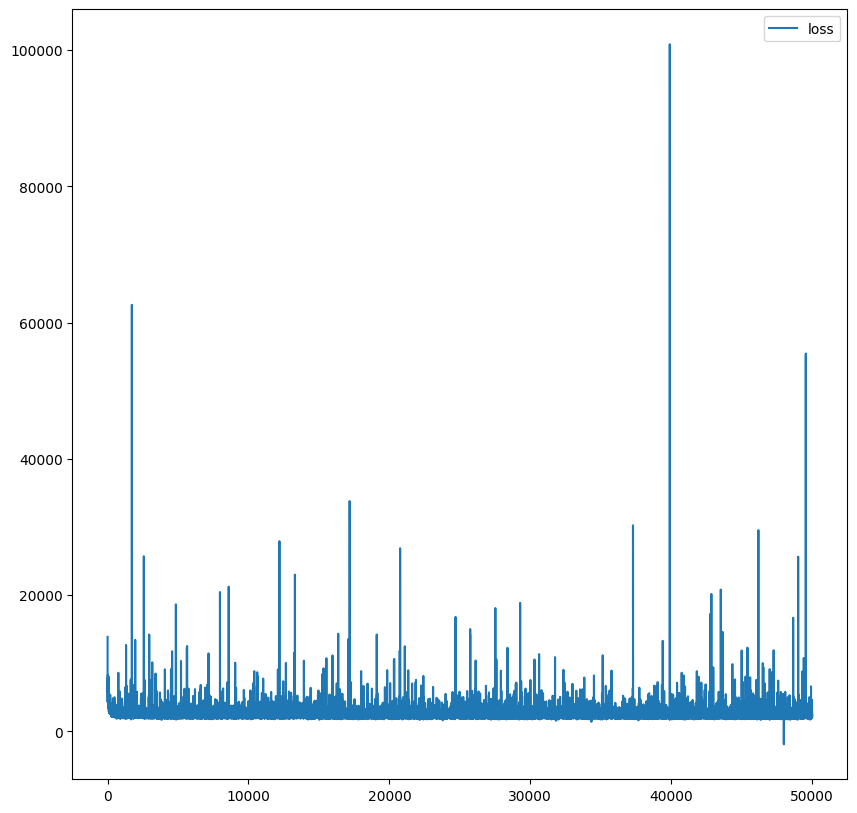

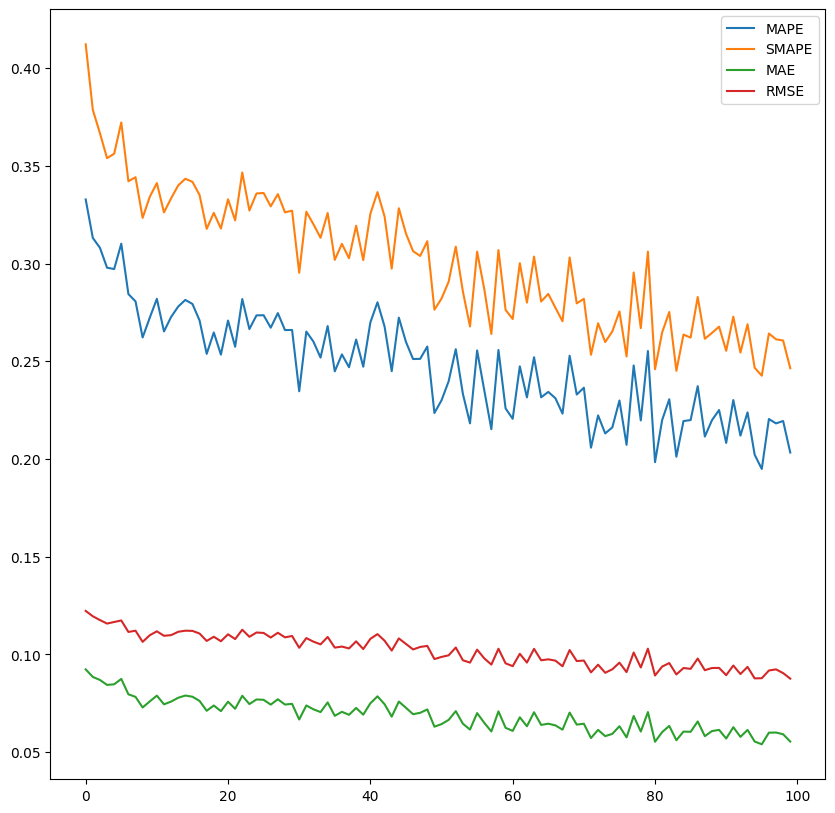

In [ ]:
### Spaceship cosine prior

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'spaceship',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=5, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 500
)

exp = run_experiment(setup, training_context, "spaceship_50k_cosine_hash_grid.pkl")
 
del(exp)

loaded scene
using device: cuda
created model
starting training


100%|██████████| 3000/3000 [13:28<00:00,  3.71it/s]


average generate_samples_time time 0.18839695795377095
average compute_gradient_time time 0.03858623464902242
average nan_check_clip_time time 0.0005830350716908773
average optimizer_time time 1.823107401529948e-07


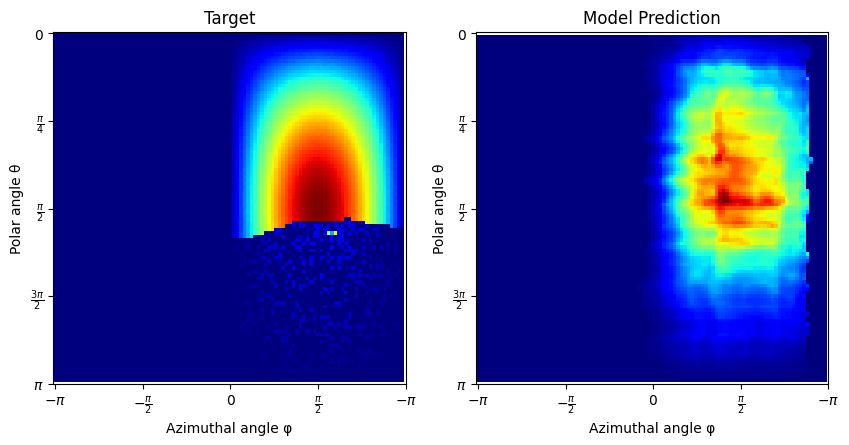

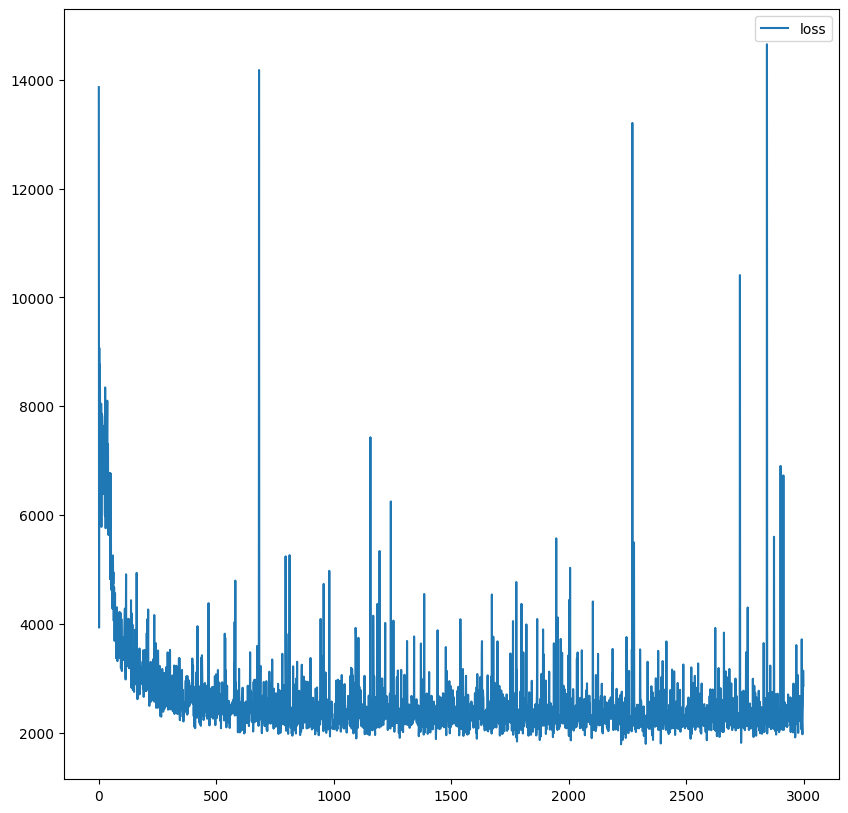

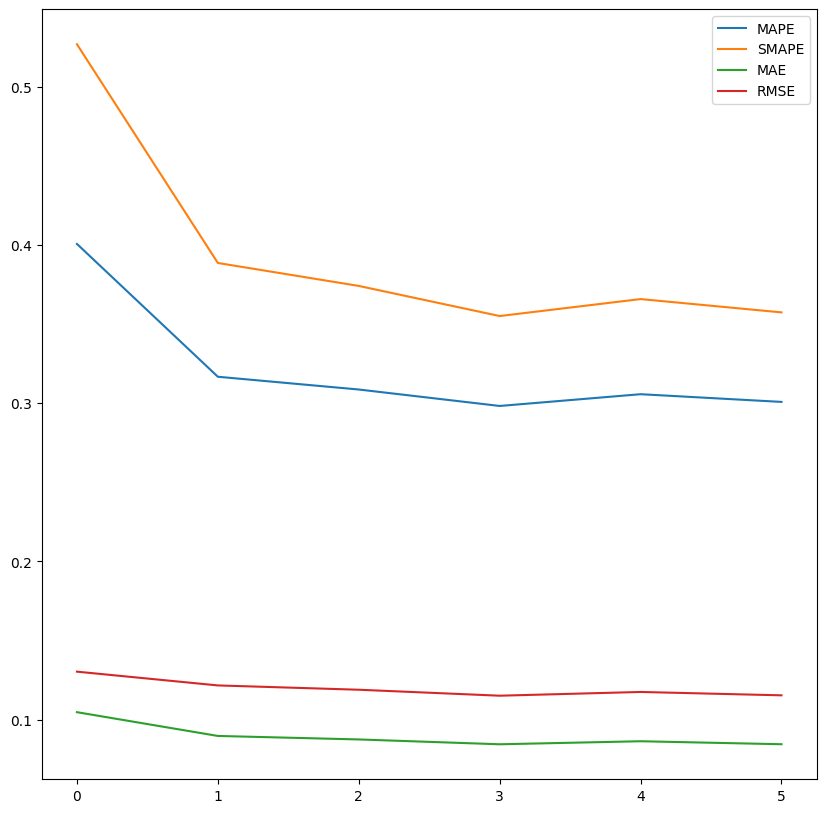

In [ ]:
### Spaceship bsdf prior

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'spaceship',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 3000,
    bounces=5, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 500,
    bsdf_prior = False
)

exp = run_experiment(setup, training_context, "spaceship_3k_bsdf_hash_grid.pkl")
 
del(exp)

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]

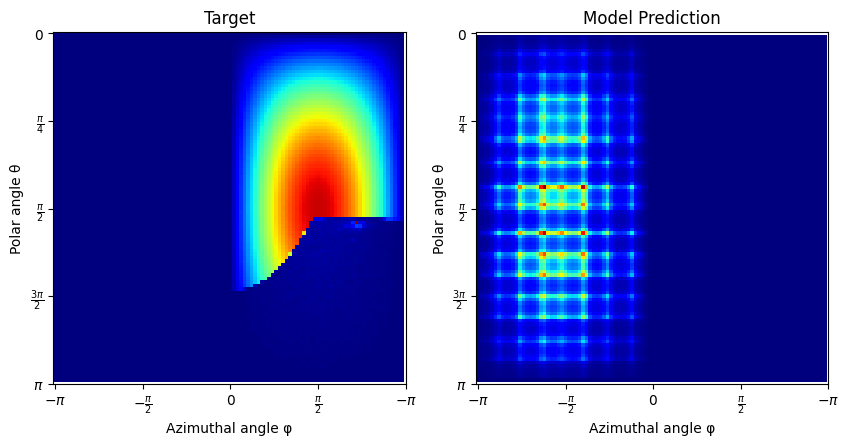

 10%|▉         | 4999/50000 [07:38<1:02:00, 12.10it/s]

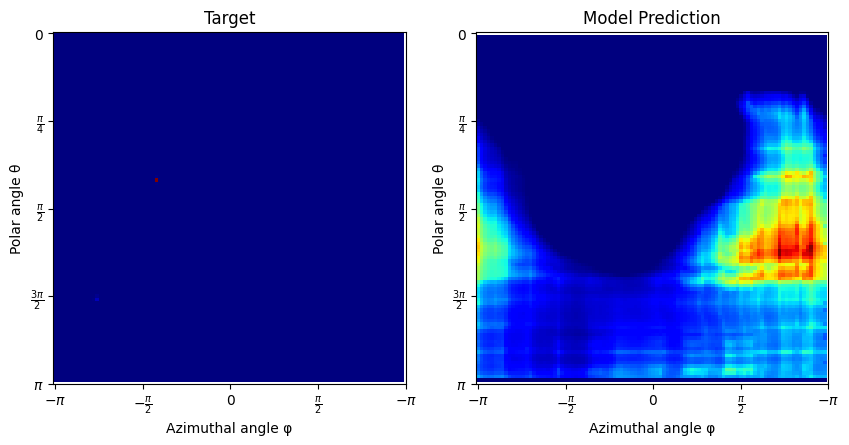

 20%|█▉        | 9999/50000 [15:09<55:45, 11.96it/s]  

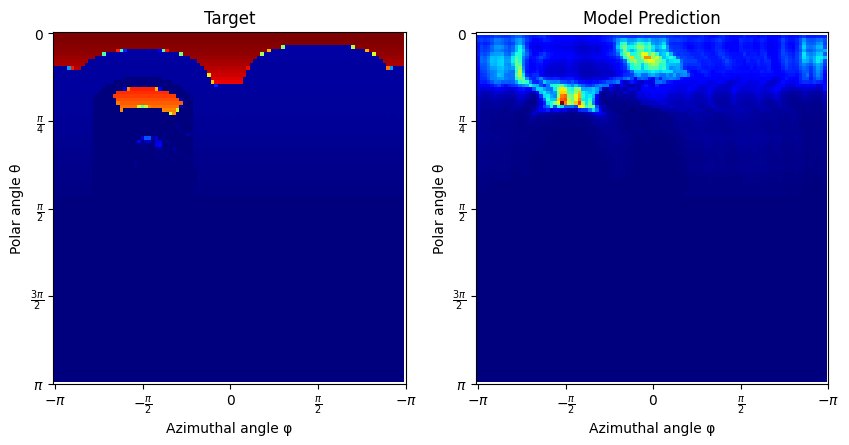

 30%|███       | 15000/50000 [22:19<46:24, 12.57it/s]  

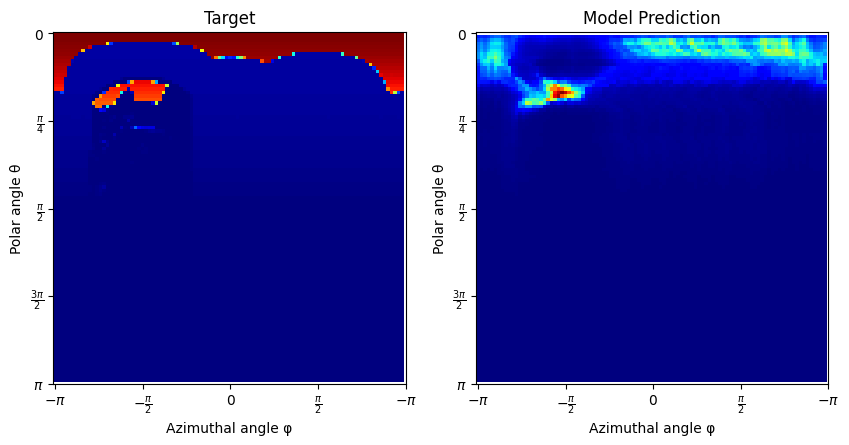

 40%|███▉      | 19999/50000 [29:29<40:21, 12.39it/s]  

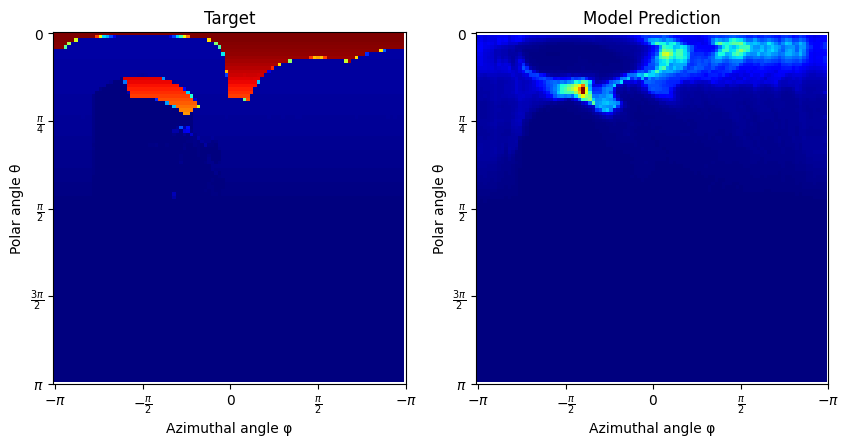

 50%|████▉     | 24999/50000 [36:40<33:44, 12.35it/s]

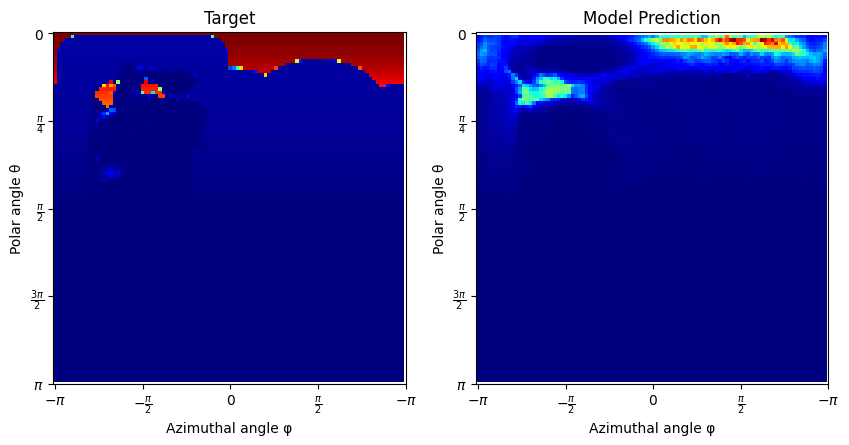

 60%|█████▉    | 29999/50000 [43:50<26:58, 12.36it/s]

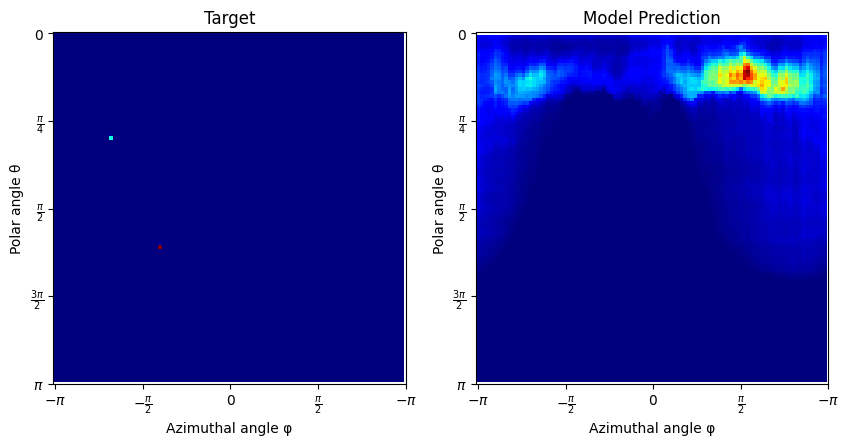

 70%|██████▉   | 34999/50000 [51:10<20:18, 12.32it/s]

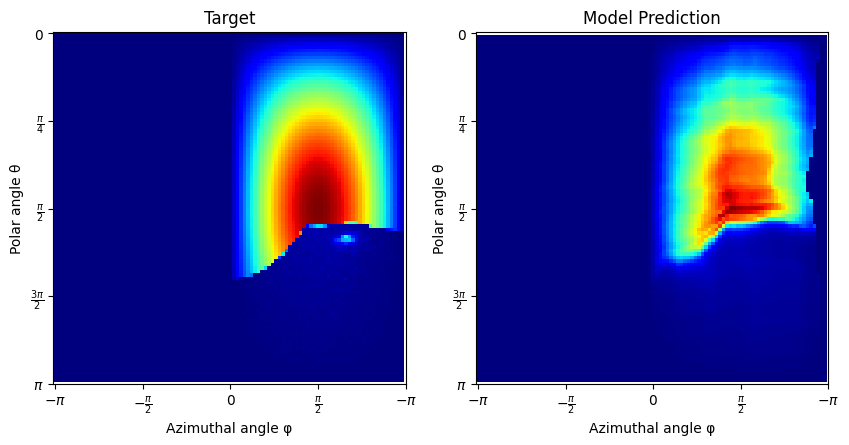

 80%|███████▉  | 39999/50000 [58:20<13:29, 12.35it/s]

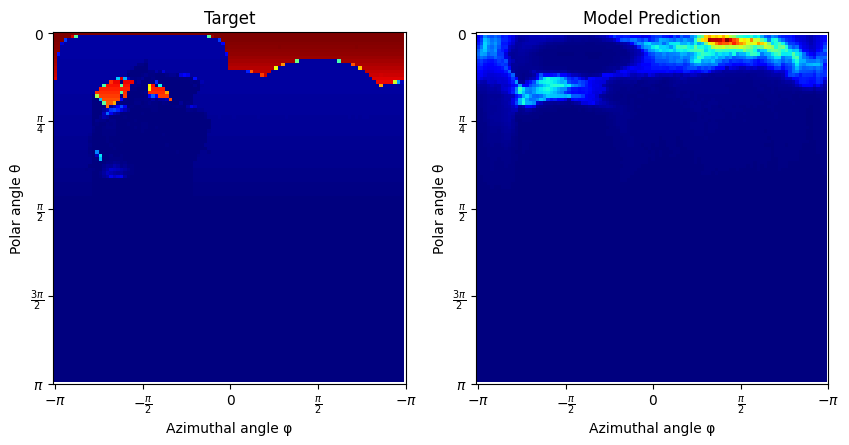

 90%|████████▉ | 44999/50000 [1:05:31<06:46, 12.30it/s]

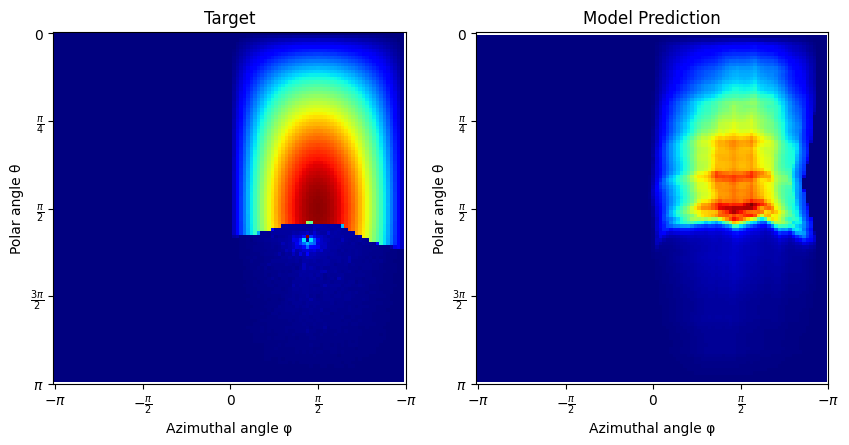

100%|██████████| 50000/50000 [1:12:34<00:00, 11.48it/s]


average generate_samples_time time 0.0382171799659729
average compute_gradient_time time 0.030906077451705934
average nan_check_clip_time time 0.000579876971244812
average optimizer_time time 9.288787841796875e-09


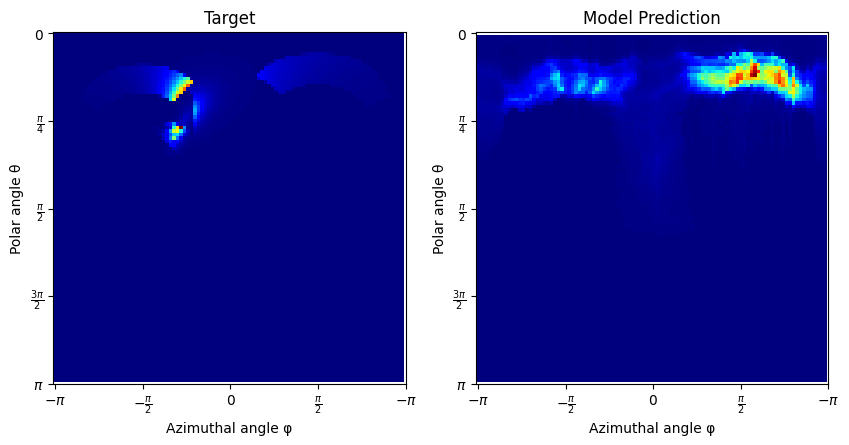

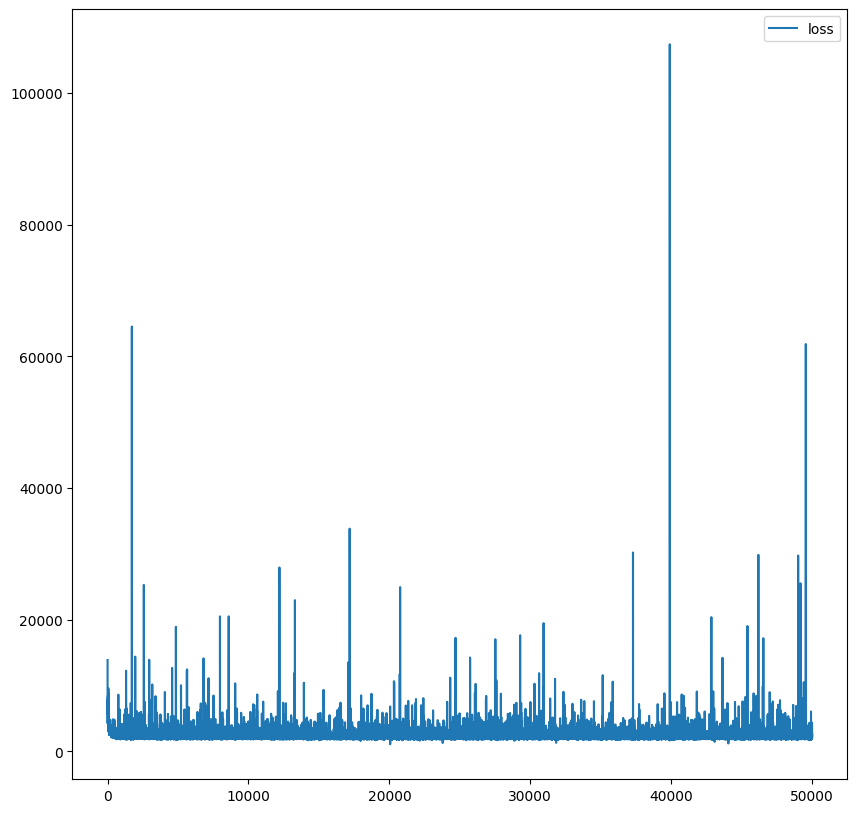

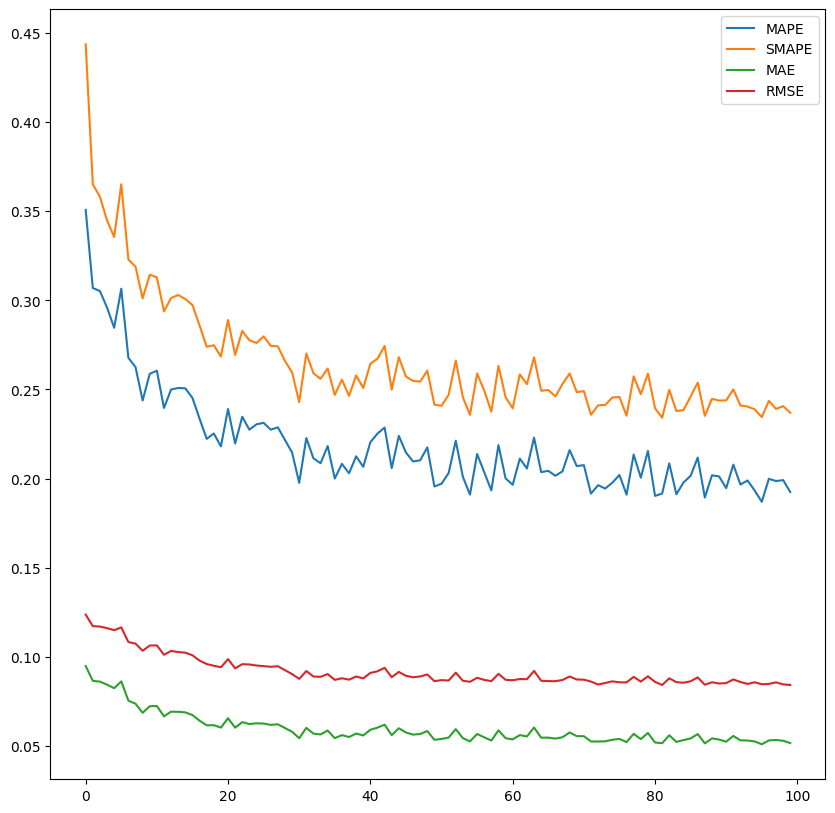

In [ ]:
### Spaceship full

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'spaceship',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid= True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = True,

    grid_resolutions=[4, 8, 12, 16],
    grid_levels=[2, 4, 6, 8],
    grid_scale_factors=[1.25, 1.5, 1.75, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=5, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 500
)

exp = run_experiment(setup, training_context, "spaceship_50k_full.pkl")
 
del(exp)

## Kitchen

loaded scene


d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda
created model
starting training


100%|██████████| 50000/50000 [4:18:28<00:00,  3.22it/s]  


average generate_samples_time time 0.17114083967208862
average compute_gradient_time time 0.043796436643600466
average nan_check_clip_time time 0.0005666400289535522
average optimizer_time time 8.697509765625e-09


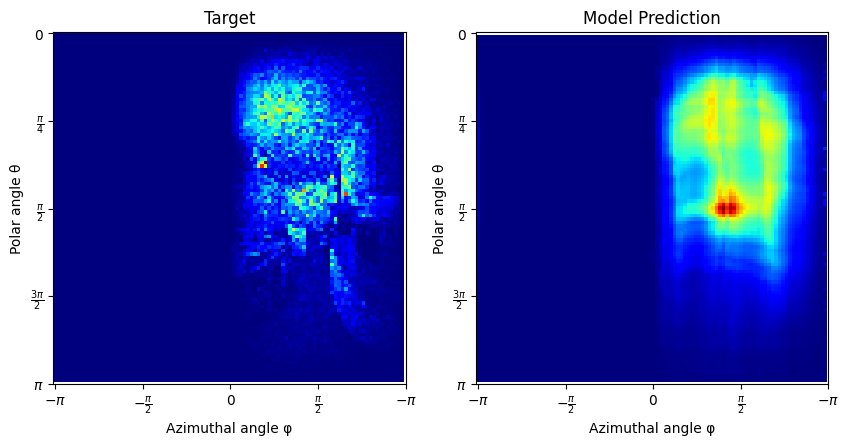

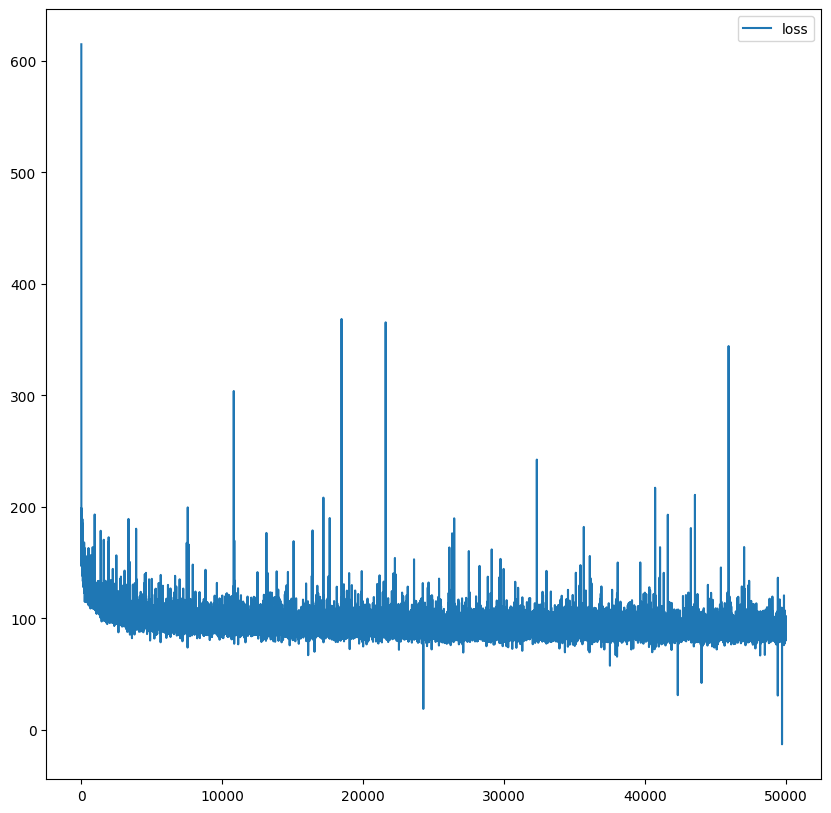

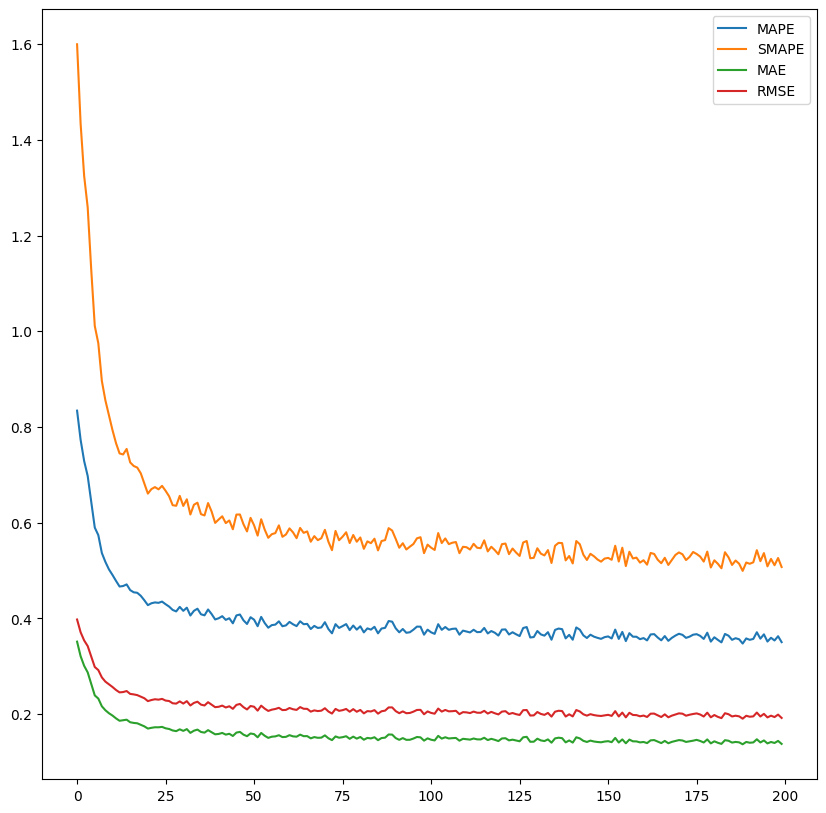

In [ ]:
### Kitchen Mueller

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='uniform',
    # prior_str='cosine',
    scene_name = 'kitchen',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4, 

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid= False,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "kitchen_50k_mueller.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:110: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
100%|██████████| 50000/50000 [4:07:28<00:00,  3.37it/s]  
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


average generate_samples_time time 0.1653504003095627
average compute_gradient_time time 0.043122042093276976
average nan_check_clip_time time 0.0005576651811599731
average optimizer_time time 1.1267662048339845e-08


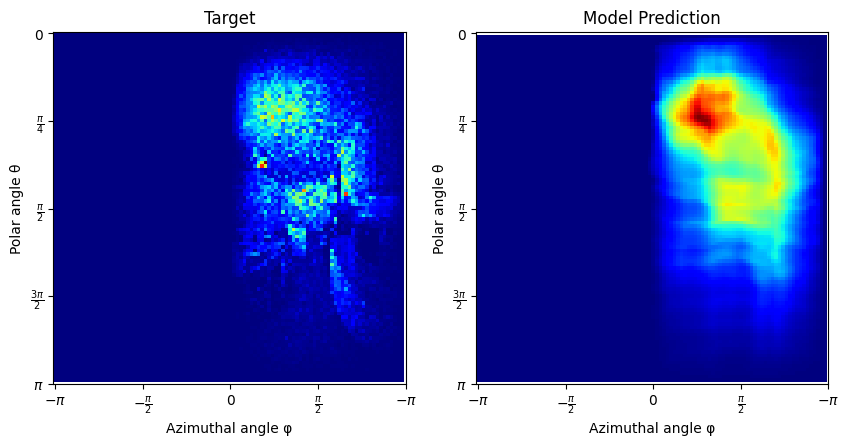

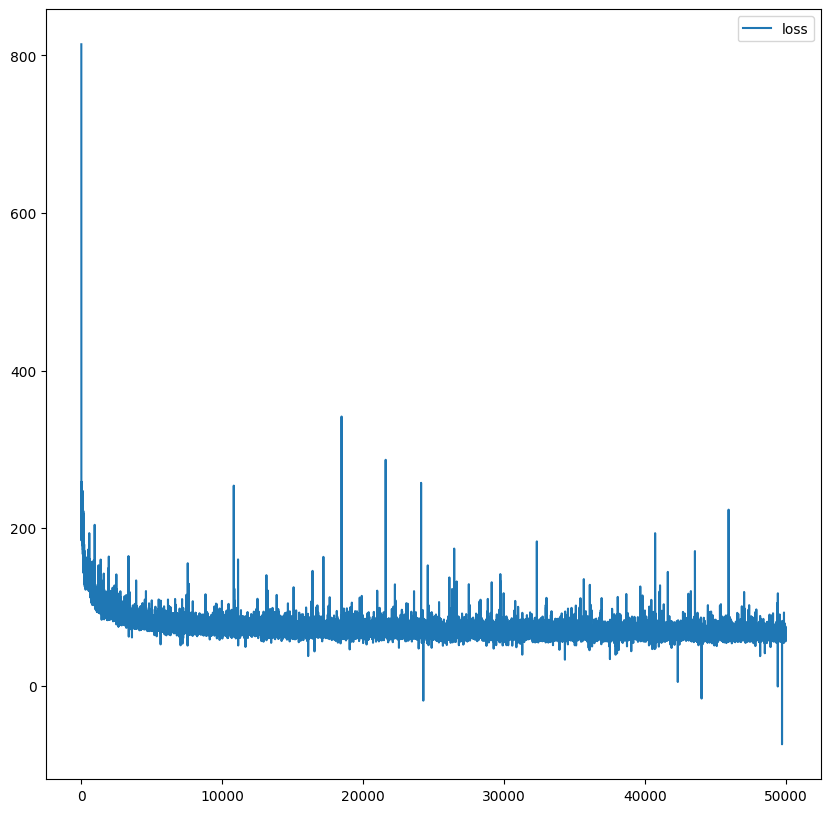

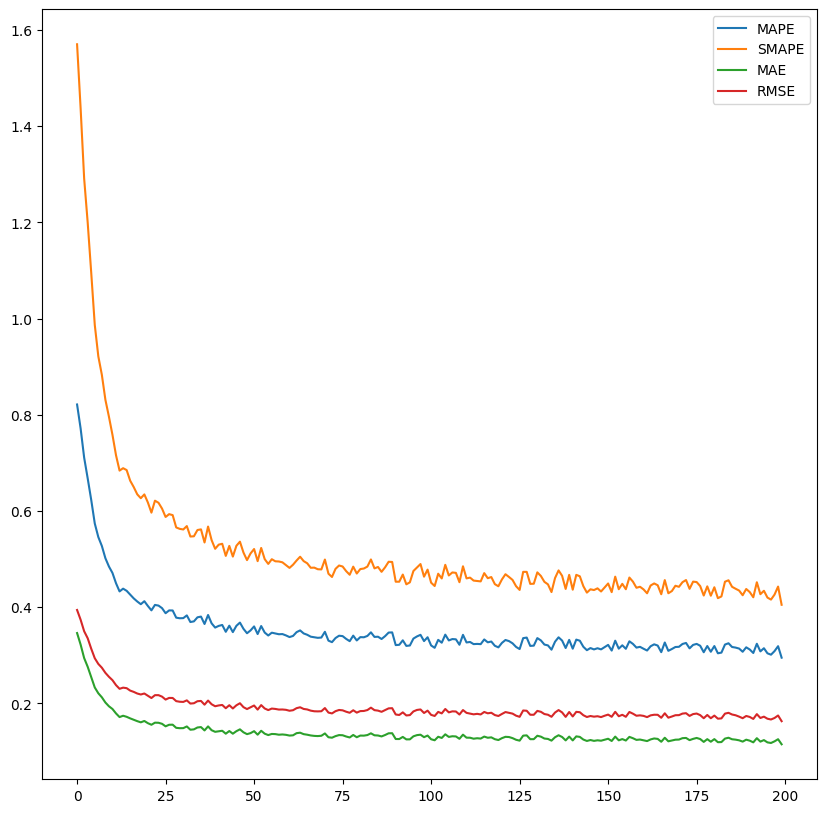

In [ ]:
### Kitchen One blob

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'kitchen',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4, 

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid= False,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "kitchen_50k_cosine_oneblob.pkl")
del(exp)

In [ ]:
### Kitchen Hash grid

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'kitchen',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4, 

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid= True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "kitchen_50k_cosine_hash_grid.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/30000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:110: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
  3%|▎         | 953/30000 [05:34<2:49:44,  2.85it/s]


KeyboardInterrupt: 

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]

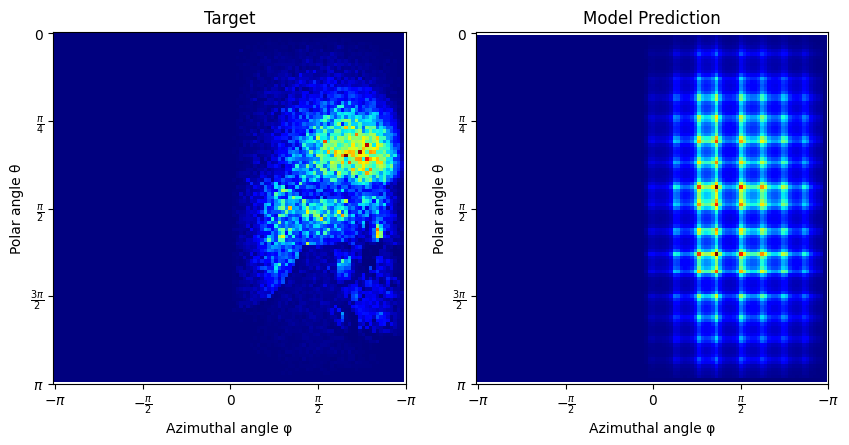

 10%|█         | 5000/50000 [31:23<4:03:22,  3.08it/s] 

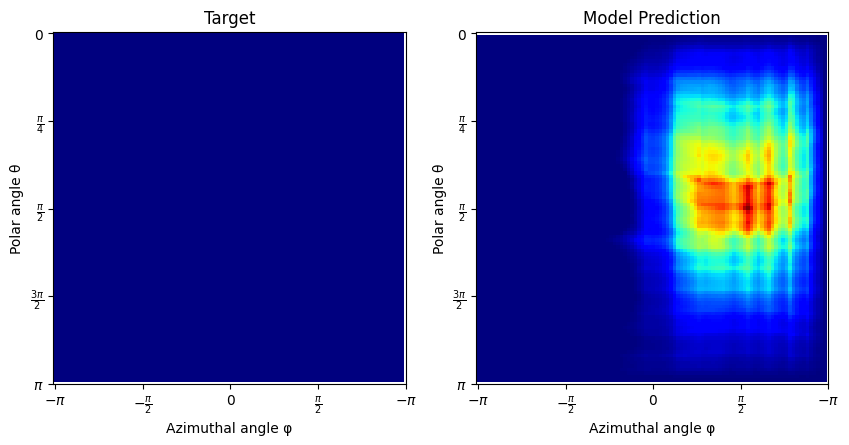

 20%|██        | 10000/50000 [1:03:30<3:37:09,  3.07it/s]

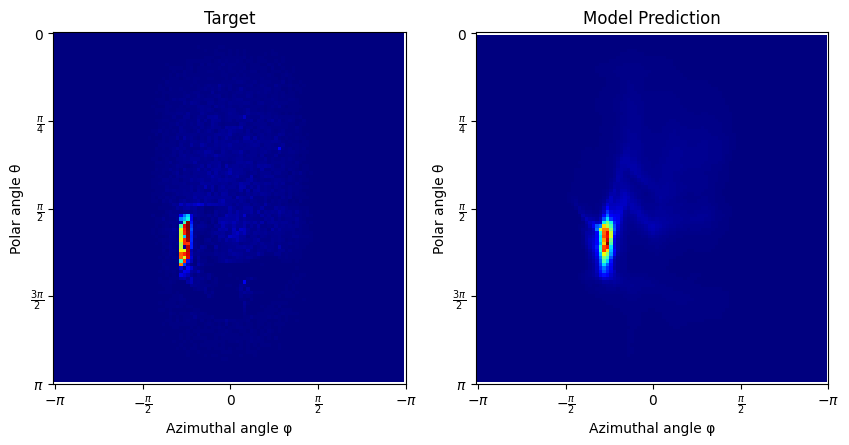

 30%|███       | 15000/50000 [1:35:32<3:09:04,  3.09it/s] 

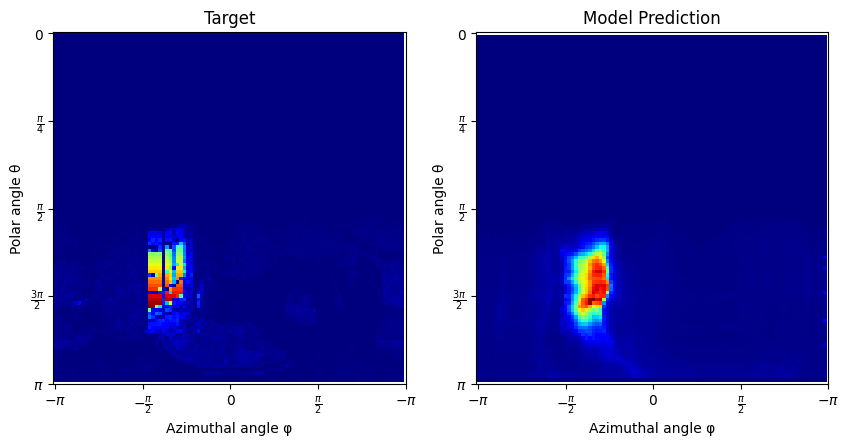

 40%|████      | 20000/50000 [2:07:34<2:41:55,  3.09it/s]

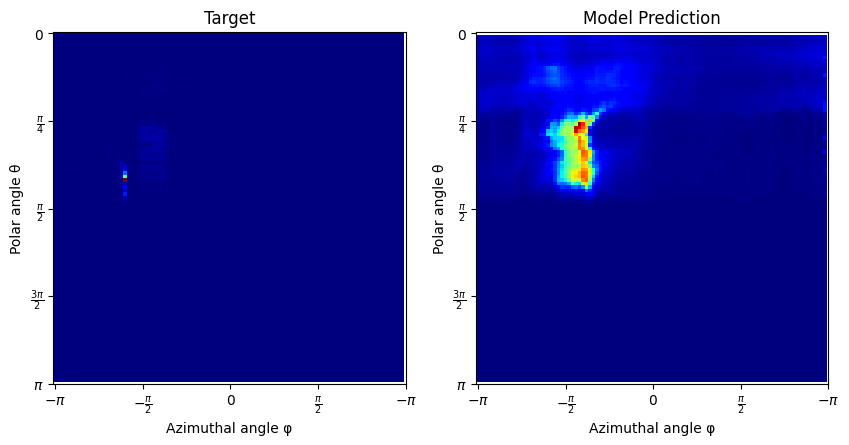

 50%|█████     | 25000/50000 [2:39:34<2:13:51,  3.11it/s]

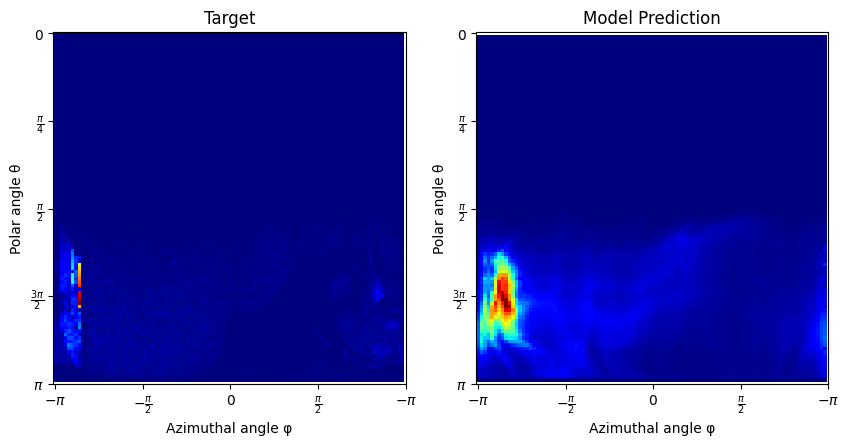

 60%|██████    | 30000/50000 [3:11:41<1:49:18,  3.05it/s]

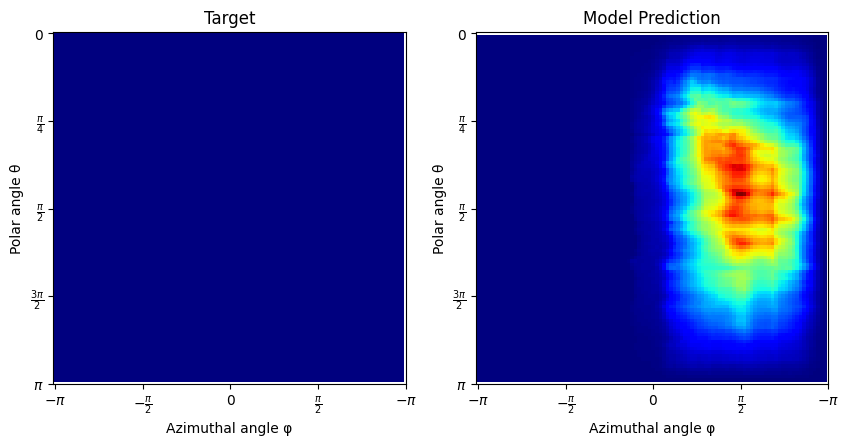

 70%|███████   | 35000/50000 [3:43:45<1:20:31,  3.10it/s]

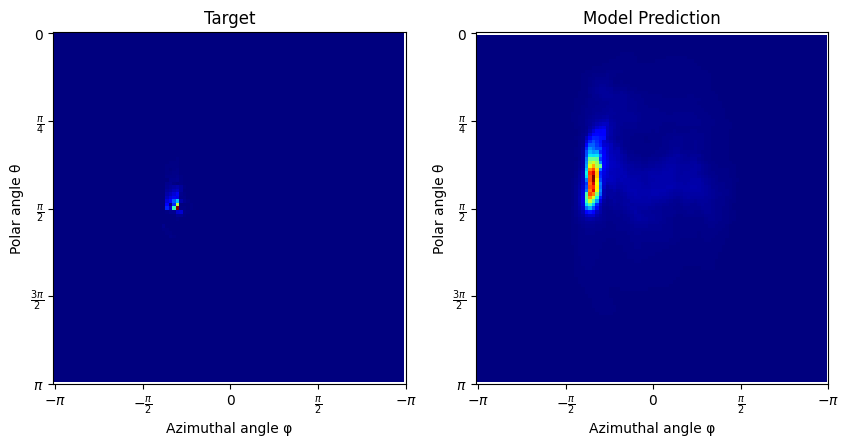

 80%|████████  | 40000/50000 [4:16:12<54:46,  3.04it/s]  

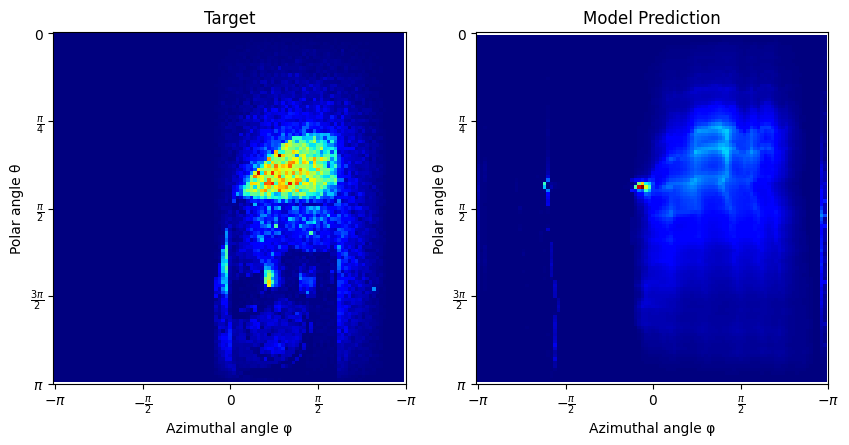

 90%|█████████ | 45000/50000 [4:48:56<30:02,  2.77it/s]  

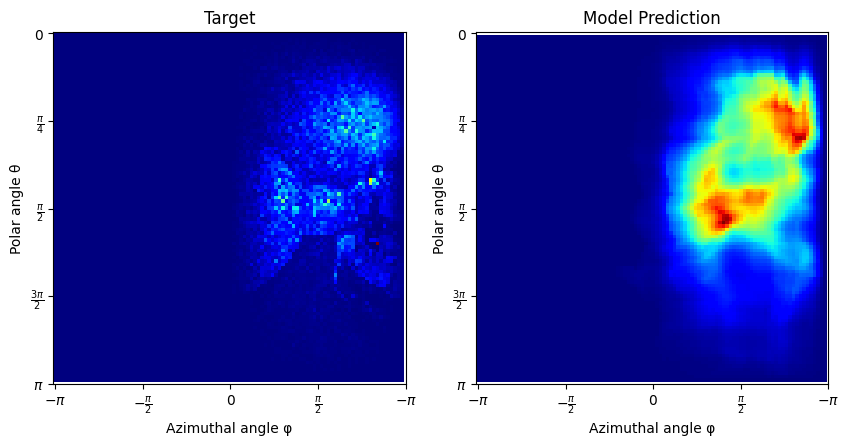

100%|██████████| 50000/50000 [5:22:34<00:00,  2.58it/s]  


average generate_samples_time time 0.2081473431634903
average compute_gradient_time time 0.04702855658531189
average nan_check_clip_time time 0.0005383659076690674
average optimizer_time time 1.090526580810547e-08


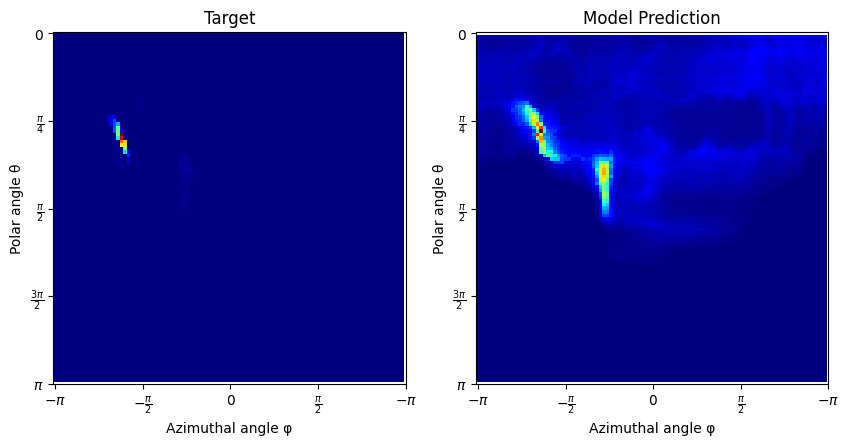

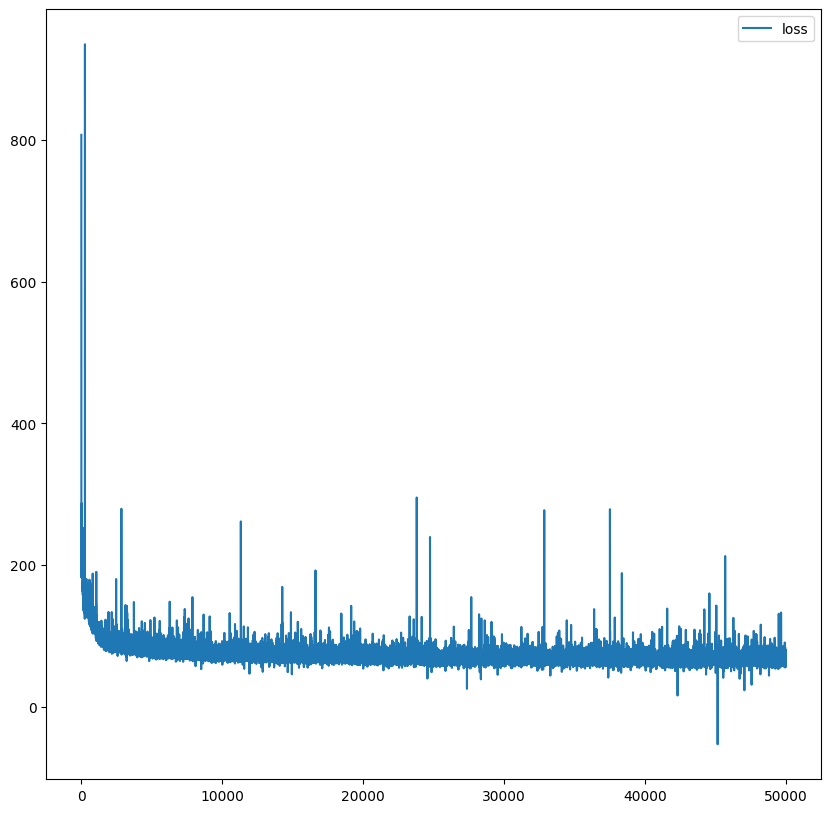

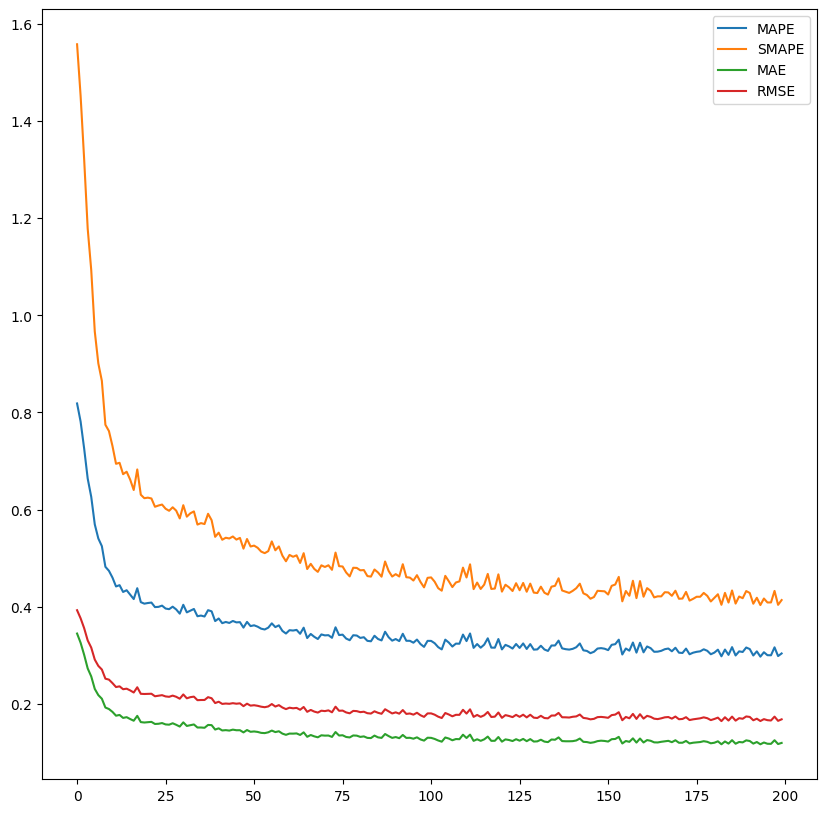

In [ ]:
### Kitchen full

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'kitchen',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4, 

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid= True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = True,

    grid_resolutions=[4, 8, 12, 16],
    grid_levels=[2, 4, 6, 8],
    grid_scale_factors=[1.25, 1.5, 1.75, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "kitchen_50k_full.pkl")
del(exp)

In [ ]:
### Kitchen test samples

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'kitchen',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 1e-3, 

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid= True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 16
width = 128
height = 128

training_context = Context(
    iterations = 30000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "kitchen_50k_cosine_hash_grid_high_lr_exp18.pkl")
del(exp)

## Veach Ajar

loaded scene


d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda
created model
starting training


100%|██████████| 50000/50000 [1:23:06<00:00, 10.03it/s]


average generate_samples_time time 0.02581465106487274
average compute_gradient_time time 0.029129239044189452
average nan_check_clip_time time 0.0005300096130371094
average optimizer_time time 8.563995361328125e-09


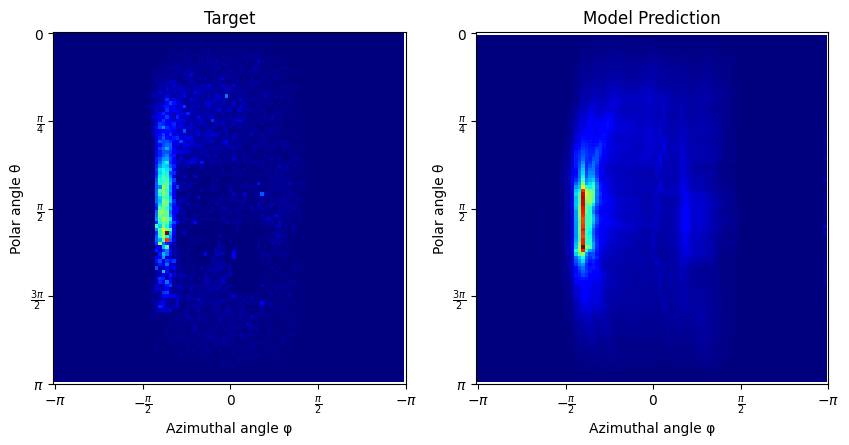

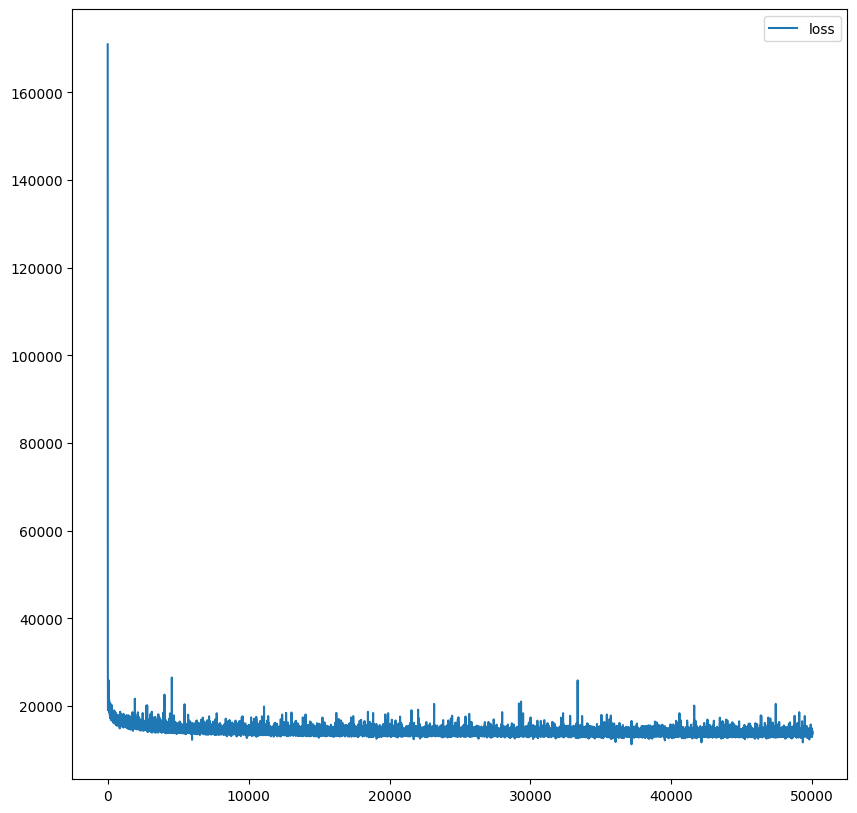

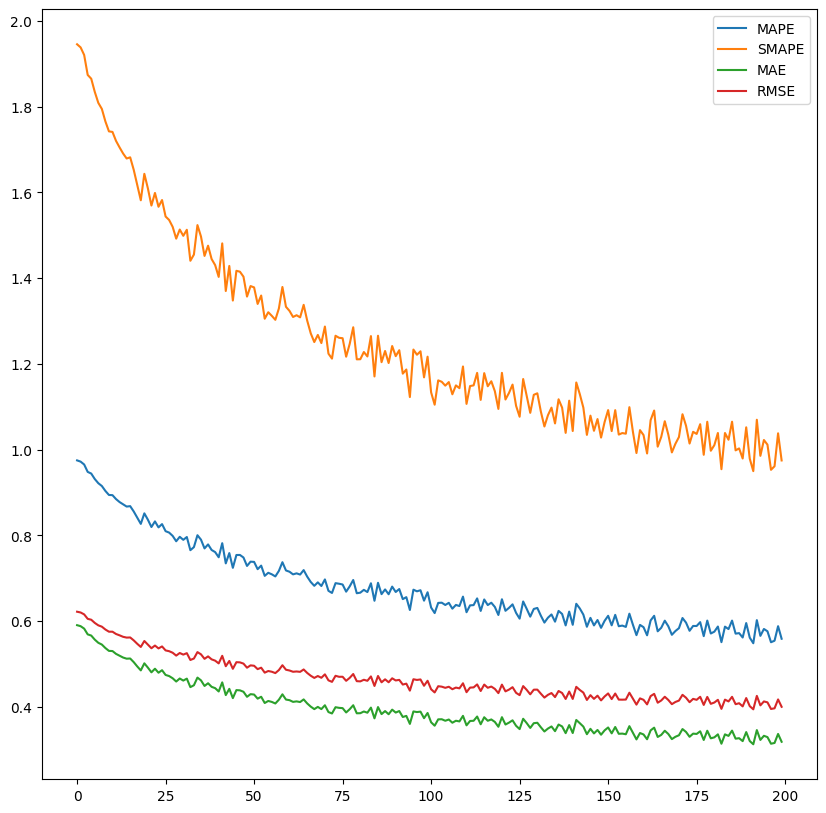

In [ ]:
### Veach Ajar Mueller

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='uniform',
    # prior_str='cosine',
    scene_name = 'veach_ajar',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4, 

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid= True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "veach_ajar_50k_mueller.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:110: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


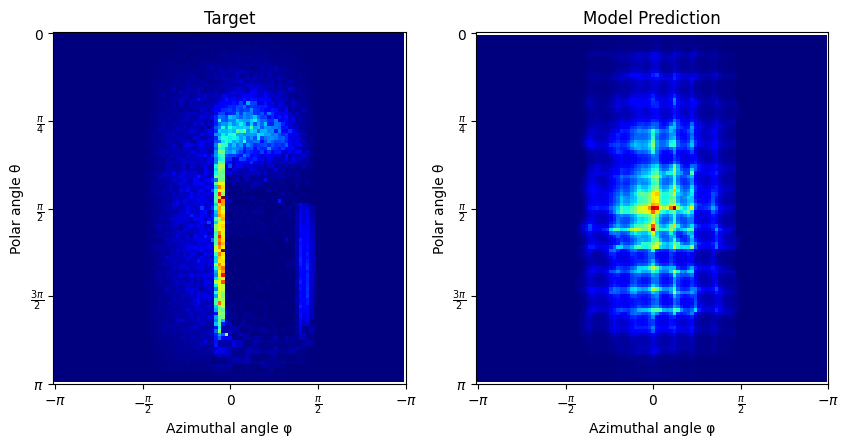

 10%|█         | 5000/50000 [08:03<1:03:35, 11.79it/s]

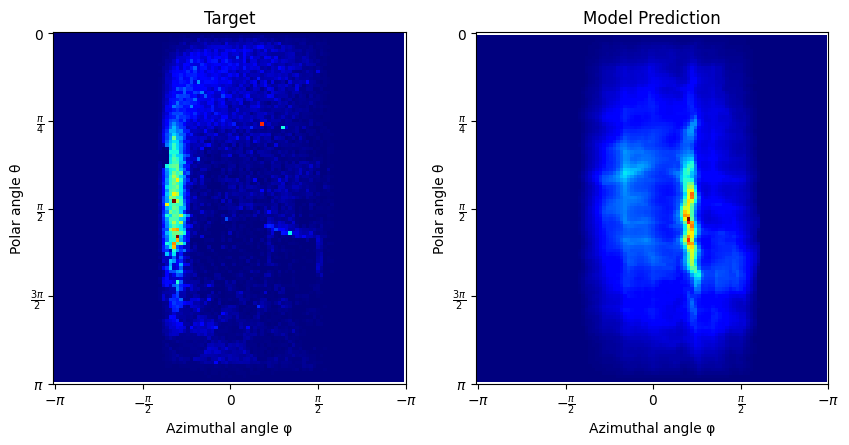

 20%|█▉        | 9999/50000 [16:12<59:18, 11.24it/s]  

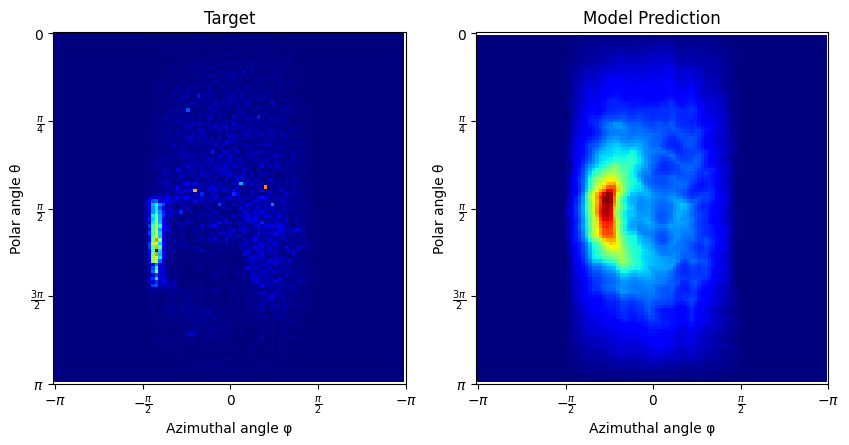

 30%|██▉       | 14999/50000 [24:21<49:20, 11.82it/s]  

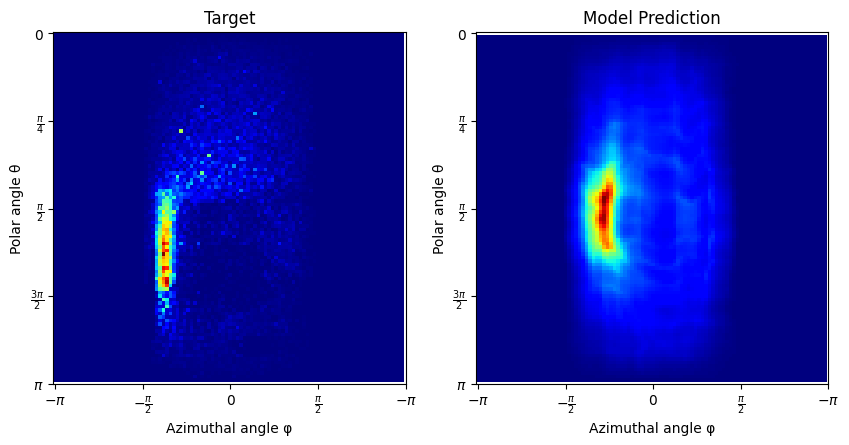

 40%|███▉      | 19999/50000 [33:00<46:40, 10.71it/s]  

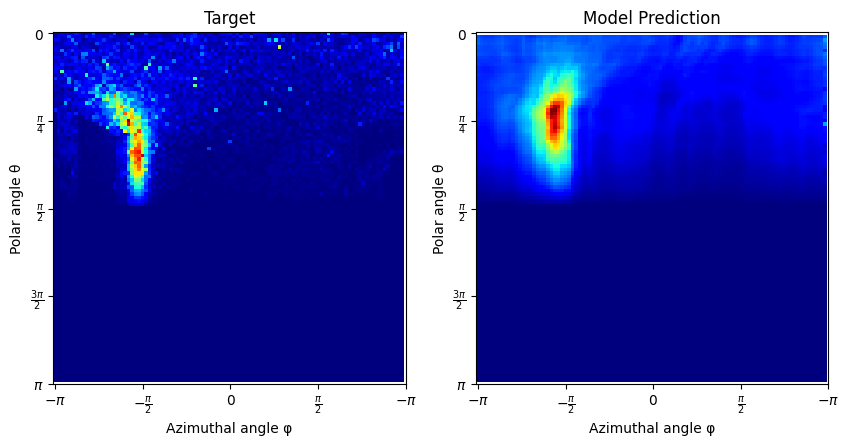

 50%|████▉     | 24999/50000 [41:47<38:40, 10.77it/s]  

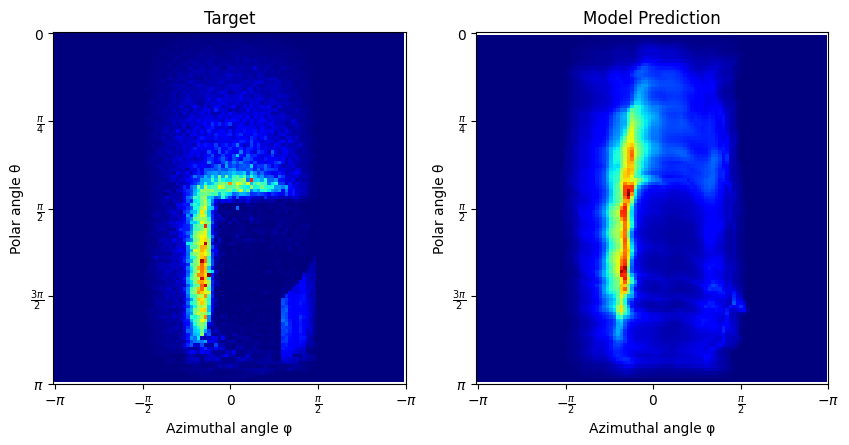

 60%|█████▉    | 29999/50000 [50:23<29:54, 11.15it/s]

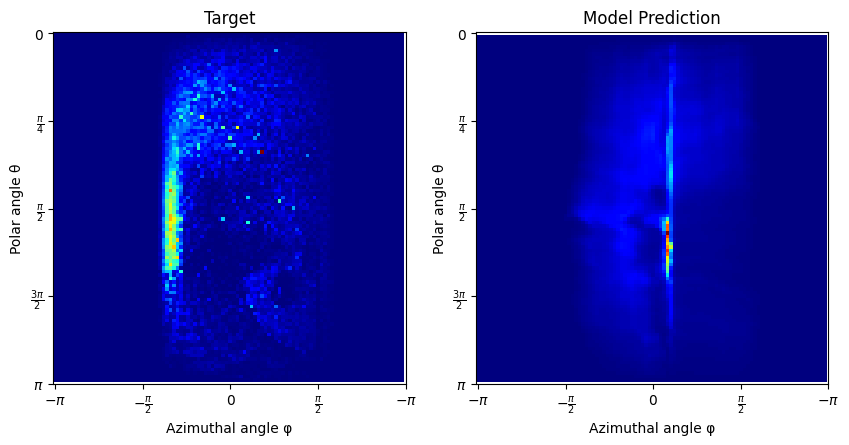

 70%|██████▉   | 34999/50000 [58:37<22:35, 11.07it/s]

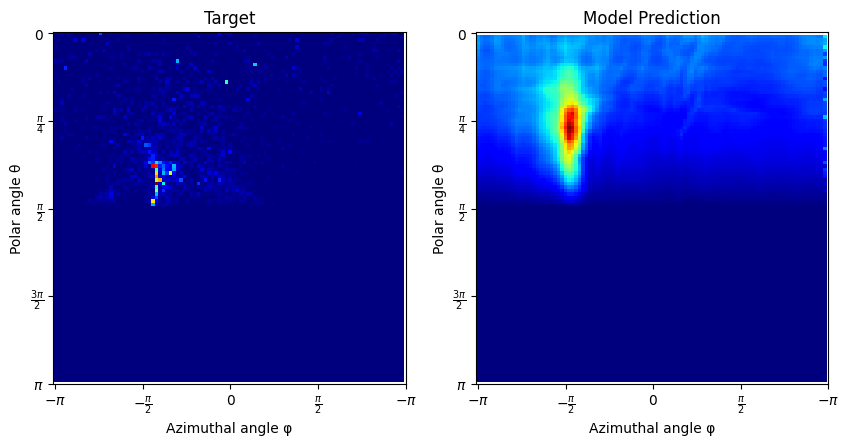

 80%|███████▉  | 39999/50000 [1:07:06<15:11, 10.97it/s]

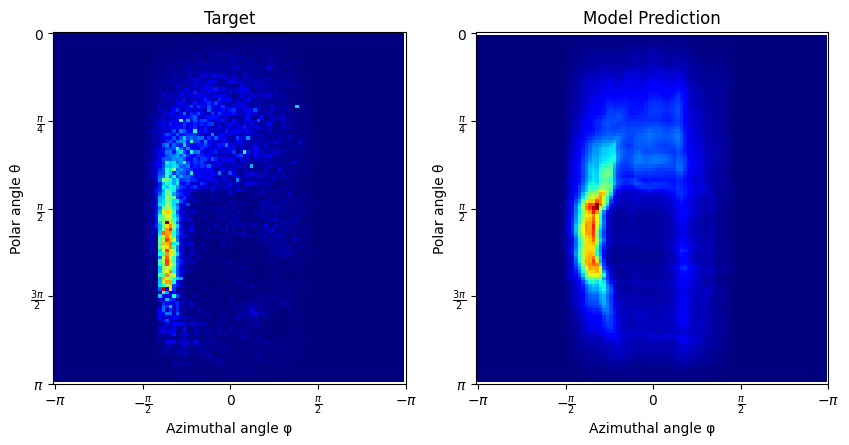

 90%|████████▉ | 44999/50000 [1:15:59<08:09, 10.22it/s]

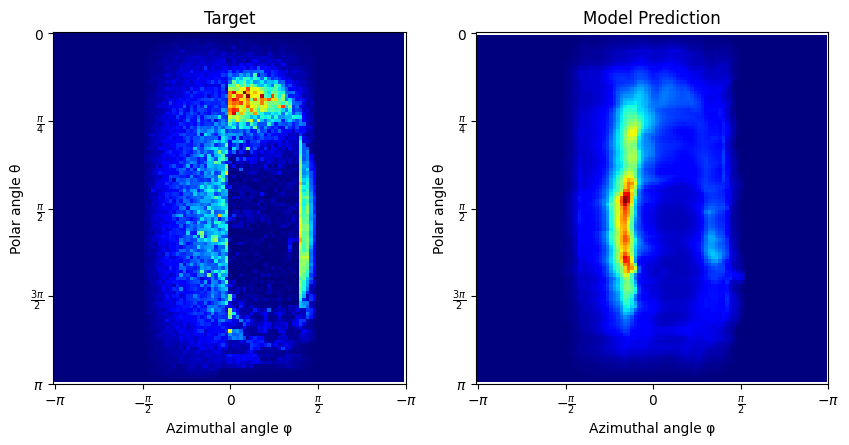

100%|██████████| 50000/50000 [1:24:49<00:00,  9.82it/s]


average generate_samples_time time 0.02054710210800171
average compute_gradient_time time 0.03234618996620178
average nan_check_clip_time time 0.000603539481163025
average optimizer_time time 8.65936279296875e-09


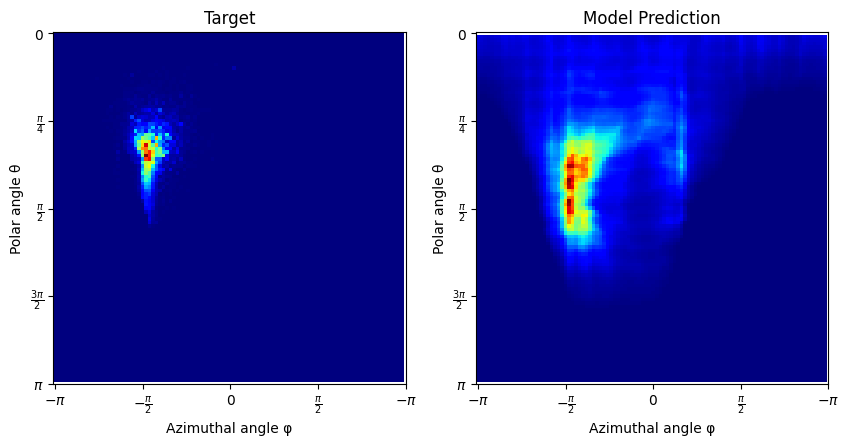

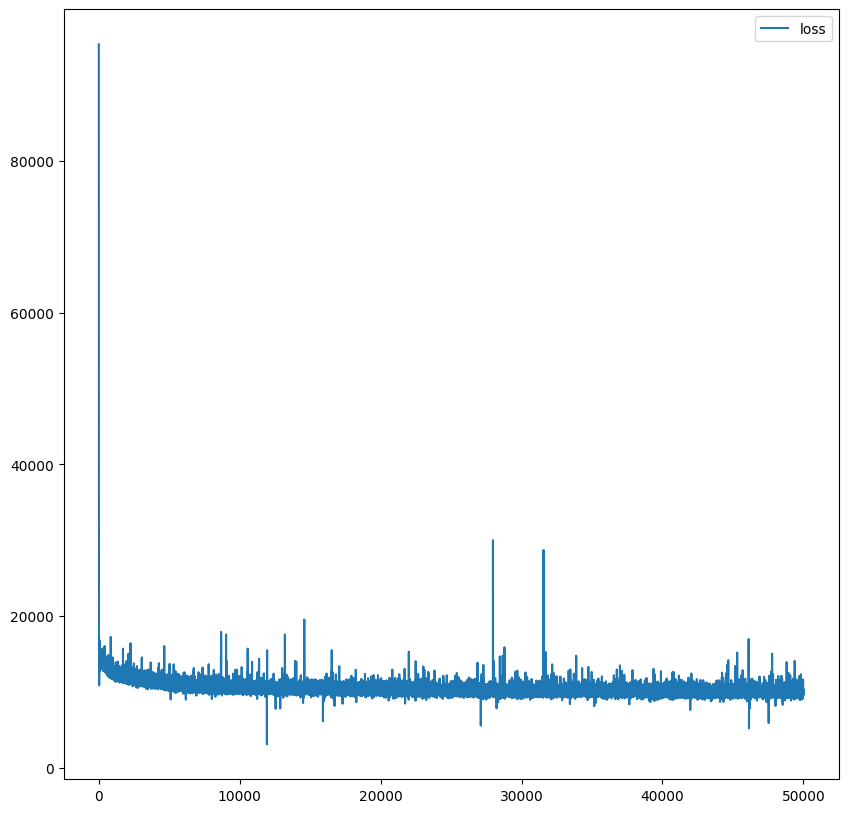

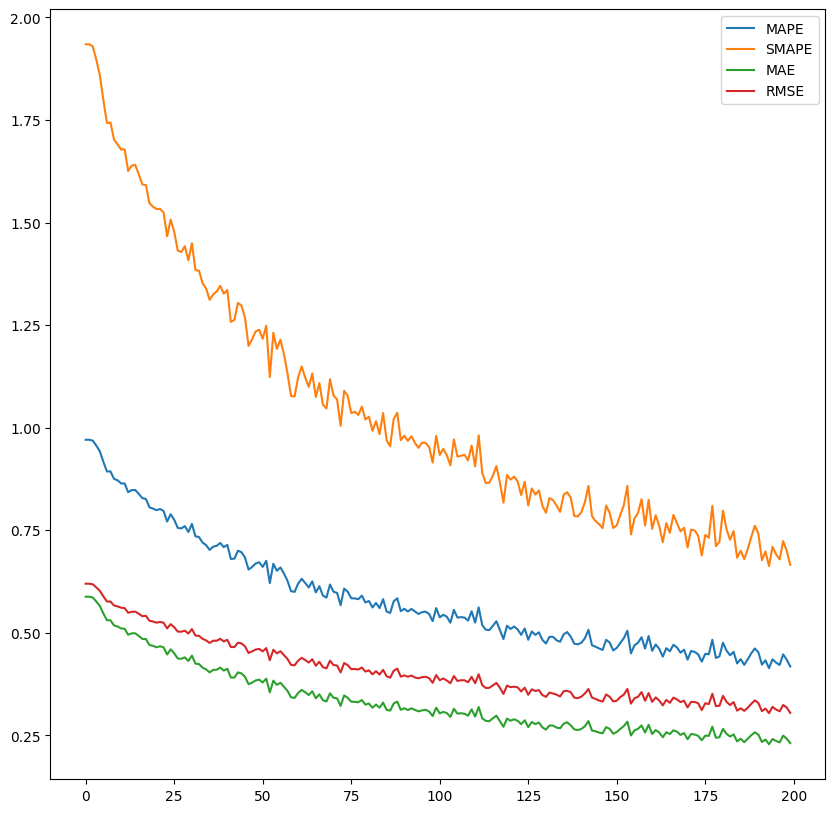

In [ ]:
### Veach Ajar hash grid

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'veach_ajar',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4, 

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid= True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "veach_ajar_50k_cosine_hash_grid.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]

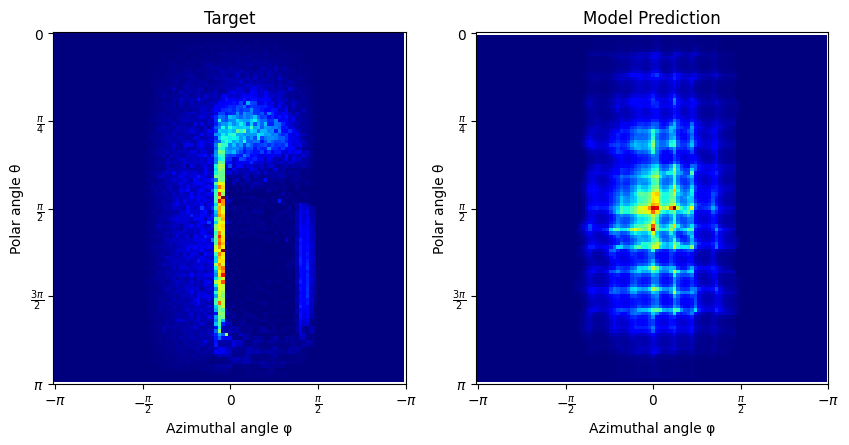

 10%|▉         | 4999/50000 [09:24<1:17:13,  9.71it/s]

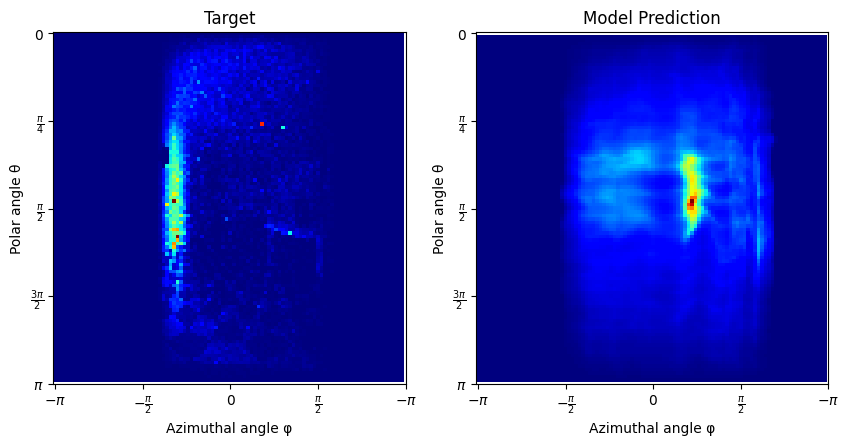

 20%|█▉        | 9999/50000 [19:06<1:09:11,  9.63it/s]

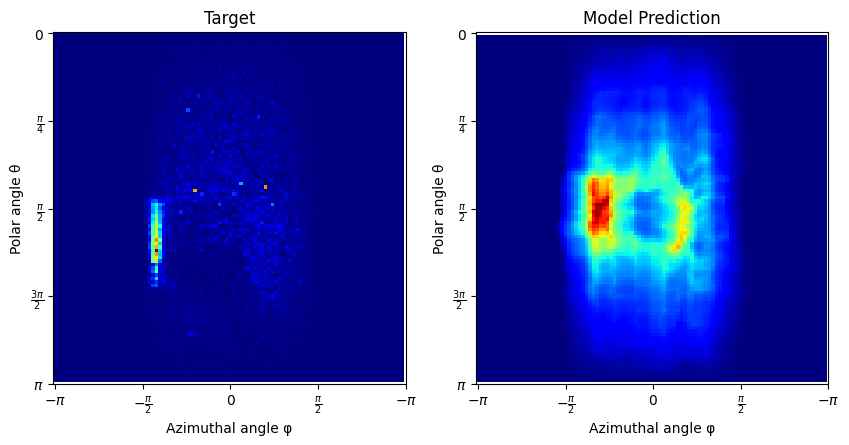

 30%|██▉       | 14999/50000 [28:48<1:00:29,  9.64it/s]

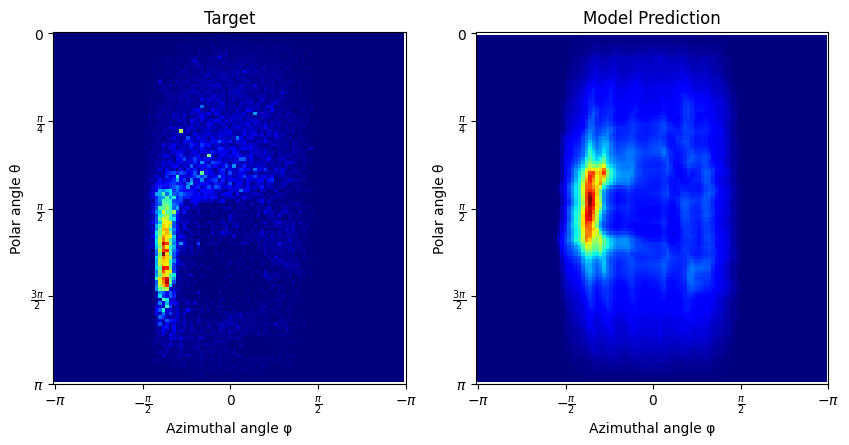

 40%|███▉      | 19999/50000 [38:41<52:13,  9.57it/s]  

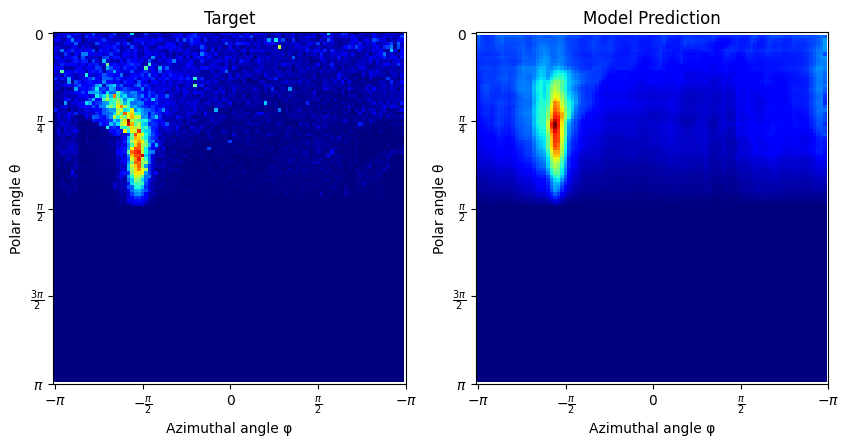

 50%|████▉     | 24999/50000 [48:14<43:16,  9.63it/s]  

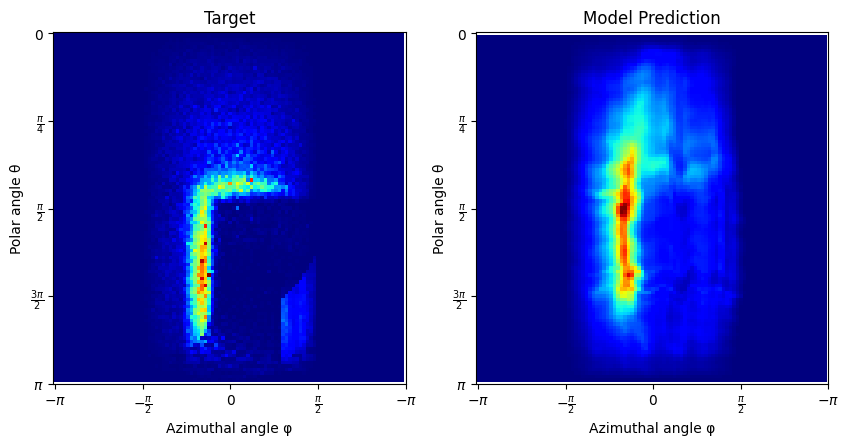

 60%|█████▉    | 29999/50000 [57:59<34:42,  9.60it/s]  

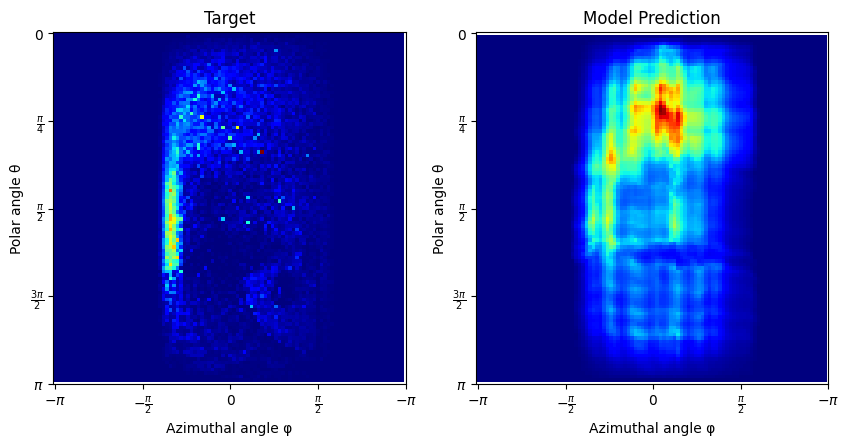

 70%|██████▉   | 34999/50000 [1:07:45<26:08,  9.57it/s]

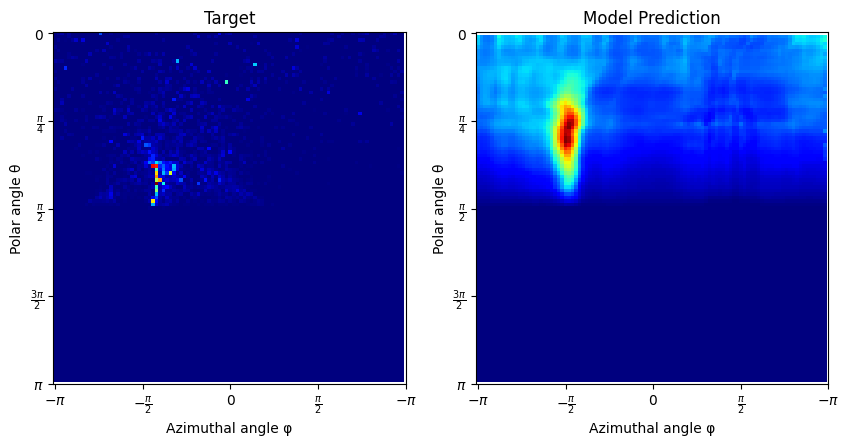

 80%|███████▉  | 39999/50000 [1:17:43<17:25,  9.57it/s]

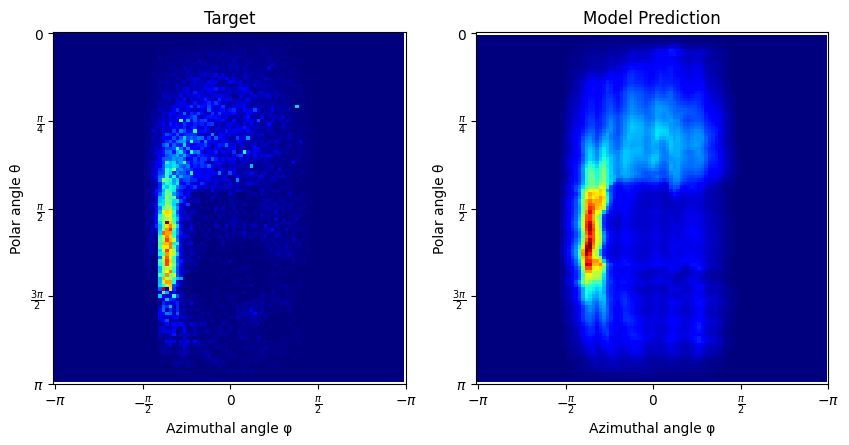

 90%|████████▉ | 44999/50000 [1:27:18<08:48,  9.47it/s]

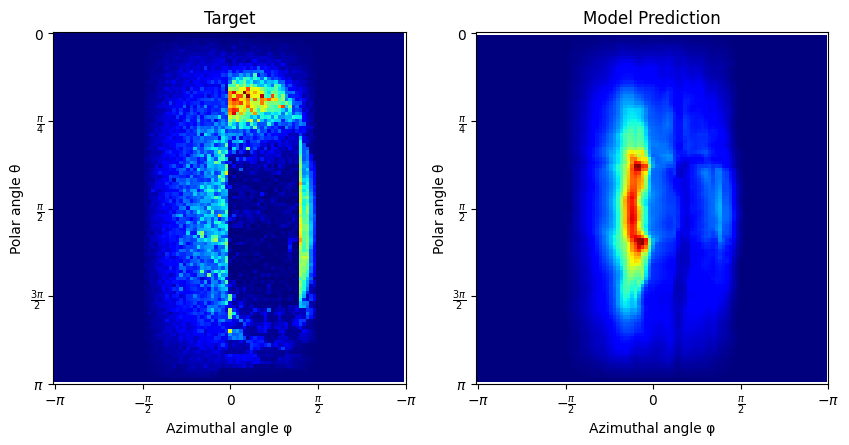

100%|██████████| 50000/50000 [1:37:08<00:00,  8.58it/s]


average generate_samples_time time 0.027850170636177063
average compute_gradient_time time 0.03431053874969482
average nan_check_clip_time time 0.0006460621500015258
average optimizer_time time 9.365081787109376e-09


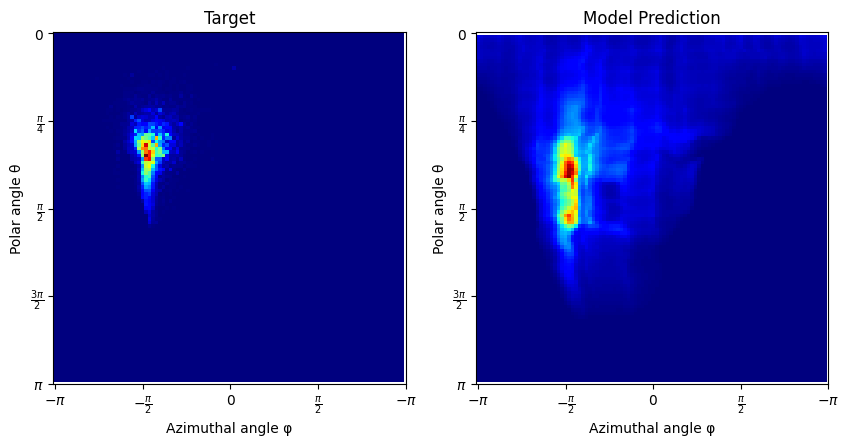

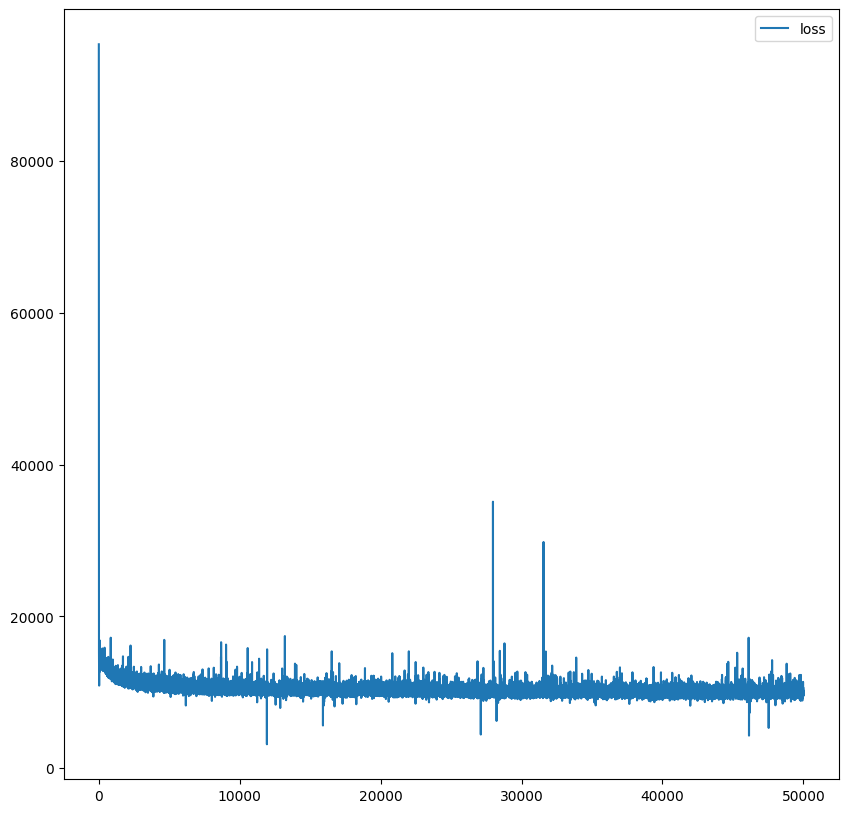

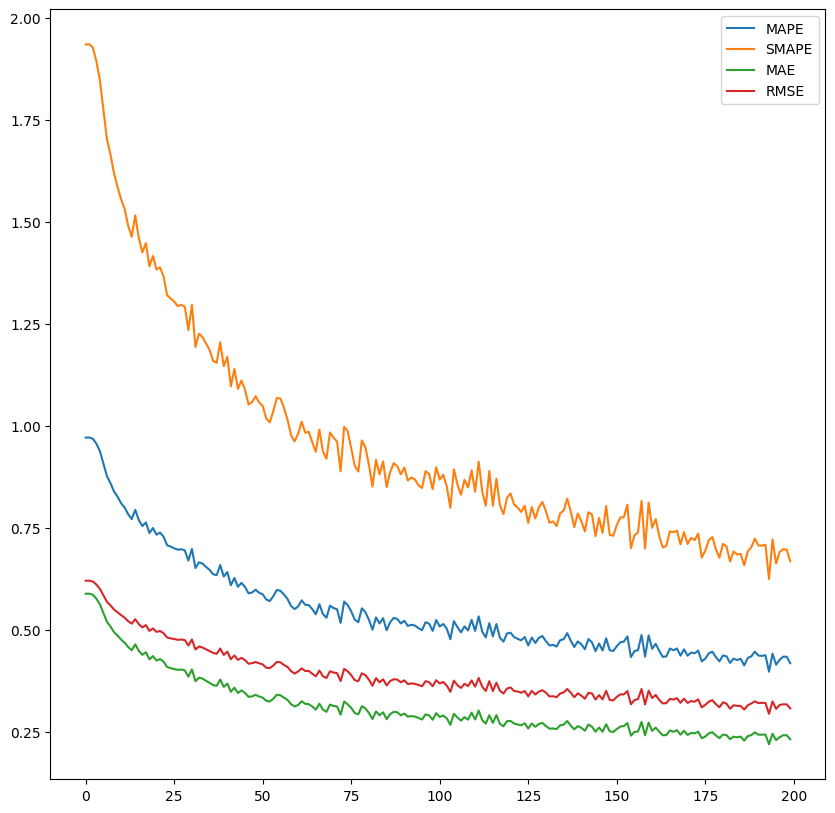

In [ ]:
### Veach Ajar mult grid

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'veach_ajar',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4, 

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid= True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "veach_ajar_50k_cosine_hash_grid_multiple.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]

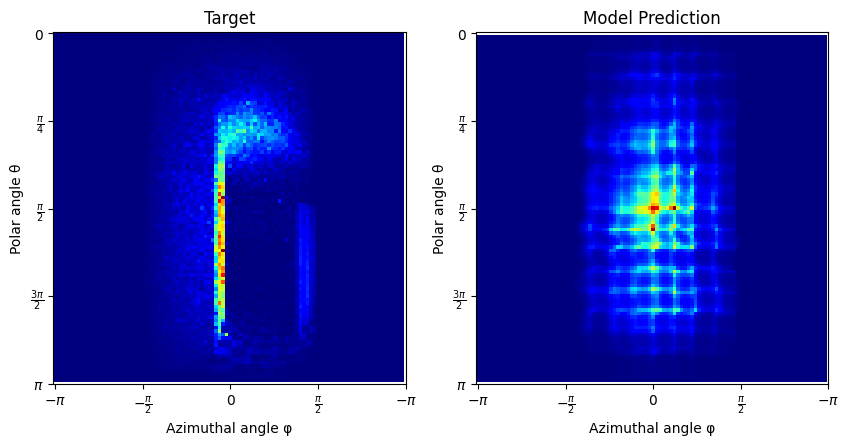

 10%|▉         | 4999/50000 [12:34<1:38:02,  7.65it/s]

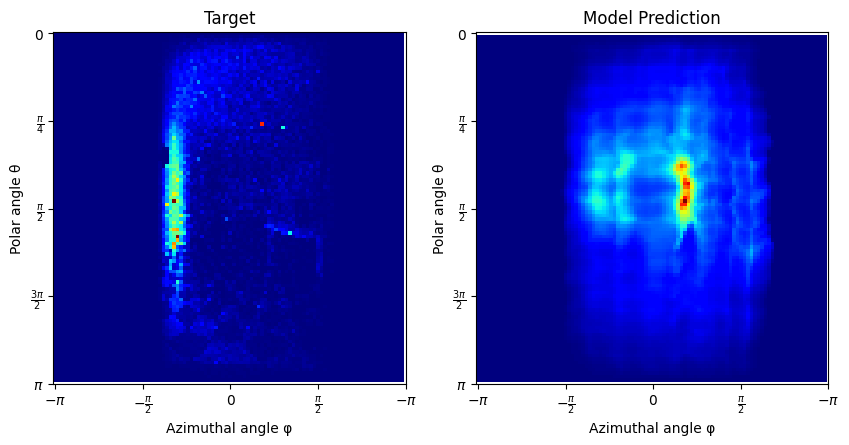

 20%|██        | 10000/50000 [24:52<1:27:42,  7.60it/s]

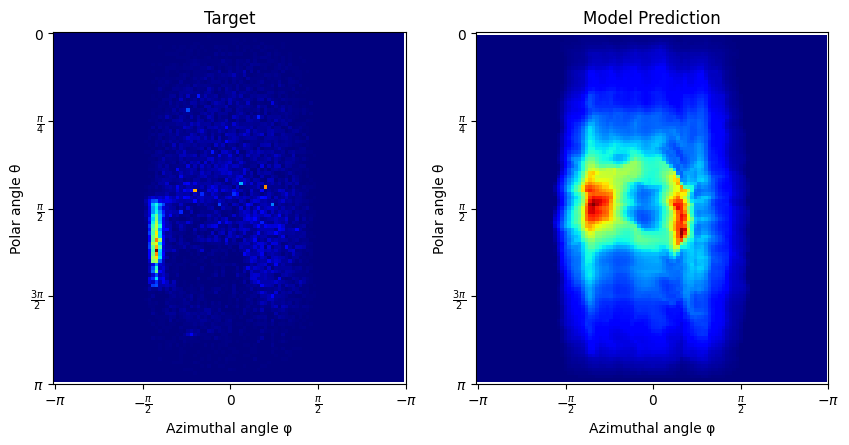

 30%|██▉       | 14999/50000 [37:35<1:16:16,  7.65it/s]

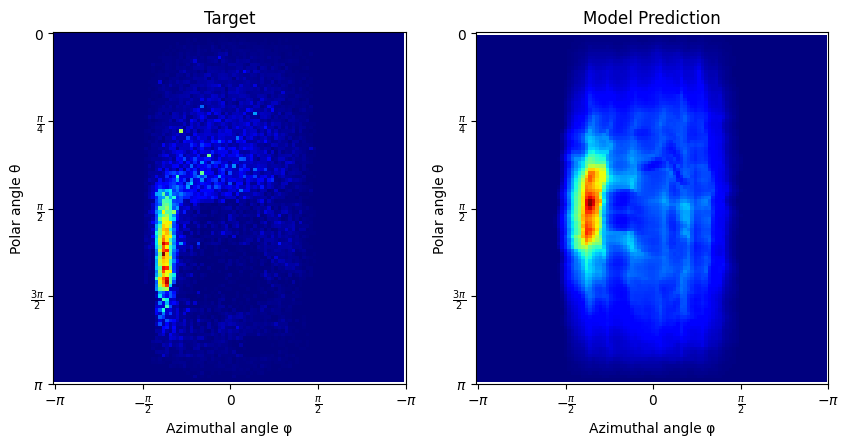

 40%|███▉      | 19999/50000 [46:18<45:44, 10.93it/s]  

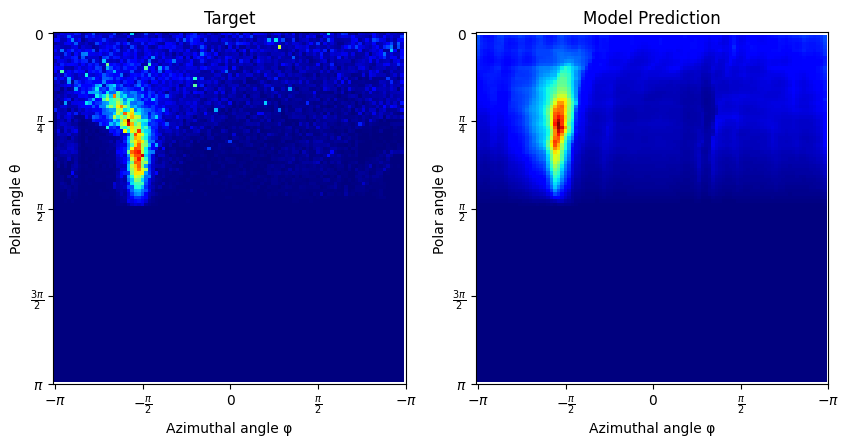

 50%|████▉     | 24999/50000 [55:05<38:07, 10.93it/s]  

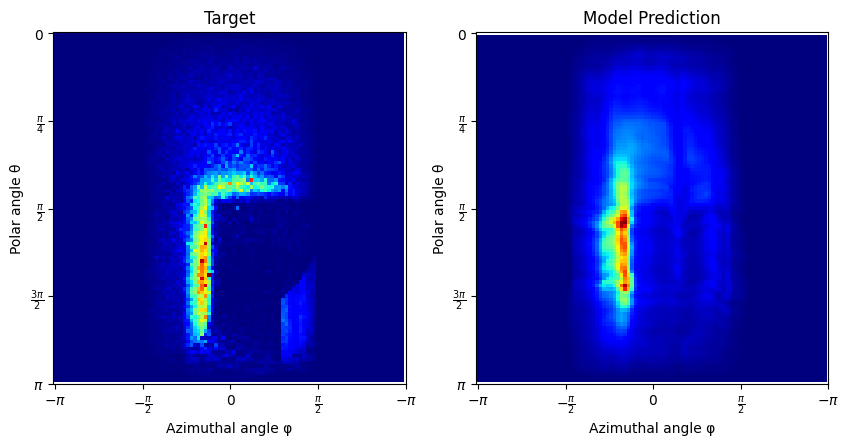

 60%|█████▉    | 29999/50000 [1:03:27<30:28, 10.94it/s]

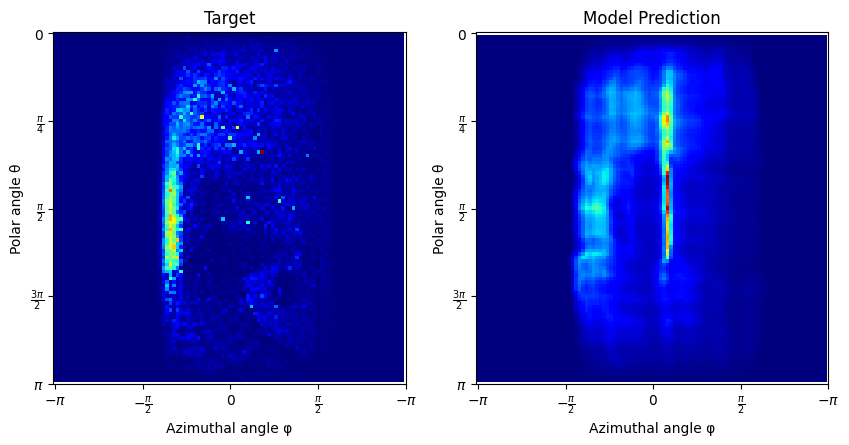

 70%|██████▉   | 34999/50000 [1:12:16<22:52, 10.93it/s]

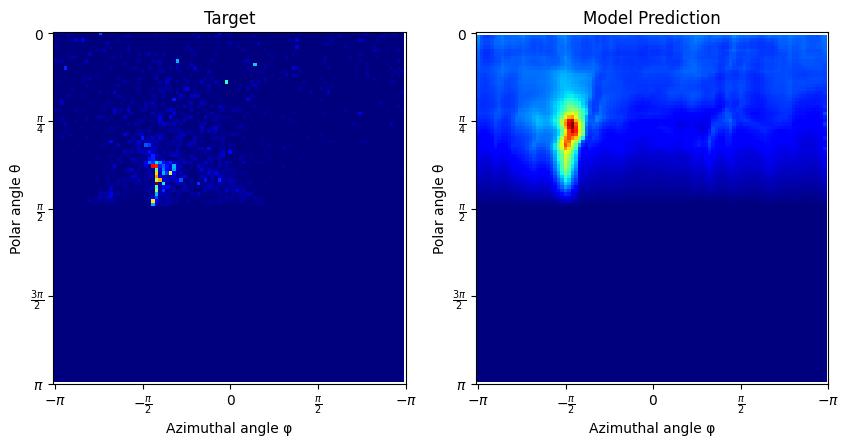

 80%|███████▉  | 39999/50000 [1:20:56<15:23, 10.83it/s]

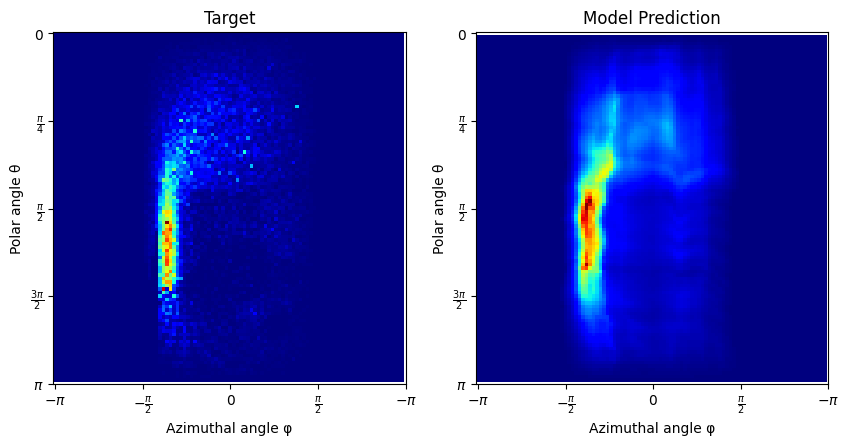

 90%|████████▉ | 44999/50000 [1:29:36<07:43, 10.78it/s]

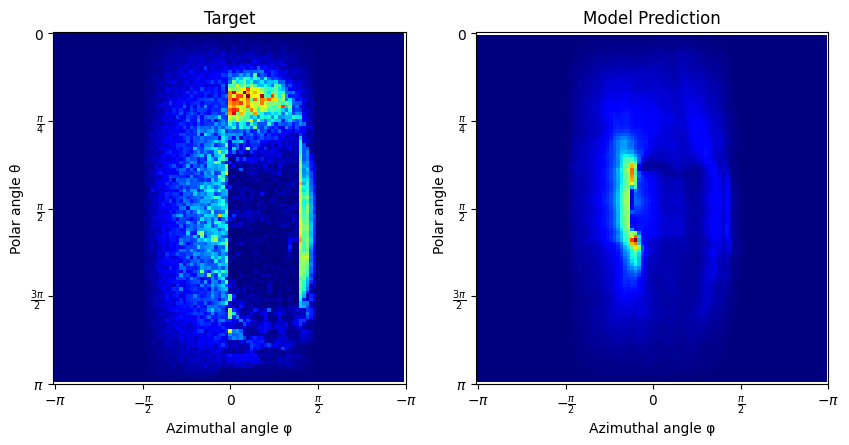

100%|██████████| 50000/50000 [1:38:08<00:00,  8.49it/s]


average generate_samples_time time 0.035331851401329044
average compute_gradient_time time 0.031203059492111208
average nan_check_clip_time time 0.0005203269624710083
average optimizer_time time 8.62598419189453e-09


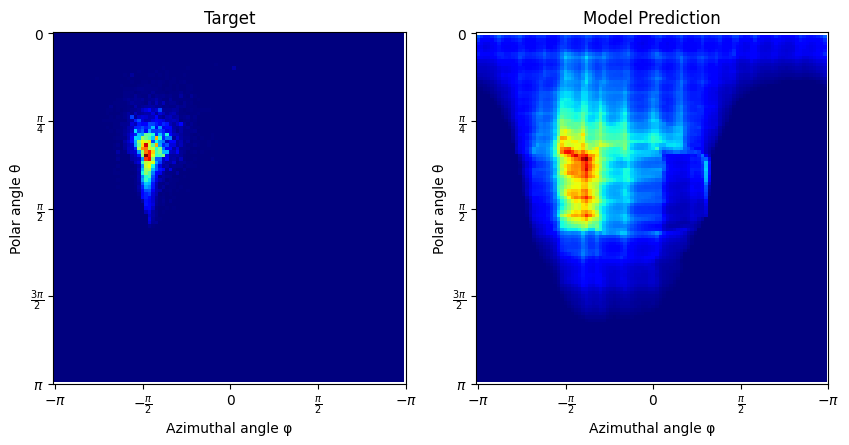

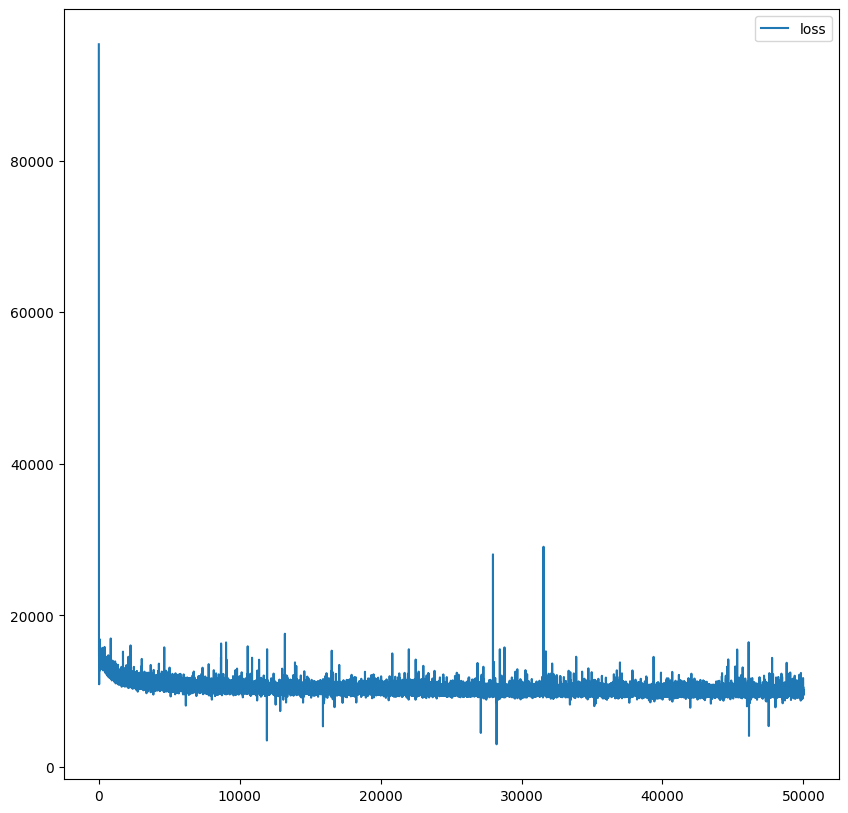

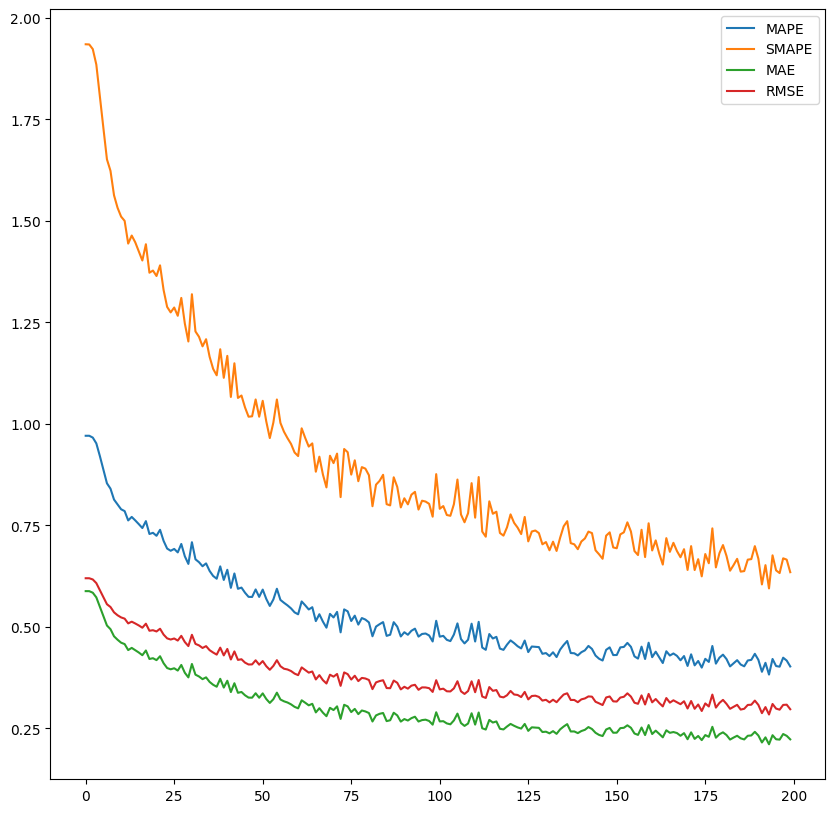

In [ ]:
### Veach Ajar slight stagger

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'veach_ajar',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4, 

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = True,

    grid_resolutions=[10, 12, 14, 16],
    grid_levels=[5, 6, 7, 8],
    grid_scale_factors=[1.4, 1.6, 1.8, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "veach_ajar_50k_cosine_hash_grid_multiple_stagger_slight.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]

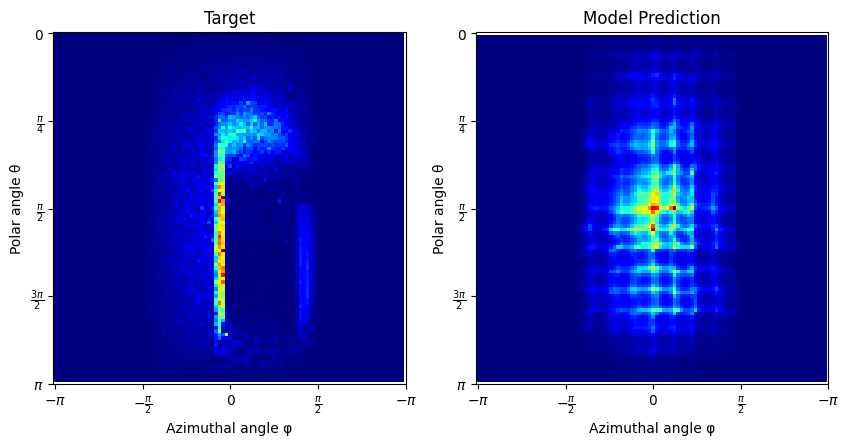

 10%|▉         | 4999/50000 [11:22<1:28:12,  8.50it/s]

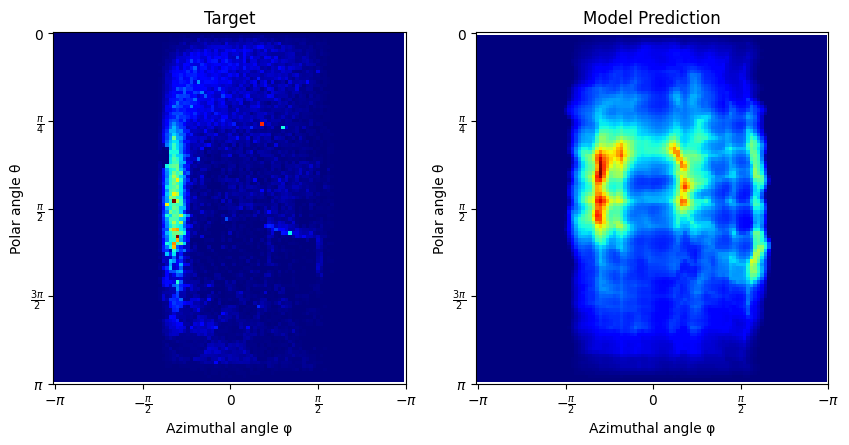

 20%|█▉        | 9999/50000 [22:32<1:18:07,  8.53it/s]

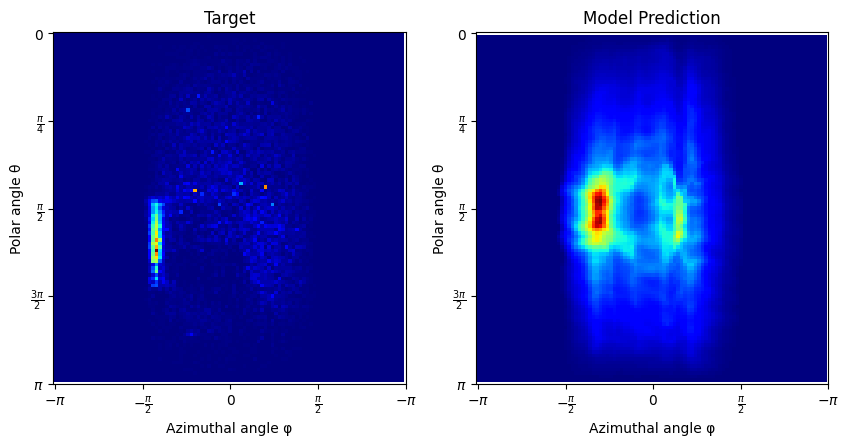

 30%|██▉       | 14999/50000 [33:32<1:08:14,  8.55it/s]

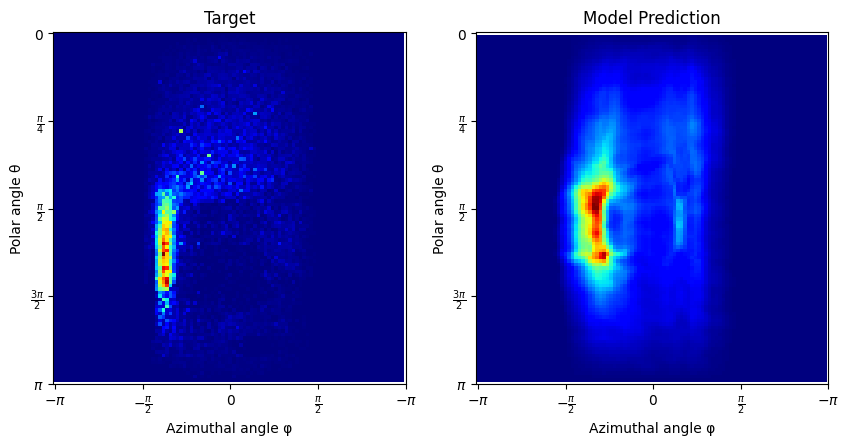

 40%|███▉      | 19999/50000 [44:33<58:37,  8.53it/s]  

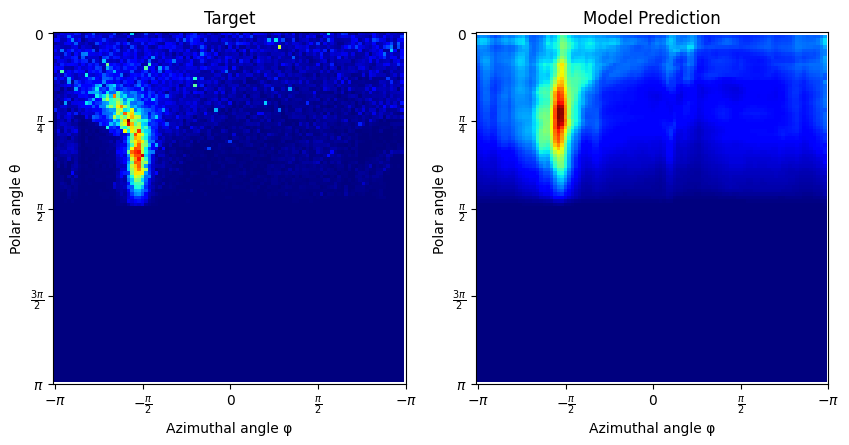

 50%|████▉     | 24999/50000 [55:43<49:03,  8.49it/s]  

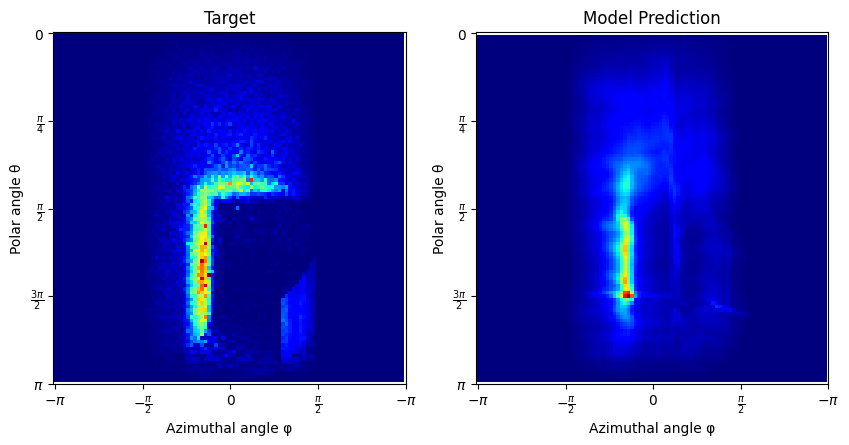

 60%|█████▉    | 29999/50000 [1:04:43<31:03, 10.73it/s]

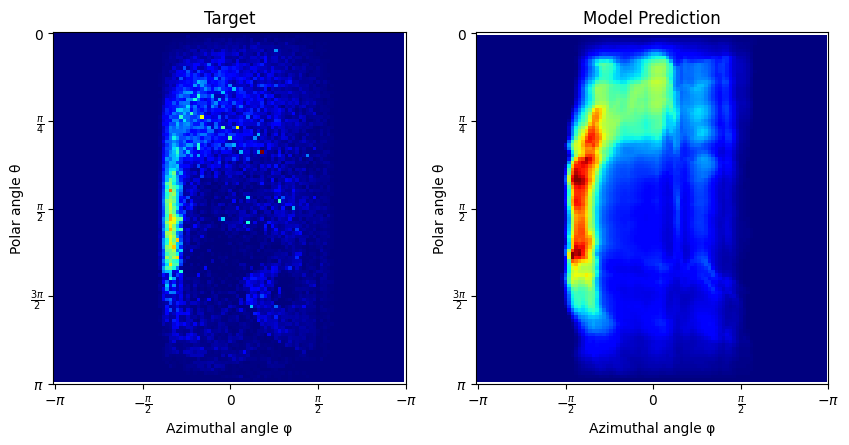

 70%|██████▉   | 34999/50000 [1:13:33<23:27, 10.66it/s]

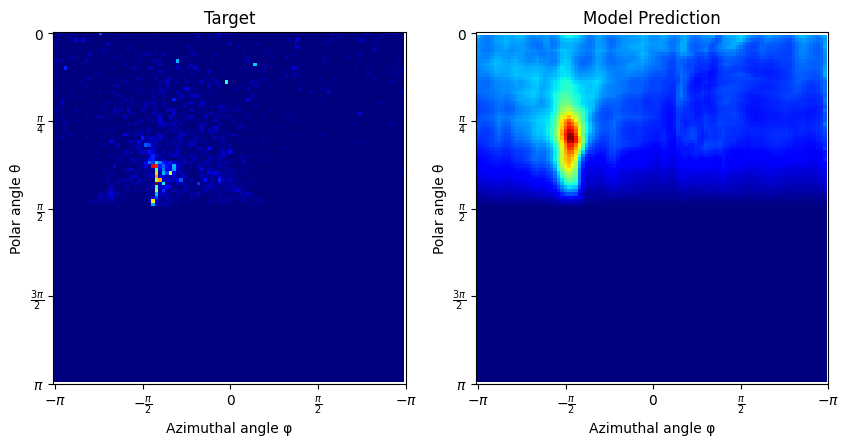

 80%|███████▉  | 39999/50000 [1:22:24<15:49, 10.54it/s]

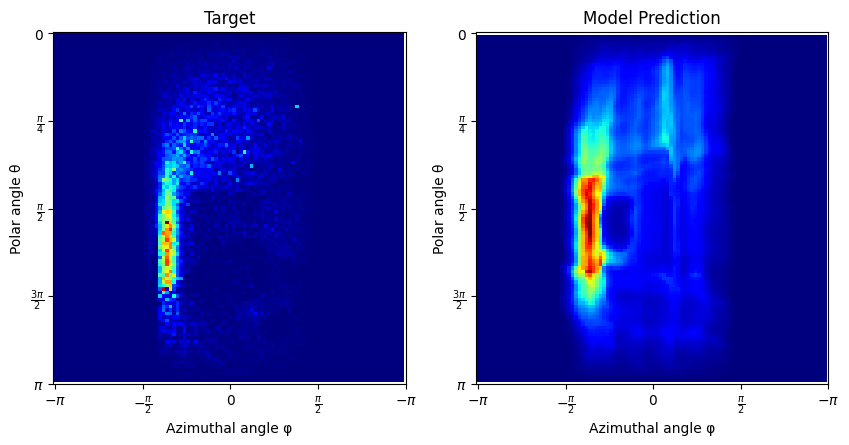

 90%|████████▉ | 44999/50000 [1:31:06<07:52, 10.57it/s]

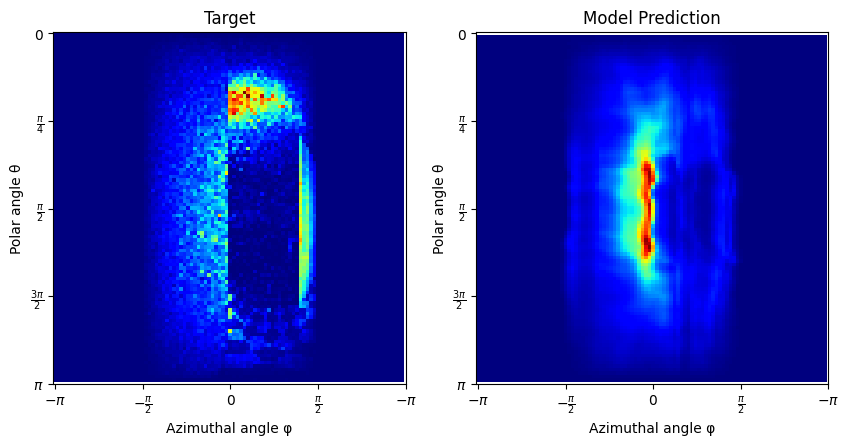

100%|██████████| 50000/50000 [1:40:09<00:00,  8.32it/s]


average generate_samples_time time 0.036087495613098146
average compute_gradient_time time 0.031164667859077455
average nan_check_clip_time time 0.0005340921831130982
average optimizer_time time 8.978843688964844e-09


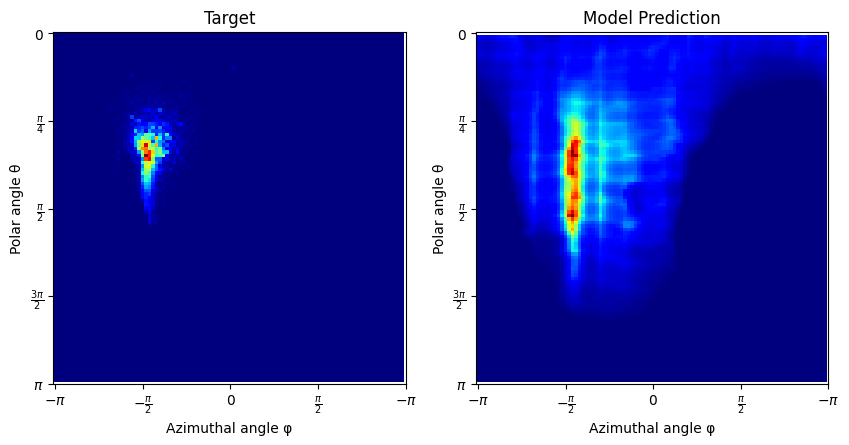

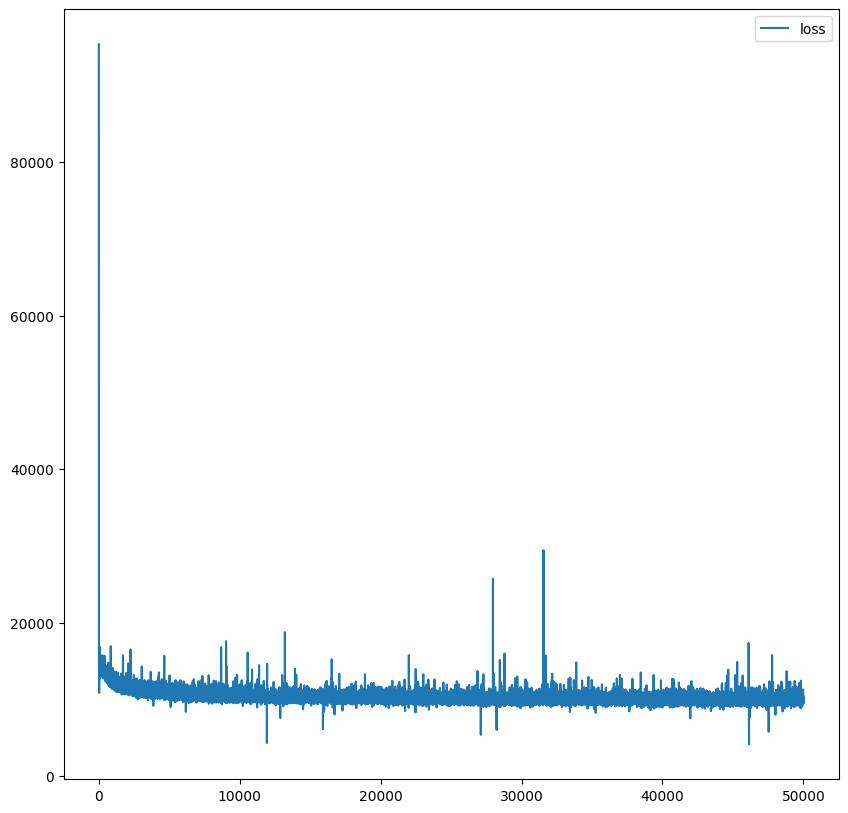

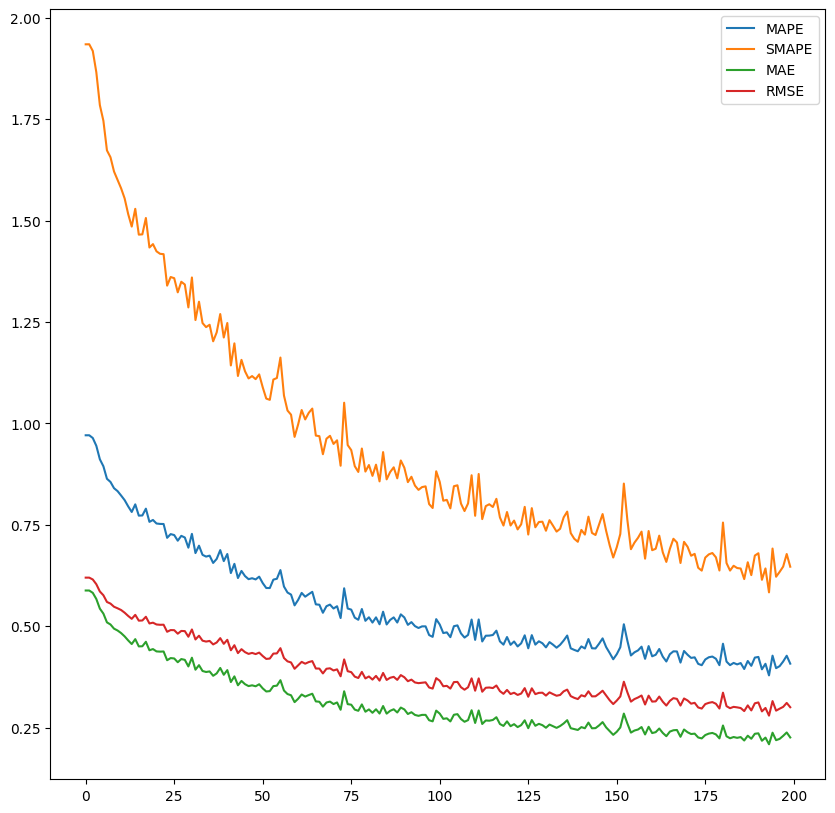

In [ ]:
### Veach Ajar aggressive stagger

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'veach_ajar',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4, 

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid= True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = True,

    grid_resolutions=[4, 8, 12, 16],
    grid_levels=[2, 4, 6, 8],
    grid_scale_factors=[1.25, 1.5, 1.75, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "veach_ajar_50k_cosine_hash_grid_multiple_stagger_aggressive.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]

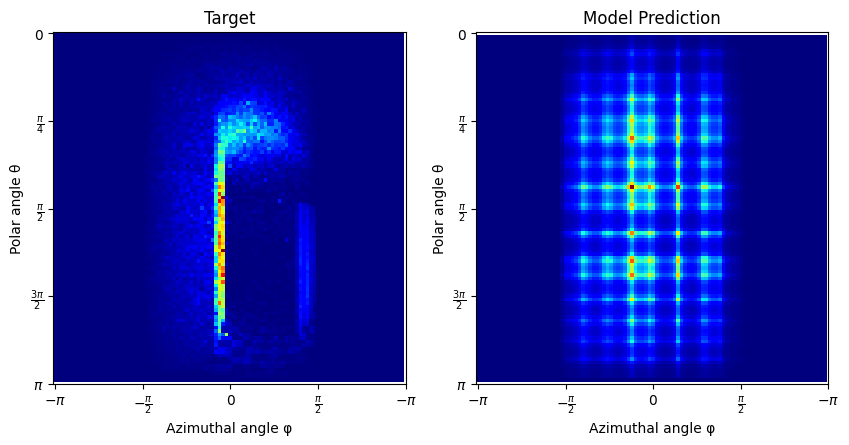

 10%|▉         | 4999/50000 [12:47<1:39:41,  7.52it/s]

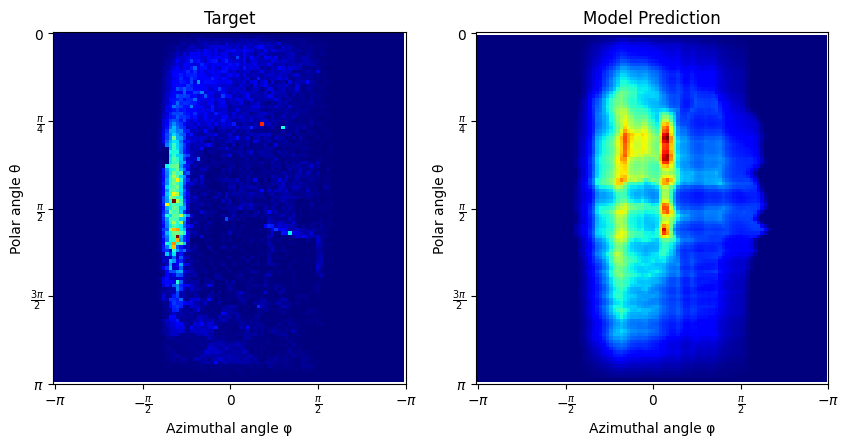

 20%|█▉        | 9999/50000 [25:08<1:28:36,  7.52it/s]

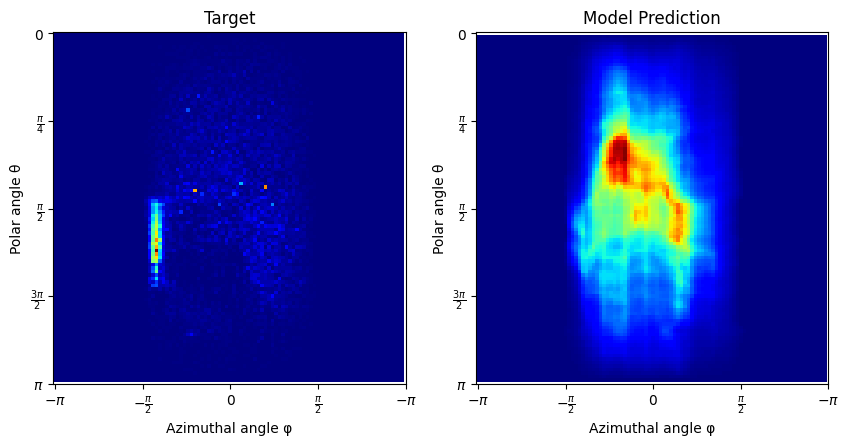

 30%|███       | 15000/50000 [37:39<1:16:46,  7.60it/s]

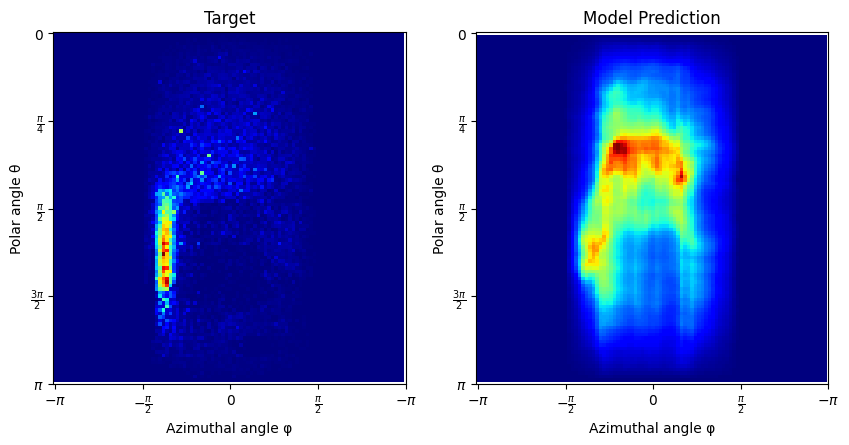

 40%|███▉      | 19999/50000 [49:59<1:06:11,  7.55it/s]

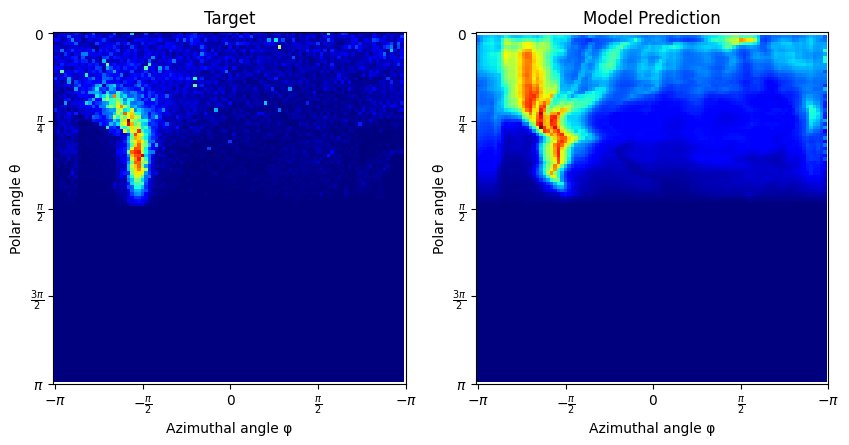

 50%|████▉     | 24999/50000 [1:02:20<55:23,  7.52it/s]  

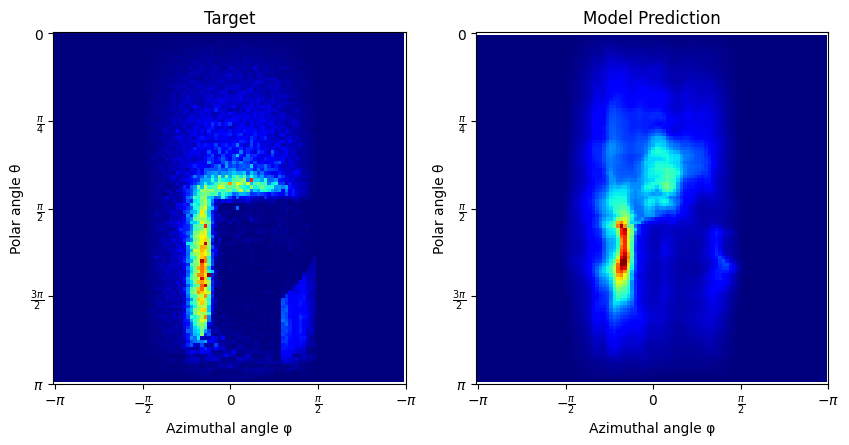

 60%|██████    | 30000/50000 [1:15:01<54:51,  6.08it/s]  

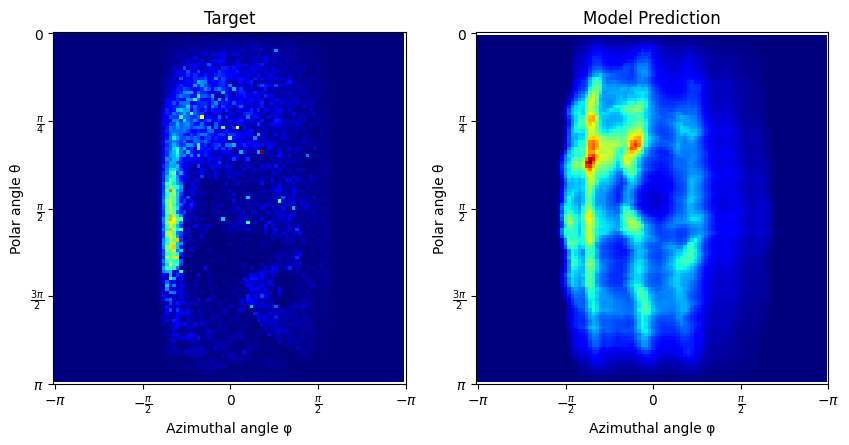

 70%|███████   | 35000/50000 [1:28:12<32:53,  7.60it/s]  

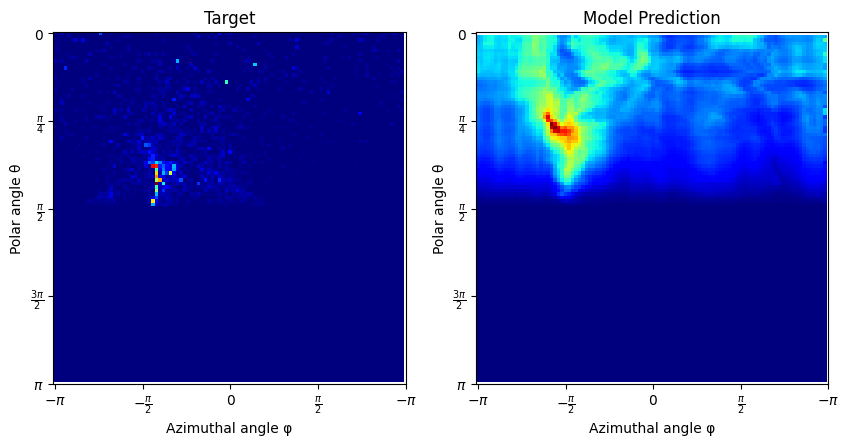

 80%|████████  | 40000/50000 [1:38:52<18:58,  8.78it/s]

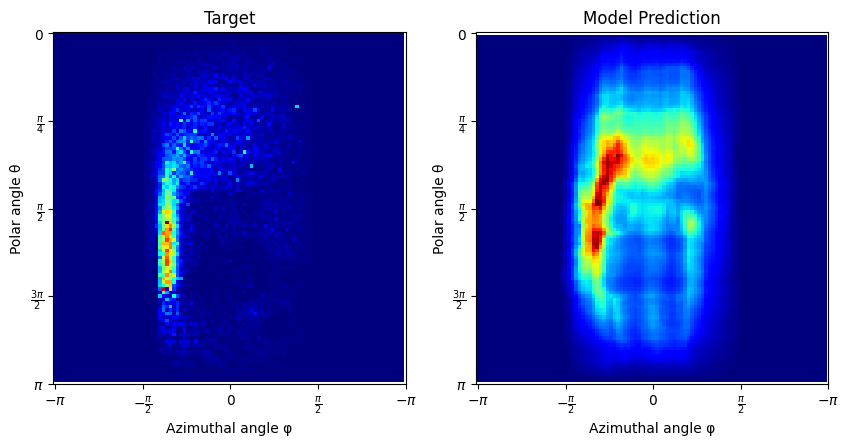

 90%|████████▉ | 44999/50000 [1:49:33<09:34,  8.70it/s]

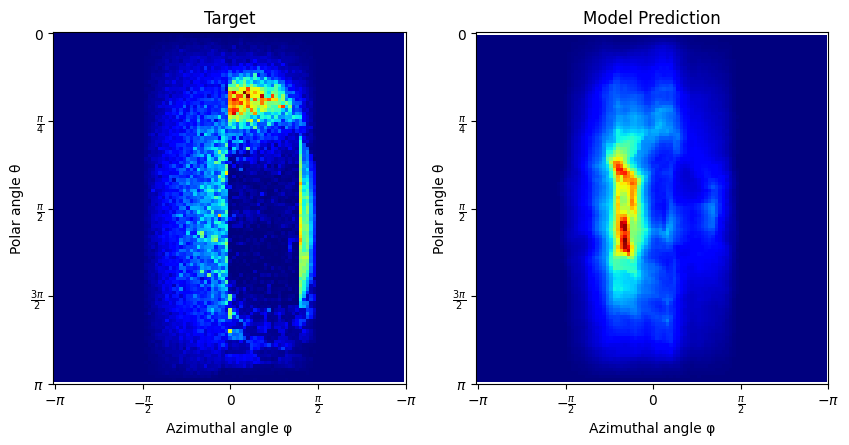

100%|██████████| 50000/50000 [1:59:56<00:00,  6.95it/s]


average generate_samples_time time 0.046344920954704286
average compute_gradient_time time 0.03420849091053009
average nan_check_clip_time time 0.0006186850690841674
average optimizer_time time 1.0418891906738282e-08


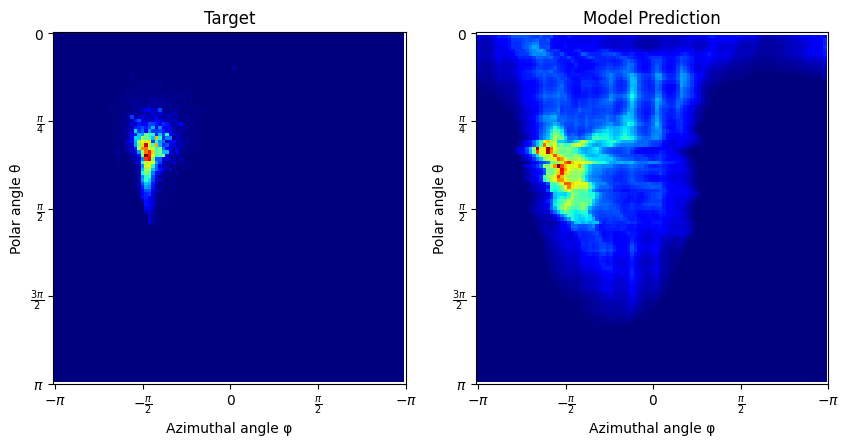

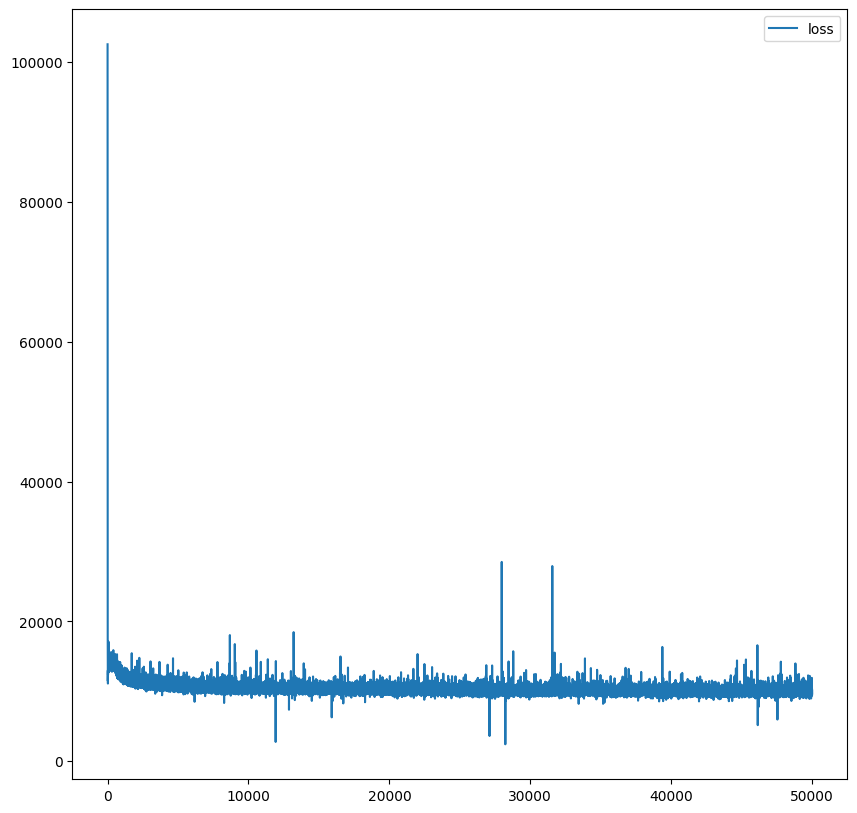

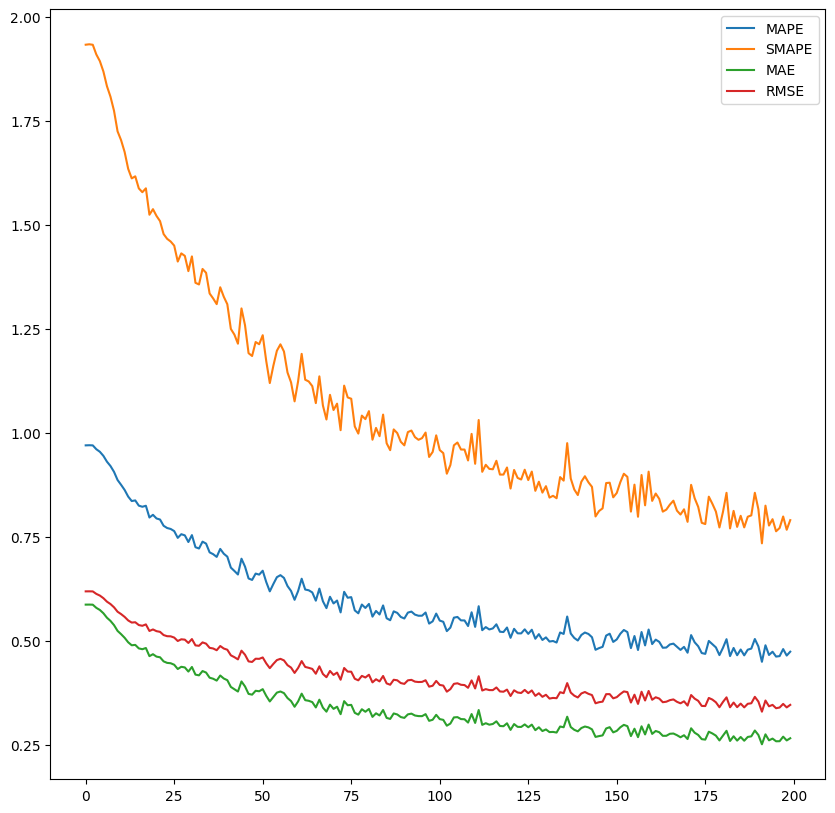

In [ ]:
### Veach Ajar latent

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'veach_ajar',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4, 

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "veach_ajar_50k_cosine_hash_grid_multiple_latent.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:110: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


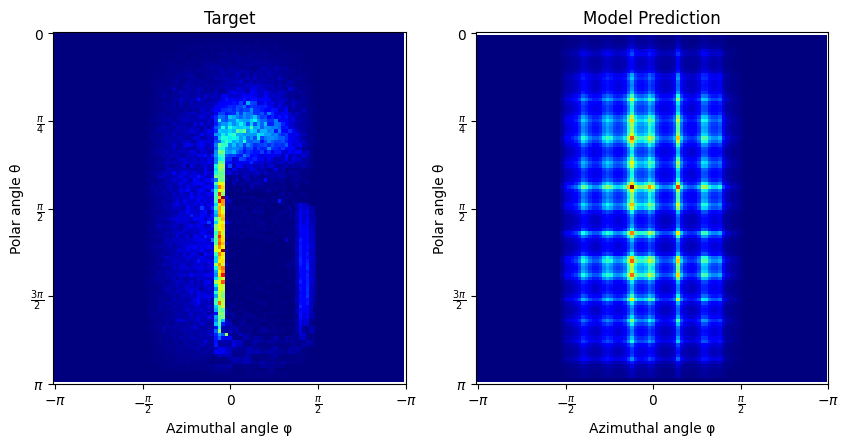

 10%|▉         | 4999/50000 [08:33<1:07:55, 11.04it/s]

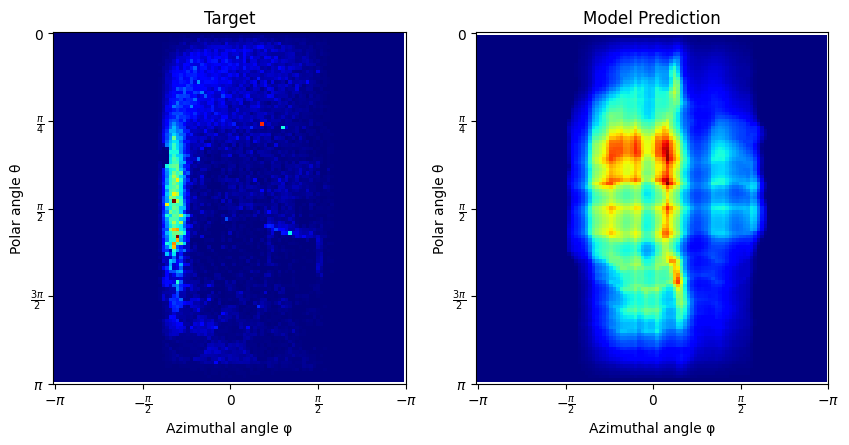

 20%|█▉        | 9999/50000 [17:15<1:01:33, 10.83it/s]

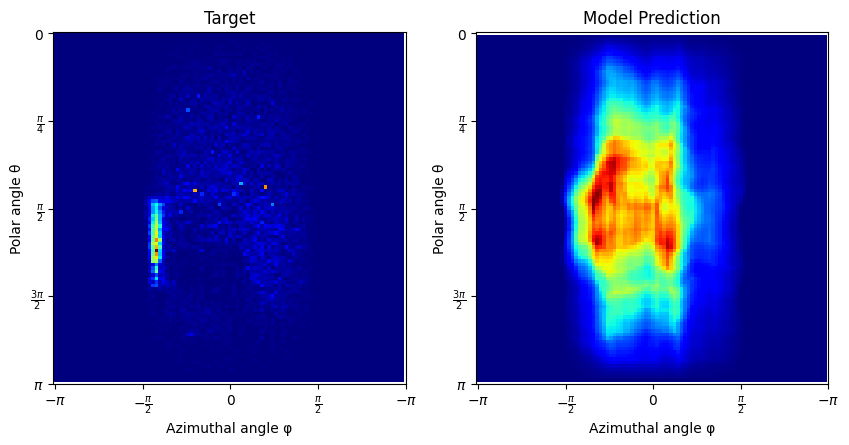

 30%|██▉       | 14999/50000 [25:47<53:07, 10.98it/s]  

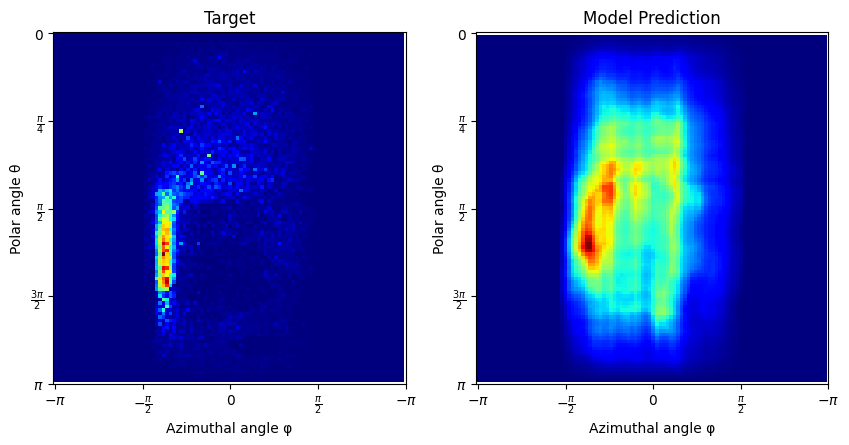

 40%|███▉      | 19999/50000 [34:27<45:54, 10.89it/s]  

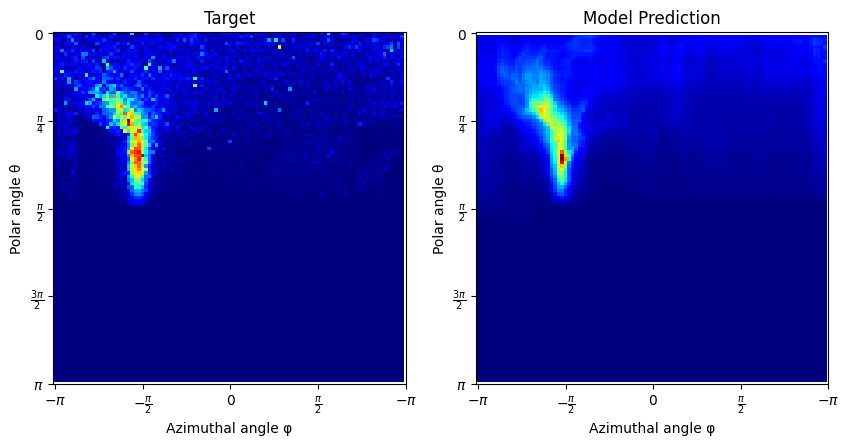

 50%|████▉     | 24999/50000 [43:01<38:01, 10.96it/s]  

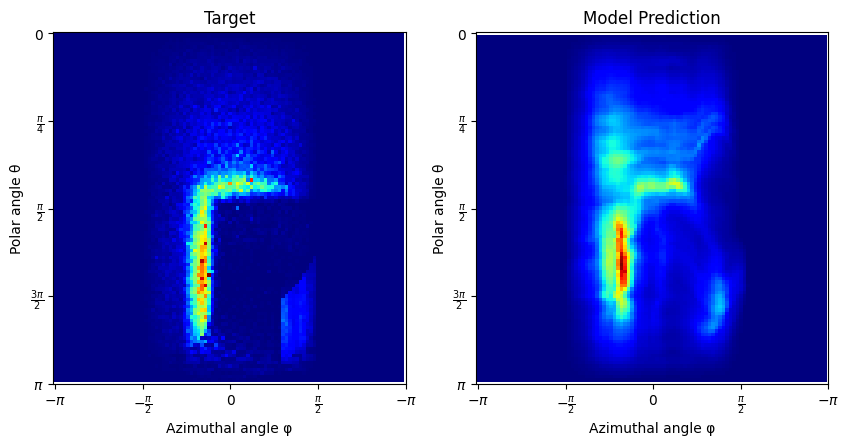

 60%|█████▉    | 29999/50000 [51:31<30:02, 11.10it/s]

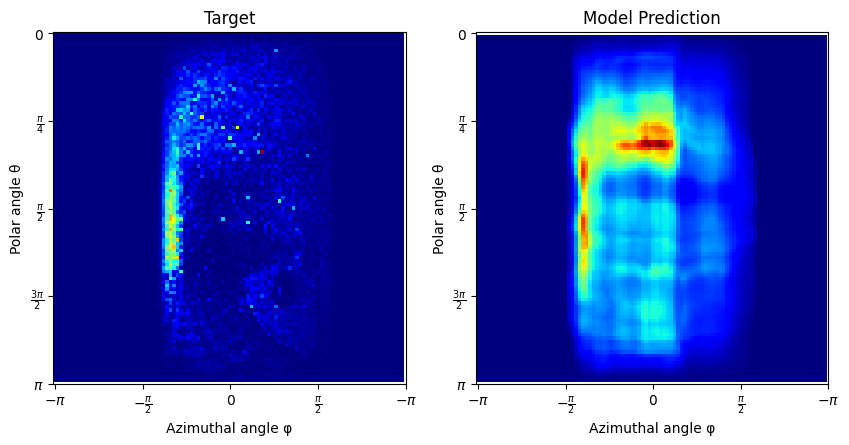

 70%|██████▉   | 34999/50000 [1:00:12<22:40, 11.03it/s]

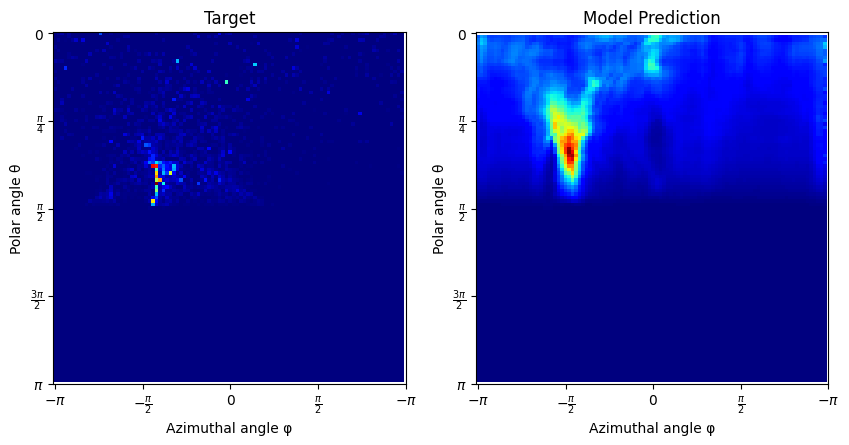

 80%|███████▉  | 39999/50000 [1:08:38<15:30, 10.74it/s]

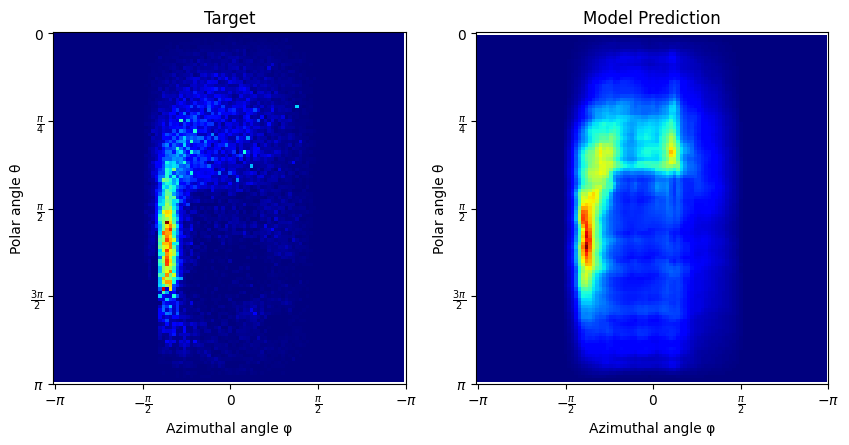

 90%|████████▉ | 44999/50000 [1:17:14<07:42, 10.81it/s]

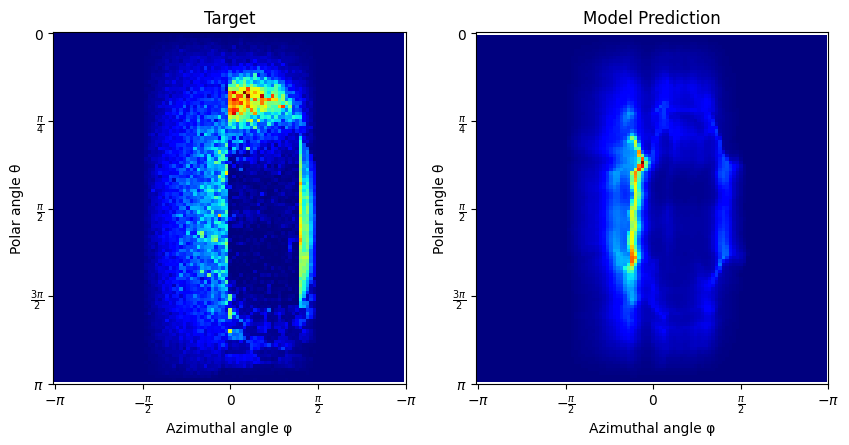

100%|██████████| 50000/50000 [1:25:50<00:00,  9.71it/s]


average generate_samples_time time 0.0217810960483551
average compute_gradient_time time 0.03296236947059631
average nan_check_clip_time time 0.0005812416696548461
average optimizer_time time 1.0509490966796875e-08


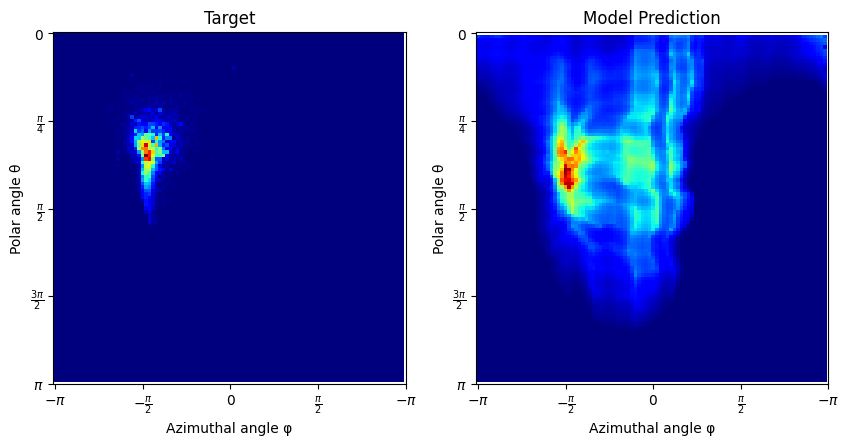

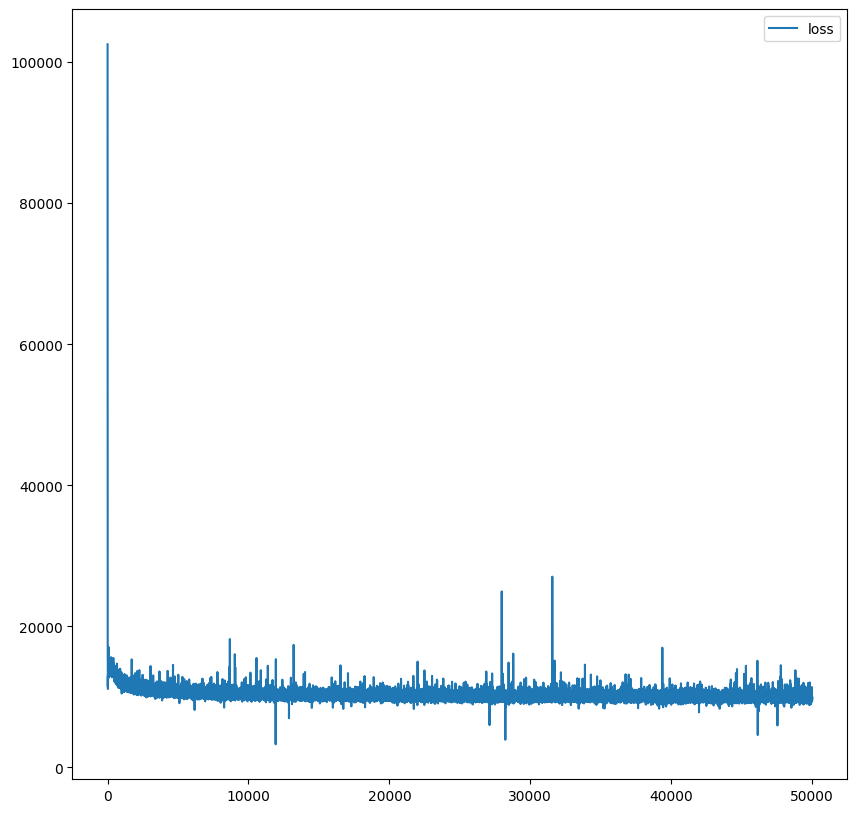

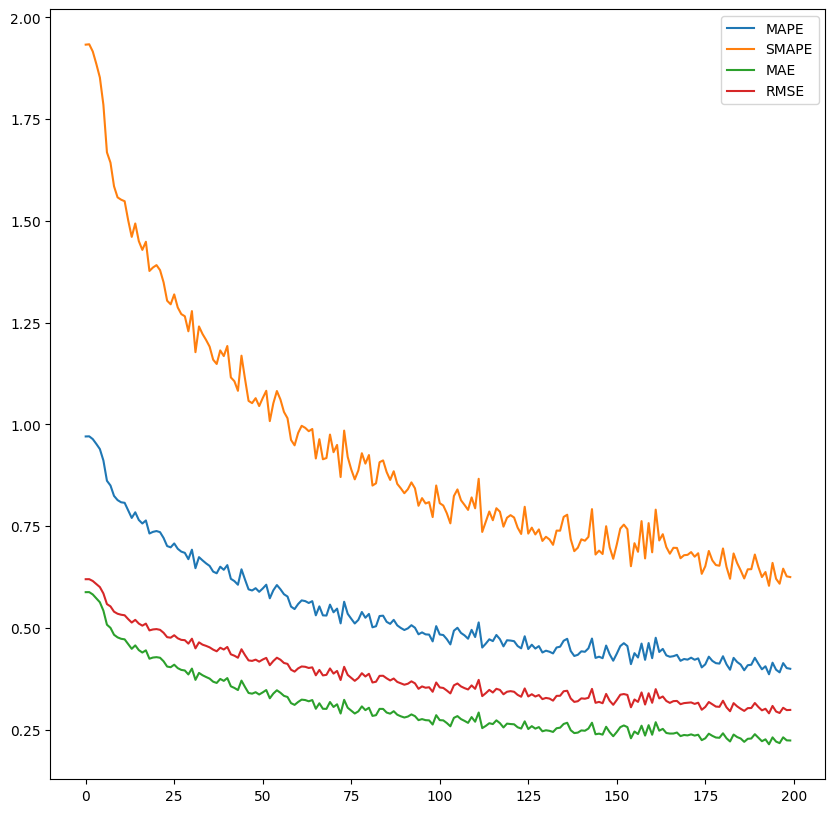

In [ ]:
### Veach Ajar full

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'veach_ajar',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4, 

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid= True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = True,

    grid_resolutions=[4, 8, 12, 16],
    grid_levels=[2, 4, 6, 8],
    grid_scale_factors=[1.25, 1.5, 1.75, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "veach_ajar_50k_full.pkl")
del(exp)

## Living room

loaded scene
using device: cuda
created model
starting training


100%|██████████| 3000/3000 [07:43<00:00,  6.47it/s]


average generate_samples_time time 0.06919258530934652
average compute_gradient_time time 0.035739218552907306
average nan_check_clip_time time 0.0005605001449584961
average optimizer_time time 1.7261505126953124e-07


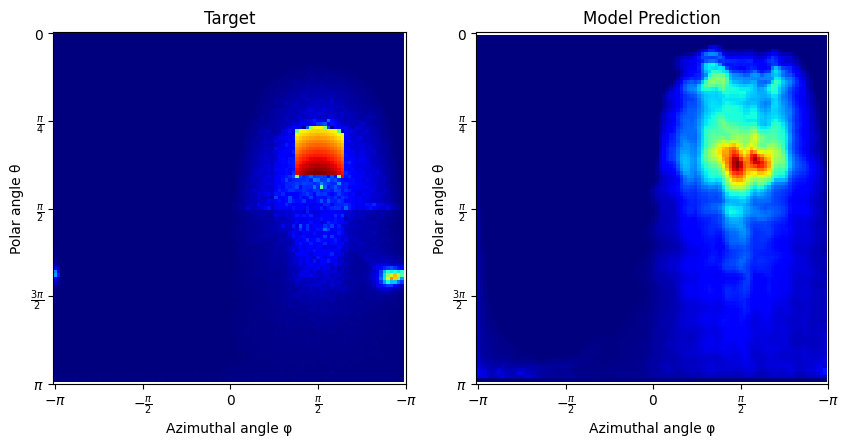

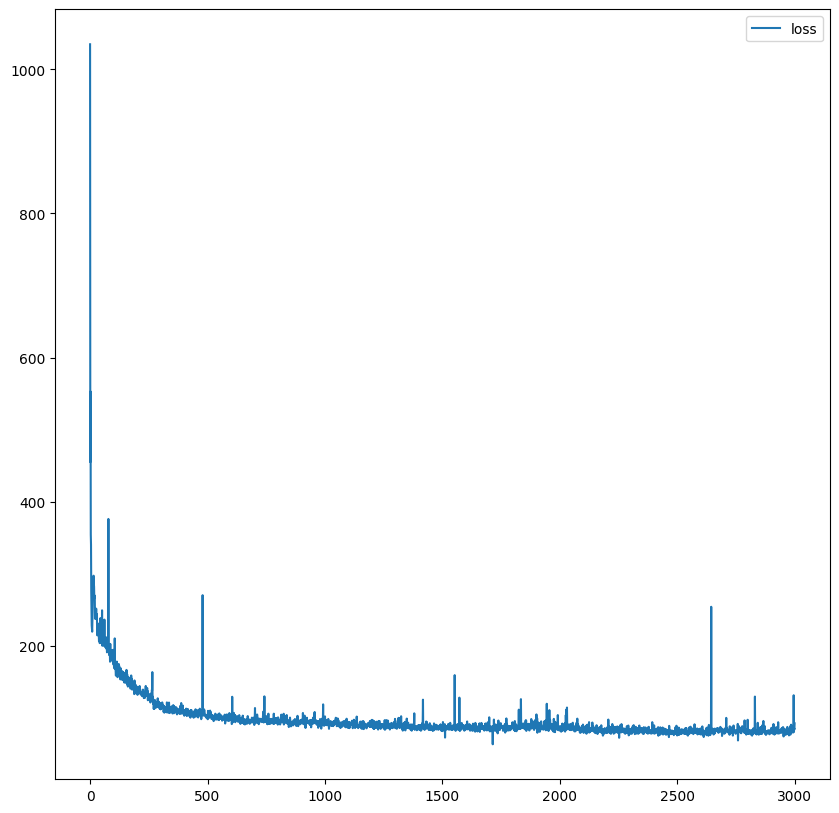

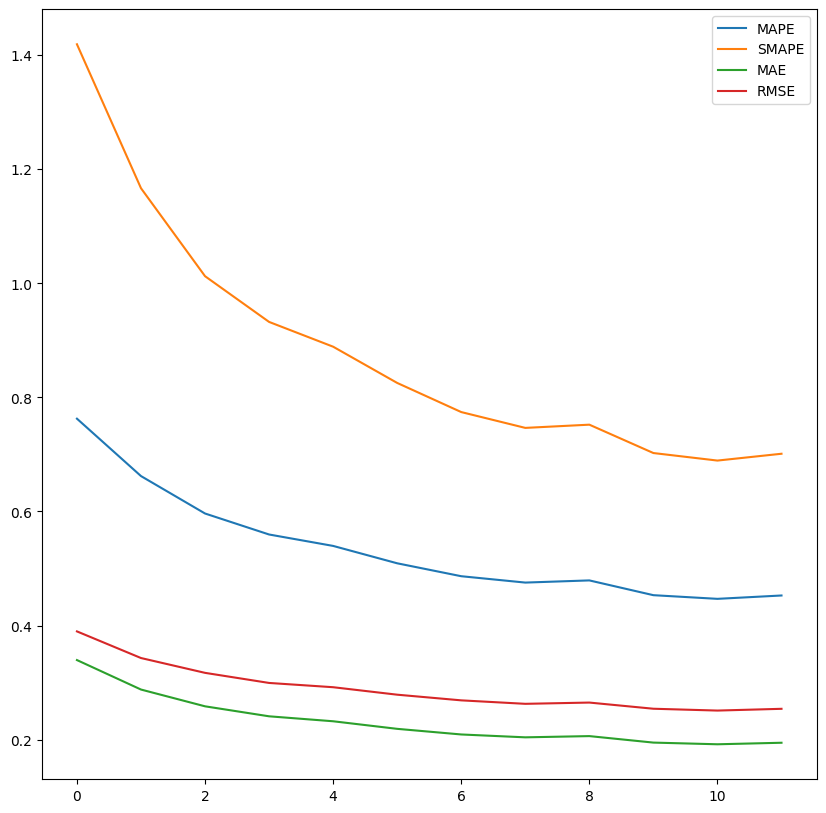

In [ ]:
### Living room hash grid

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'living_room_2',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 1e-3, 

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid= True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=5, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "living_room_50k_cosine_hash_grid1eneg3.pkl")
del(exp)

## Cbox

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


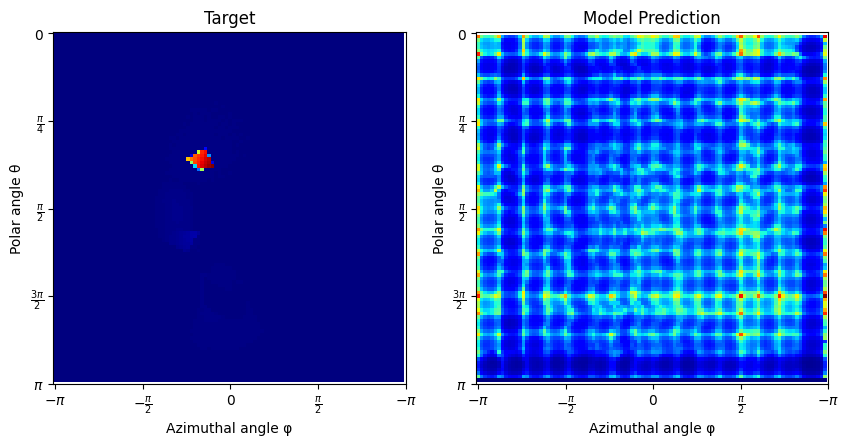

 10%|█         | 5000/50000 [04:22<37:36, 19.94it/s] 

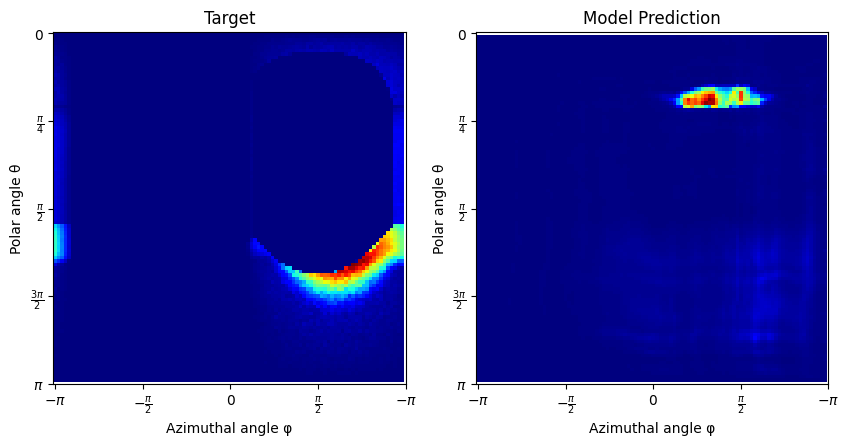

 20%|█▉        | 9998/50000 [08:40<33:20, 19.99it/s]

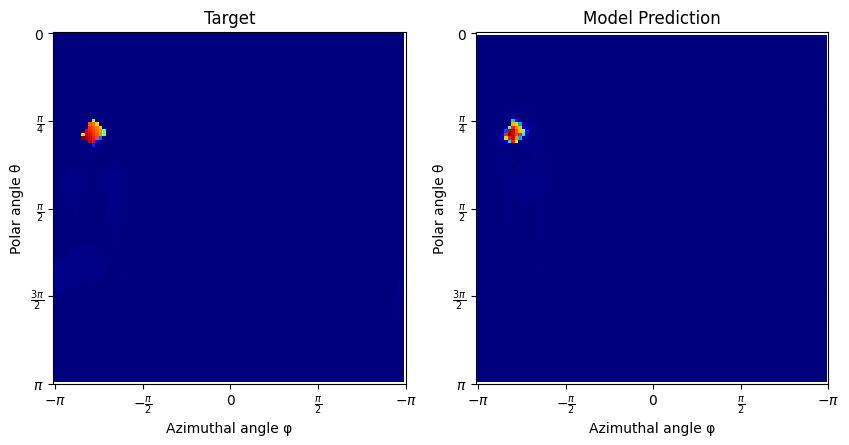

 30%|██▉       | 14999/50000 [12:55<28:12, 20.68it/s]

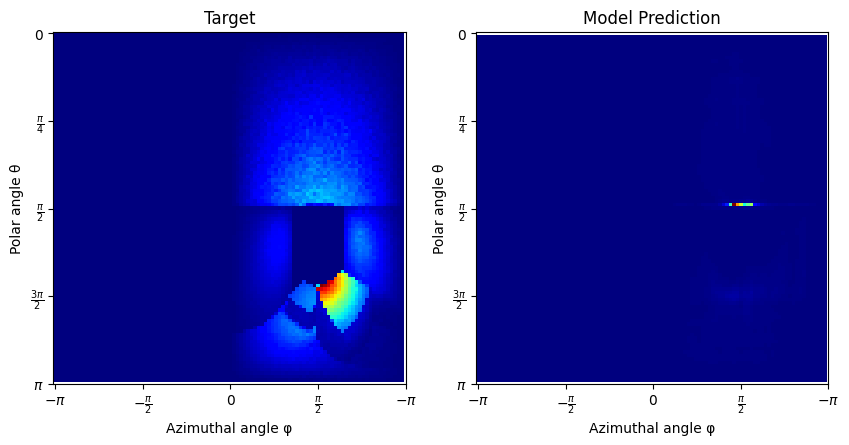

 40%|████      | 20000/50000 [17:06<24:48, 20.16it/s]

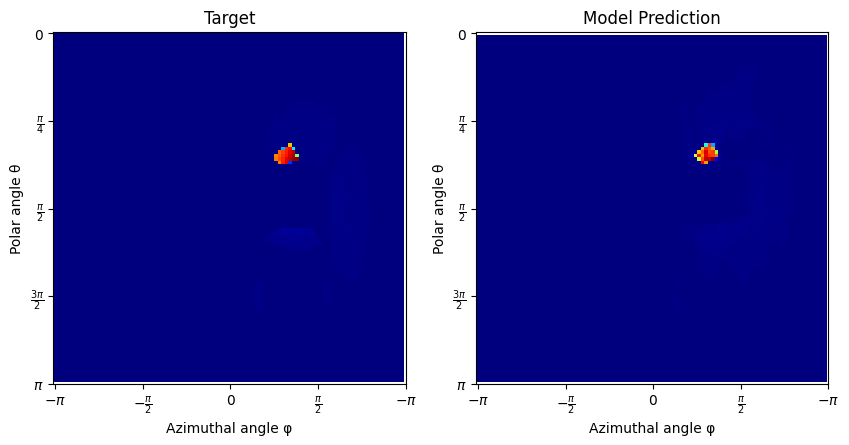

 50%|████▉     | 24998/50000 [21:20<20:10, 20.65it/s]

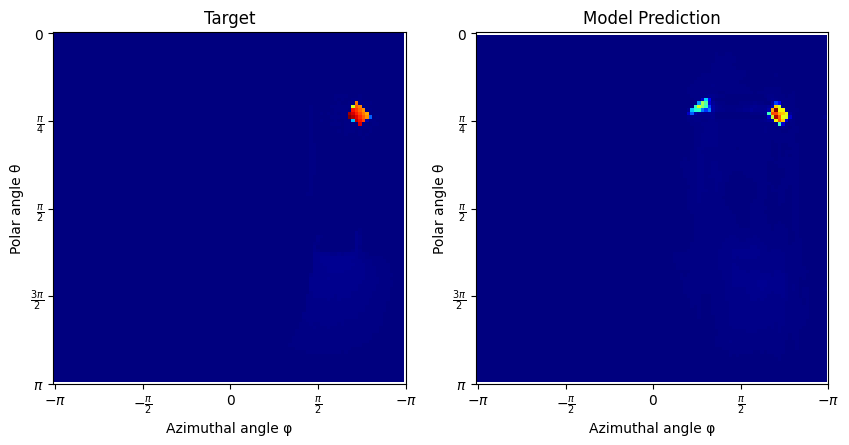

 60%|█████▉    | 29999/50000 [25:31<16:00, 20.83it/s]

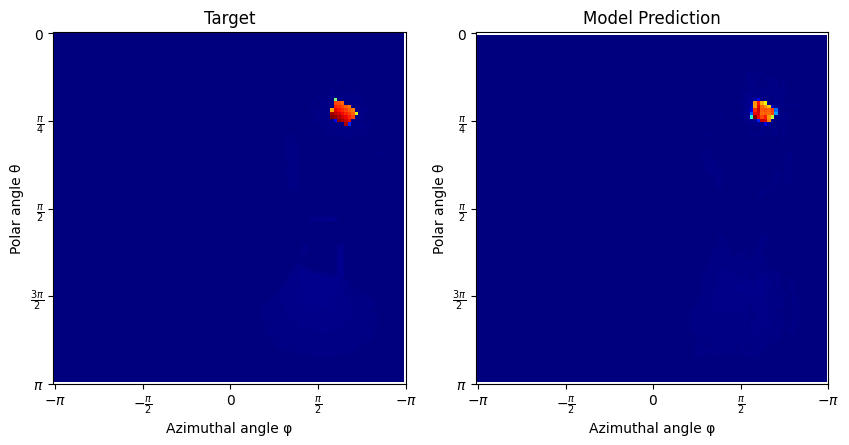

 70%|███████   | 35000/50000 [29:40<12:08, 20.58it/s]

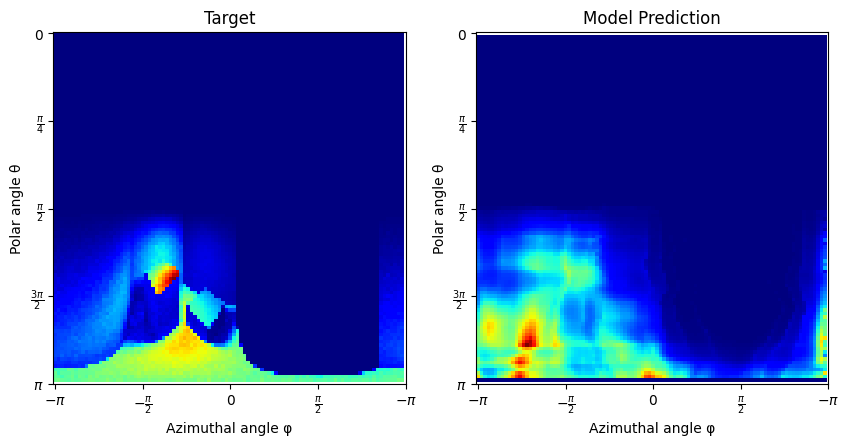

 80%|███████▉  | 39998/50000 [33:50<08:07, 20.52it/s]

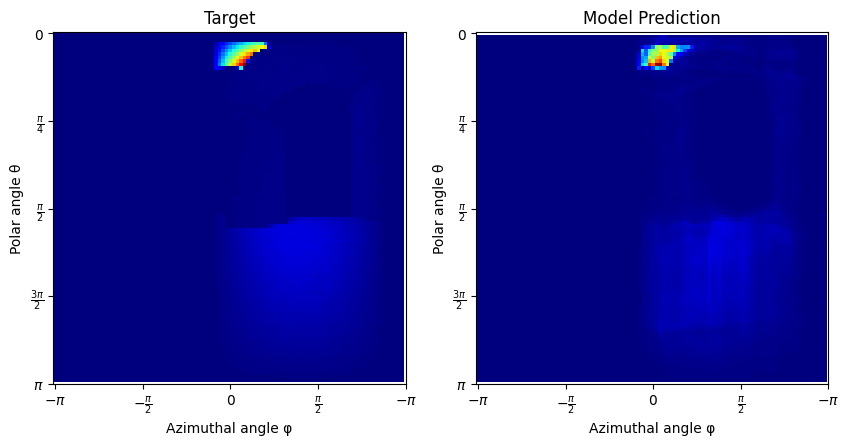

 90%|████████▉ | 44999/50000 [37:58<04:00, 20.82it/s]

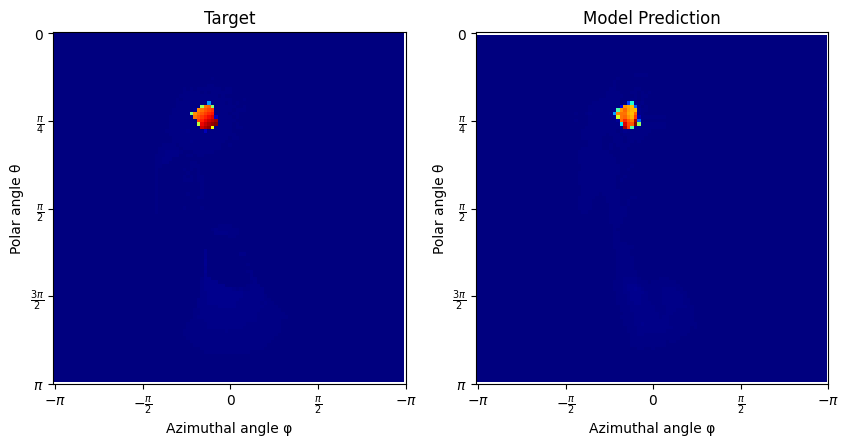

100%|██████████| 50000/50000 [42:12<00:00, 19.75it/s]


average generate_samples_time time 0.011885582013130188
average compute_gradient_time time 0.03051468575954437
average nan_check_clip_time time 0.0005816371393203736
average optimizer_time time 8.797645568847657e-09


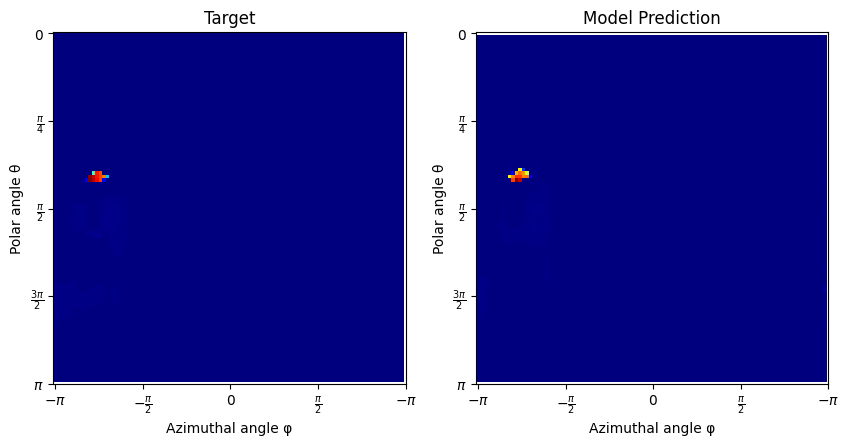

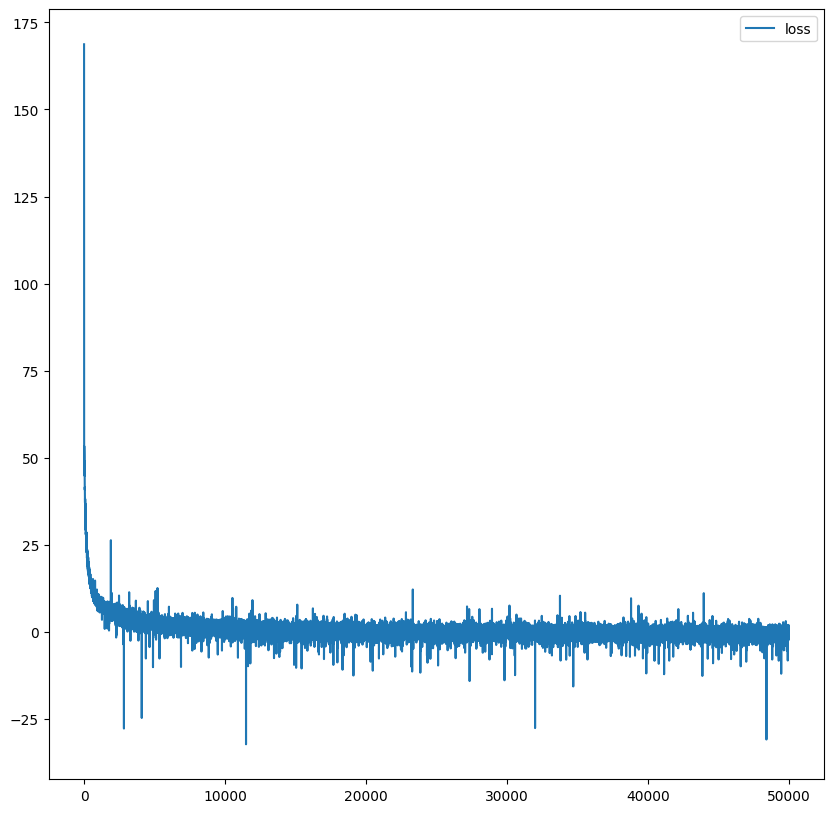

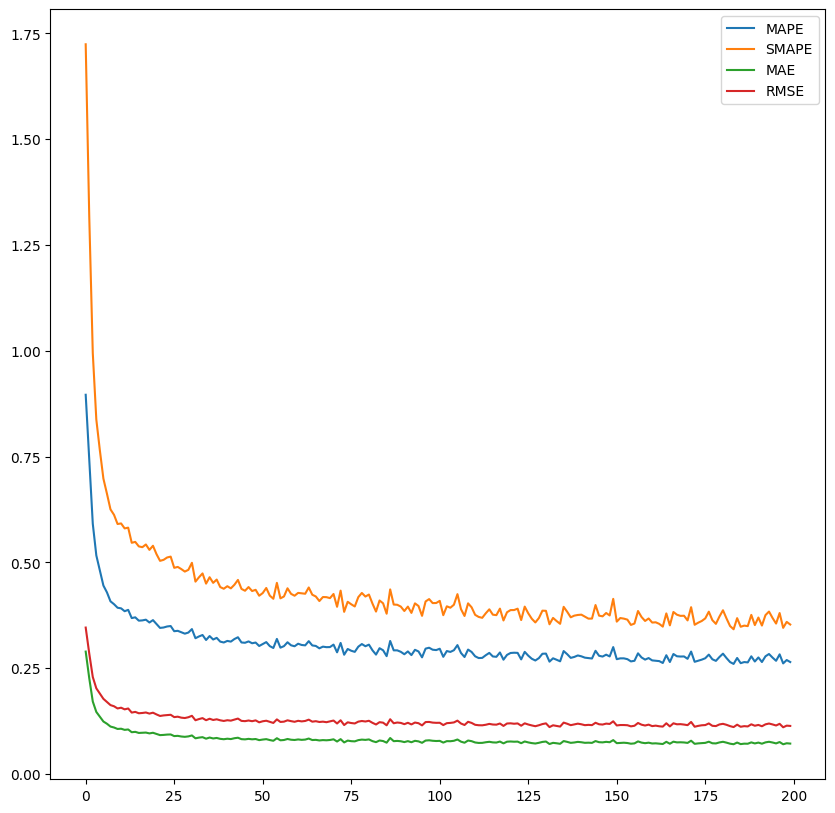

In [ ]:
### Cbox Mueller

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='uniform',
    # prior_str='cosine',
    scene_name = 'cbox',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=False,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = False,
    tonemap_error_calc = True, 
    gammacorrect_error_calc = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "cbox_50k_mueller.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]

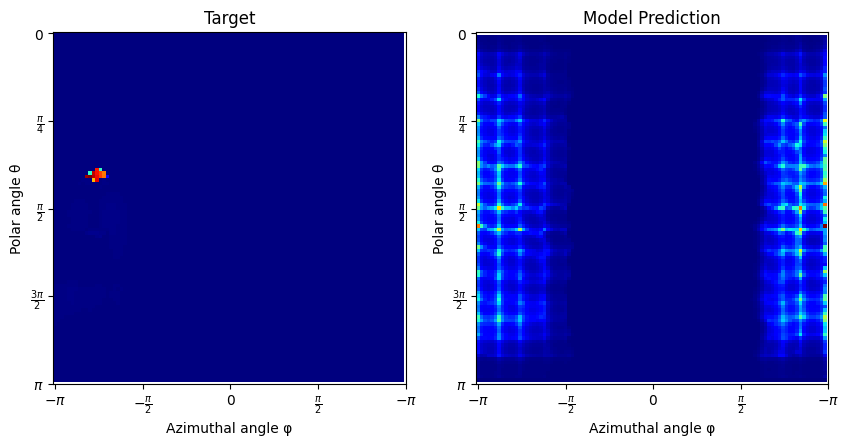

 10%|▉         | 4999/50000 [03:59<34:50, 21.52it/s] 

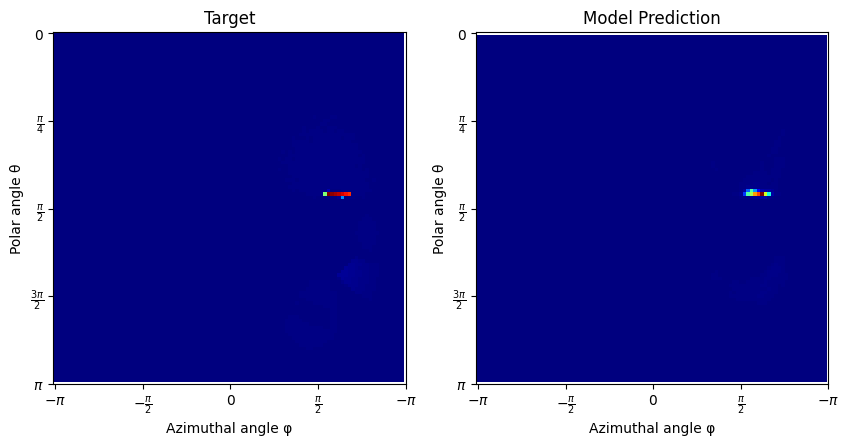

 20%|██        | 10000/50000 [07:58<31:30, 21.16it/s]

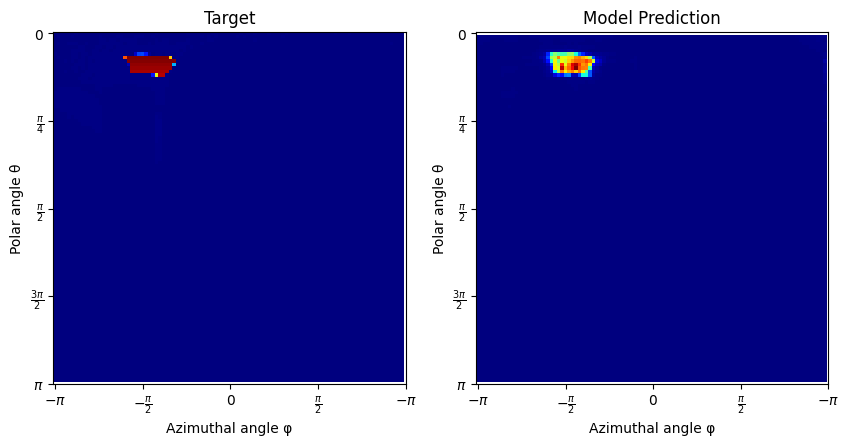

 30%|██▉       | 14998/50000 [12:02<28:14, 20.65it/s]

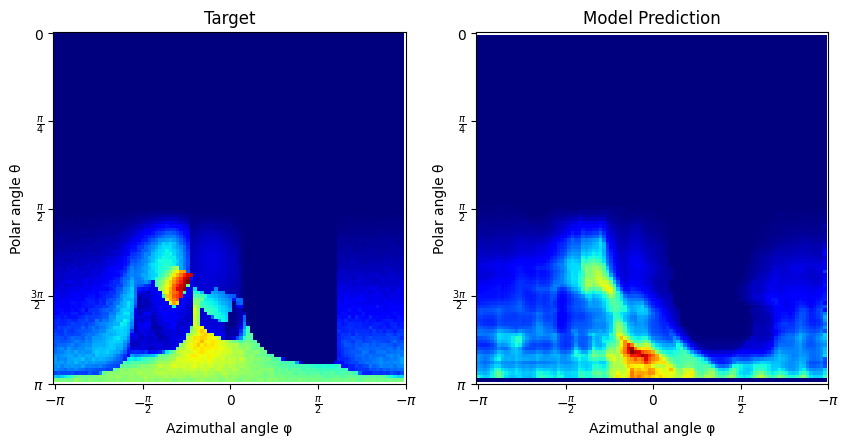

 40%|███▉      | 19999/50000 [16:04<23:18, 21.45it/s]

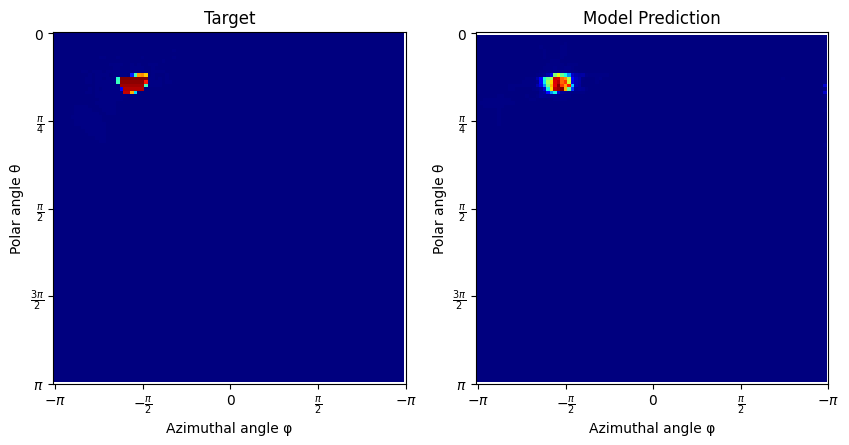

 50%|█████     | 25000/50000 [20:05<19:37, 21.23it/s]

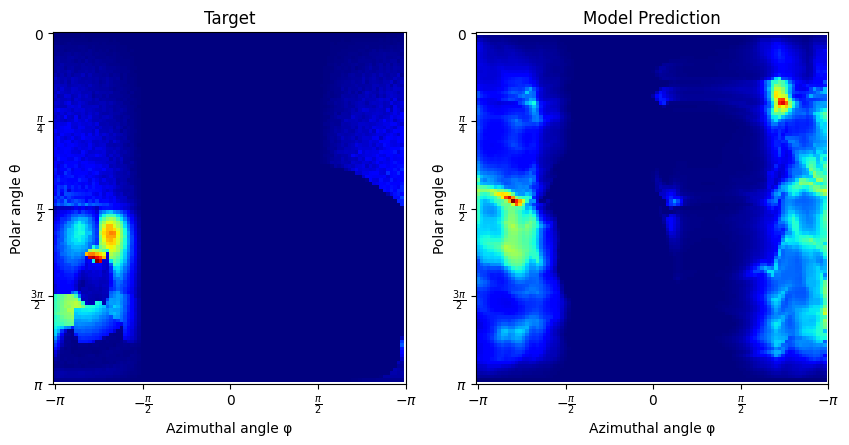

 60%|█████▉    | 29998/50000 [24:07<15:35, 21.38it/s]

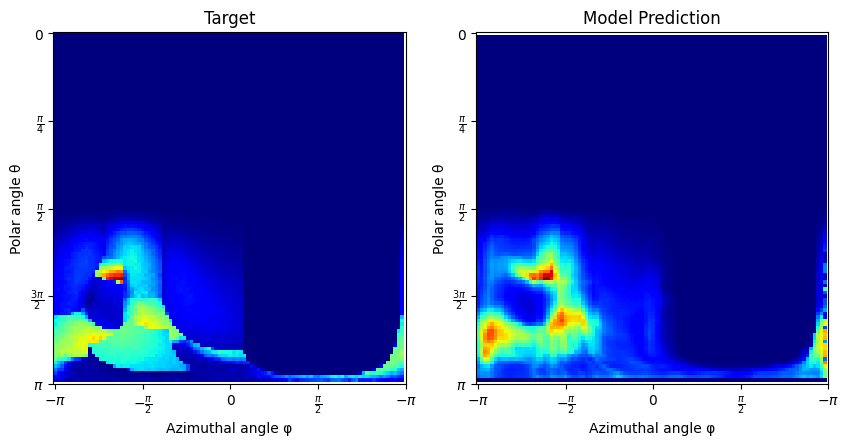

 70%|██████▉   | 34999/50000 [28:07<11:38, 21.49it/s]

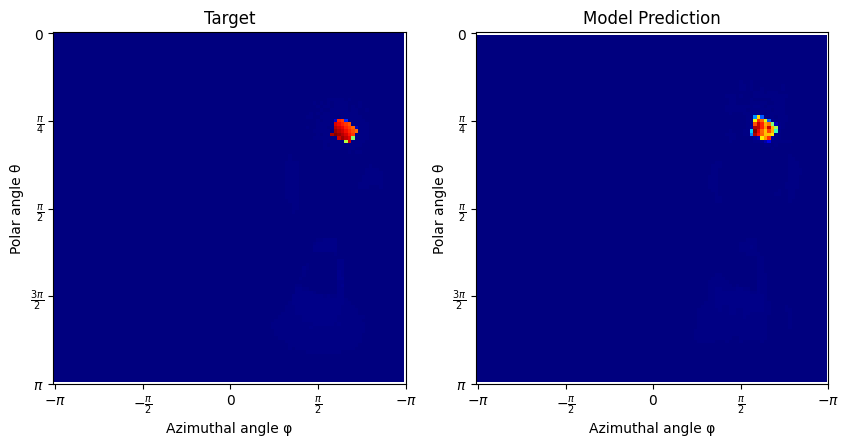

 80%|████████  | 40000/50000 [32:15<08:03, 20.69it/s]

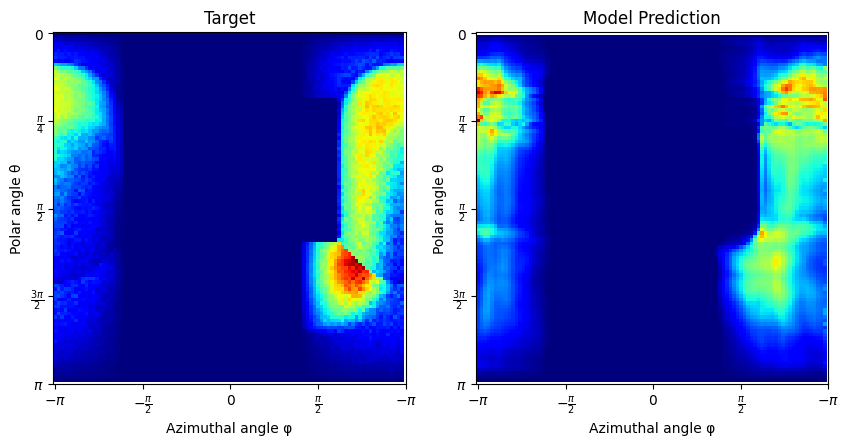

 90%|████████▉ | 44998/50000 [36:29<04:09, 20.06it/s]

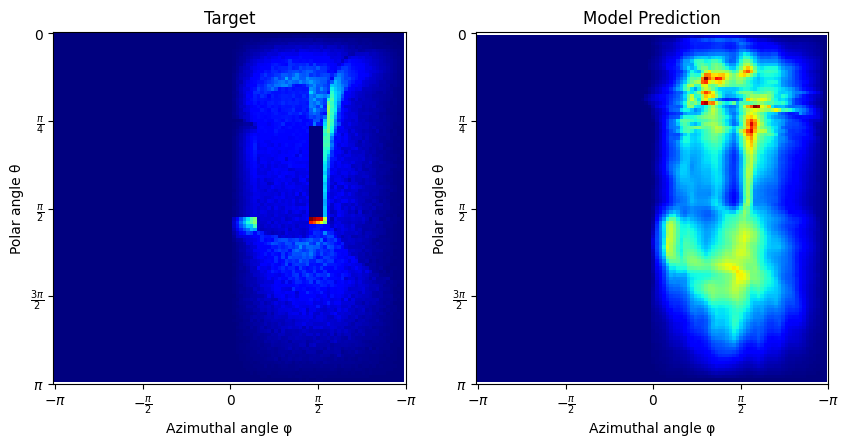

100%|██████████| 50000/50000 [40:40<00:00, 20.49it/s]


average generate_samples_time time 0.0071935684537887574
average compute_gradient_time time 0.031420938258171084
average nan_check_clip_time time 0.0005933518171310425
average optimizer_time time 8.783340454101562e-09


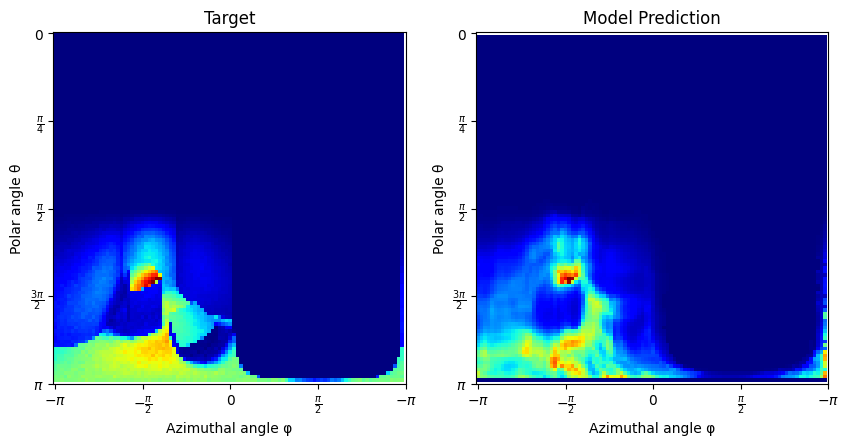

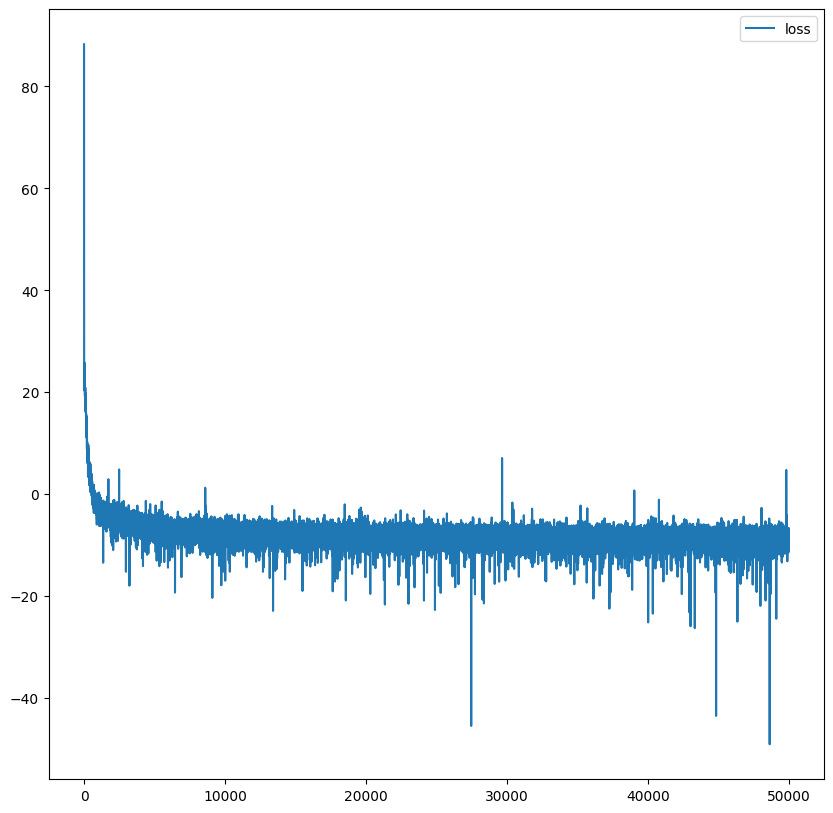

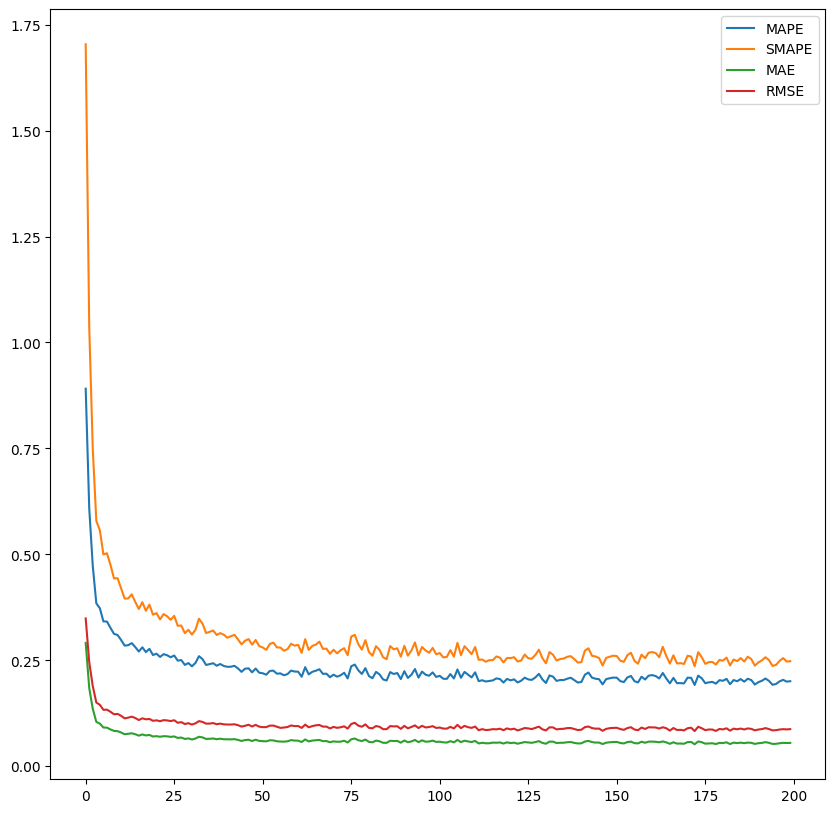

In [13]:
### cos grid

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 1e-3,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)


exp = run_experiment(setup, training_context, "cbox_50k_cosine_hash_grid.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:110: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


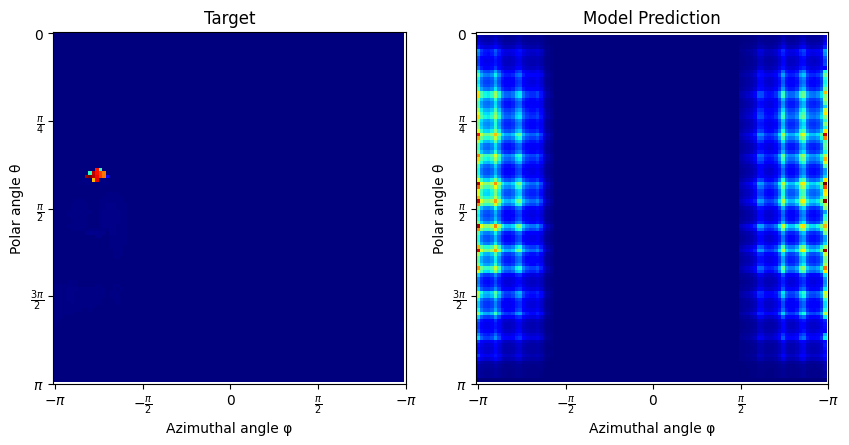

 10%|▉         | 4999/50000 [04:43<40:44, 18.41it/s] 

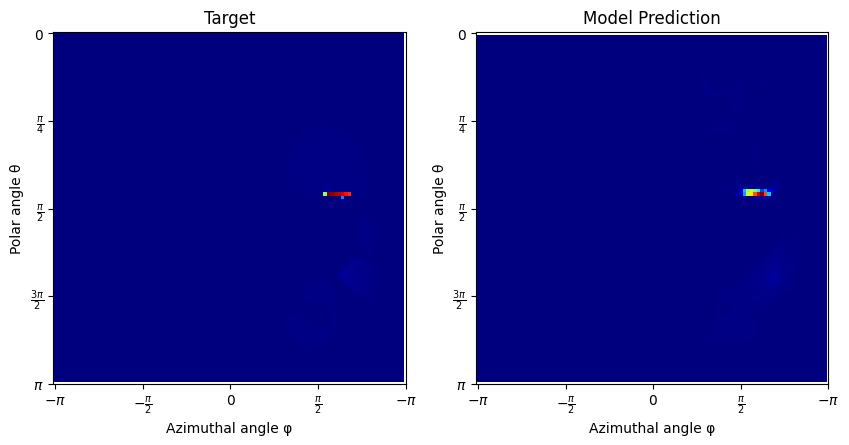

 20%|██        | 10000/50000 [09:14<34:18, 19.43it/s]

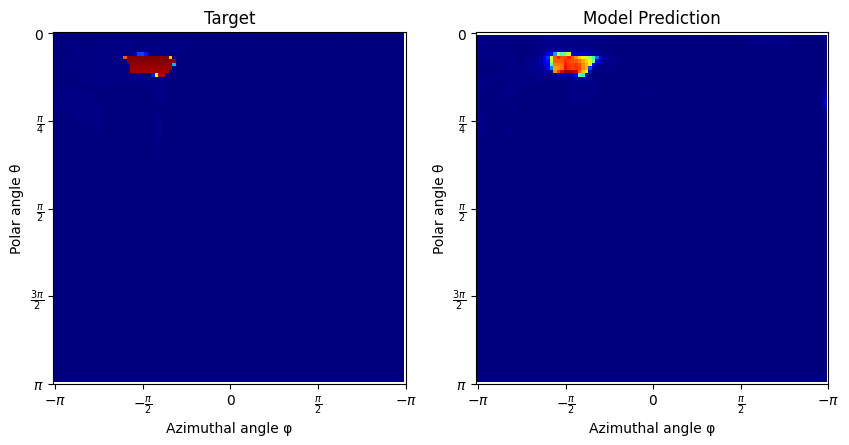

 30%|██▉       | 14998/50000 [13:39<30:26, 19.17it/s]

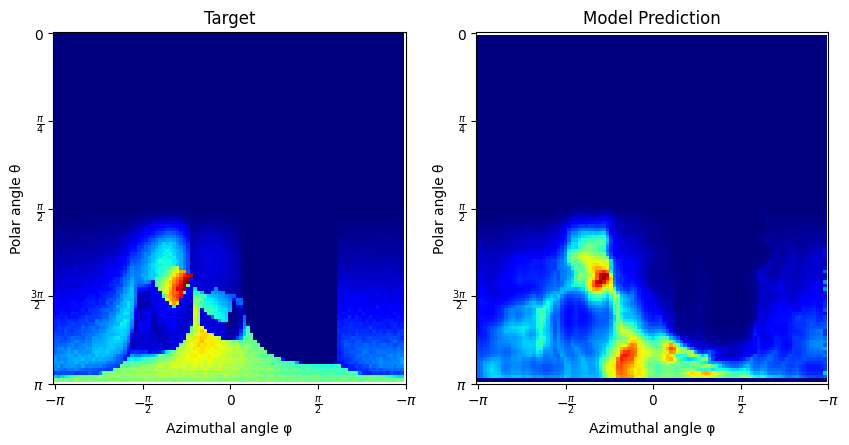

 40%|███▉      | 19999/50000 [18:09<26:22, 18.96it/s]

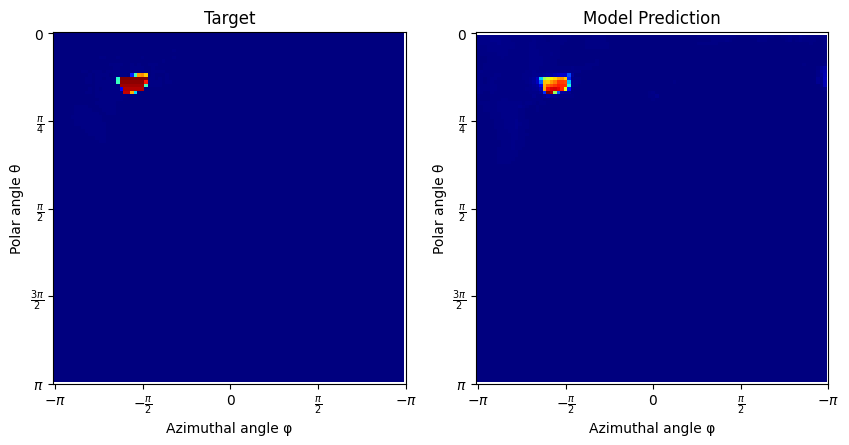

 50%|████▉     | 24999/50000 [23:46<25:15, 16.49it/s]

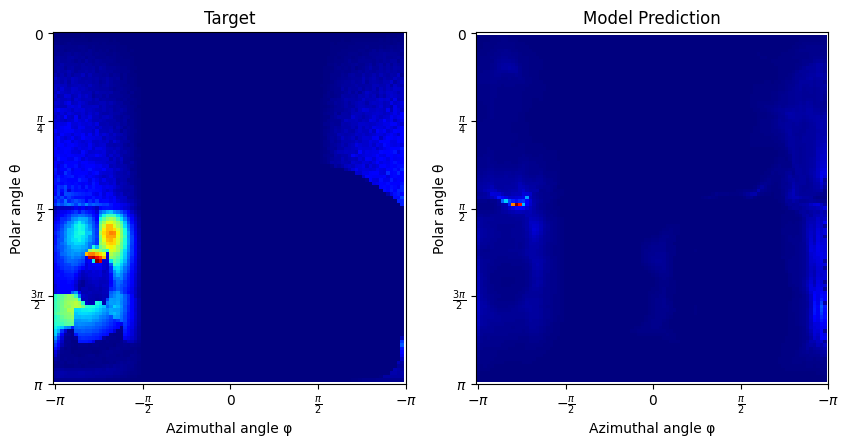

 60%|█████▉    | 29999/50000 [28:15<17:27, 19.10it/s]

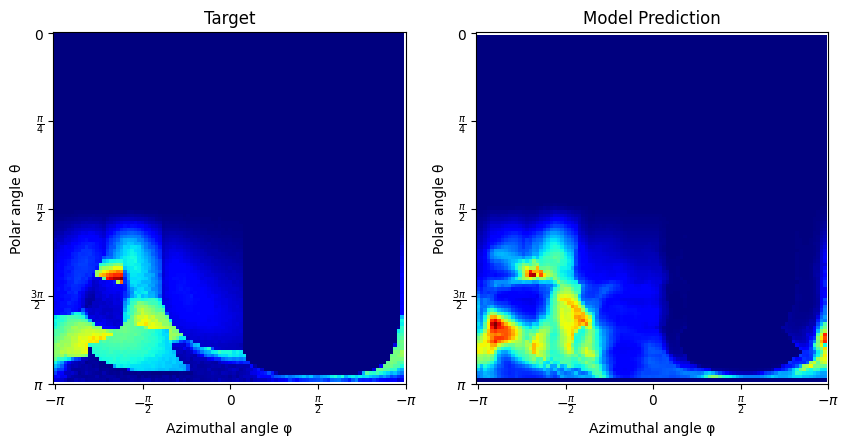

 70%|███████   | 35000/50000 [32:36<12:48, 19.52it/s]

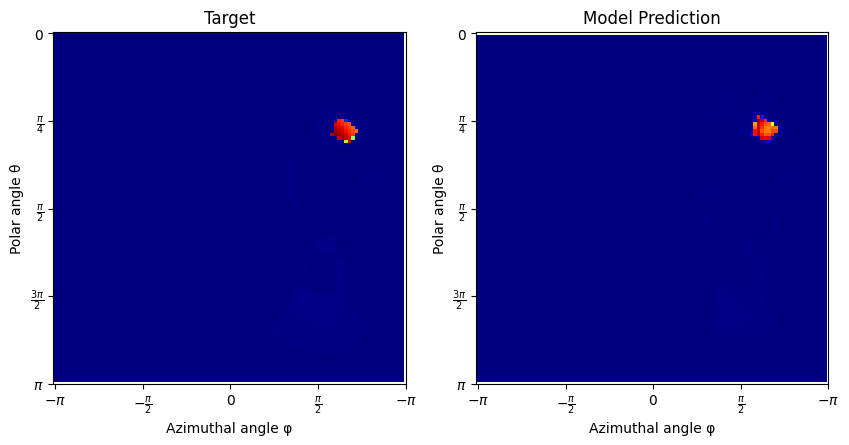

 80%|███████▉  | 39998/50000 [36:57<08:28, 19.68it/s]

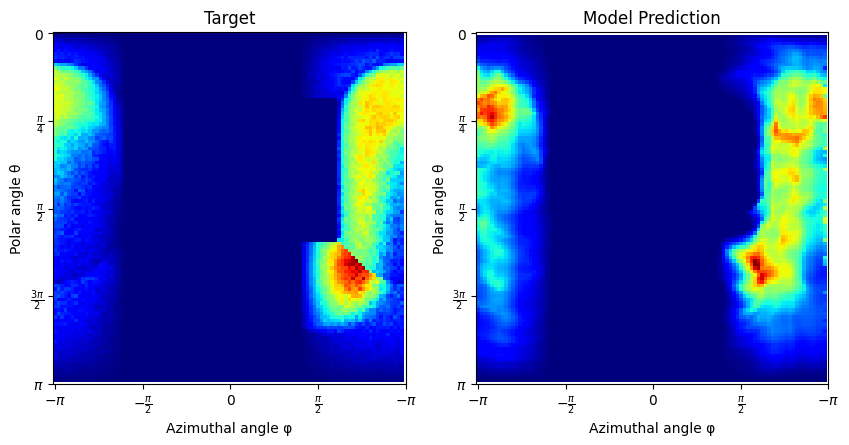

 90%|████████▉ | 44999/50000 [41:19<04:17, 19.39it/s]

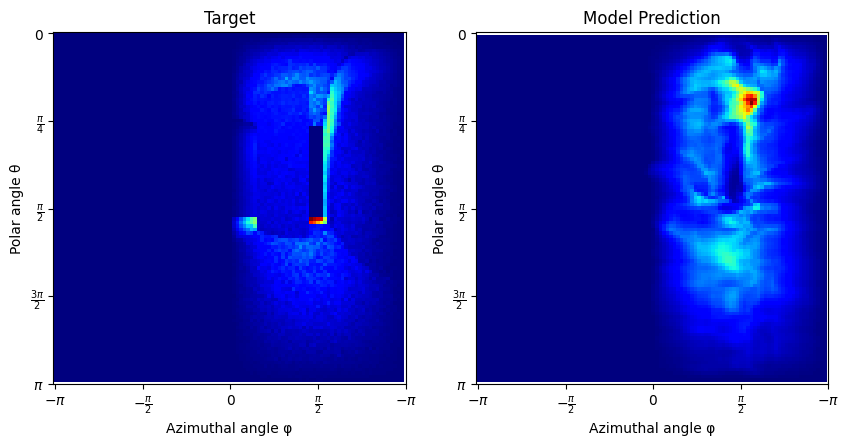

100%|██████████| 50000/50000 [45:36<00:00, 18.27it/s]


average generate_samples_time time 0.009749994139671326
average compute_gradient_time time 0.033007365913391117
average nan_check_clip_time time 0.0005994581508636475
average optimizer_time time 9.889602661132813e-09


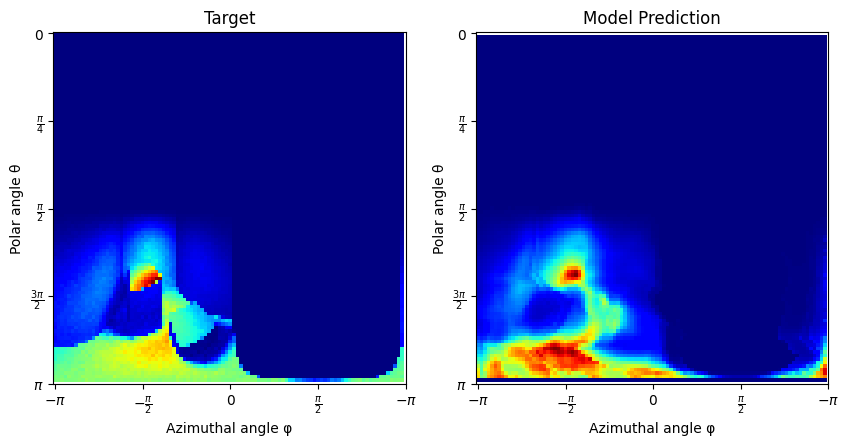

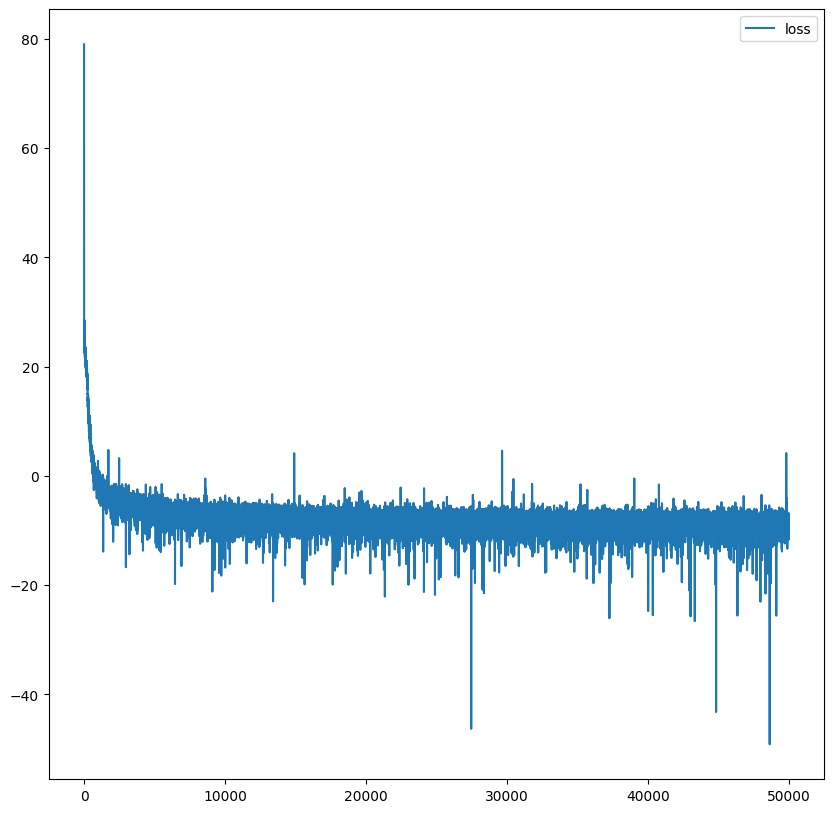

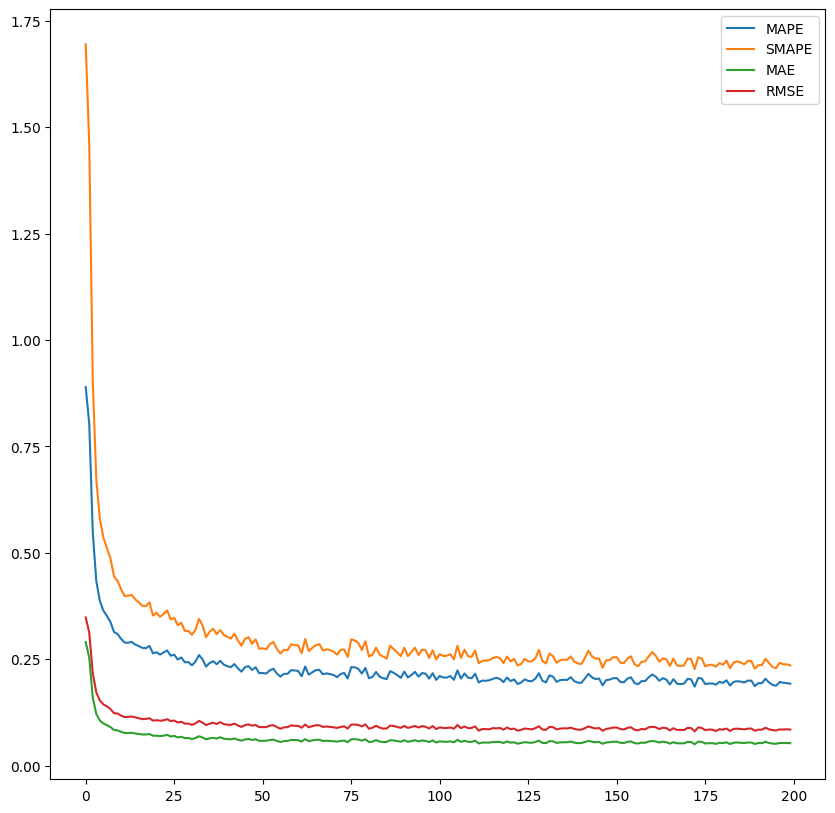

In [11]:
### cbox full

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid= True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = True,

    grid_resolutions=[4, 8, 12, 16],
    grid_levels=[2, 4, 6, 8],
    grid_scale_factors=[1.25, 1.5, 1.75, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "cbox_50k_full.pkl")
del(exp)

## Env sphere

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/10000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:110: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
100%|██████████| 10000/10000 [05:54<00:00, 28.19it/s]
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


average generate_samples_time time 0.007277474355697632
average compute_gradient_time time 0.025256793332099913
average nan_check_clip_time time 0.0005660674571990967
average optimizer_time time 4.1532516479492186e-08


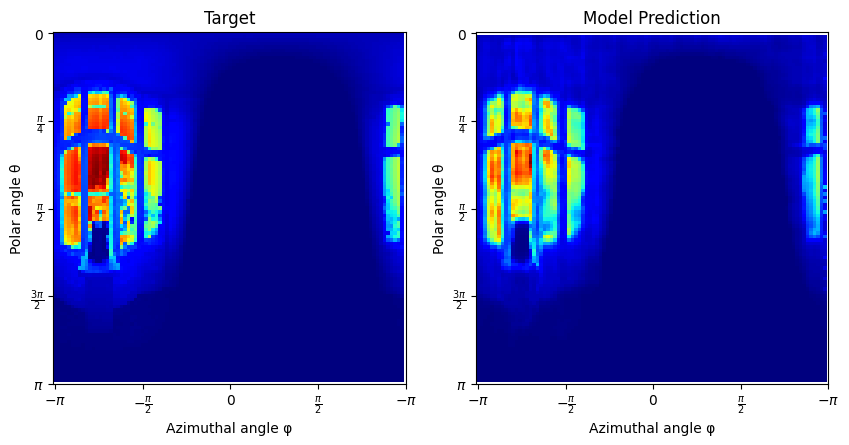

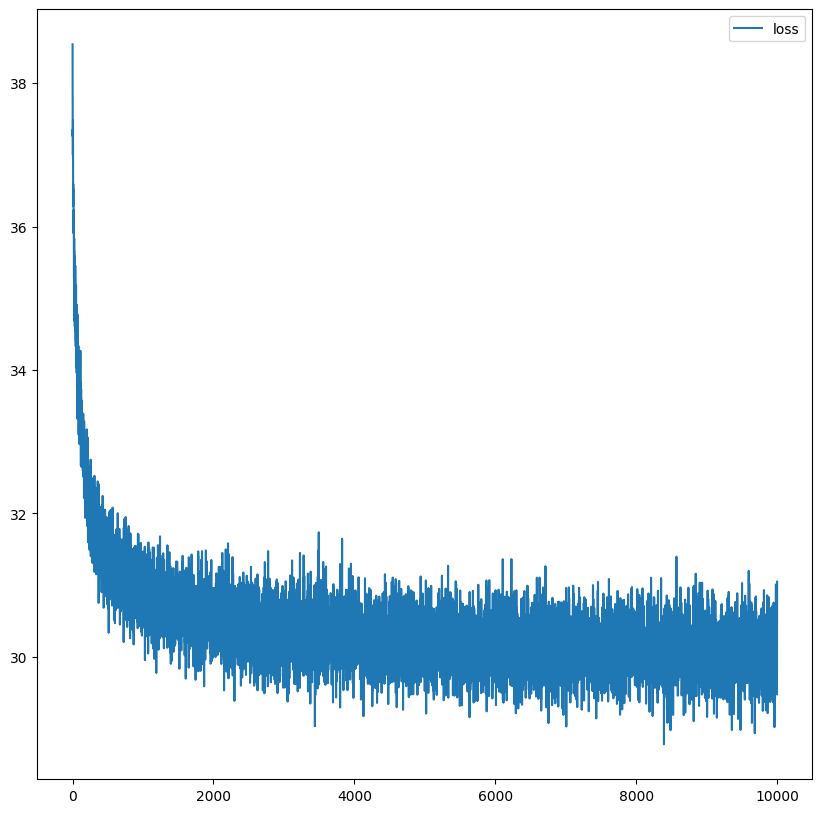

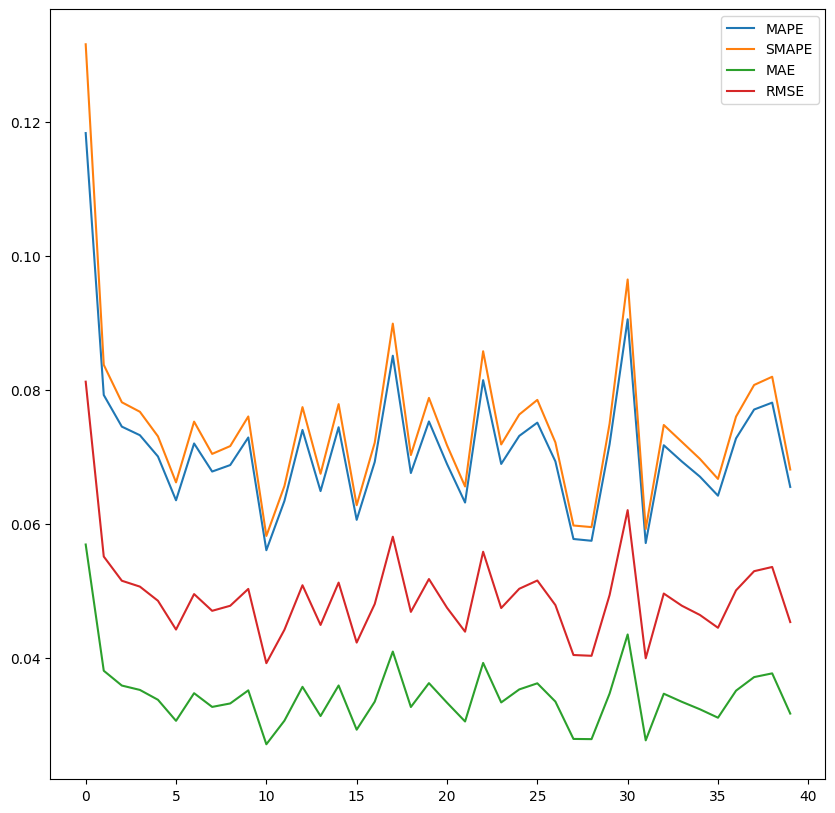

In [11]:
### Enc sphere example

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'env_scene_sphere',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4, 

    do_normal_encoding = True,
    do_in_dir_encoding = False,
    do_pos_encoding    = False,

    pos_is_hash_grid= False,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 10000,
    bounces=2, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "env_sphere_1k_example.pkl")
del(exp)

# Experiment compares OLD

In [14]:
### new model test

model = load_Experiment("new_model_2_cbox_inverted_light_uniform_prior_25k_light_traced.pkl")

exps =      [model, 
             ]
labels =    ["model", 
             ]

target_dir = "../../thesis_assets/images/tests"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 4, spp = 8)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref=True, 
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.98632735 0.97319144 0.95181954]
[0. 0. 0.]
Rendering path traced
MAPE: 0.4543851315975189
NaNs: False
Infs: False
[0.9873495  0.97745615 0.9598232 ]
[0. 0. 0.]
----
Rendering model
MAPE: 0.23743049800395966
NaNs: False
Infs: False
[0.98972154 0.98163205 0.96709096]
[0. 0. 0.]
Visualizing reference distribution of point #1
Visualizing dist of model for point #1
Visualizing reference distribution of point #2
Visualizing dist of model for point #2


In [15]:
### Kitchen One-blob vs hashgrid

kitchen_one_blob = load_Experiment("prior_compare_kitchen_one_blob_light_trace_10k.pkl")
kitchen_hash_grid = load_Experiment("prior_compare_kitchen_hash_grid_light_trace_10k.pkl")

exps =      [kitchen_one_blob, kitchen_hash_grid]
labels =    ["one blob", "hash grid"]

rCtx = Context(bounces = 6, spp = 32)

patch_anchors = [[270, 395], [1100, 450]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

target_dir = "../../thesis_assets/images/kitchen_oneblob_vs_hashgrid"


compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=2, 
                      target_dir=target_dir,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    include_path_traced=True, 
    ref_spp=8,
    save_ref=True,
    use_saved_ref=True, 
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=2,
    patch_outline_width = 2,
    tonemap = True,
    gamma_correct=True,  
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

using device: cuda
using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.9728715 0.9728715 0.9728715]
[0.00846976 0.00828997 0.00821678]
Rendering path traced
MAPE: 0.2031889110803604
NaNs: False
Infs: False
[0.9988666  0.9988662  0.99886596]
[0. 0. 0.]
----
Rendering one blob
MAPE: 0.1956586390733719
NaNs: False
Infs: False
[0.9999898 0.9999898 0.9999898]
[0. 0. 0.]
Rendering hash grid
MAPE: 0.20015473663806915
NaNs: False
Infs: False
[0.99996704 0.99996704 0.99996704]
[0. 0. 0.]


KeyboardInterrupt: 

In [34]:
# Kitchen 25k vs 50k

kitchen_25k = load_Experiment("kitchen_light_trace_25k.pkl")
kitchen_50k = load_Experiment("kitchen_light_trace_50k.pkl")

exps =      [kitchen_25k, kitchen_50k]
labels =    ["kitchen_25k", "kitchen_50k"]

rCtx = Context(bounces = 6, spp = 4)

patch_anchors = [[270, 395], [1100, 450]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

target_dir = "../../thesis_assets/images/kitchen_50k"

compare_experiments( experiments=exps, 
                        labels=labels, 
                        render_context=rCtx, 
                        ref_spp = 4, 
                        include_path_traced=True, 
                        target_dir=target_dir,
                        save_ref=True,
                        use_saved_ref=True, 
                        patch_anchors=patch_anchors, 
                        patch_dims=patch_dims, 
                        patch_colors=patch_colors,
                        rect_line_width=1,
                        tonemap = True, 
                        patch_has_outline=True)

using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.9728715 0.9728715 0.9728715]
[0.00308529 0.00302371 0.00299647]
Rendering path traced
MAPE: 0.4700162410736084
NaNs: False
Infs: False
[0.99970466 0.99970466 0.9997046 ]
[0. 0. 0.]
----


d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:53: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_x, x) - 1


Rendering kitchen_25k
MAPE: 0.36301448941230774
NaNs: False
Infs: False
[0.99980444 0.99980444 0.99980444]
[0. 0. 0.]
Rendering kitchen_50k
MAPE: 0.34983253479003906
NaNs: False
Infs: False
[0.9999956  0.99999464 0.9999929 ]
[0. 0. 0.]


array([[[0.5072448 , 0.5004306 , 0.4968408 ],
        [0.544155  , 0.5372317 , 0.53323084],
        [0.52189785, 0.5167483 , 0.51384914],
        ...,
        [0.47925195, 0.4700372 , 0.46505907],
        [0.4336341 , 0.41321388, 0.39830002],
        [0.51709324, 0.49585092, 0.4805927 ]],

       [[0.55839765, 0.5528132 , 0.5501684 ],
        [0.53066474, 0.5228399 , 0.5192231 ],
        [0.5295267 , 0.523408  , 0.52020013],
        ...,
        [0.4902931 , 0.48011655, 0.47489175],
        [0.47854015, 0.4719929 , 0.4685279 ],
        [0.5163556 , 0.5087247 , 0.5048578 ]],

       [[0.5331947 , 0.524334  , 0.5194744 ],
        [0.503949  , 0.49668863, 0.49297473],
        [0.532013  , 0.5244341 , 0.52083975],
        ...,
        [0.47033828, 0.45329472, 0.44315052],
        [0.43419737, 0.42061004, 0.41260165],
        [0.48280808, 0.4729017 , 0.46746135]],

       ...,

       [[0.40474507, 0.39416513, 0.38980493],
        [0.39031124, 0.38106933, 0.37748832],
        [0.35063022, 0

In [ ]:
### Test Experiment and template to create new ones

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=False,
    encode_pos_each_flow = True,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 1000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

run_experiment(setup, training_context, "test_exp_run.pkl")

using device: cuda


  0%|          | 0/20000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:85: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
100%|██████████| 20000/20000 [35:05<00:00,  9.50it/s]
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


average generate_samples_time time 0.0053103589415550235
average compute_gradient_time time 0.032941079342365266
average nan_check_clip_time time 0.0006262107253074646
average optimizer_time time 2.182722091674805e-08


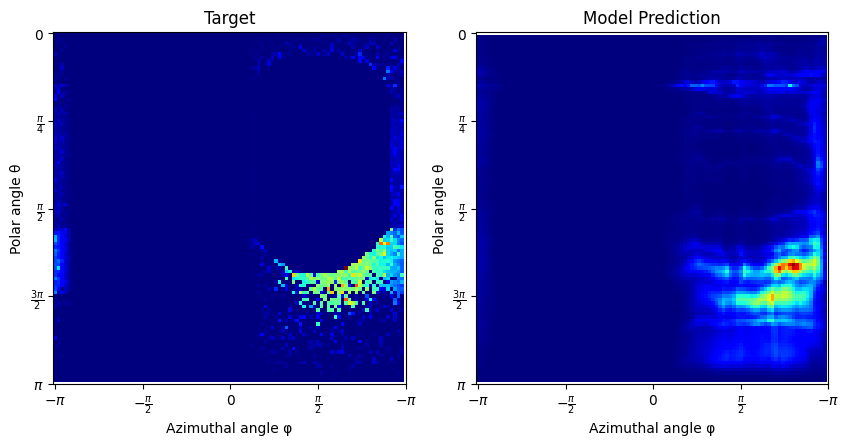

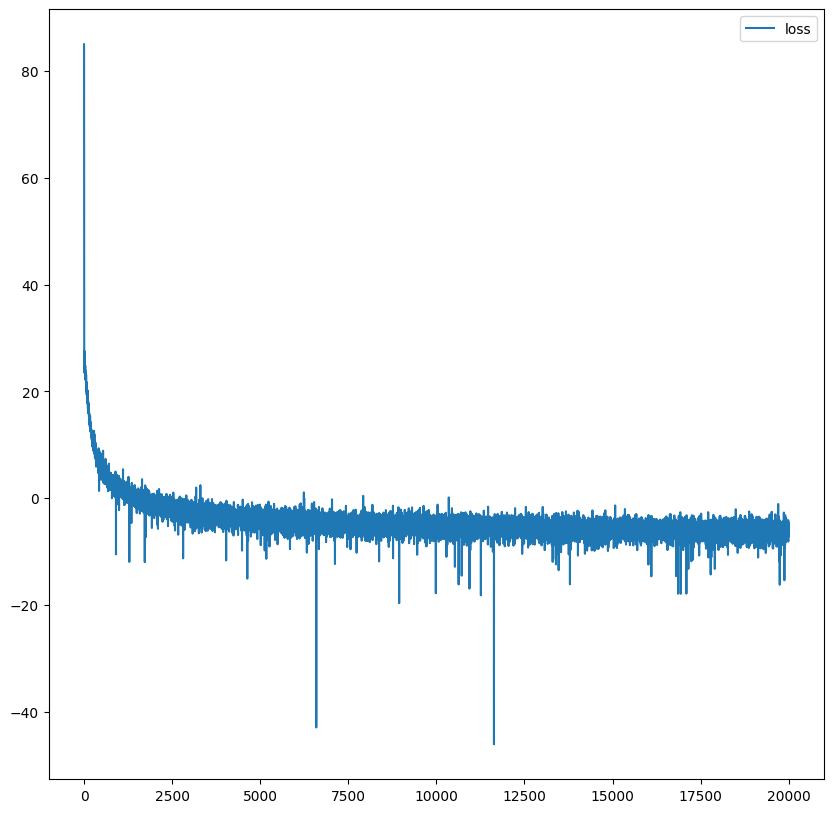

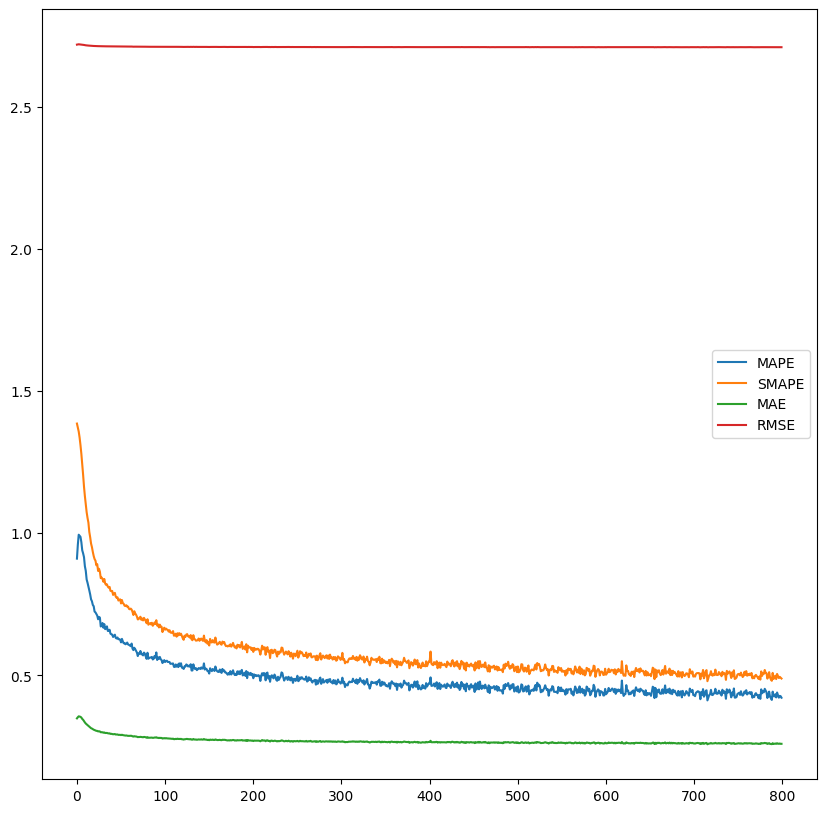

Experiment(setup=ExperimentSetup(coordinate_system=<CoordinateSystem.Spherical: (1,)>, prior_str='cosine', scene_name='cbox', num_flows=4, num_bins=16, hidden_units=64, hidden_layers=4, do_normal_encoding=True, do_in_dir_encoding=True, do_pos_encoding=True, pos_is_hash_grid=False, encode_pos_each_flow=True, latent_to_hashgrid=False, do_scaling_grid_sizes=False, grid_resolutions=[], grid_levels=[], grid_scale_factors=[]), trained_iterations=20000, sample_gen_strategy='light_tracing', sample_model=True, losses=array([85.03553772, 54.14964294, 40.21133423, ..., -6.6872673 ,
       -6.19485426, -5.70686531], shape=(20000,)), tracked_errors=True, tracked_error_every=25, mape_list=array([0.91061896, 0.95950115, 0.99485362, 0.9911148 , 0.98737431,
       0.96852702, 0.93998903, 0.92914742, 0.91576481, 0.88385868,
       0.86773491, 0.83714569, 0.82579565, 0.81277549, 0.79894221,
       0.78469729, 0.76736325, 0.76060647, 0.74757338, 0.74299979,
       0.72413874, 0.7214877 , 0.71600956, 0.710

In [ ]:
### Cbox one blob 20k

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid      = False,
    encode_pos_each_flow  = True,
    latent_to_hashgrid    = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 20000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

run_experiment(setup, training_context, "")

In [13]:
### MIS aware compare spaceship

no_mis = load_Experiment("Spaceship_no_mis_aware_25k.pkl")
mis  = load_Experiment("Spaceship_mis_aware_25k.pkl")

exps =      [no_mis, mis]
labels =    ["no_mis", "mis"]

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

rCtx = Context(bounces = 6, spp = 8)
target_dir = "../../thesis_assets/images/spaceship"

compare_error_metrics(
    experiments=exps,
    labels=labels, 
    target_dir=target_dir,
    error_metric='MAPE',
    smooth_lines=True, 
    transparent_unsmoothed=True)

compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    include_path_traced=False, 
    ref_spp=8,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = False, 
    patch_has_outline=True)

Rendering reference


KeyboardInterrupt: 

In [11]:
### Prior compare inv cbox

uniform = load_Experiment("cbox_inverted_light_uniform_prior_25k_light_traced.pkl")
cosine  = load_Experiment("cbox_inverted_light_cosine_prior_25k_light_traced.pkl")

exps =      [uniform, cosine]
labels =    ["Uniform_prior", "Cosine_weighted_prior"]


target_dir = "../../thesis_assets/images/tests"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=2, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 16)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=256,
    save_ref=False,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = False, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

# compute_point_distributions(
#     experiments=exps, 
#     labels=labels, 
#     points=points, 
#     ref_image=ref_image,
#     target_dir=target_dir,
#     patch_colors=patch_colors, 
#     rect_line_width=8, 
# )

Rendering reference


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.002633417..1.9324236].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.8374859].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..5.0024233].


Rendering path traced
MAPE: 0.395632266998291
NaNs: False
Infs: False
[5.0024233 3.814479  2.8931248]
[0. 0. 0.]
----


RuntimeError: dr.if_stmt(): encountered an exception (see above).

In [ ]:
### One blob vs hash grid compare inv cbox

one_blob         = load_Experiment("cbox_inverted_light_one_blob_20k_light_traced.pkl")
single_grid      = load_Experiment("cbox_inverted_light_hash_grid_20k_light_traced.pkl")



exps =      [one_blob, single_grid,]
labels =    ["one blob", "hash grid"]

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

rCtx = Context(bounces = 6, spp = 32)
target_dir = "../../thesis_assets/images/one_blob_vs_hashgrid_inv_cbox"

compare_error_metrics(
    experiments=exps,
    labels=labels, 
    target_dir=target_dir,
    error_metric='MAPE',
    smooth_lines=True, 
    transparent_unsmoothed=True)

# compare_experiments( 
#     experiments=exps, 
#     labels=labels, 
#     render_context=rCtx, 
#     include_path_traced=False, 
#     target_dir=target_dir,
#     patch_anchors=patch_anchors, 
#     patch_dims=patch_dims, 
#     patch_colors=patch_colors,
#     rect_line_width=1,
#     tonemap = False, 
#     patch_has_outline=True)

In [ ]:
### single vs multiple hash grids compare inv cbox

single_grid      = load_Experiment("cbox_hash_grid_20k_light_traced.pkl")
multiple_grids   = load_Experiment("cbox_mult_hash_grid_4_flows_20k_light_trace.pkl")



exps =      [single_grid, multiple_grids,]
labels =    ["Single grid", "multiple grids"]

rCtx = Context(bounces = 6, spp = 32)
target_dir = "../../thesis_assets/images/single_vs_mult_grids"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=2, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 16)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=256,
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = False, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..50.0].


Rendering reference


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0006467949..1.1695704].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..50.0].


Rendering path traced
MAPE: [0.127092]
----


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.00018827326..10.175176].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..6.0723314].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..50.0].


Rendering Single grid
MAPE: [0.32764]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.00018136213..7.5889564].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..6.457931].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..50.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..50.0].


Rendering multiple grids
MAPE: [0.309399]
Visualizing reference distribution of point #1
Visualizing dist of Single grid for point #1
Visualizing dist of multiple grids for point #1
Visualizing reference distribution of point #2
Visualizing dist of Single grid for point #2
Visualizing dist of multiple grids for point #2


In [ ]:
### staggered vs full size hash grids compare inv cbox


multiple         = load_Experiment("special_model_hashgrid_setups_staggered_slight_10k.pkl")


exps =      [multiple, ]
labels =    ["aggr stagger latent"]

rCtx = Context(bounces = 6, spp = 32)
target_dir = "../../thesis_assets/images/special_model_test"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=2, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 16)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=256,
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = False, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.00093262125..1.1251698].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..27.901403].


Rendering reference


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [7.018182e-05..4.7290826].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.6616833].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..35.021545].


Rendering path traced
MAPE: [0.591694]
----


RuntimeError: dr.if_stmt(): encountered an exception (see above).

In [71]:
### Hash grid sizes


single = load_Experiment("hashgrid_setups_single_10k.pkl")
multiple         = load_Experiment("hashgrid_setups_multiple_10k.pkl")
multiple_latent         = load_Experiment("hashgrid_setups_multiple_latent_encode_10k.pkl")

exps =      [single, 
             multiple, 
             multiple_latent, 
             ]
labels =    ["single grid", 
             "multiple grids", 
             "multiple grids latent", 
             ]

target_dir = "../../thesis_assets/images/grids_test"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 8)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = False, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

# compute_point_distributions(
#     experiments=exps, 
#     labels=labels, 
#     points=points, 
#     ref_image=ref_image,
#     target_dir=target_dir,
#     patch_colors=patch_colors, 
#     rect_line_width=8, 
# )

{'nested': [{'degree': 4, 'n_dims_to_encode': 3, 'otype': 'SphericalHarmonics'},
            {'degree': 4, 'n_dims_to_encode': 3, 'otype': 'SphericalHarmonics'},
            {'n_dims_to_encode': 3, 'otype': 'Identity'}],
 'otype': 'Composite'}
------
{'nested': [{'n_dims_to_encode': 16, 'otype': 'Identity'},
            {'n_dims_to_encode': 16, 'otype': 'Identity'},
            {'base_resolution': 16,
             'interpolation': 'Linear',
             'log2_hashmap_size': 19,
             'n_dims_to_encode': 4,
             'n_features_per_level': 2,
             'n_levels': 8,
             'otype': 'Grid',
             'per_level_scale': 2.0,
             'type': 'Hash'}],
 'otype': 'Composite'}
------
35
using device: cuda


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0008761344..1.3441228].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..27.869312].


Rendering reference


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..9.143692].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..5.2226744].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..35.56526].


Rendering path traced
MAPE: [0.746079]
----


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..18.284903].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..6.141874].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..38906.04].


Rendering single grid
MAPE: [1.96852]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..7.8146276].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..12.364926].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..7796.5864].


Rendering multiple grids
MAPE: [0.711]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..10.857985].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..5.788415].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..27982.555].


Rendering multiple grids latent
MAPE: [0.864457]


In [26]:
### latent encoding long traing

not_latent = load_Experiment("hashgrid_setups_multiple_100k_lr_3e-4.pkl")
latent = load_Experiment("hashgrid_setups_multiple_latent_encode_100k_lr_3e-4.pkl")

exps =      [not_latent, 
             latent, 
             ]
labels =    ["not latent", 
             "latent", 
             ]

target_dir = "../../thesis_assets/images/latent_test"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=1, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 8)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=1,
    tonemap = False, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

using device: cuda
using device: cuda


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0008761344..1.3441228].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..27.869312].


Rendering reference


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..9.143692].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..5.2226744].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..35.56526].


Rendering path traced
MAPE: [0.746079]
----


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.00014051914..8.625024].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..9.3057995].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..289866.06].


Rendering not latent
MAPE: [4.49519]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [2.0918365e-05..6.717058].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..5.091005].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..192769.39].


Rendering latent
MAPE: [4.21827]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..27.869312].


Visualizing reference distribution of point #1
Visualizing dist of not latent for point #1
Visualizing dist of latent for point #1
Visualizing reference distribution of point #2
Visualizing dist of not latent for point #2
Visualizing dist of latent for point #2


In [66]:
### Complete staggered vs full size hash grids compare inv cbox


from numpy import true_divide


single = load_Experiment("hashgrid_setups_single_10k.pkl")

multiple         = load_Experiment("hashgrid_setups_multiple_10k.pkl")
slight_staggered = load_Experiment("hashgrid_setups_staggered_slight_10k.pkl")
aggr_staggered   = load_Experiment("hashgrid_setups_staggered_aggresive_10k.pkl")

multiple_latent         = load_Experiment("hashgrid_setups_multiple_latent_encode_10k.pkl")
slight_staggered_latent = load_Experiment("hashgrid_setups_staggered_slight_latent_encode_10k.pkl")
aggr_staggered_latent   = load_Experiment("hashgrid_setups_staggered_aggresive_latent_encode_10k.pkl")

exps =      [single, 
             multiple, 
             slight_staggered, 
             aggr_staggered, 
             multiple_latent, 
             slight_staggered_latent, 
             aggr_staggered_latent
             ]
labels =    ["single grid", 
             "multiple grids", 
             "slight stagger", 
             "aggr stagger",
             "multiple grids latent", 
             "slight stagger latent", 
             "aggr stagger latent"
             ]

target_dir = "../../thesis_assets/images/stagger_test"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=True, 
                      line_width=2, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 8)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

# ref_image = compare_experiments( 
#     experiments=exps, 
#     labels=labels, 
#     render_context=rCtx, 
#     width=width, 
#     height=height,
#     include_path_traced=True, 
#     ref_spp=2048,
#     save_ref=True,
#     target_dir=target_dir,
#     patch_anchors=patch_anchors, 
#     patch_dims=patch_dims, 
#     patch_colors=patch_colors,
#     rect_line_width=1,
#     tonemap = False, 
#     patch_has_outline=True)

# points = []
# for i in range(len(patch_anchors)):
#     point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
#     point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
#     points.append([point_x, point_y])

# compute_point_distributions(
#     experiments=exps, 
#     labels=labels, 
#     points=points, 
#     ref_image=ref_image,
#     target_dir=target_dir,
#     patch_colors=patch_colors, 
#     rect_line_width=8, 
# )

{'nested': [{'degree': 4, 'n_dims_to_encode': 3, 'otype': 'SphericalHarmonics'},
            {'degree': 4, 'n_dims_to_encode': 3, 'otype': 'SphericalHarmonics'},
            {'n_dims_to_encode': 3, 'otype': 'Identity'}],
 'otype': 'Composite'}
------
{'nested': [{'n_bins': 32, 'n_dims_to_encode': 1, 'otype': 'OneBlob'},
            {'n_dims_to_encode': 16, 'otype': 'Identity'},
            {'n_dims_to_encode': 16, 'otype': 'Identity'},
            {'base_resolution': 16,
             'interpolation': 'Linear',
             'log2_hashmap_size': 19,
             'n_dims_to_encode': 3,
             'n_features_per_level': 2,
             'n_levels': 8,
             'otype': 'Grid',
             'per_level_scale': 2.0,
             'type': 'Hash'}],
 'otype': 'Composite'}
------
35
using device: cuda
{'nested': [{'degree': 4, 'n_dims_to_encode': 3, 'otype': 'SphericalHarmonics'},
            {'degree': 4, 'n_dims_to_encode': 3, 'otype': 'SphericalHarmonics'},
            {'n_dims_to_encode

In [ ]:
### Stagger compares


single = load_Experiment("hashgrid_setups_single_50k.pkl")

multiple         = load_Experiment("hashgrid_setups_multiple_50k.pkl")
slight_staggered = load_Experiment("hashgrid_setups_staggered_slight_50k.pkl")
aggr_staggered   = load_Experiment("hashgrid_setups_staggered_aggresive_50k.pkl")

exps =      [single, 
             multiple, 
             slight_staggered, 
             aggr_staggered
             ]
labels =    ["single grid", 
             "multiple grids", 
             "slight stagger", 
             "aggresive stagger"
             ]

target_dir = "../../thesis_assets/images/stagger_compare_50k"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=2, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 16)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    save_ref=True,
    use_saved_ref=True, 
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=2,
    patch_outline_width=2, 
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

using device: cuda
using device: cuda
using device: cuda
using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.98632735 0.97319144 0.95181954]
[0. 0. 0.]
Rendering path traced
MAPE: 0.36672040820121765
NaNs: False
Infs: False
[0.9871071  0.9769752  0.95894927]
[0. 0. 0.]
----
Rendering single grid
MAPE: 0.19042576849460602
NaNs: False
Infs: False
[0.9999615  0.99996877 0.9996883 ]
[0. 0. 0.]
Rendering multiple grids
MAPE: 0.2010277509689331
NaNs: False
Infs: False
[0.99971133 0.99691015 0.9713251 ]
[0. 0. 0.]
Rendering slight stagger
MAPE: 0.19712793827056885
NaNs: False
Infs: False
[0.9999786  0.99995095 0.99990565]
[0. 0. 0.]
Rendering aggresive stagger
MAPE: 0.18520201742649078
NaNs: False
Infs: False
[0.9984531  0.9871226  0.96736455]
[0. 0. 0.]
Visualizing reference distribution of point #1
Visualizing dist of single grid for point #1
Visualizing dist of multiple grids for point #1
Visualizing dist of slight stagger for point #1
Visualizing dist of aggresive stagger fo

In [30]:
### latent compares



no_latent = load_Experiment("hashgrid_setups_multiple_100k_lr_3e-4.pkl")
latent = load_Experiment("hashgrid_setups_multiple_latent_encode_100k_lr_3e-4.pkl")

exps =      [no_latent, 
             latent
             ]
labels =    ["regular", 
             "latent encode"
             ]

target_dir = "../../thesis_assets/images/latent_compare"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=True, 
                      line_width=2, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 8)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=1024,
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=2,
    patch_outline_width=2, 
    tonemap = False, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

using device: cuda
using device: cuda


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..26.853624].


Rendering reference
NaNs: False
Infs: False
[26.853624 14.801108  8.060014]
[0. 0. 0.]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..6.6606736].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..5.721694].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..35.831936].


Rendering path traced
MAPE: [0.65683]
NaNs: False
Infs: False
[35.831936 19.784925 10.780926]
[0. 0. 0.]
----


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [7.394725e-05..7.777609].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..5.349491].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..107.18392].


Rendering regular
MAPE: [0.470174]
NaNs: False
Infs: False
[ 66.318756 107.18392   39.291935]
[0. 0. 0.]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [5.480555e-05..14.361969].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..5.1255994].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..6554.498].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..26.853624].


Rendering latent encode
MAPE: [0.565539]
NaNs: False
Infs: False
[6554.498    979.5011   115.50183]
[0. 0. 0.]
Visualizing reference distribution of point #1
Visualizing dist of regular for point #1
Visualizing dist of latent encode for point #1
Visualizing reference distribution of point #2
Visualizing dist of regular for point #2
Visualizing dist of latent encode for point #2


In [15]:
### Single vs multiple vs staggered grids 50k


single        = load_Experiment("hashgrid_setups_single_50k.pkl")
multiple      = load_Experiment("hashgrid_setups_multiple_50k.pkl")
smaller_grids = load_Experiment("hashgrid_setups_multiple_50k_smaller_grids.pkl")

exps =      [single, 
             multiple, 
             smaller_grids
             ]
labels =    ["single grid", 
             "multiple grids", 
             "smaller grids"
             ]

target_dir = "../../thesis_assets/images/mult_compare_50k"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=2, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 5, spp = 16)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref = True,
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=2,
    patch_outline_width=2, 
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

using device: cuda
using device: cuda
using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.98632735 0.97319144 0.95181954]
[0. 0. 0.]
Rendering path traced
MAPE: 0.3709501028060913
NaNs: False
Infs: False
[0.9867136  0.9763518  0.95789754]
[0. 0. 0.]
----
Rendering single grid
MAPE: 0.19399647414684296
NaNs: False
Infs: False
[0.99995905 0.99901813 0.9982553 ]
[0. 0. 0.]
Rendering multiple grids
MAPE: 0.2117786407470703
NaNs: False
Infs: False
[0.9996956 0.9998051 0.9981499]
[0. 0. 0.]
Rendering smaller grids
MAPE: 0.18961602449417114
NaNs: False
Infs: False
[0.99718213 0.9808278  0.9656853 ]
[0. 0. 0.]
Visualizing reference distribution of point #1


p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Visualizing dist of single grid for point #1
Visualizing dist of multiple grids for point #1
Visualizing dist of smaller grids for point #1
Visualizing reference distribution of point #2
Visualizing dist of single grid for point #2
Visualizing dist of multiple grids for point #2
Visualizing dist of smaller grids for point #2


In [11]:
### Latent compare 150k


multiple   = load_Experiment("hashgrid_setups_multiple_150k_lr_1e-3.pkl")
latent_enc = load_Experiment("hashgrid_setups_multiple_latent_encode_150k_lr_1e-3.pkl")

exps =      [
             multiple, 
             latent_enc
             ]
labels =    ["multiple grids", 
             "latent encoded"
             ]

target_dir = "../../thesis_assets/images/latent_compare_150k"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=2, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 5, spp = 16)

patch_anchors = [[50, 80], [360, 380]]
patch_dims = [[100, 100], [100, 100]]
patch_colors = ['red', 'blue']

width = 512
height = 512

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    width=width, 
    height=height,
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref = True,
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=2,
    patch_outline_width=2, 
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

compute_point_distributions(
    experiments=exps, 
    labels=labels, 
    points=points, 
    ref_image=ref_image,
    target_dir=target_dir,
    patch_colors=patch_colors, 
    rect_line_width=8, 
)

using device: cuda
using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.98632735 0.97319144 0.95181954]
[0. 0. 0.]
Rendering path traced
MAPE: 0.3709501028060913
NaNs: False
Infs: False
[0.9867136  0.9763518  0.95789754]
[0. 0. 0.]
----


d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:53: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_x, x) - 1


Rendering multiple grids
MAPE: 0.18621708452701569
NaNs: False
Infs: False
[0.98893523 0.97501373 0.9556074 ]
[0. 0. 0.]
Rendering latent encoded
MAPE: 0.3277258574962616
NaNs: False
Infs: False
[0.9999986  0.9999969  0.99999404]
[0. 0. 0.]
Visualizing reference distribution of point #1


p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Visualizing dist of multiple grids for point #1
Visualizing dist of latent encoded for point #1
Visualizing reference distribution of point #2
Visualizing dist of multiple grids for point #2
Visualizing dist of latent encoded for point #2


In [22]:
### Spaceship compare 50k

spaceship_cosine   = load_Experiment("spaceship_cosine_50k.pkl")
latent_enc_uniform = load_Experiment("spaceship_uniform_50k.pkl")

exps =      [
             spaceship_cosine, 
             latent_enc_uniform
             ]
labels =    ["spaceship cosine", 
             "spaceship uniform"
             ]

target_dir = "../../thesis_assets/images/spaceship"

compare_error_metrics(exps, 
                      labels, 
                      'MAPE', 
                      logx=False, 
                      logy=False, 
                      line_width=2, 
                      target_dir=target_dir,
                      # start_index = 500,
                      smooth_lines = True,
                      transparent_unsmoothed=True)


rCtx = Context(bounces = 6, spp = 1, emitter_sampling=True)

# patch_anchors = [[50, 80], [360, 380]]
# patch_dims = [[100, 100], [100, 100]]
# patch_colors = ['red', 'blue']

patch_anchors = []
patch_dims = []
patch_colors = []

ref_image = compare_experiments( 
    experiments=exps, 
    labels=labels, 
    render_context=rCtx, 
    include_path_traced=True, 
    ref_spp=128,
    use_saved_ref = True,
    save_ref=True,
    target_dir=target_dir,
    patch_anchors=patch_anchors, 
    patch_dims=patch_dims, 
    patch_colors=patch_colors,
    rect_line_width=2,
    patch_outline_width=2, 
    tonemap = True,
    gamma_correct=True, 
    patch_has_outline=True)

points = []
for i in range(len(patch_anchors)):
    point_x = patch_anchors[i][0] + patch_dims[i][0] / 2
    point_y = patch_anchors[i][1] + patch_dims[i][1] / 2
    points.append([point_x, point_y])

# compute_point_distributions(
#     experiments=exps, 
#     labels=labels, 
#     points=points, 
#     ref_image=ref_image,
#     target_dir=target_dir,
#     patch_colors=patch_colors, 
#     rect_line_width=8, 
# )

using device: cuda


d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda
Rendering reference
NaNs: False
Infs: False
[0.96742594 0.89863616 0.890253  ]
[0.01618956 0.01618854 0.01653314]
Rendering path traced
MAPE: 0.558559000492096
NaNs: False
Infs: False
[0.99608636 0.9926382  0.9933866 ]
[0. 0. 0.]
----
Rendering spaceship cosine
MAPE: 0.43301984667778015
NaNs: False
Infs: False
[0.9963531 0.9963121 0.9966907]
[0. 0. 0.]
Rendering spaceship uniform
MAPE: 0.4426088333129883
NaNs: False
Infs: False
[0.99649894 0.996459   0.9968186 ]
[0. 0. 0.]


# Experiments OLD

using device: cuda


  0%|          | 0/20000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:85: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
100%|██████████| 20000/20000 [36:22<00:00,  9.17it/s]
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


average generate_samples_time time 0.010622352731227875
average compute_gradient_time time 0.03269373061656952
average nan_check_clip_time time 0.0006044925451278686
average optimizer_time time 2.4330615997314454e-08


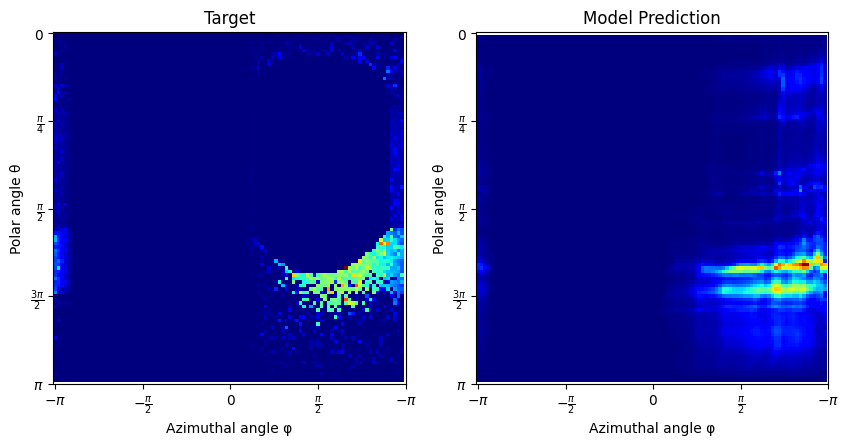

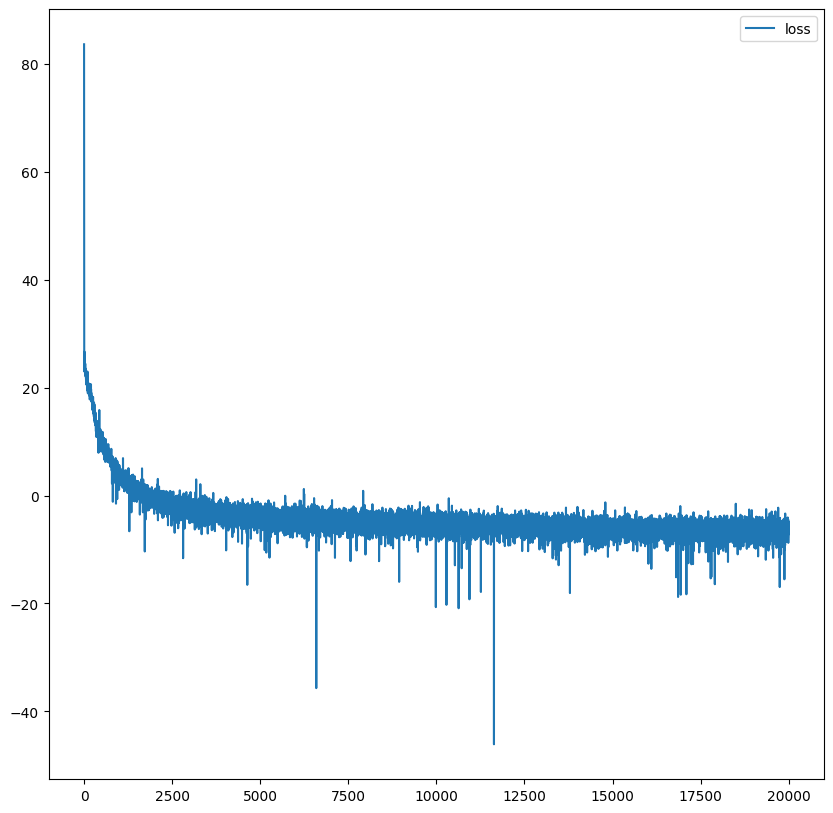

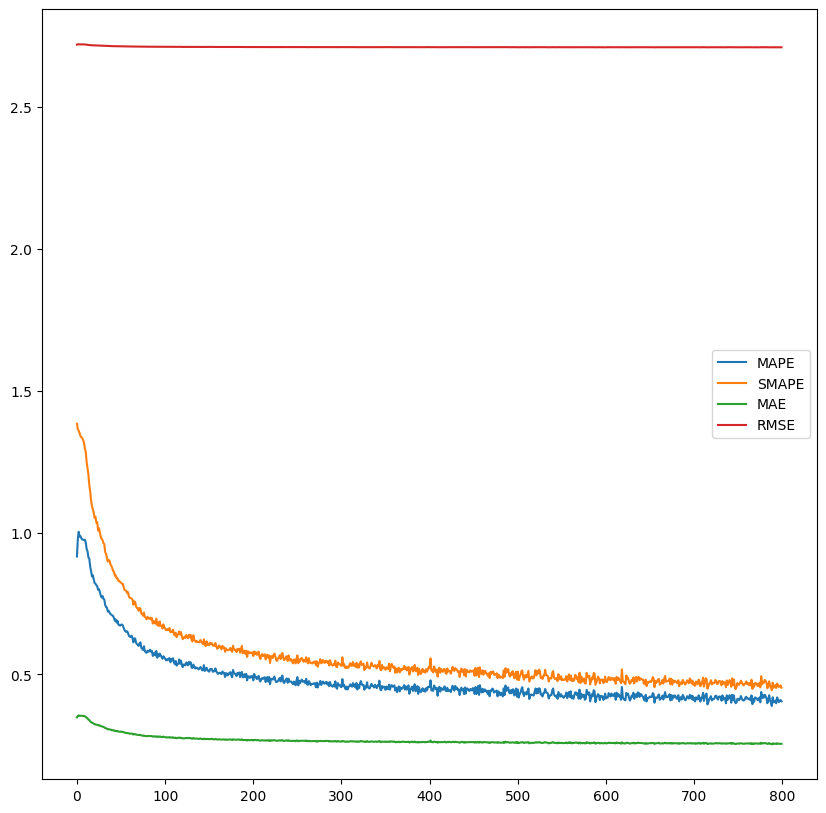

In [10]:
### Multiple hashgrids (large grids)

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid      = True,
    encode_pos_each_flow  = True,
    latent_to_hashgrid    = False,
    do_scaling_grid_sizes = True,

    grid_resolutions=   [16] * 4,
    grid_levels=        [8] * 4,
    grid_scale_factors= [2.0] * 4,
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 20000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

exp = run_experiment(setup, training_context, "cbox_mult_hash_grid_4_flows_20k_light_trace.pkl")
del(exp)

using device: cuda


100%|██████████| 20000/20000 [36:59<00:00,  9.01it/s]


average generate_samples_time time 0.00764574168920517
average compute_gradient_time time 0.031105463969707488
average nan_check_clip_time time 0.0006033926606178284
average optimizer_time time 2.4056434631347657e-08


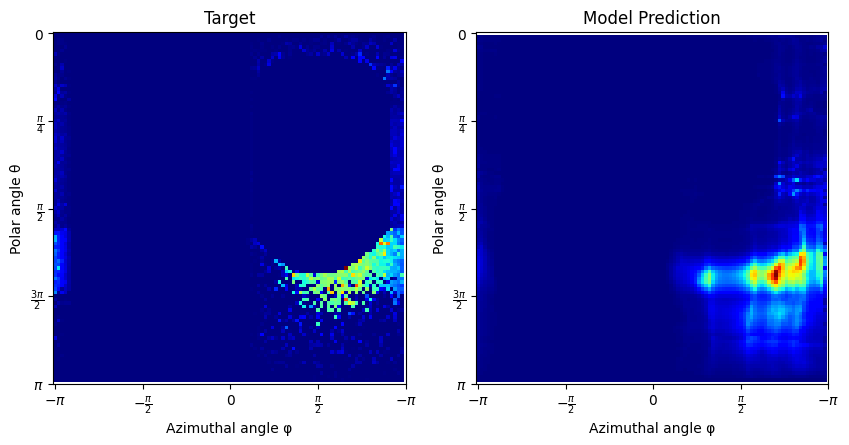

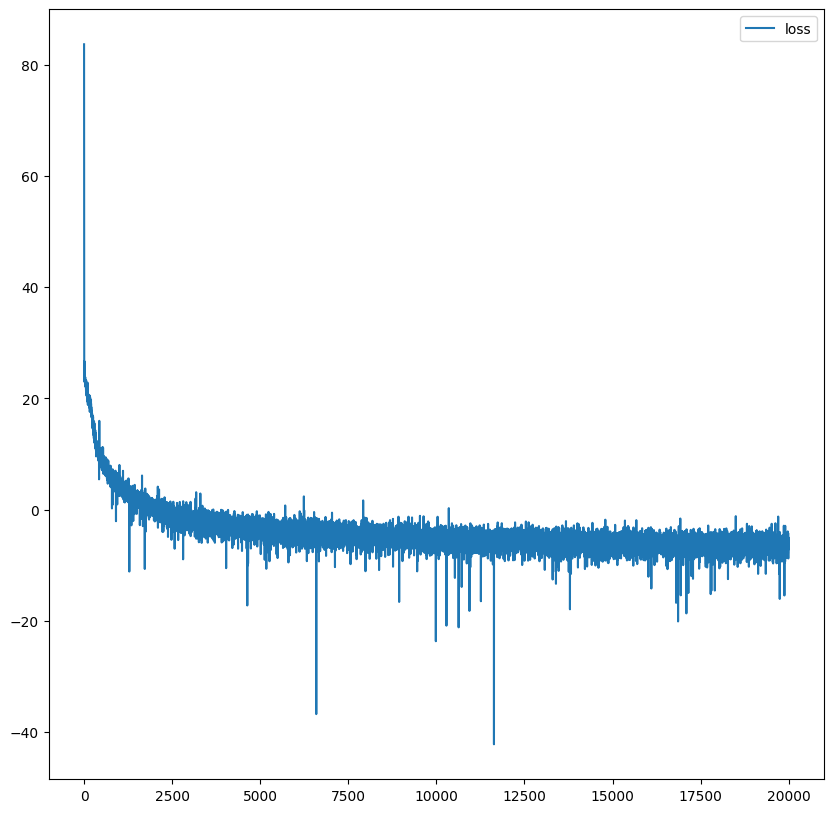

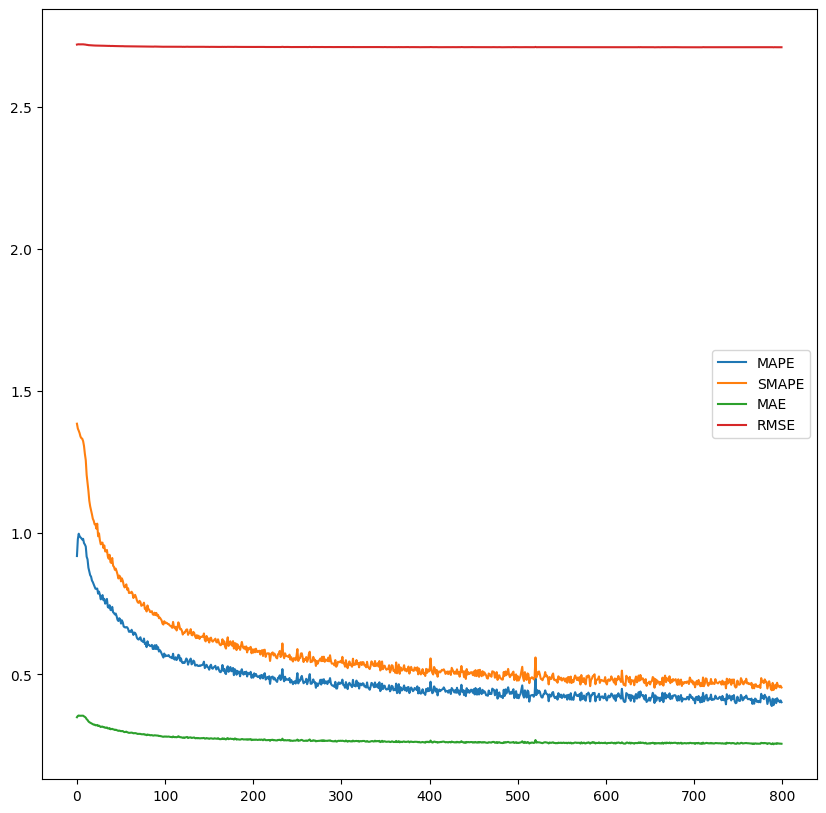

In [11]:
### Multiple hashgrids (small grids)

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid      = True,
    encode_pos_each_flow  = True,
    latent_to_hashgrid    = False,
    do_scaling_grid_sizes = True,

    grid_resolutions=   [8] * 4,
    grid_levels=        [4] * 4,
    grid_scale_factors= [2.0] * 4,
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 20000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

exp = run_experiment(setup, training_context, "cbox_mult_hash_grid_small_4_flows_20k_light_trace.pkl")
del(exp)

using device: cuda


100%|██████████| 20000/20000 [1:09:16<00:00,  4.81it/s]


average generate_samples_time time 0.01814176243543625
average compute_gradient_time time 0.0631178974032402
average nan_check_clip_time time 0.0008292156934738159
average optimizer_time time 3.190040588378906e-08


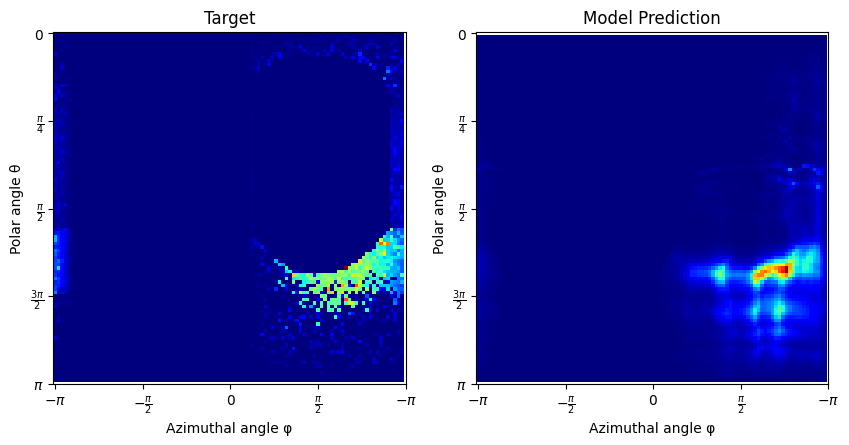

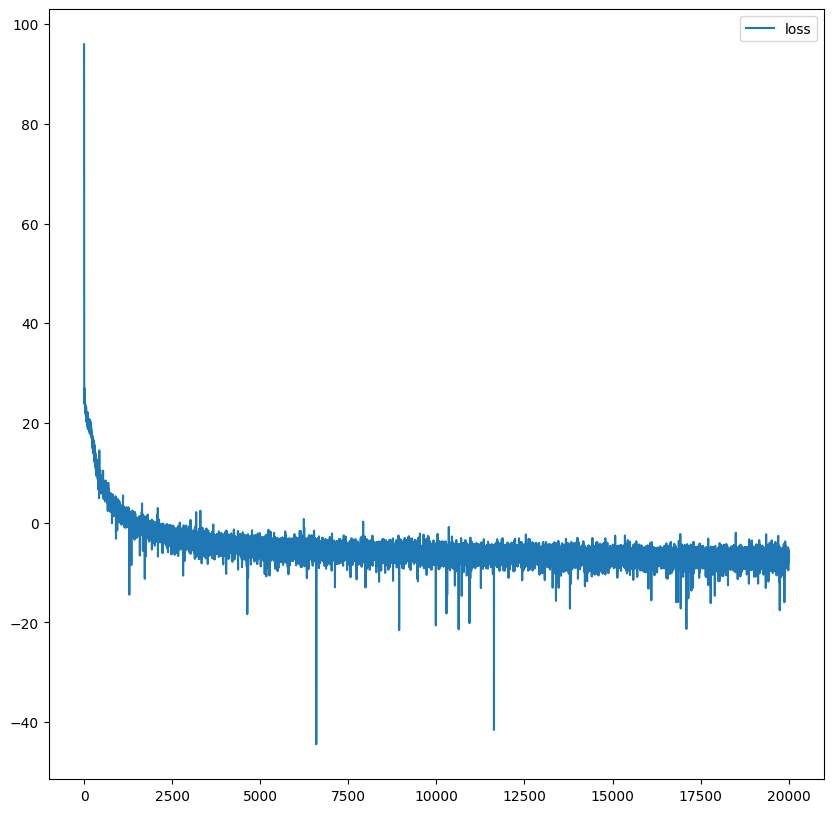

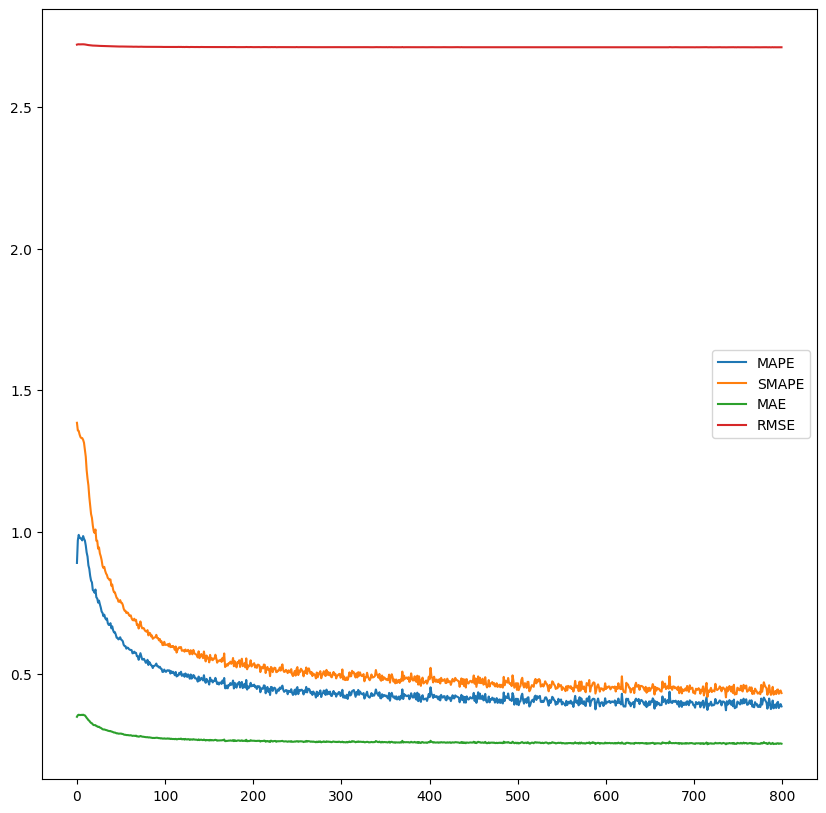

In [12]:
### Multiple hashgrids more flows (large grids)

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox',

    num_flows = 8,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid      = True,
    encode_pos_each_flow  = True,
    latent_to_hashgrid    = False,
    do_scaling_grid_sizes = True,

    grid_resolutions= [16] * 8,
    grid_levels= [8] * 8,
    grid_scale_factors= [2.0] * 8,
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 20000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

exp = run_experiment(setup, training_context, "cbox_mult_hash_grid_8_flows_20k_light_trace.pkl")
del(exp)

using device: cuda


100%|██████████| 20000/20000 [1:05:50<00:00,  5.06it/s]


average generate_samples_time time 0.010855512118339539
average compute_gradient_time time 0.06213700367212296
average nan_check_clip_time time 0.0008058351039886474
average optimizer_time time 2.350807189941406e-08


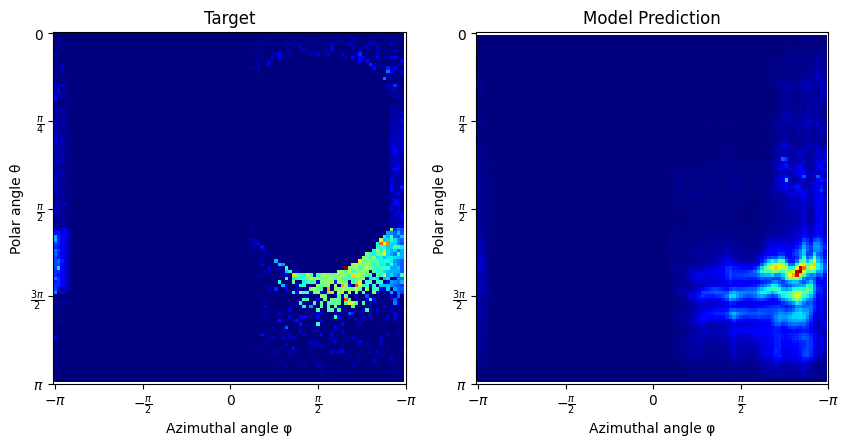

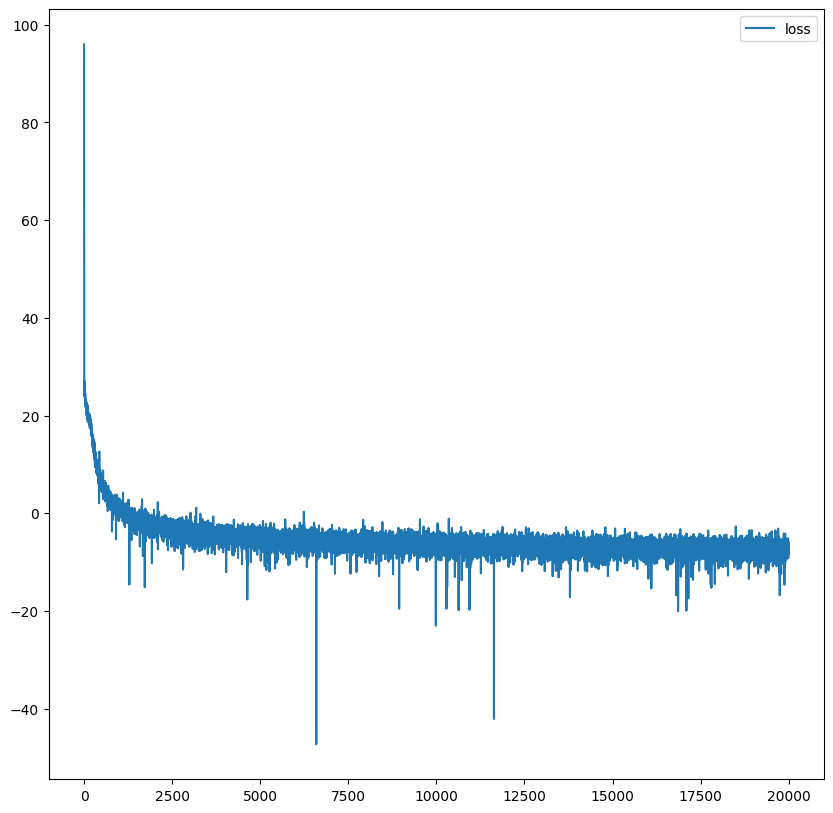

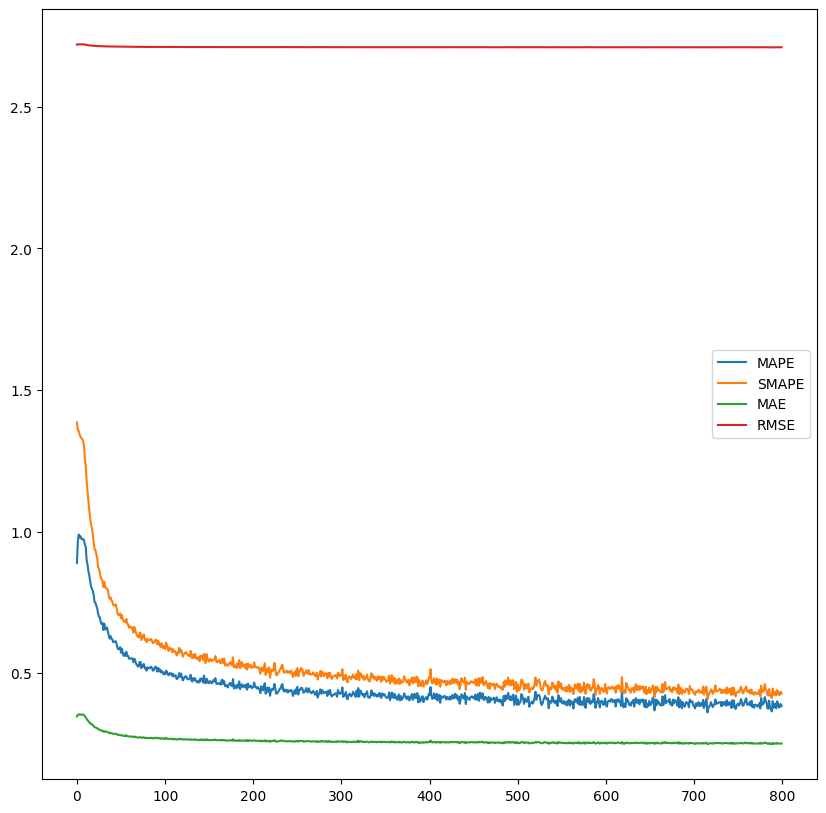

In [13]:
### Multiple hashgrids more flows (small grids)

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox',

    num_flows = 8,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid      = True,
    encode_pos_each_flow  = True,
    latent_to_hashgrid    = False,
    do_scaling_grid_sizes = True,

    grid_resolutions=[8] * 8,
    grid_levels=[4] * 8,
    grid_scale_factors=[2.0] * 8,
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 20000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

exp = run_experiment(setup, training_context, "cbox_mult_hash_grid_small_8_flows_20k_light_trace.pkl")
del(exp)

using device: cuda


100%|██████████| 20000/20000 [48:14<00:00,  6.91it/s] 


average generate_samples_time time 0.016042736399173738
average compute_gradient_time time 0.03251862548589706
average nan_check_clip_time time 0.0006492244124412537
average optimizer_time time 2.130270004272461e-08


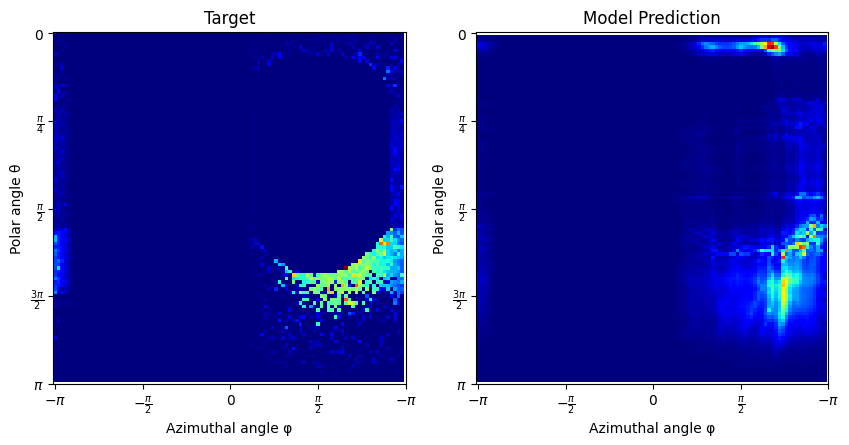

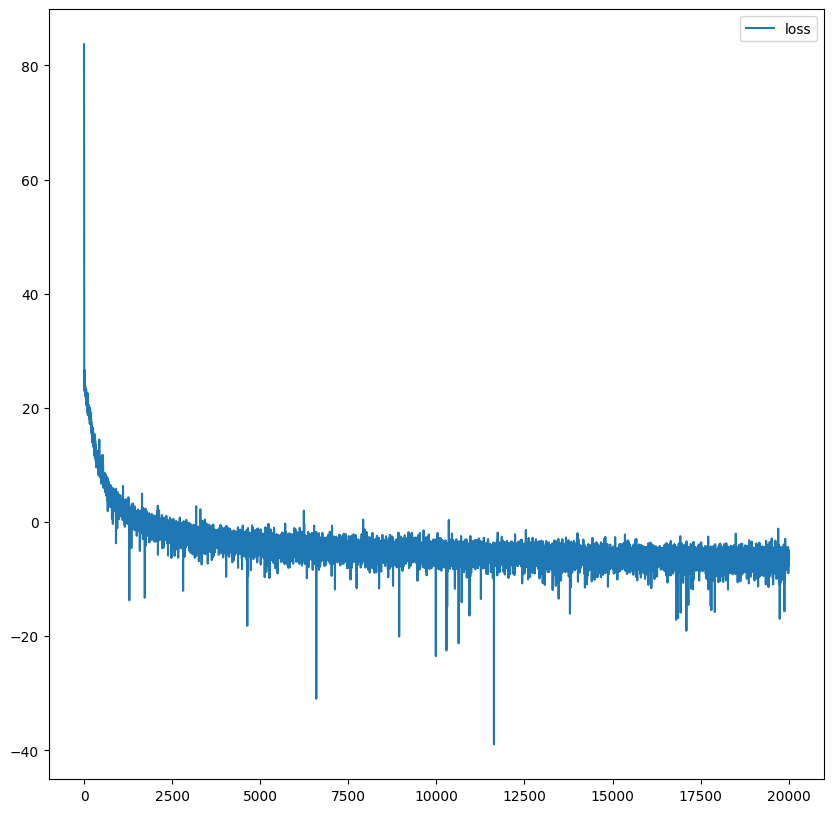

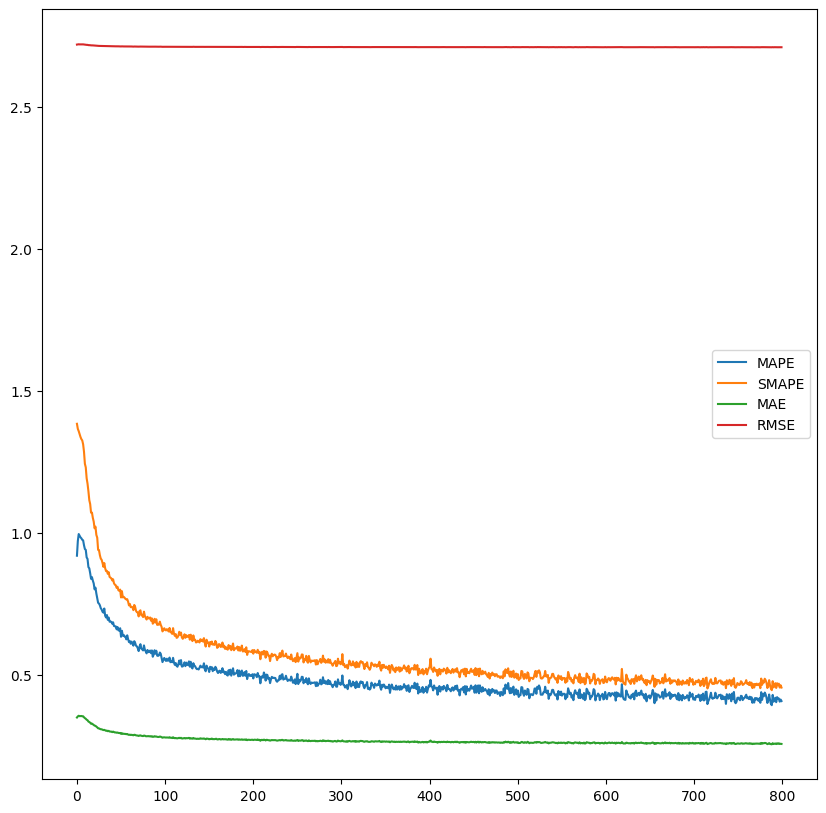

In [14]:
### Staggered hashgrids (slight stagger)

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid      = True,
    encode_pos_each_flow  = True,
    latent_to_hashgrid    = False,
    do_scaling_grid_sizes = True,

    grid_resolutions=[10, 12, 14, 16],
    grid_levels=[5, 6, 7, 8],
    grid_scale_factors=[1.0, 1.33, 1.66, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 20000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

exp = run_experiment(setup, training_context, "cbox_slight_stagger_20k_light_trace.pkl")
del(exp)

using device: cuda


100%|██████████| 20000/20000 [50:32<00:00,  6.60it/s] 


average generate_samples_time time 0.01766658116579056
average compute_gradient_time time 0.03307935189008713
average nan_check_clip_time time 0.0006528073310852051
average optimizer_time time 2.619028091430664e-08


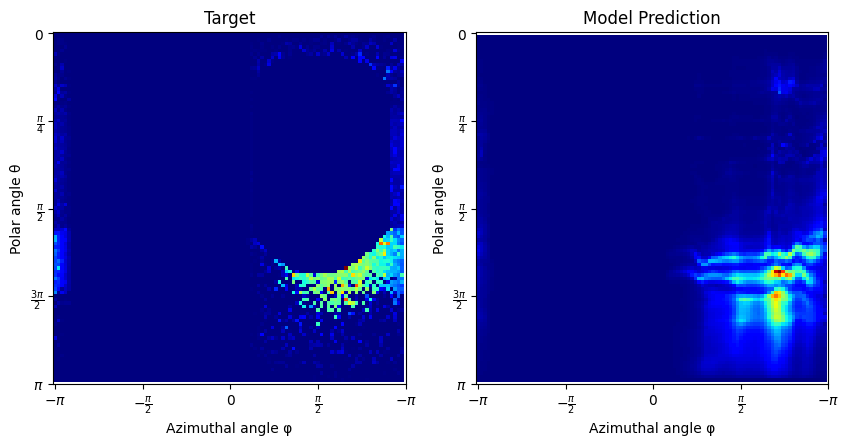

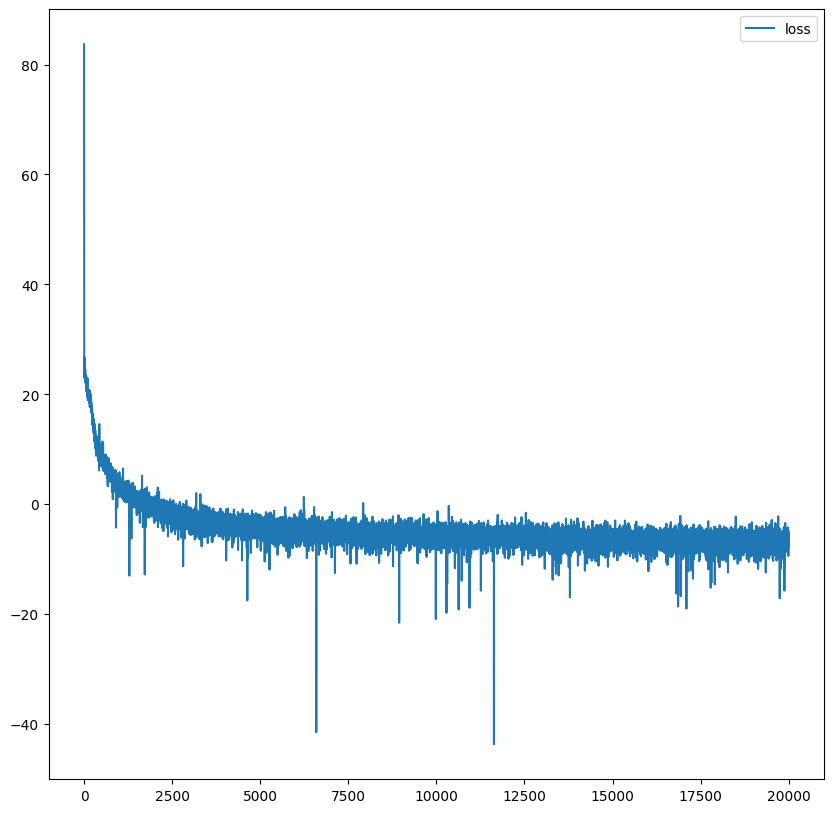

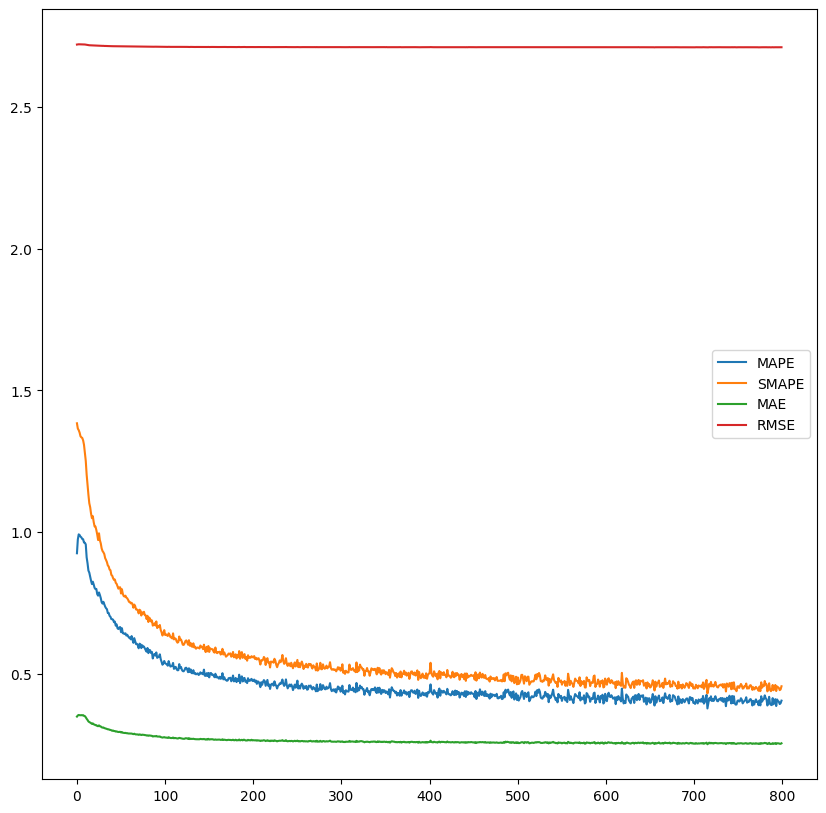

In [15]:
### Staggered hashgrids (aggresive stagger)

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid      = True,
    encode_pos_each_flow  = True,
    latent_to_hashgrid    = False,
    do_scaling_grid_sizes = True,

    grid_resolutions=[4, 8, 12, 16],
    grid_levels=[2, 4, 6, 8],
    grid_scale_factors=[1.0, 1.33, 1.66, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 20000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

exp = run_experiment(setup, training_context, "cbox_aggresive_stagger_20k_light_trace.pkl")
del(exp)

using device: cuda


100%|██████████| 20000/20000 [57:52<00:00,  5.76it/s] 


average generate_samples_time time 0.02328419771194458
average compute_gradient_time time 0.03474822577238083
average nan_check_clip_time time 0.0005854113221168518
average optimizer_time time 2.4497509002685545e-08


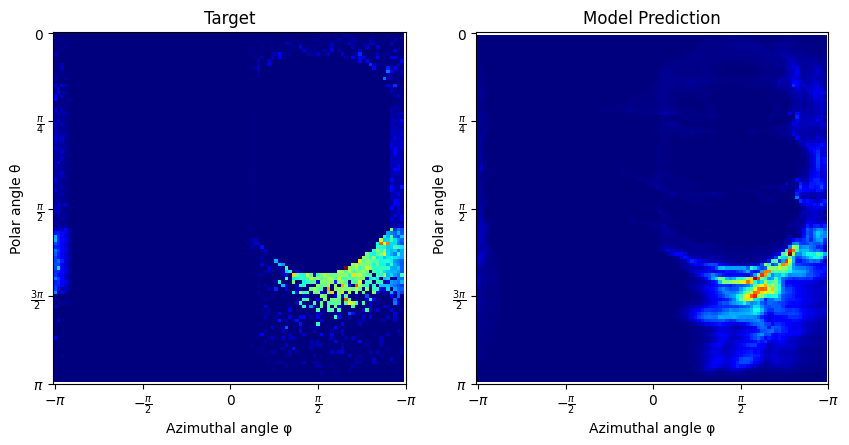

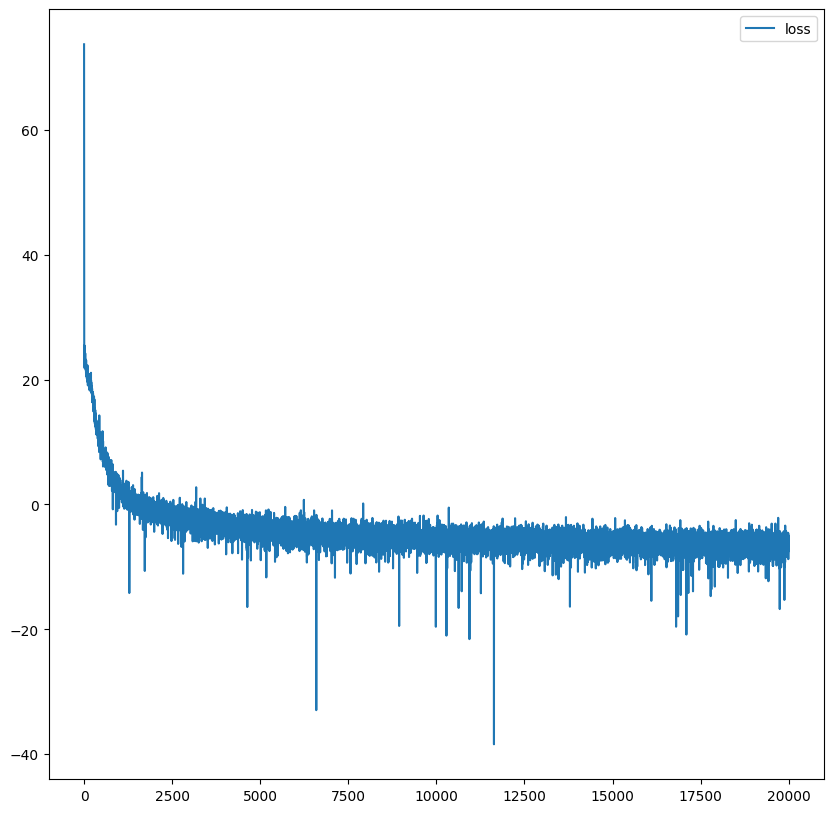

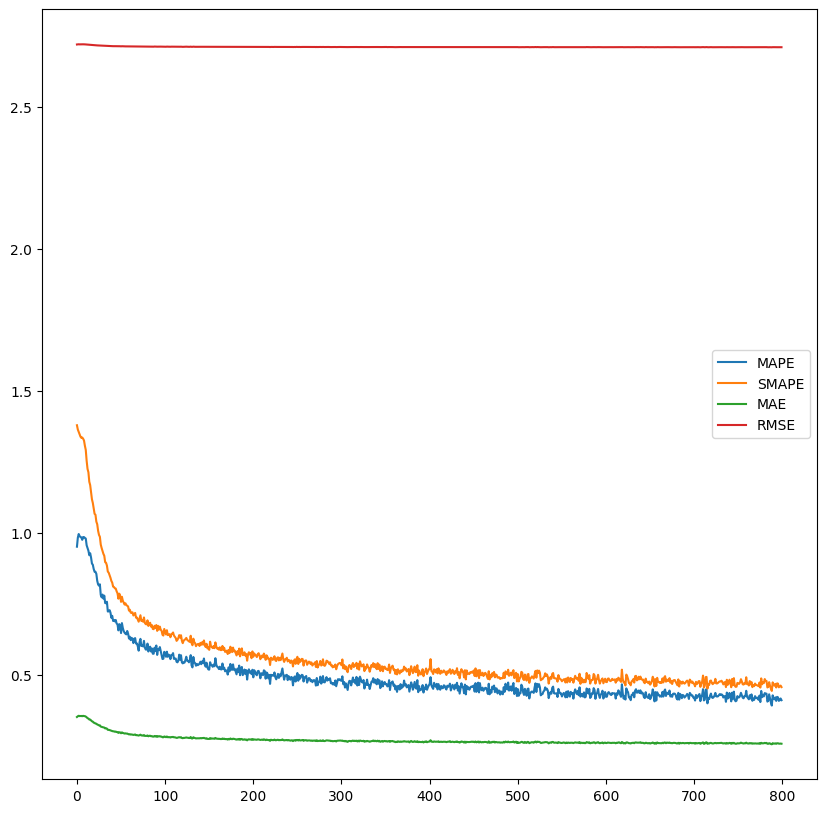

In [16]:
### Latent encoded multiple hashgrids

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid      = True,
    encode_pos_each_flow  = True,
    latent_to_hashgrid    = True,
    do_scaling_grid_sizes = True,

    grid_resolutions=   [16] * 4,
    grid_levels=        [8] * 4,
    grid_scale_factors= [2.0] * 4,
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 20000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

exp = run_experiment(setup, training_context, "cbox_latent_enc_multiple_grids_20k_light_trace.pkl")
del(exp)

using device: cuda


100%|██████████| 20000/20000 [49:19<00:00,  6.76it/s] 


average generate_samples_time time 0.01392930189371109
average compute_gradient_time time 0.03367979267835617
average nan_check_clip_time time 0.000623632287979126
average optimizer_time time 2.32696533203125e-08


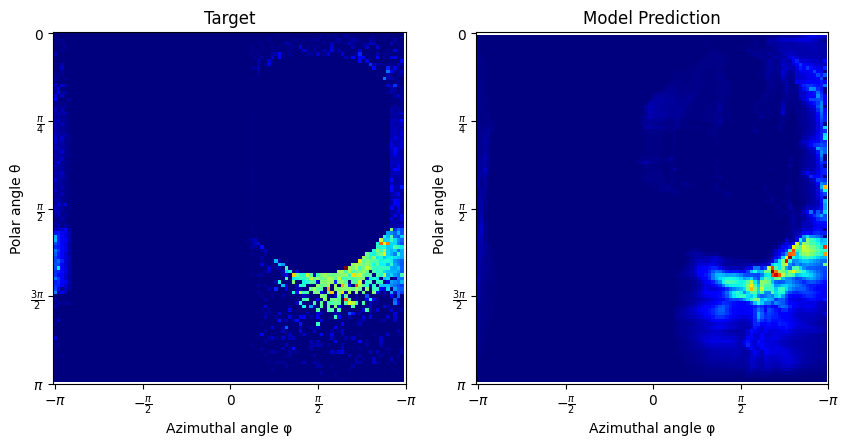

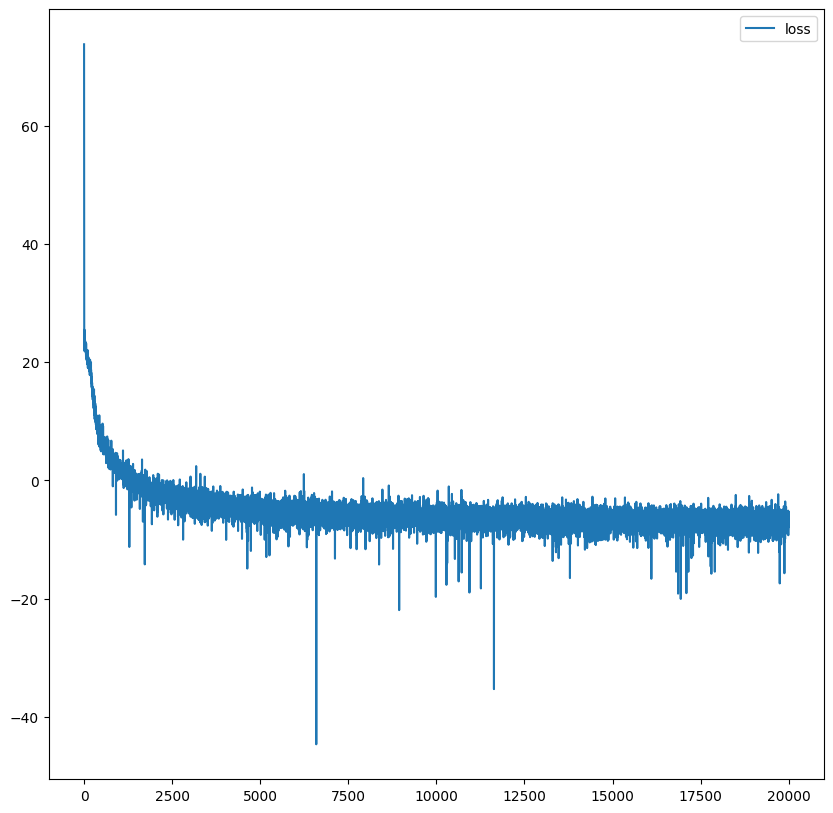

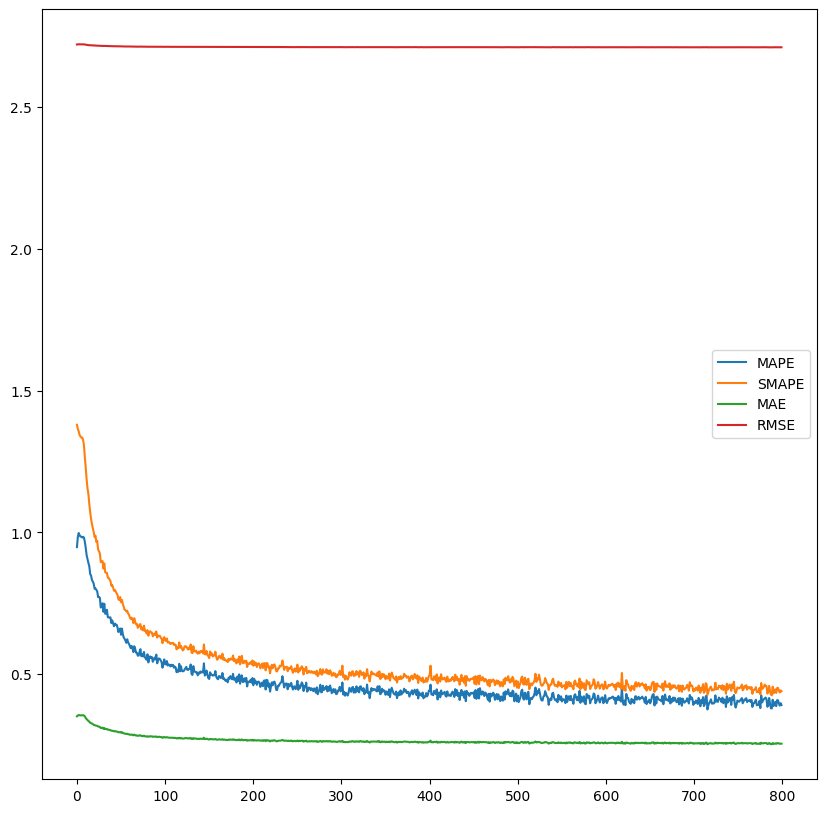

In [17]:
### Latent encoded staggered hashgrids

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid      = True,
    encode_pos_each_flow  = True,
    latent_to_hashgrid    = True,
    do_scaling_grid_sizes = True,

    grid_resolutions=   [4, 8, 12, 16],
    grid_levels=        [2, 4, 6, 8],
    grid_scale_factors= [1.0, 1.33, 1.66, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 20000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

exp = run_experiment(setup, training_context, "cbox_latent_enc_staggered_aggr_20k_light_trace.pkl")
del(exp)

## -----

d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda


  0%|          | 0/20000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:85: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
100%|██████████| 20000/20000 [34:33<00:00,  9.64it/s]
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


average generate_samples_time time 0.006056747841835022
average compute_gradient_time time 0.030018526804447176
average nan_check_clip_time time 0.0005808794021606445
average optimizer_time time 2.5510787963867187e-08


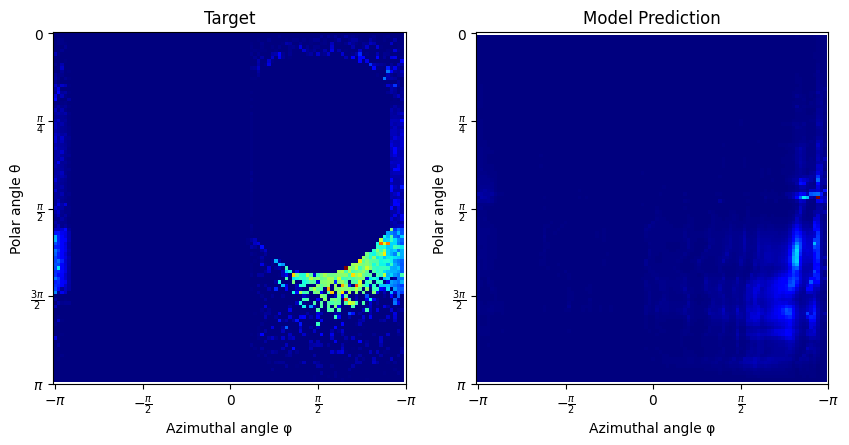

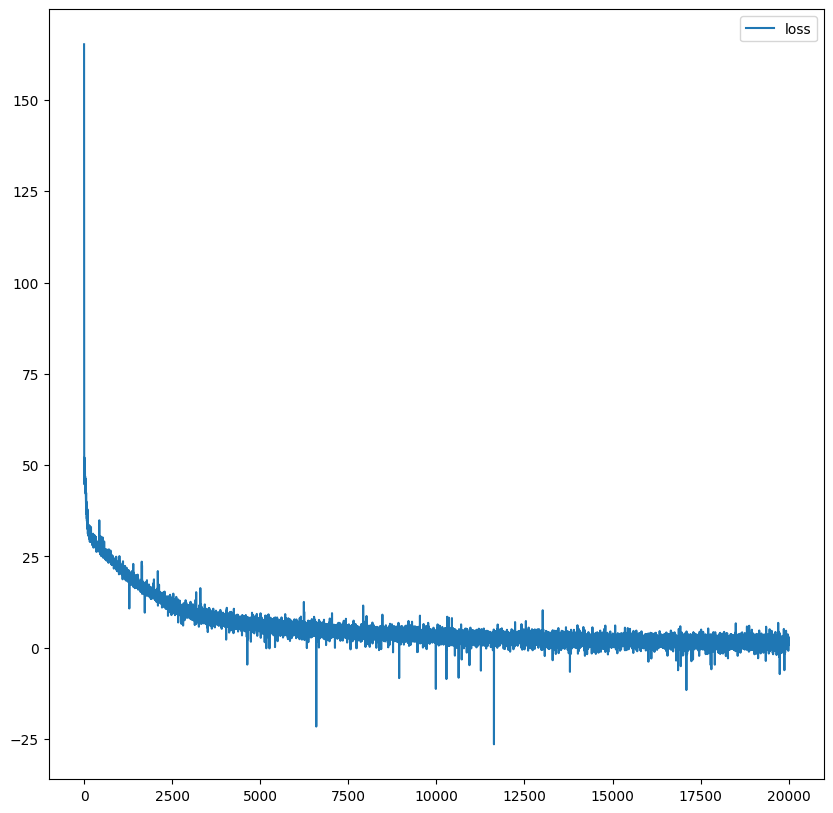

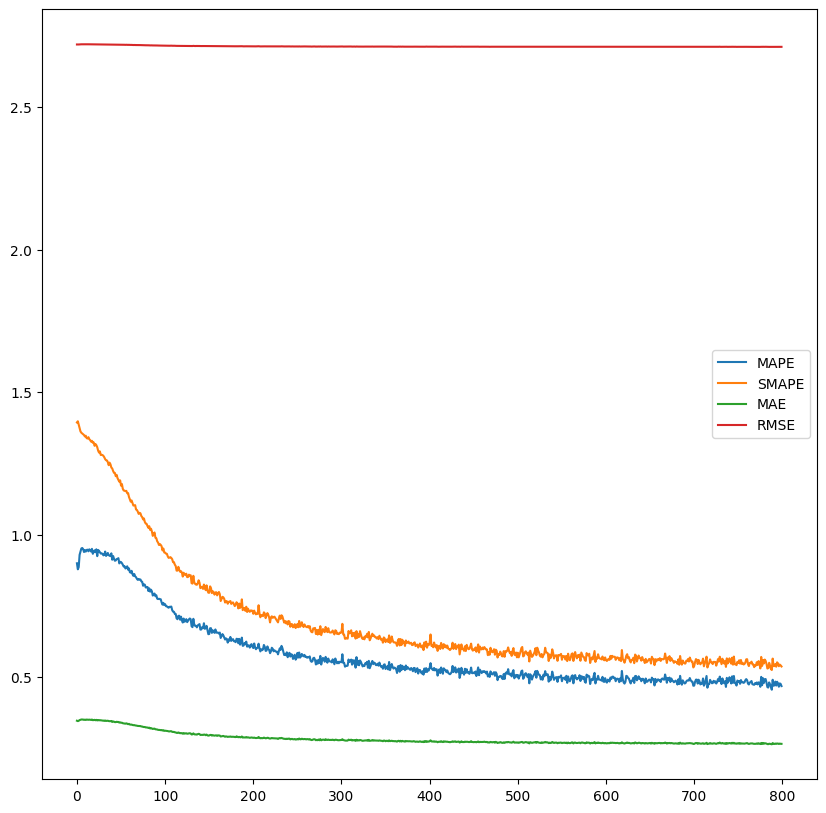

Experiment(setup=ExperimentSetup(coordinate_system=<CoordinateSystem.Spherical: (1,)>, prior_str='uniform', scene_name='cbox', num_flows=4, num_bins=16, hidden_units=64, hidden_layers=4, do_normal_encoding=True, do_in_dir_encoding=True, do_pos_encoding=True, pos_is_hash_grid=True, encode_pos_each_flow=False, latent_to_hashgrid=False, do_scaling_grid_sizes=False, grid_resolutions=[], grid_levels=[], grid_scale_factors=[]), trained_iterations=20000, sample_gen_strategy='light_tracing', sample_model=True, losses=array([165.21385193,  98.77266693,  73.46422577, ...,   0.78977865,
         1.40011644,   1.61924195], shape=(20000,)), tracked_errors=True, tracked_error_every=25, mape_list=array([0.89992636, 0.87870049, 0.88645005, 0.92949891, 0.94096678,
       0.9518854 , 0.95350552, 0.94950485, 0.9394238 , 0.94580114,
       0.9409489 , 0.94688225, 0.94749582, 0.94199342, 0.94883978,
       0.94568372, 0.94114608, 0.950562  , 0.93310231, 0.94008672,
       0.94534719, 0.93908358, 0.94898719

In [11]:
### Cbox uniform prior

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='uniform',
    # prior_str='cosine',
    scene_name = 'cbox',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 20000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

run_experiment(setup, training_context, "cbox_20k_uniform_prior.pkl")

using device: cuda


100%|██████████| 20000/20000 [35:08<00:00,  9.48it/s]


average generate_samples_time time 0.006643698000907898
average compute_gradient_time time 0.031026734232902527
average nan_check_clip_time time 0.0005715198159217834
average optimizer_time time 2.142190933227539e-08


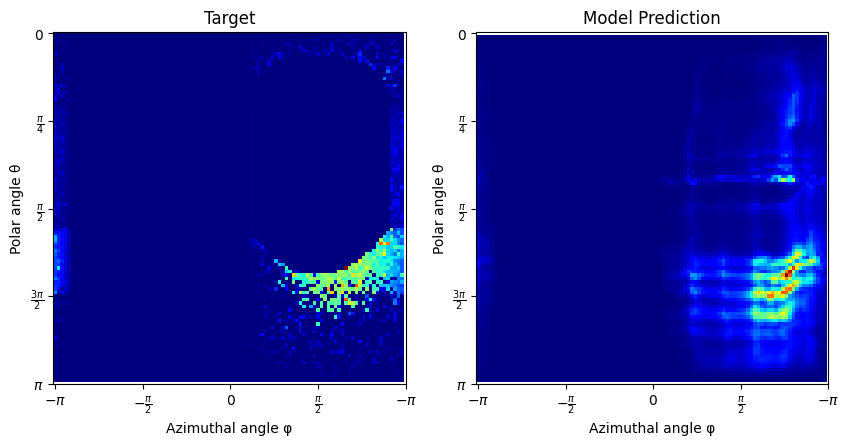

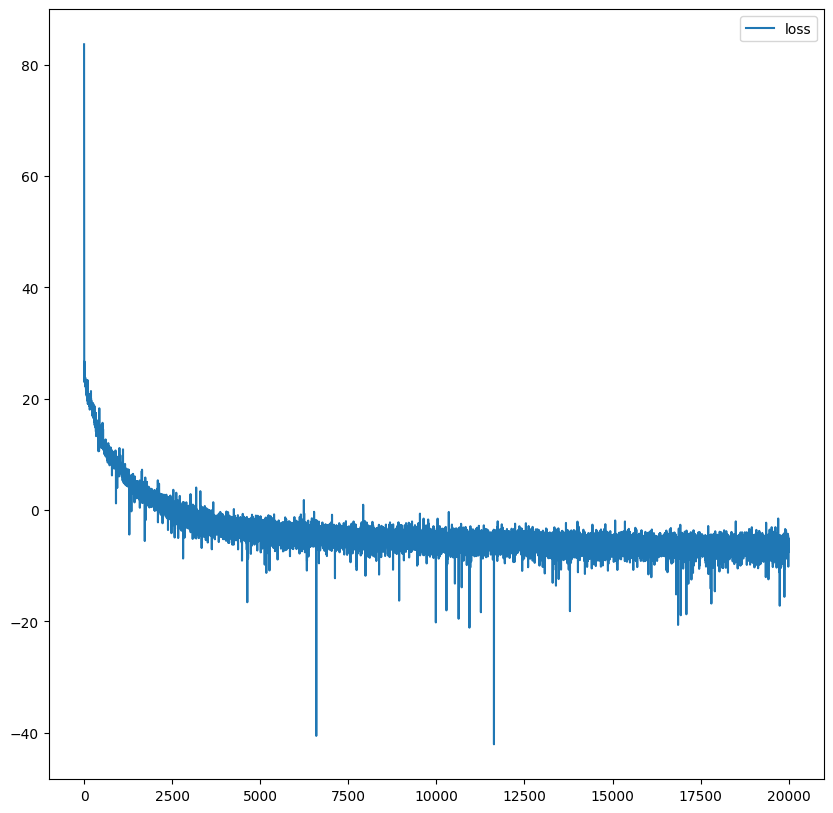

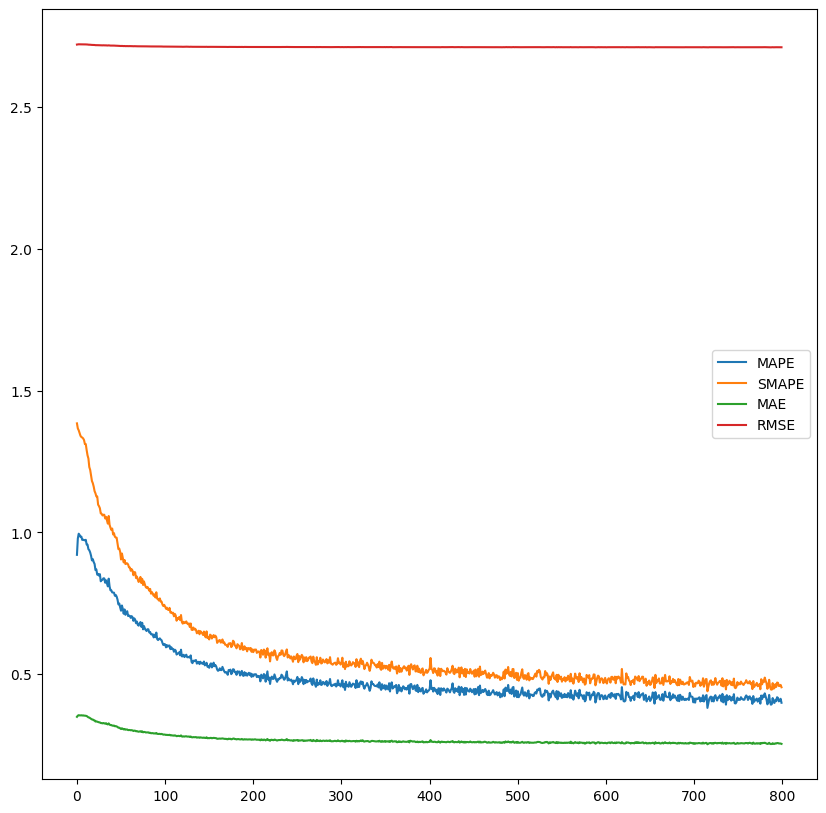

Experiment(setup=ExperimentSetup(coordinate_system=<CoordinateSystem.Spherical: (1,)>, prior_str='cosine', scene_name='cbox', num_flows=4, num_bins=16, hidden_units=64, hidden_layers=4, do_normal_encoding=True, do_in_dir_encoding=True, do_pos_encoding=True, pos_is_hash_grid=True, encode_pos_each_flow=False, latent_to_hashgrid=False, do_scaling_grid_sizes=False, grid_resolutions=[], grid_levels=[], grid_scale_factors=[]), trained_iterations=20000, sample_gen_strategy='light_tracing', sample_model=True, losses=array([83.68914032, 53.8921814 , 39.76498413, ..., -7.2446208 ,
       -7.00638342, -6.29905081], shape=(20000,)), tracked_errors=True, tracked_error_every=25, mape_list=array([0.92060709, 0.97826624, 0.99504948, 0.99048394, 0.98381281,
       0.98485696, 0.97310829, 0.97434616, 0.97259396, 0.97158903,
       0.97345924, 0.95717859, 0.95633143, 0.9405641 , 0.93683529,
       0.92897671, 0.91737688, 0.90096724, 0.90523446, 0.89504433,
       0.88831222, 0.86681765, 0.86907166, 0.850

In [12]:
### Cbox cosine prior

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 20000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

run_experiment(setup, training_context, "cbox_20k_cosine_prior.pkl")

## ----

In [11]:
### cbox_inverted_light one-blob prior

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=False,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 20000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

exp = run_experiment(setup, training_context, "cbox_inverted_light_one_blob_20k_light_traced.pkl")
del(exp)

TypeError: ExperimentSetup.__init__() missing 1 required positional argument: 'lr'

using device: cuda


100%|██████████| 20000/20000 [35:28<00:00,  9.40it/s]


average generate_samples_time time 0.006523782789707184
average compute_gradient_time time 0.03112102885246277
average nan_check_clip_time time 0.0005694156169891358
average optimizer_time time 2.1326541900634766e-08


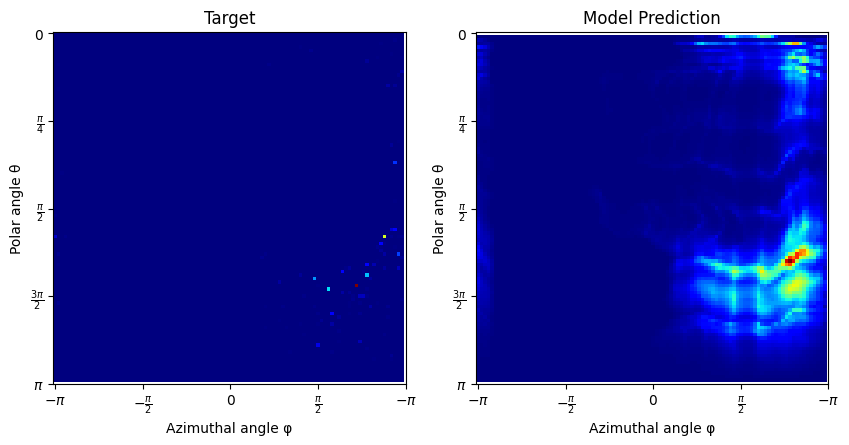

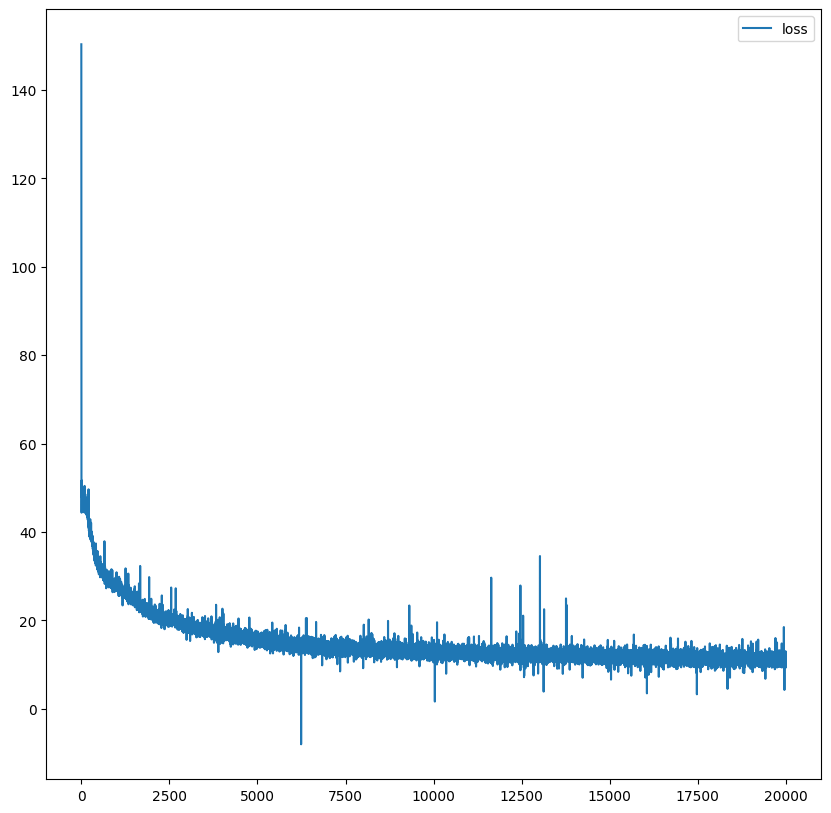

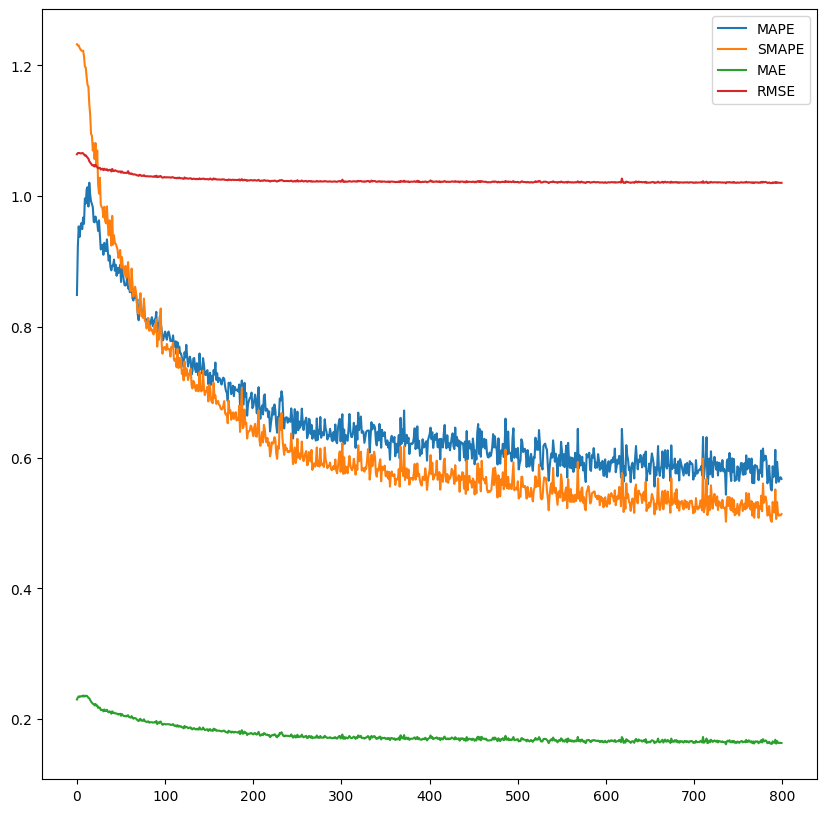

Experiment(setup=ExperimentSetup(coordinate_system=<CoordinateSystem.Spherical: (1,)>, prior_str='cosine', scene_name='cbox_inverted_light', num_flows=4, num_bins=16, hidden_units=64, hidden_layers=4, do_normal_encoding=True, do_in_dir_encoding=True, do_pos_encoding=True, pos_is_hash_grid=True, encode_pos_each_flow=False, latent_to_hashgrid=False, do_scaling_grid_sizes=False, grid_resolutions=[], grid_levels=[], grid_scale_factors=[]), trained_iterations=20000, sample_gen_strategy='light_tracing', sample_model=True, losses=array([150.31182861,  84.23020935,  74.80267334, ...,  12.22749329,
        11.19809818,  11.24054241], shape=(20000,)), tracked_errors=True, tracked_error_every=25, mape_list=array([0.84882736, 0.92231083, 0.95373243, 0.93759608, 0.9531188 ,
       0.95885438, 0.94958943, 0.96721506, 0.9576416 , 0.99650276,
       0.98882008, 1.01030874, 1.01374471, 0.98411429, 1.02051866,
       1.00249767, 0.9916687 , 0.98804516, 0.98291129, 0.96084374,
       0.95992297, 0.968800

In [12]:
### cbox_inverted_light hash grid prior

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 20000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

run_experiment(setup, training_context, "cbox_inverted_light_hash_grid_20k_light_traced.pkl")

## Single grid vs mult grids vs mult grids scaled down

using device: cuda


100%|██████████| 50000/50000 [45:49<00:00, 18.19it/s]
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


average generate_samples_time time 0.008842371668815612
average compute_gradient_time time 0.03497145806312561
average nan_check_clip_time time 0.0006005224752426147
average optimizer_time time 9.670257568359375e-09


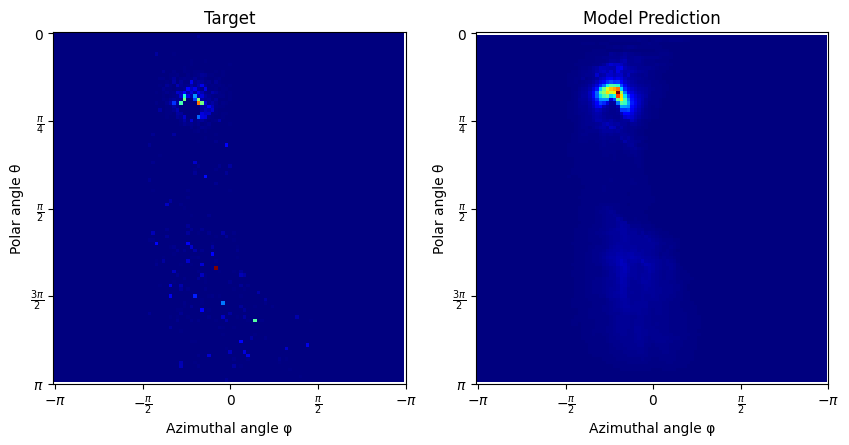

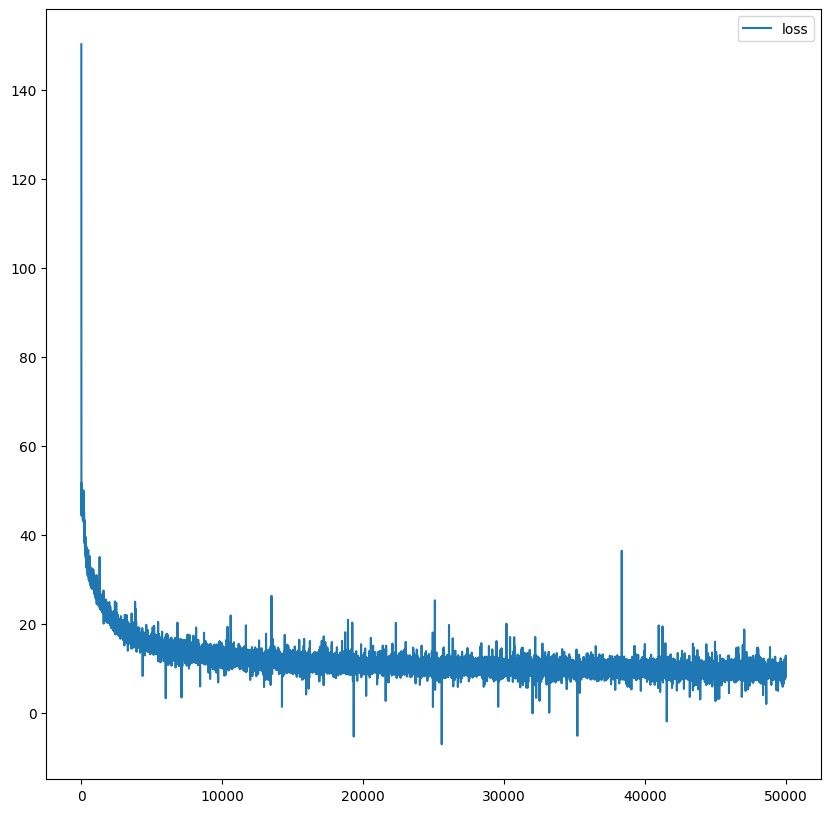

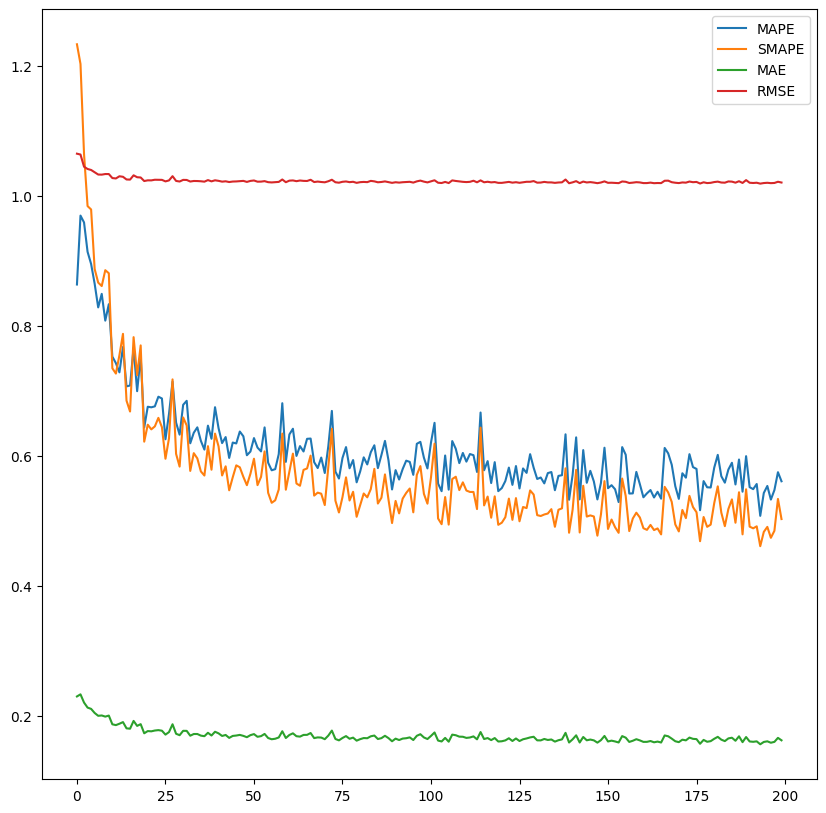

In [15]:
### Single Hashgrids inv cbox

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "hashgrid_setups_single_50k.pkl")

del(exp)

using device: cuda


100%|██████████| 50000/50000 [55:17<00:00, 15.07it/s]


average generate_samples_time time 0.015735823216438294
average compute_gradient_time time 0.03642438025474548
average nan_check_clip_time time 0.0006129875802993774
average optimizer_time time 9.493827819824219e-09


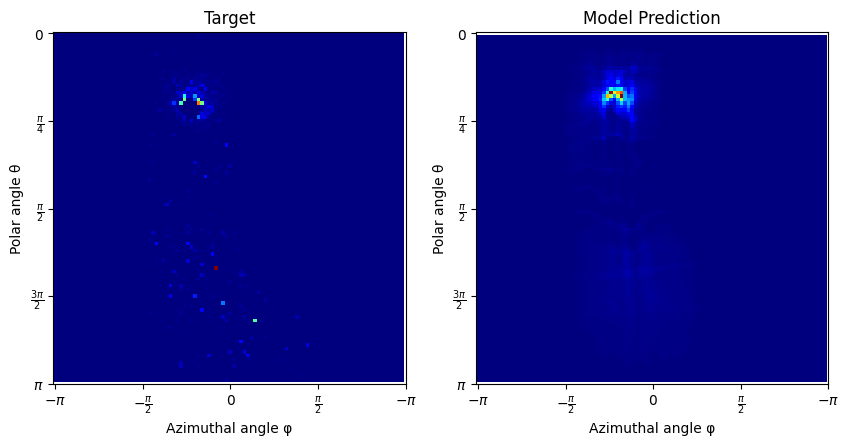

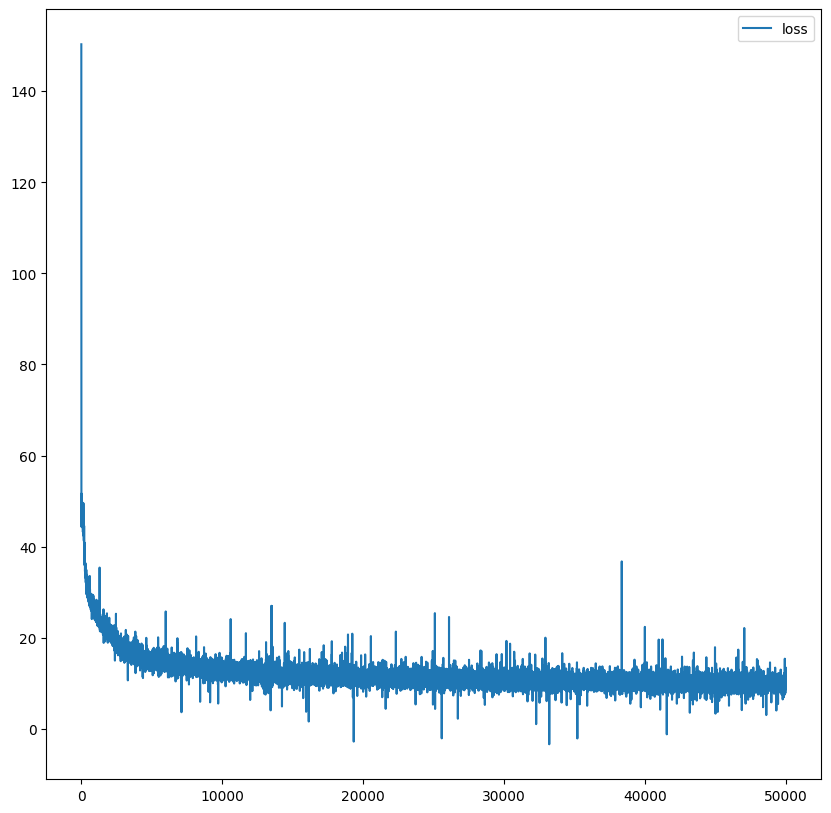

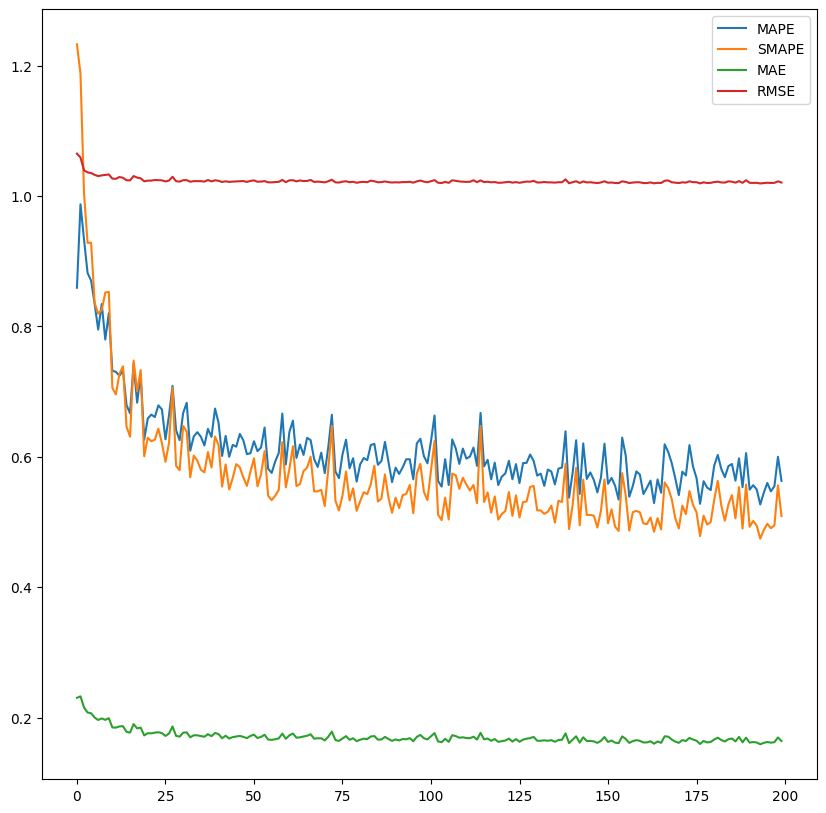

In [16]:
### Mult Hashgrids inv cbox

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "hashgrid_setups_multiple_50k.pkl")

del(exp)

using device: cuda


100%|██████████| 50000/50000 [51:54<00:00, 16.06it/s]


average generate_samples_time time 0.013297226271629334
average compute_gradient_time time 0.03641102869033813
average nan_check_clip_time time 0.0006118183755874633
average optimizer_time time 9.899139404296875e-09


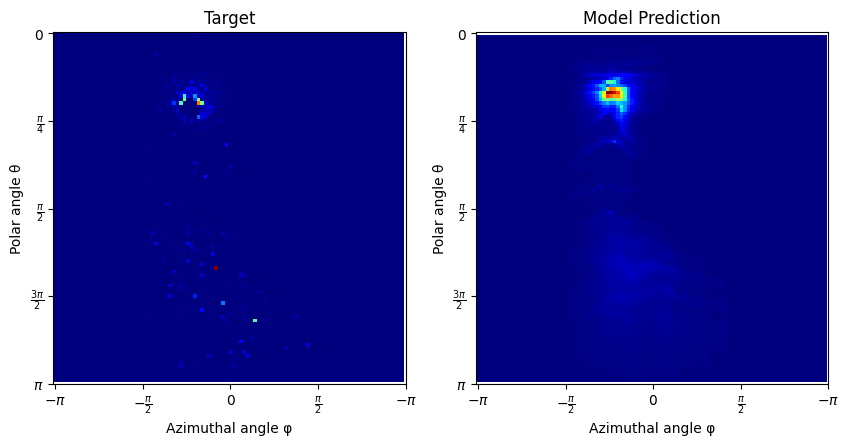

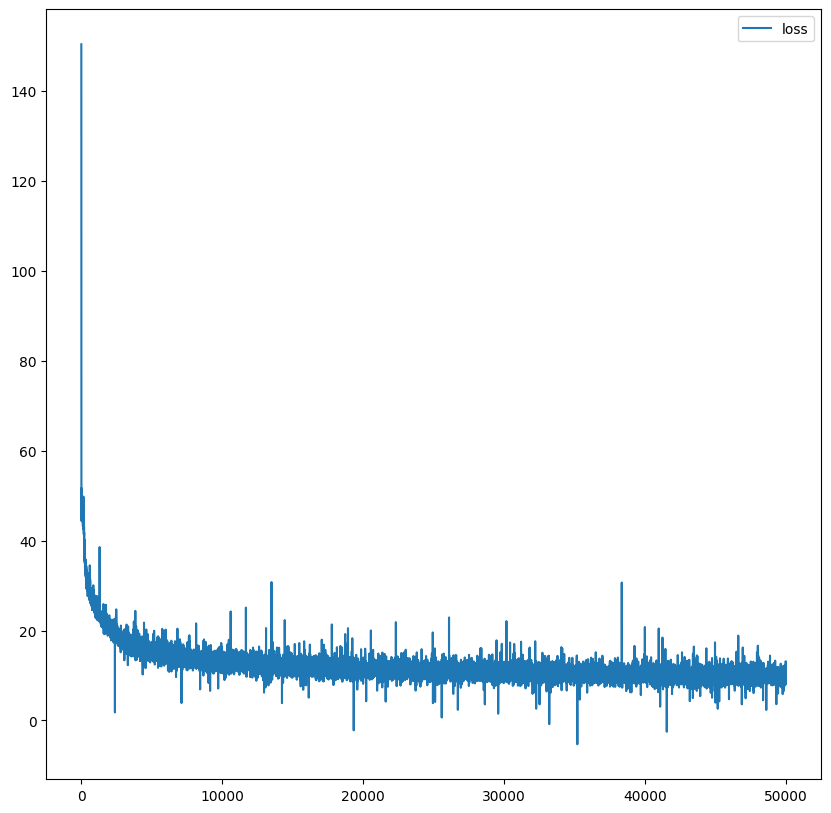

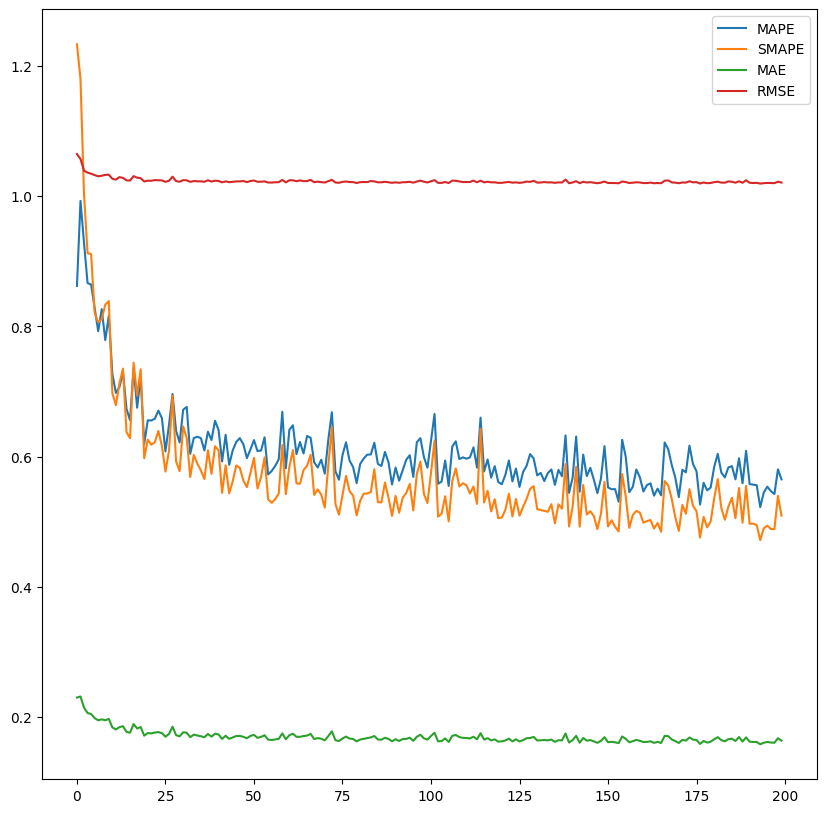

In [17]:
### Mult Hashgrids smaller inv cbox



setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
    hash_grid_log2_size = 17, # 4x smaller than the grids in the other two -> not sure if this is enough for fair comparison though -> might have to make smaller resolutions ?
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "hashgrid_setups_multiple_50k_smaller_grids.pkl")

del(exp)

using device: cuda


100%|██████████| 50000/50000 [59:13<00:00, 14.07it/s] 


average generate_samples_time time 0.018165959577560425
average compute_gradient_time time 0.0375683110666275
average nan_check_clip_time time 0.0006096133613586426
average optimizer_time time 1.0380744934082032e-08


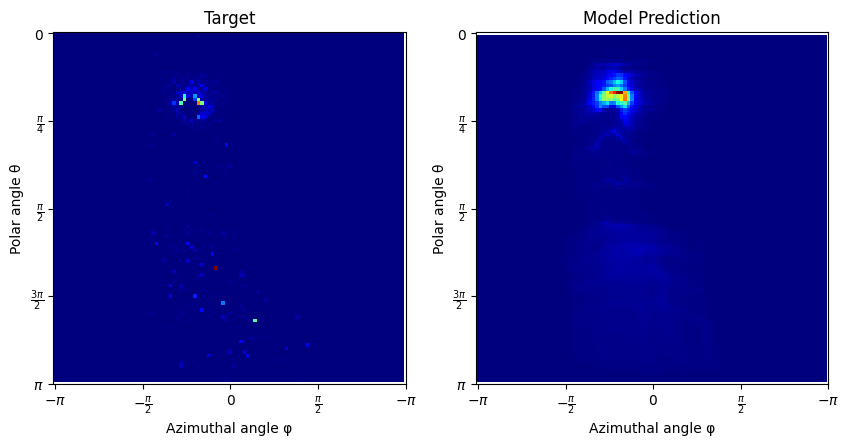

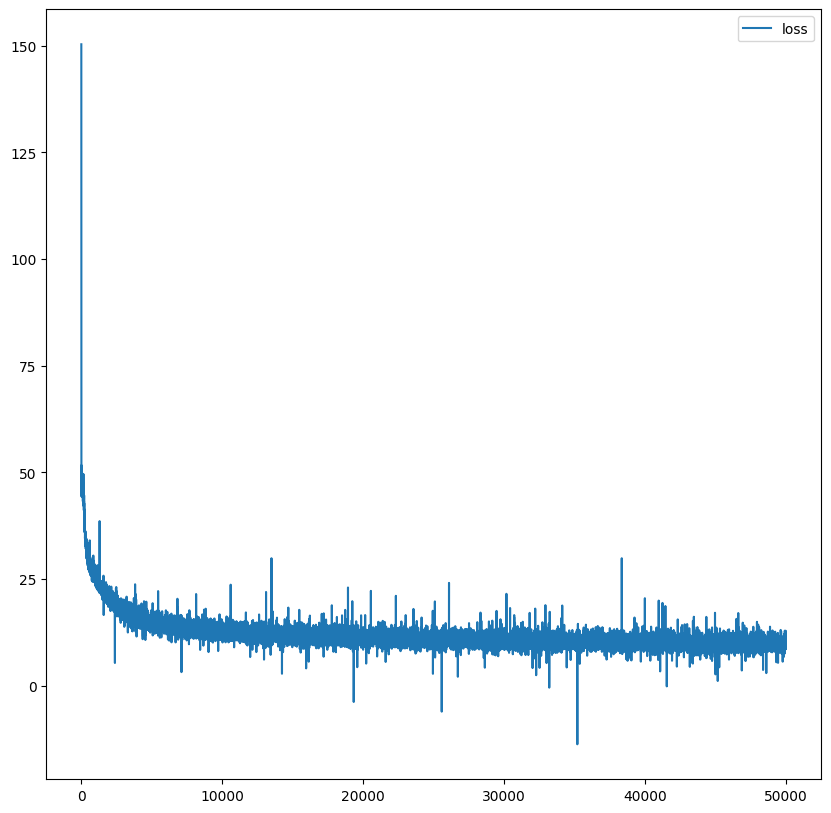

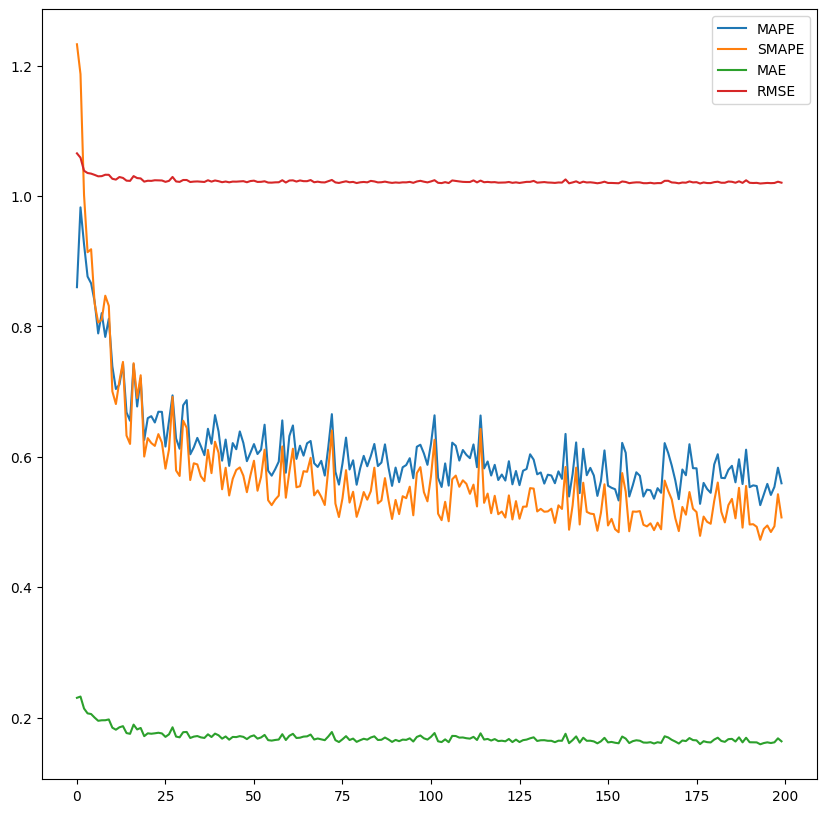

In [18]:
### Mult Hashgrids stagger inv cbox

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[4, 8, 12, 16],
    grid_levels=[2, 4, 6, 8],
    grid_scale_factors=[1.25, 1.5, 1.75, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "hashgrid_setups_multiple_50k_stagger.pkl")

del(exp)

## Prior Compare

loaded scene
using device: cuda
created model
starting training


d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))
  0%|          | 0/10000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:110: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
100%|██████████| 10000/10000 [09:45<00:00, 17.07it/s]
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:

average generate_samples_time time 0.00638623354434967
average compute_gradient_time time 0.03190220949649811
average nan_check_clip_time time 0.0006285377979278565
average optimizer_time time 4.861354827880859e-08


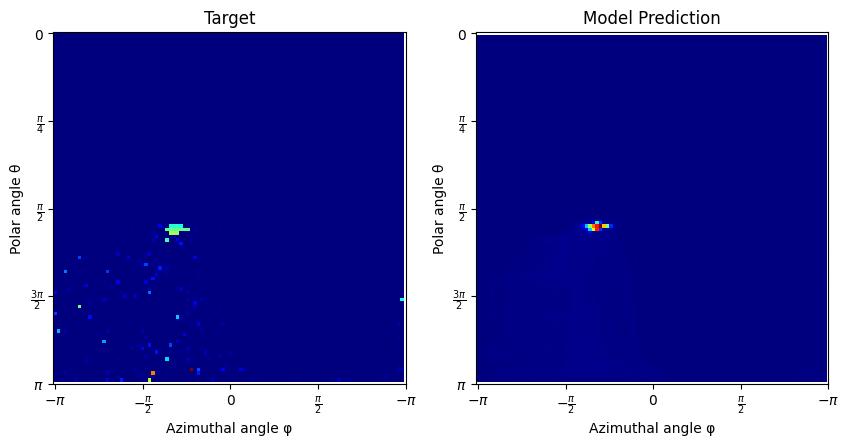

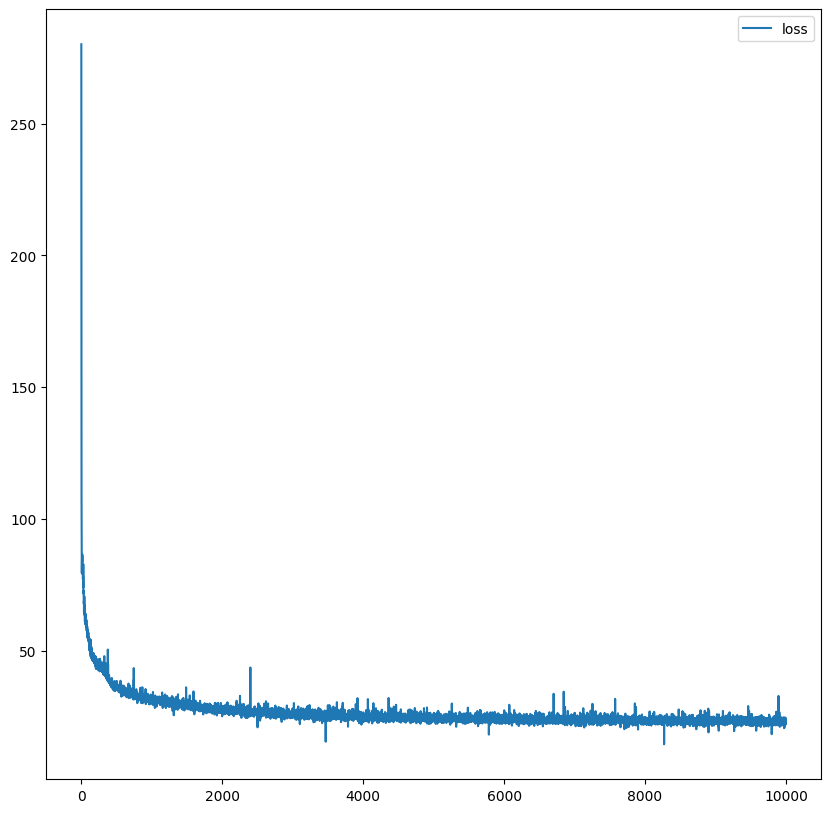

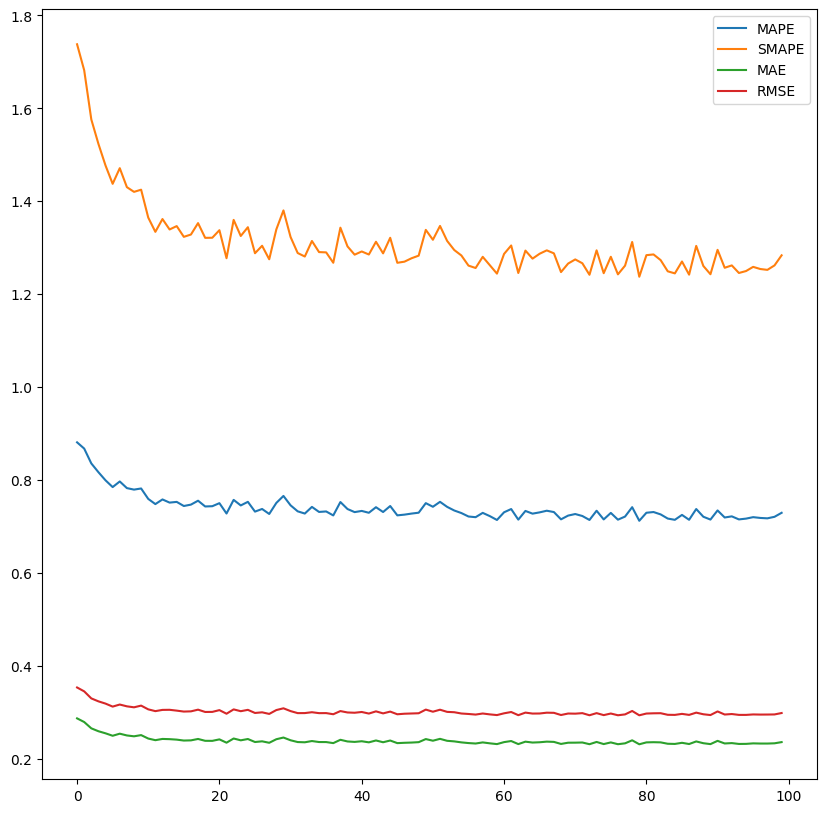

Experiment(setup=ExperimentSetup(coordinate_system=<CoordinateSystem.Spherical: (1,)>, prior_str='uniform', scene_name='cbox_inverted_light', num_flows=4, num_bins=16, hidden_units=64, hidden_layers=4, lr=0.001, do_normal_encoding=True, do_in_dir_encoding=True, do_pos_encoding=True, pos_is_hash_grid=True, encode_pos_each_flow=False, latent_to_hashgrid=False, do_scaling_grid_sizes=False, grid_resolutions=[], grid_levels=[], grid_scale_factors=[], hash_grid_log2_size=19), trained_iterations=10000, sample_gen_strategy='light_tracing', sample_model=True, losses=array([280.07293701, 171.09931946, 136.41156006, ...,  22.12803078,
        22.24368668,  22.1818161 ], shape=(10000,)), tracked_errors=True, tracked_error_every=100, mape_list=array([0.88081789, 0.8673799 , 0.83543116, 0.81652999, 0.79898387,
       0.78448766, 0.79656667, 0.78226954, 0.77902931, 0.78146976,
       0.75902295, 0.74785215, 0.75786304, 0.75106412, 0.75259584,
       0.74373865, 0.7467348 , 0.75514621, 0.74275357, 0.7

In [ ]:
### cbox_inverted_light uniform prior

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='uniform',
    # prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 1e-3,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 10000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = False,
    track_error = True, 
    track_error_every = 100
)

exp = run_experiment(setup, training_context, "new_model_2_cbox_inverted_light_uniform_prior_25k_light_traced.pkl", width = 512, height = 512)

del(exp)

using device: cuda


100%|██████████| 25000/25000 [46:59<00:00,  8.87it/s]


average generate_samples_time time 0.007152627668380737
average compute_gradient_time time 0.03235348928451538
average nan_check_clip_time time 0.0006018599796295166
average optimizer_time time 1.850128173828125e-08


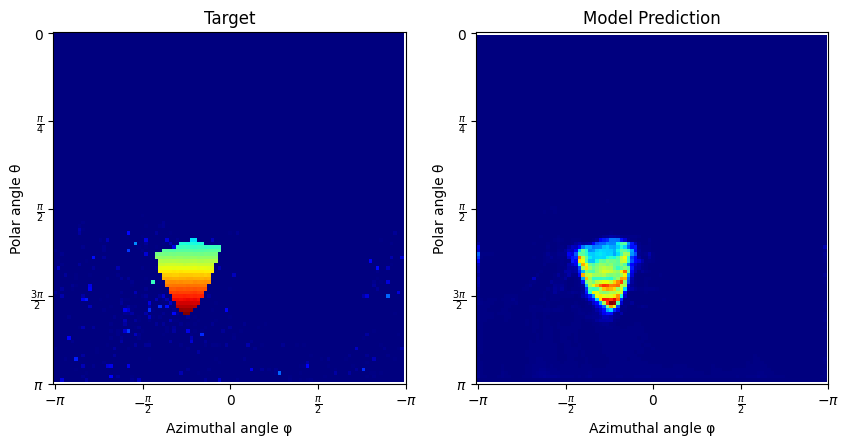

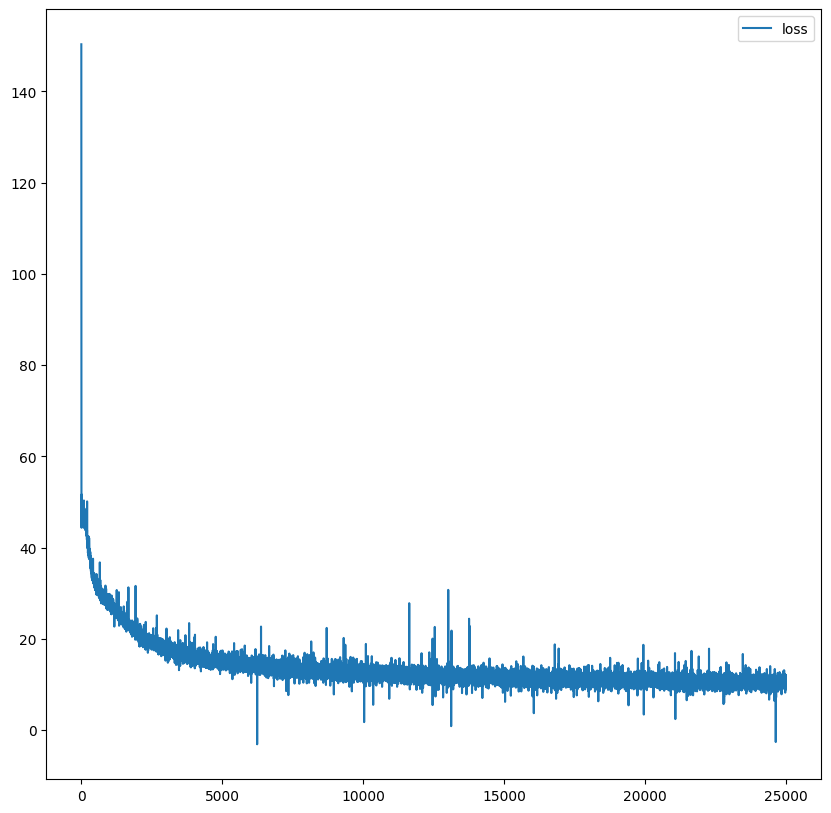

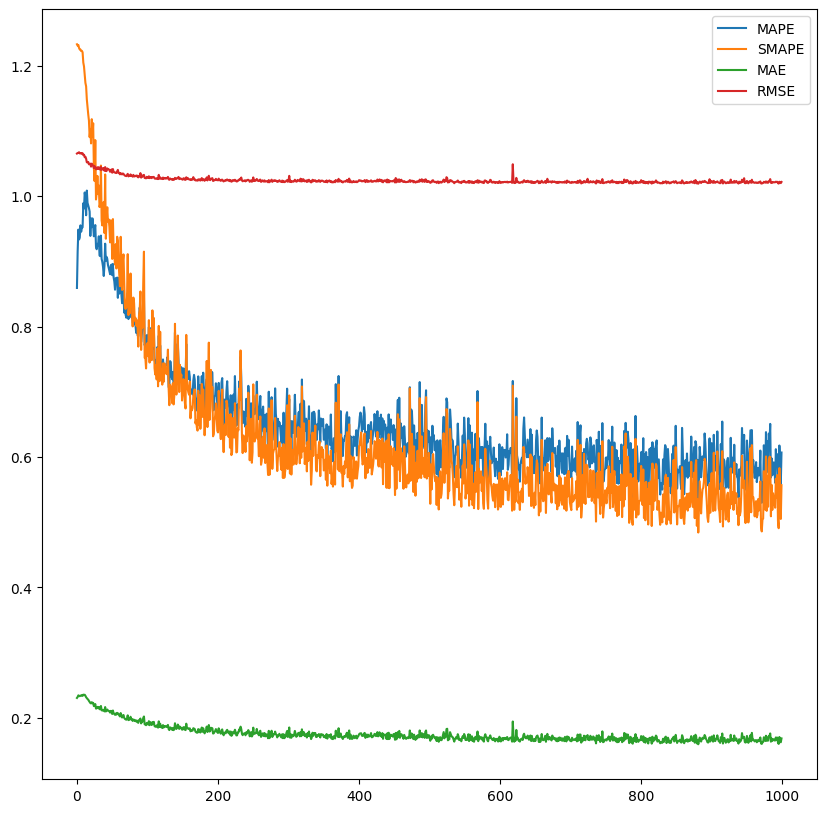

In [12]:
### cbox_inverted_light cosine prior

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 25000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

exp = run_experiment(setup, training_context, "cbox_inverted_light_cosine_prior_25k_light_traced.pkl")
del(exp)

## Light Sampling vs Sensor Sampling

## Kitchen

loaded scene
using device: cuda
created model
starting training


100%|██████████| 50000/50000 [4:10:55<00:00,  3.32it/s]  


average generate_samples_time time 0.20479844466686248
average compute_gradient_time time 0.04741854016304016
average nan_check_clip_time time 0.0005717220401763916
average optimizer_time time 1.0743141174316407e-08


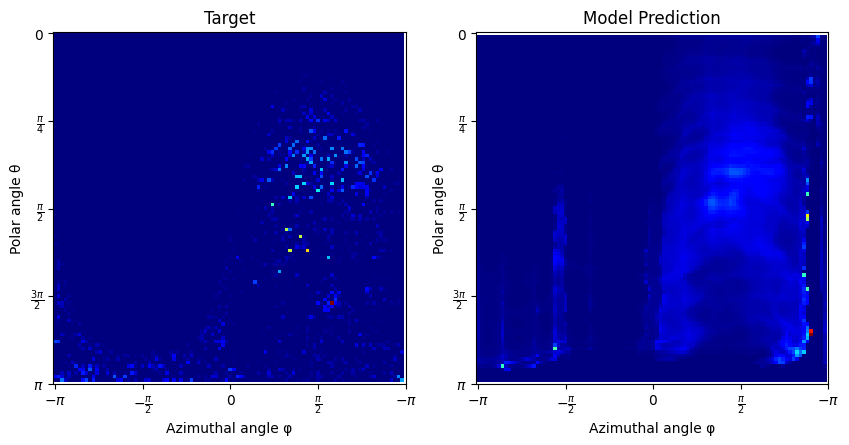

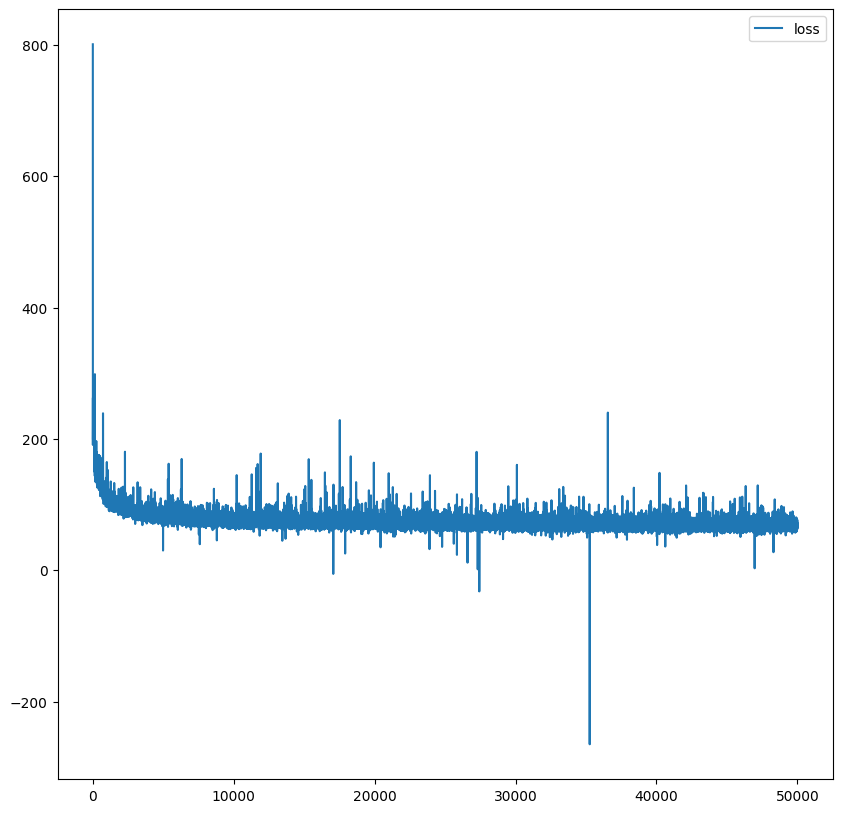

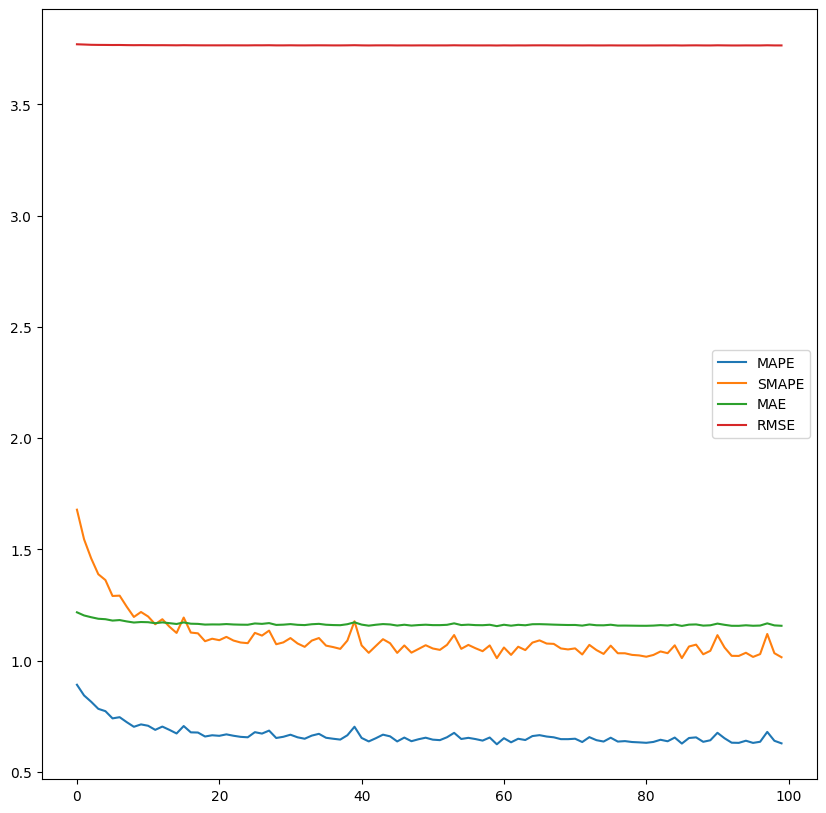

In [ ]:
### kitchen 50k one blob

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'kitchen',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4, 

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=False,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "kitchen_one_blob_light_trace_50k.pkl")
del(exp)

loaded scene
using device: cuda
created model
starting training


  0%|          | 0/50000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:85: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
100%|██████████| 50000/50000 [2:32:16<00:00,  5.47it/s]  
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


average generate_samples_time time 0.10689429489135742
average compute_gradient_time time 0.04119785552978516
average nan_check_clip_time time 0.000568183240890503
average optimizer_time time 1.0457038879394532e-08


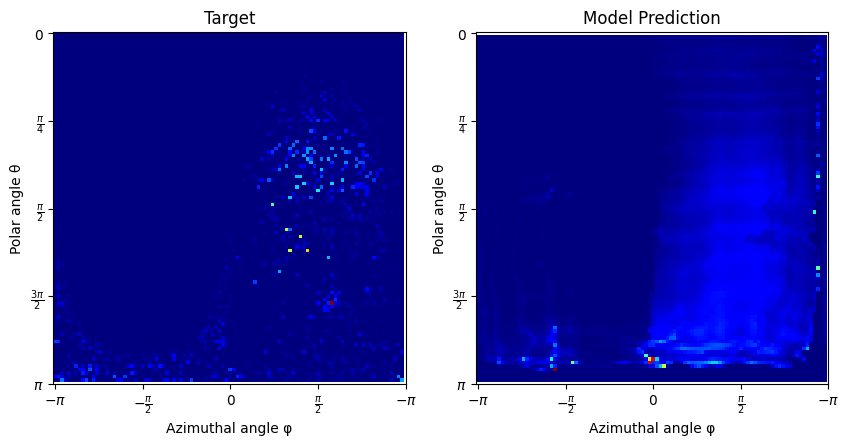

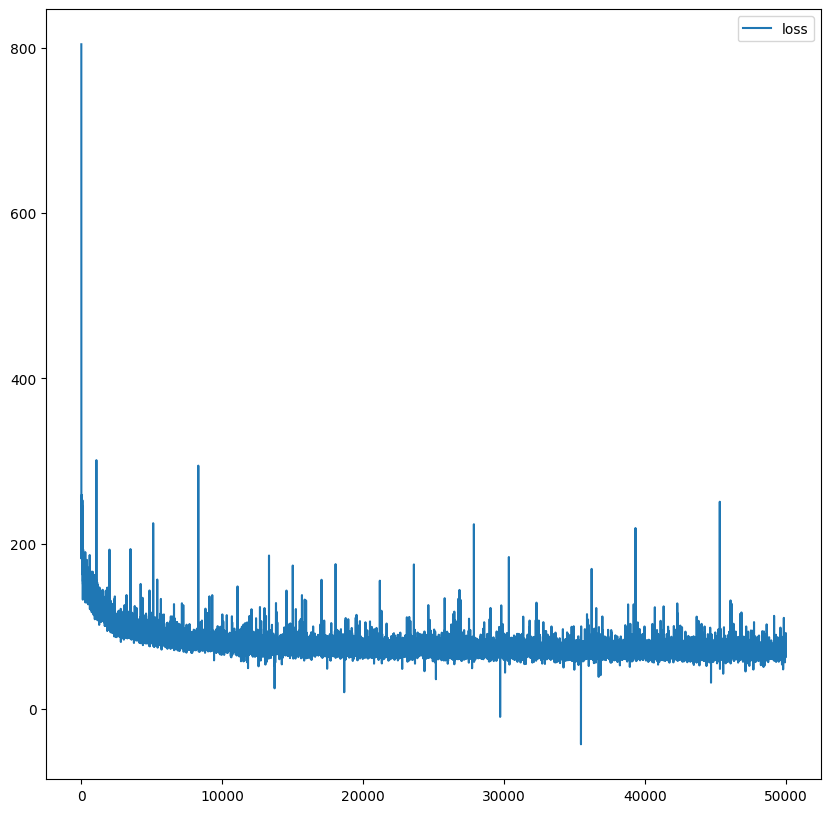

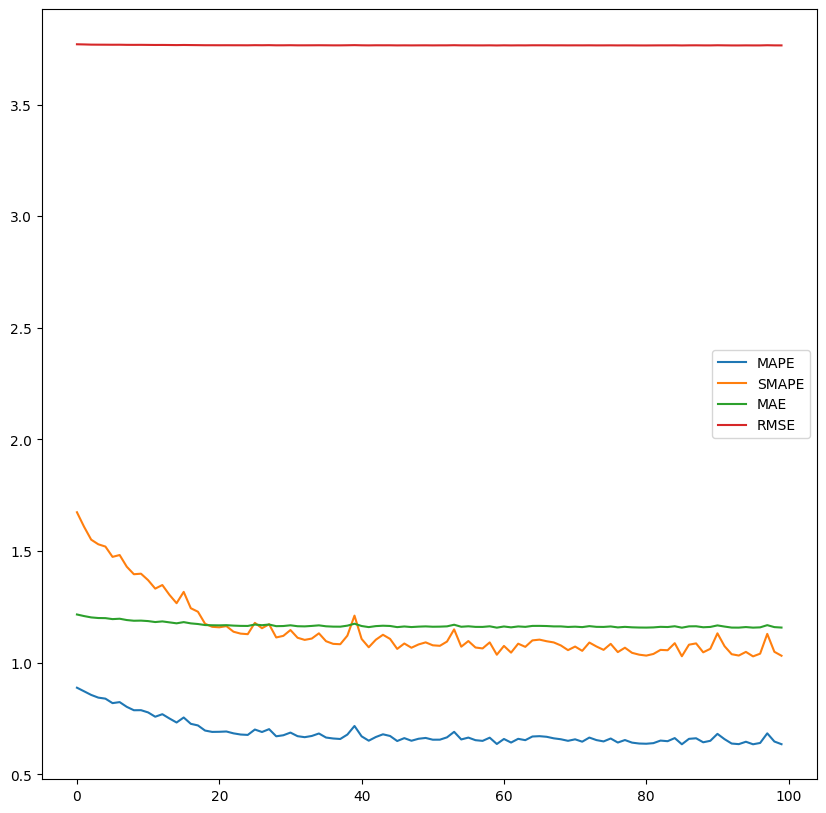

In [11]:
### kitchen 50k hash grid

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'kitchen',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4, 

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 500
)

exp = run_experiment(setup, training_context, "kitchen_hash_grid_light_trace_50k.pkl")
del(exp)

{'nested': [{'degree': 4, 'n_dims_to_encode': 3, 'otype': 'SphericalHarmonics'},
            {'degree': 4, 'n_dims_to_encode': 3, 'otype': 'SphericalHarmonics'},
            {'n_dims_to_encode': 3, 'otype': 'Identity'}],
 'otype': 'Composite'}
------
{'nested': [{'n_dims_to_encode': 16, 'otype': 'Identity'},
            {'n_dims_to_encode': 16, 'otype': 'Identity'},
            {'base_resolution': 16,
             'interpolation': 'Linear',
             'log2_hashmap_size': 19,
             'n_dims_to_encode': 4,
             'n_features_per_level': 2,
             'n_levels': 8,
             'otype': 'Grid',
             'per_level_scale': 2.0,
             'type': 'Hash'}],
 'otype': 'Composite'}
------
35
using device: cuda


100%|██████████| 50000/50000 [4:09:42<00:00,  3.34it/s]  


average generate_samples_time time 0.12645533697128297
average compute_gradient_time time 0.06231521761417389
average nan_check_clip_time time 0.0005406578588485717
average optimizer_time time 1.094341278076172e-08


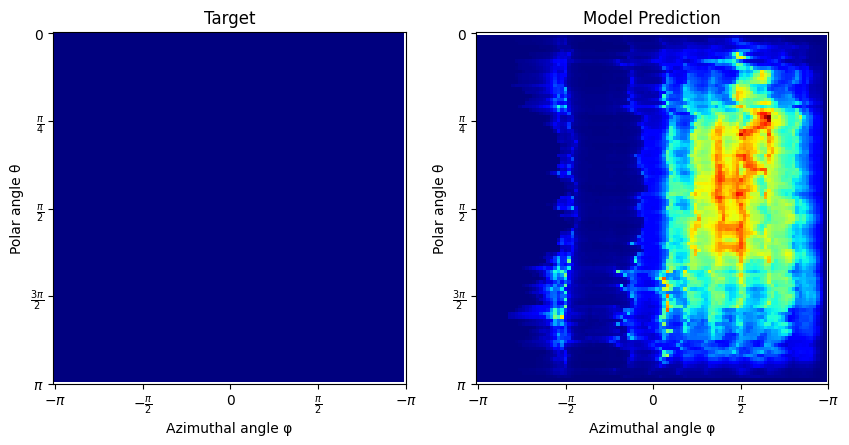

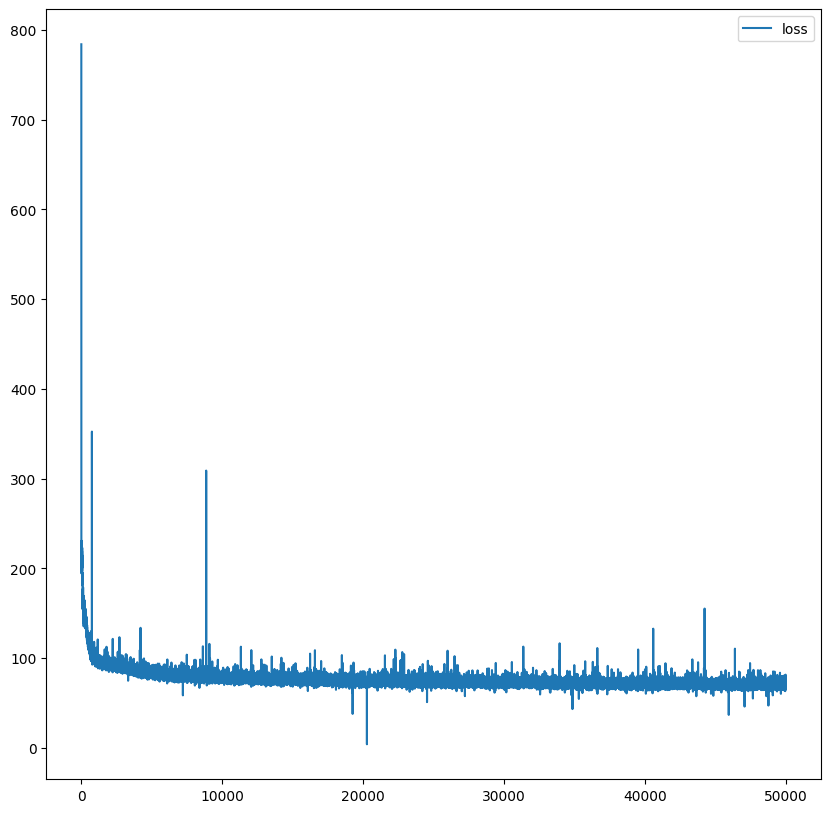

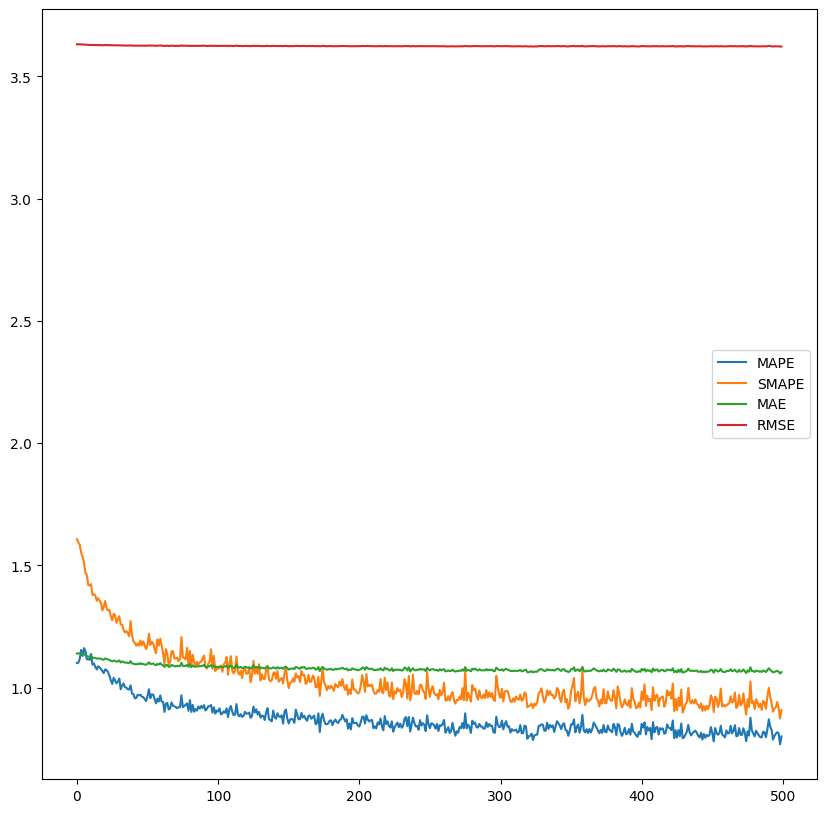

Experiment(setup=ExperimentSetup(coordinate_system=<CoordinateSystem.Spherical: (1,)>, prior_str='cosine', scene_name='kitchen', num_flows=4, num_bins=16, hidden_units=64, hidden_layers=4, do_normal_encoding=True, do_in_dir_encoding=True, do_pos_encoding=True, pos_is_hash_grid=True, encode_pos_each_flow=True, latent_to_hashgrid=True, do_scaling_grid_sizes=False, grid_resolutions=[], grid_levels=[], grid_scale_factors=[]), trained_iterations=50000, sample_gen_strategy='light_tracing', sample_model=True, losses=array([784.07824707, 355.49951172, 299.67602539, ...,  68.72090912,
        70.72032928,  72.86177826], shape=(50000,)), tracked_errors=True, tracked_error_every=100, mape_list=array([1.10066938, 1.10149336, 1.11804867, 1.15397024, 1.12924099,
       1.16122758, 1.14951658, 1.11576009, 1.11601043, 1.11325145,
       1.13778043, 1.0935607 , 1.09855425, 1.08468795, 1.0740478 ,
       1.08727837, 1.08247781, 1.07590222, 1.06795156, 1.0588119 ,
       1.07435358, 1.07159913, 1.0638155

In [ ]:
### kitchen 50k each flow

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'kitchen',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 16
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 100
)

run_experiment(setup, training_context, "kitchen_light_trace_50k.pkl")

In [11]:
### kitchen sensor sampling

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'kitchen',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 16
width = 128
height = 128

training_context = Context(
    iterations = 25000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    # sample_generation_strategy = "light_tracing",
    sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 50
)

run_experiment(setup, training_context, "kitchen_sensor_sampling.pkl")

TypeError: ExperimentSetup.__init__() missing 1 required positional argument: 'lr'

## ---- Kitchen one blob vs hash grid

using device: cuda


  0%|          | 0/10000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:85: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
100%|██████████| 10000/10000 [1:35:20<00:00,  1.75it/s]
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


average generate_samples_time time 0.3566582868099213
average compute_gradient_time time 0.04973488731384278
average nan_check_clip_time time 0.0005916863679885864
average optimizer_time time 5.764961242675781e-08


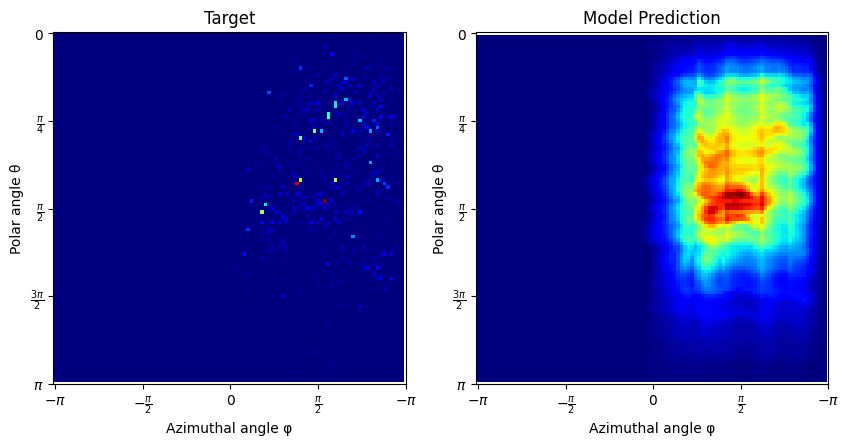

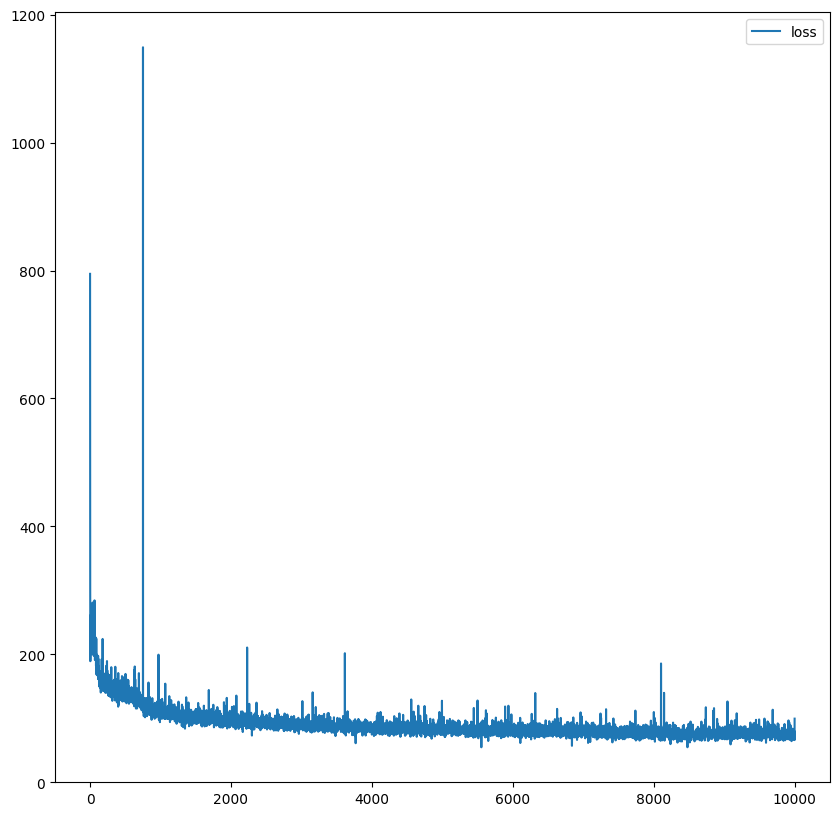

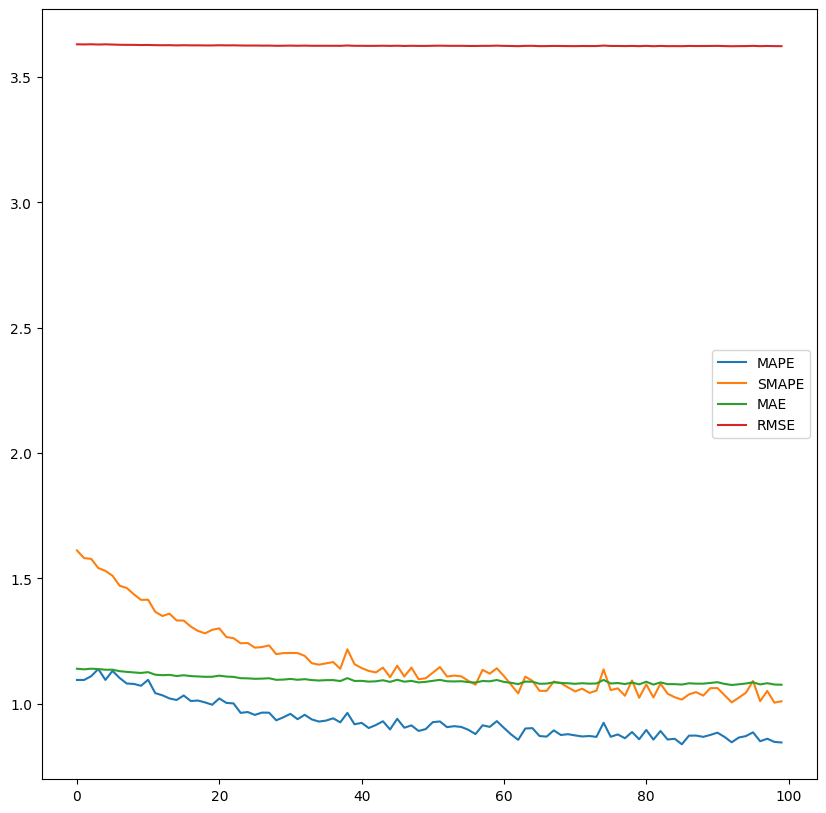

Experiment(setup=ExperimentSetup(coordinate_system=<CoordinateSystem.Spherical: (1,)>, prior_str='cosine', scene_name='kitchen', num_flows=4, num_bins=16, hidden_units=64, hidden_layers=4, lr=0.0003, do_normal_encoding=True, do_in_dir_encoding=True, do_pos_encoding=True, pos_is_hash_grid=False, encode_pos_each_flow=False, latent_to_hashgrid=False, do_scaling_grid_sizes=False, grid_resolutions=[], grid_levels=[], grid_scale_factors=[], hash_grid_log2_size=19), trained_iterations=10000, sample_gen_strategy='light_tracing', sample_model=True, losses=array([794.86437988, 339.39178467, 302.26486206, ...,  76.01145172,
        65.90702057,  99.427948  ], shape=(10000,)), tracked_errors=True, tracked_error_every=100, mape_list=array([1.09430647, 1.09429204, 1.10936761, 1.13789594, 1.09457254,
       1.13044596, 1.10214281, 1.08007956, 1.07849526, 1.07106745,
       1.09493923, 1.041798  , 1.03319383, 1.0205636 , 1.01442695,
       1.03231573, 1.01024866, 1.0121758 , 1.00473821, 0.99544799,
  

In [14]:
### kitchen 10k one blob

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'kitchen',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=False,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 10000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 100
)

run_experiment(setup, training_context, "prior_compare_kitchen_one_blob_light_trace_10k.pkl")

using device: cuda


100%|██████████| 10000/10000 [1:37:40<00:00,  1.71it/s]


average generate_samples_time time 0.3717386327028275
average compute_gradient_time time 0.04705184555053711
average nan_check_clip_time time 0.000583449935913086
average optimizer_time time 4.458427429199219e-08


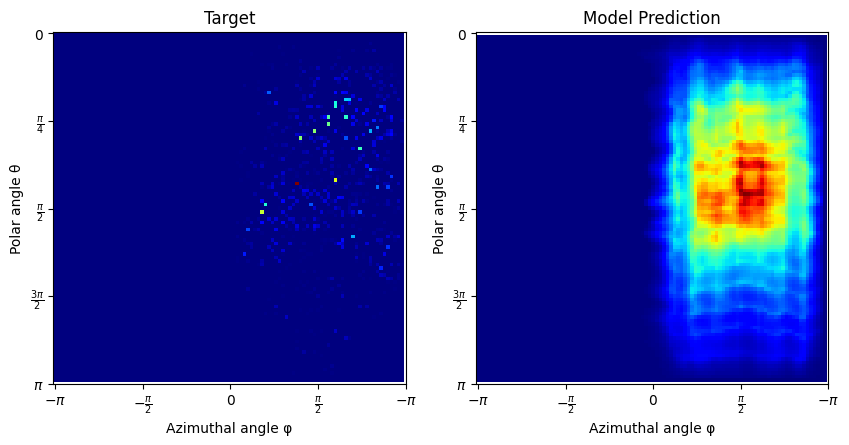

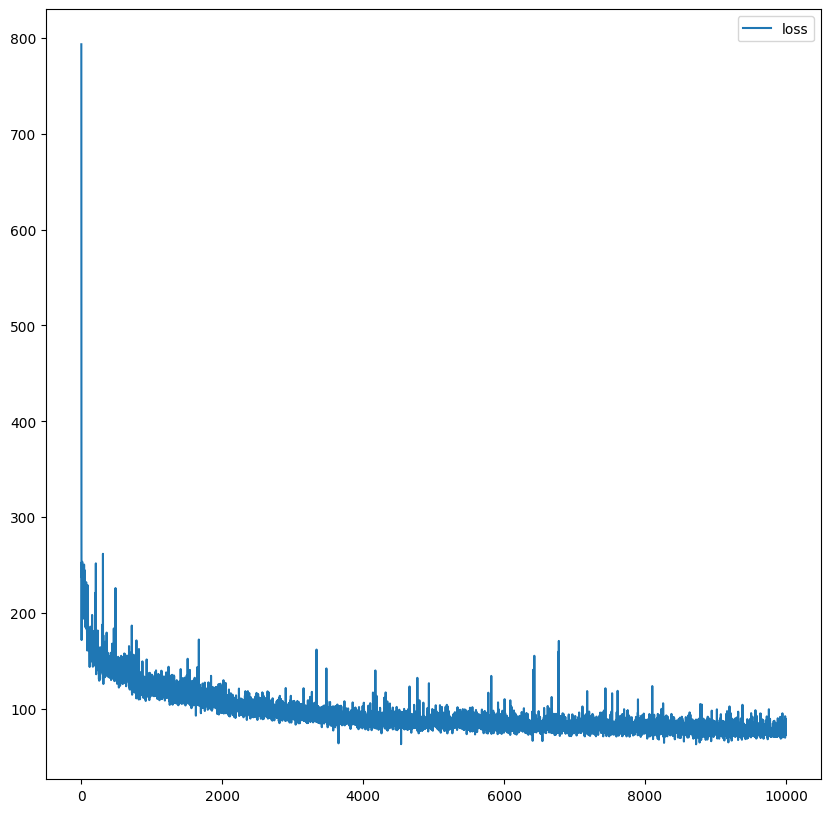

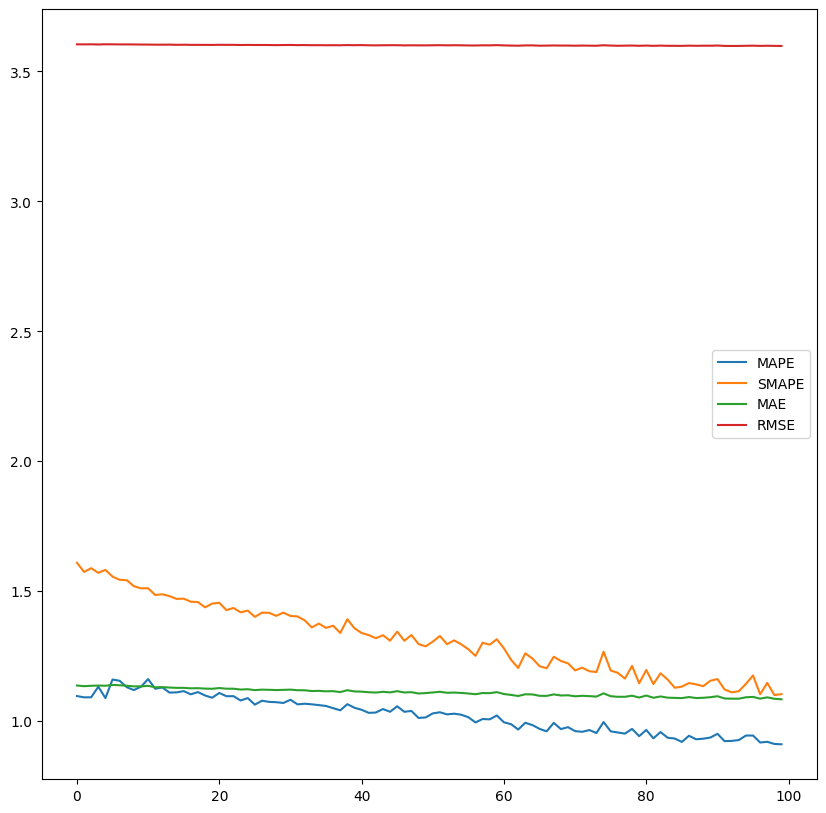

Experiment(setup=ExperimentSetup(coordinate_system=<CoordinateSystem.Spherical: (1,)>, prior_str='cosine', scene_name='kitchen', num_flows=4, num_bins=16, hidden_units=64, hidden_layers=4, lr=0.0003, do_normal_encoding=True, do_in_dir_encoding=True, do_pos_encoding=True, pos_is_hash_grid=True, encode_pos_each_flow=False, latent_to_hashgrid=False, do_scaling_grid_sizes=False, grid_resolutions=[], grid_levels=[], grid_scale_factors=[], hash_grid_log2_size=19), trained_iterations=10000, sample_gen_strategy='light_tracing', sample_model=True, losses=array([793.28723145, 358.6940918 , 277.12316895, ...,  89.78294373,
        78.62686157,  78.15597534], shape=(10000,)), tracked_errors=True, tracked_error_every=100, mape_list=array([1.09606874, 1.09112775, 1.09132087, 1.13204384, 1.08830249,
       1.15973878, 1.15484285, 1.13007784, 1.11916506, 1.13212371,
       1.16129494, 1.12416005, 1.12917185, 1.10944343, 1.11023653,
       1.1151135 , 1.10276341, 1.11134028, 1.09832466, 1.08962774,
   

In [15]:
### kitchen 10k hash grid

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'kitchen',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 10000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 100
)

run_experiment(setup, training_context, "prior_compare_kitchen_hash_grid_light_trace_10k.pkl")

## ----

d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda


100%|██████████| 25000/25000 [1:09:54<00:00,  5.96it/s]


average generate_samples_time time 0.0395707309627533
average compute_gradient_time time 0.0486184015083313
average nan_check_clip_time time 0.0006242760848999023
average optimizer_time time 2.1829605102539063e-08


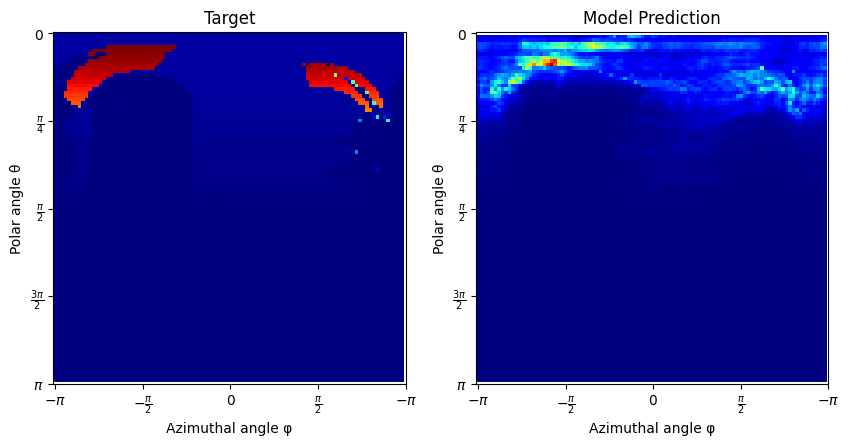

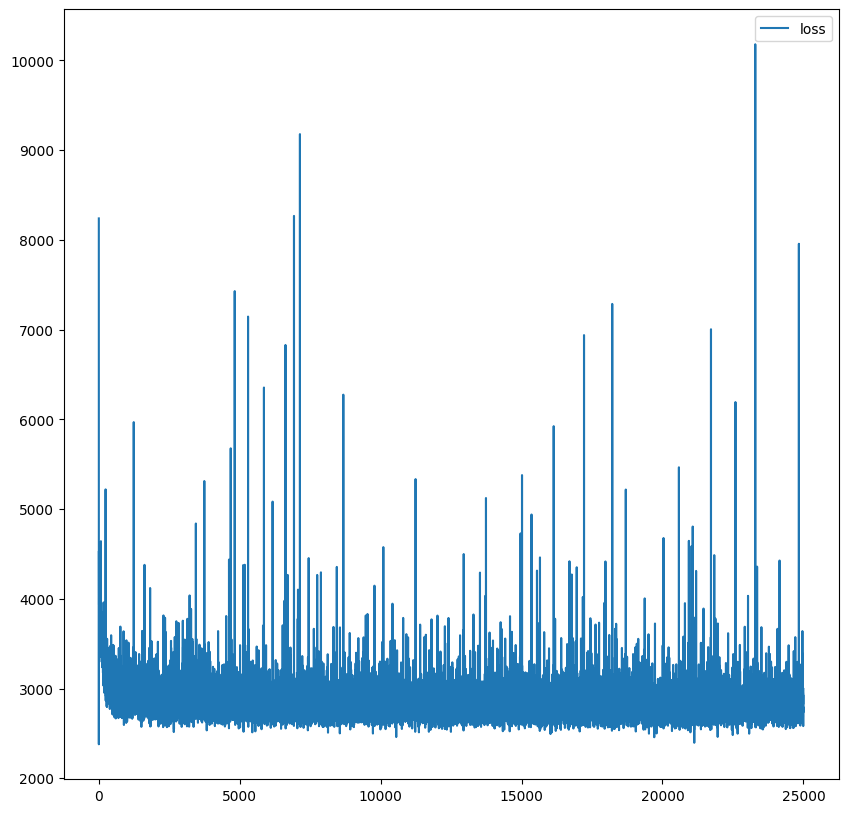

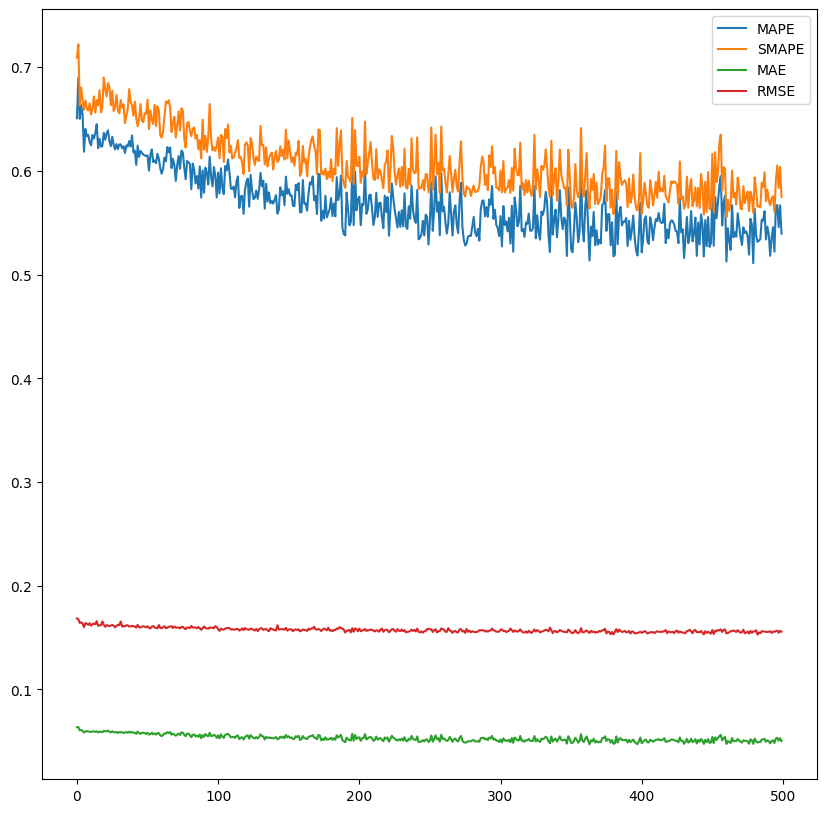

In [13]:
### spaceship no mis aware

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='uniform',
    # prior_str='cosine',
    scene_name = 'spaceship',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 16
width = 128
height = 128

training_context = Context(
    iterations = 25000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 50
)

exp = run_experiment(setup, training_context, "Spaceship_no_mis_aware_25k.pkl")
del(exp)

d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda


100%|██████████| 25000/25000 [1:12:43<00:00,  5.73it/s]


average generate_samples_time time 0.04188048711776733
average compute_gradient_time time 0.04887447951316833
average nan_check_clip_time time 0.0006418366718292237
average optimizer_time time 2.2611618041992186e-08


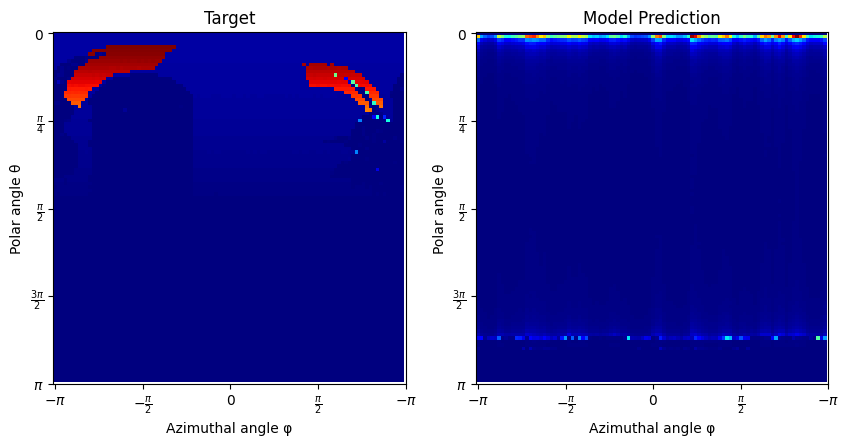

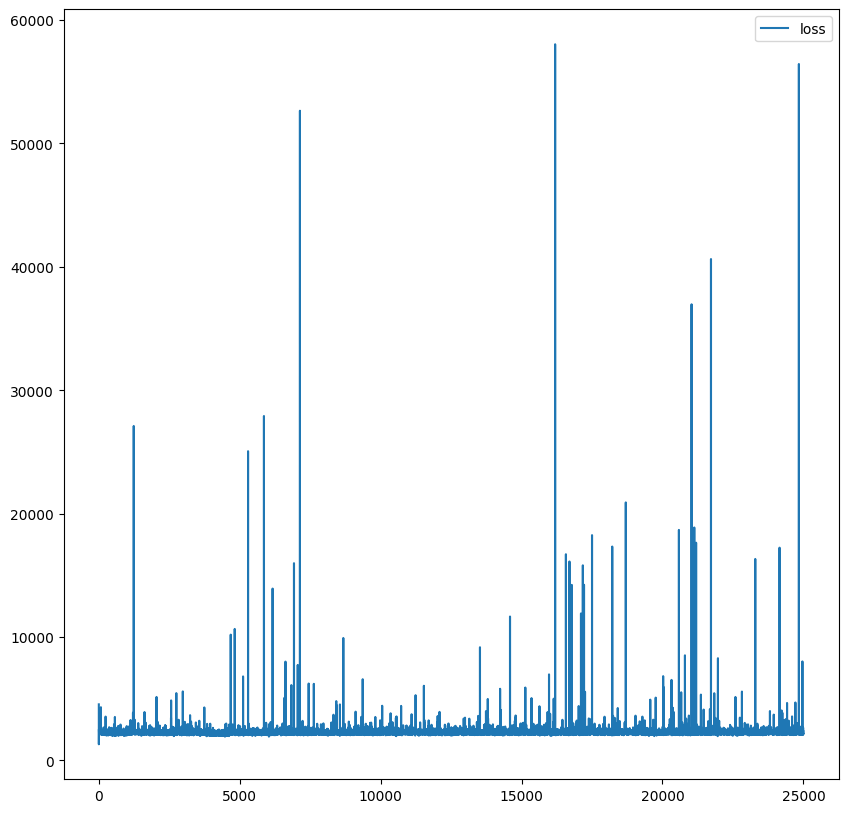

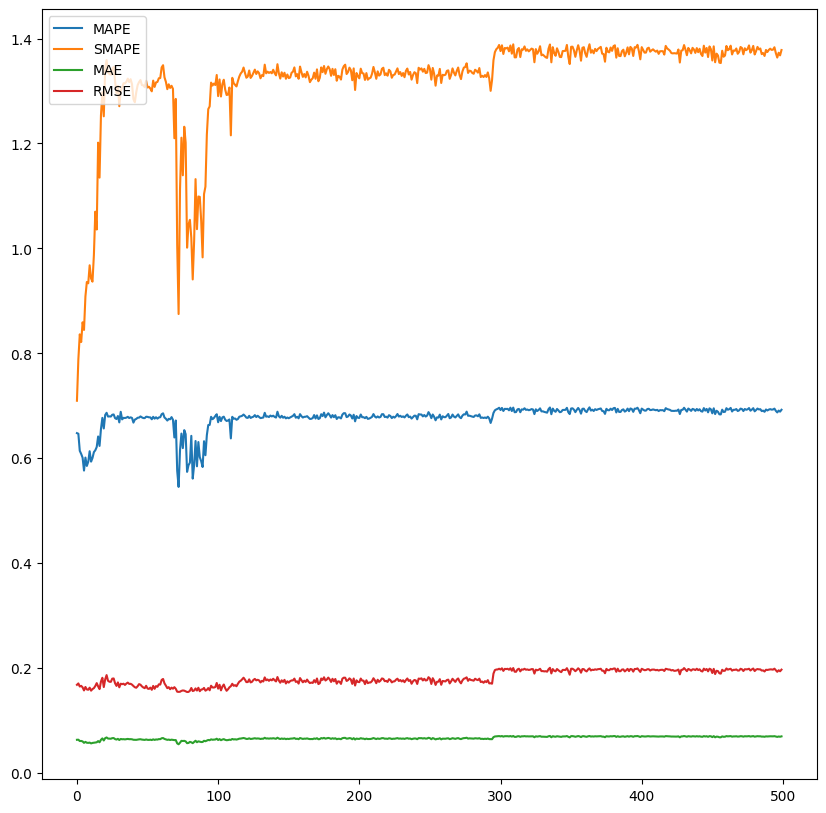

In [ ]:
### spaceship mis aware

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='uniform',
    # prior_str='cosine',
    scene_name = 'spaceship',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 16
width = 128
height = 128

training_context = Context(
    iterations = 5000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    MIS_aware_training = True,
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 50
)

exp = run_experiment(setup, training_context, "Spaceship_mis_aware_5k.pkl")
del(exp)

In [ ]:
### kitchen Sensor Sampling

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    # prior_str='uniform',
    prior_str='cosine',
    scene_name = 'kitchen',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 16
width = 128
height = 128

training_context = Context(
    iterations = 25000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    # sample_generation_strategy = "light_tracing",
    sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 50
)

exp = run_experiment(setup, training_context, "kitchen_sensor_sampling_25k.pkl")
del(exp)

## ----

using device: cuda


100%|██████████| 20000/20000 [36:51<00:00,  9.05it/s]


average generate_samples_time time 0.006830754840373993
average compute_gradient_time time 0.033297714412212374
average nan_check_clip_time time 0.0006062373876571655
average optimizer_time time 2.8824806213378905e-08


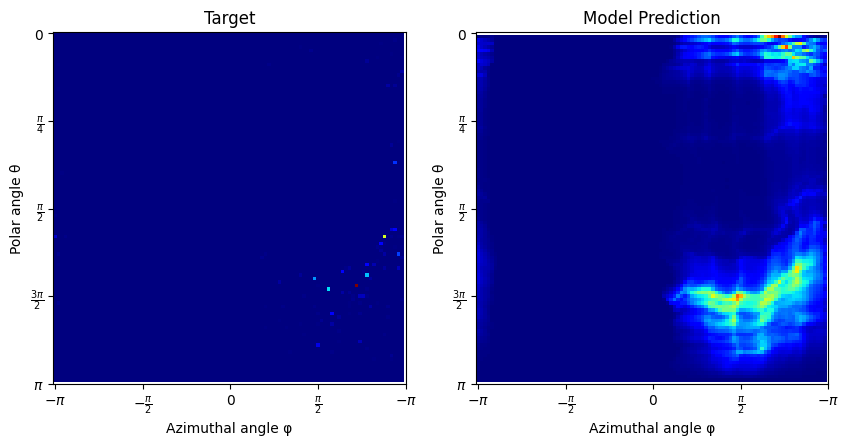

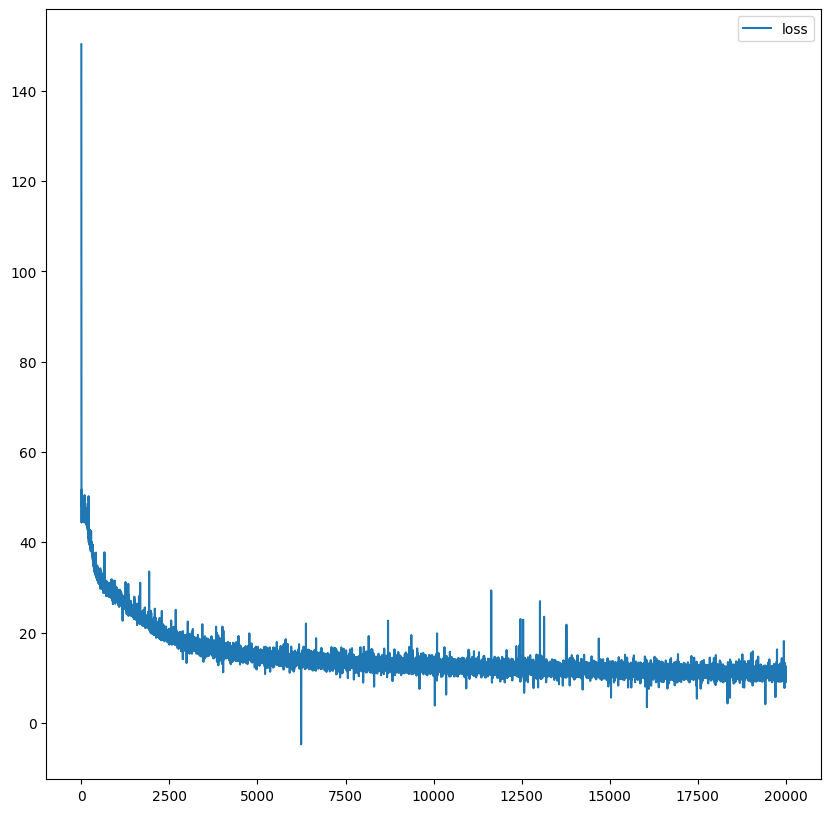

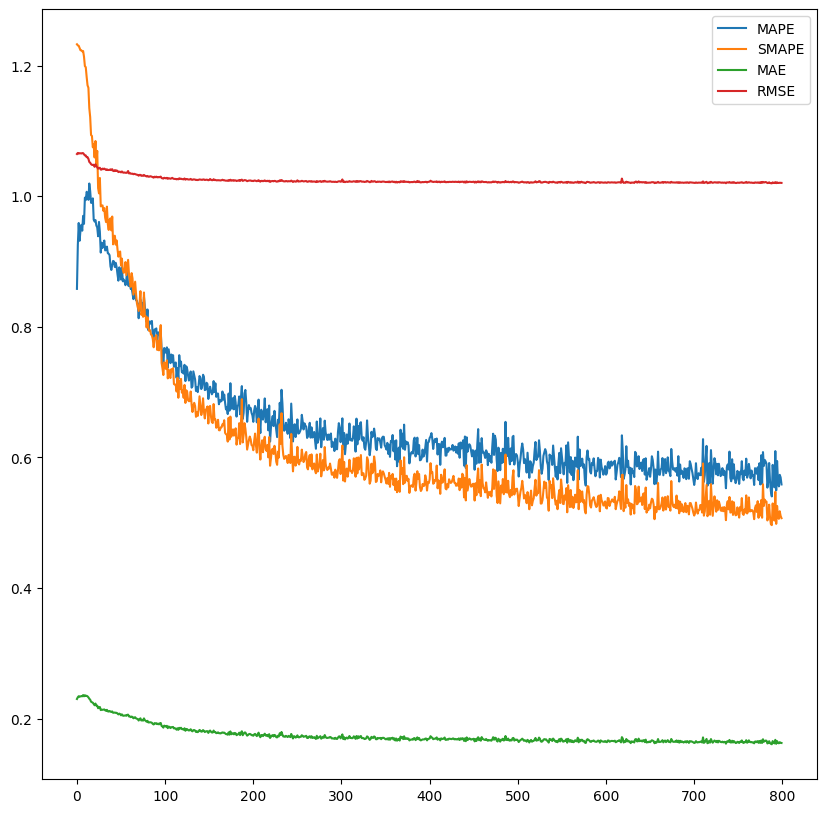

Experiment(setup=ExperimentSetup(coordinate_system=<CoordinateSystem.Spherical: (1,)>, prior_str='cosine', scene_name='cbox_inverted_light', num_flows=4, num_bins=16, hidden_units=64, hidden_layers=4, do_normal_encoding=True, do_in_dir_encoding=True, do_pos_encoding=True, pos_is_hash_grid=True, encode_pos_each_flow=False, latent_to_hashgrid=False, do_scaling_grid_sizes=False, grid_resolutions=[], grid_levels=[], grid_scale_factors=[]), trained_iterations=20000, sample_gen_strategy='light_tracing', sample_model=True, losses=array([150.31182861,  84.23020935,  74.80267334, ...,  11.94233513,
        10.9760704 ,  11.25995255], shape=(20000,)), tracked_errors=True, tracked_error_every=25, mape_list=array([0.85811394, 0.92553633, 0.95894396, 0.93171233, 0.94756198,
       0.9561342 , 0.94722259, 0.96985269, 0.95767069, 0.9977926 ,
       0.99397886, 1.00672722, 1.00365901, 0.99442291, 1.01938176,
       1.00786257, 0.98990887, 0.98973548, 0.99664342, 0.96404856,
       0.96122015, 0.963453

In [ ]:
### Cbox inverted light test

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 20000,
    bounces=6, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

run_experiment(setup, training_context, "cbox_light_inverted_20k_cosine_prior.pkl")

## ---- Hashgrid setup tests

using device: cuda


100%|██████████| 10000/10000 [19:09<00:00,  8.70it/s]
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


average generate_samples_time time 0.008344688057899475
average compute_gradient_time time 0.03386736261844635
average nan_check_clip_time time 0.0006444027185440064
average optimizer_time time 6.04391098022461e-08


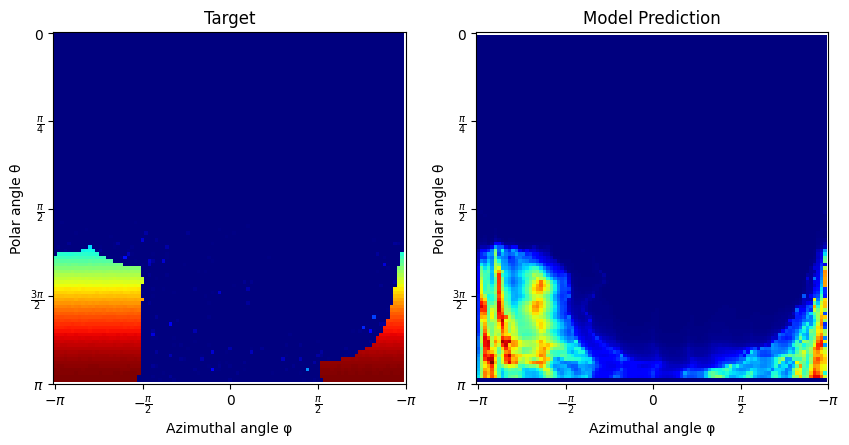

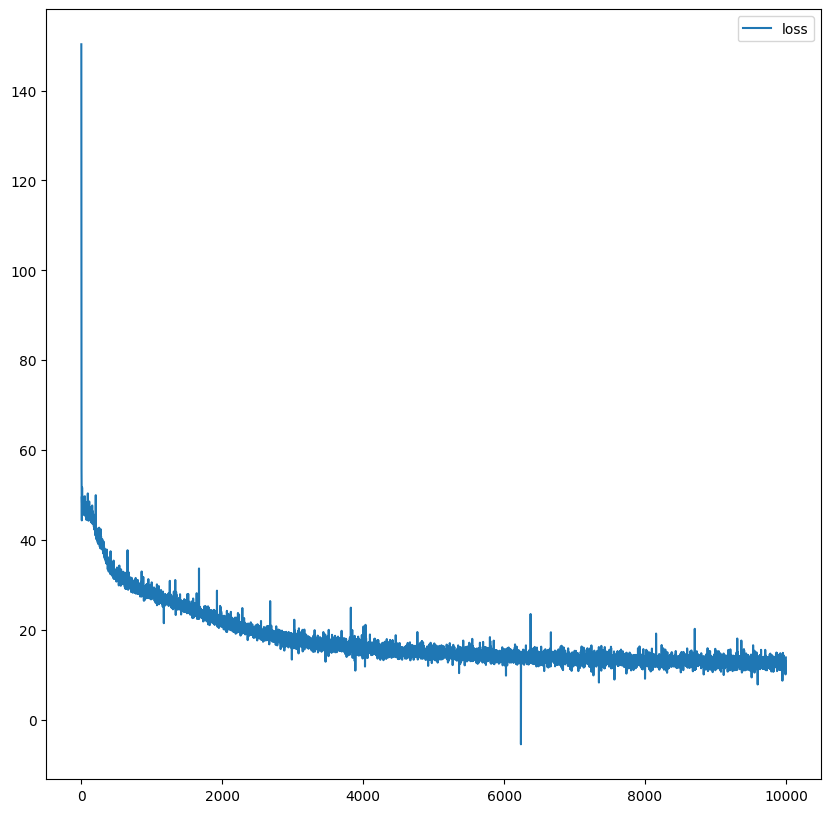

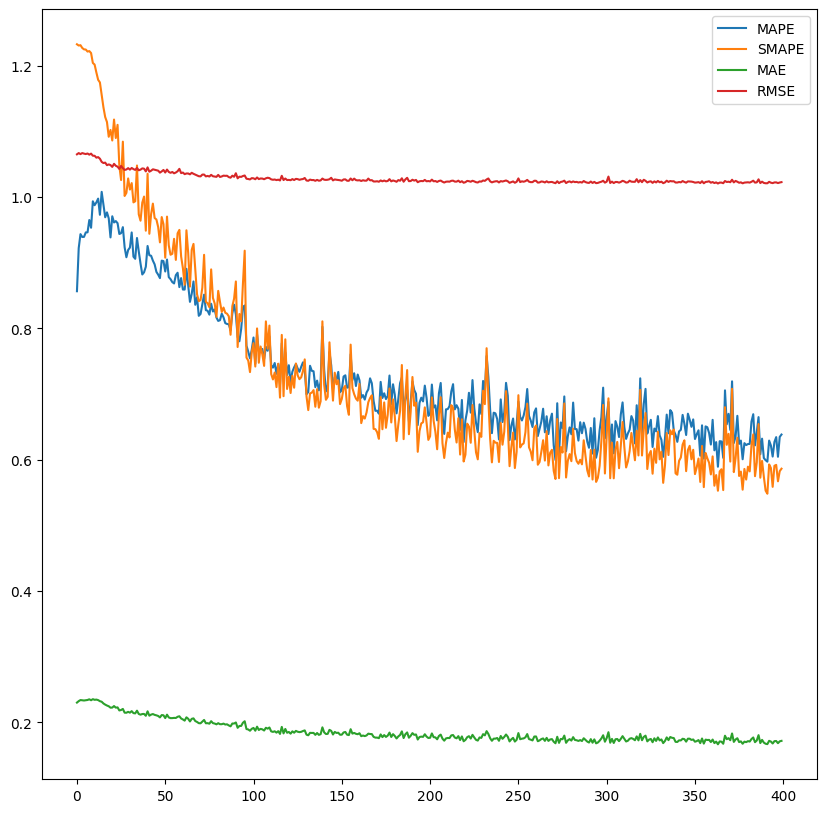

In [13]:
### Single Hashgrid inv cbox

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 10000,
    bounces=5, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

exp = run_experiment(setup, training_context, "hashgrid_setups_single_10k.pkl")

del(exp)

using device: cuda


100%|██████████| 10000/10000 [22:46<00:00,  7.32it/s]


average generate_samples_time time 0.014216693949699401
average compute_gradient_time time 0.03589453279972076
average nan_check_clip_time time 0.0006629114389419556
average optimizer_time time 5.767345428466797e-08


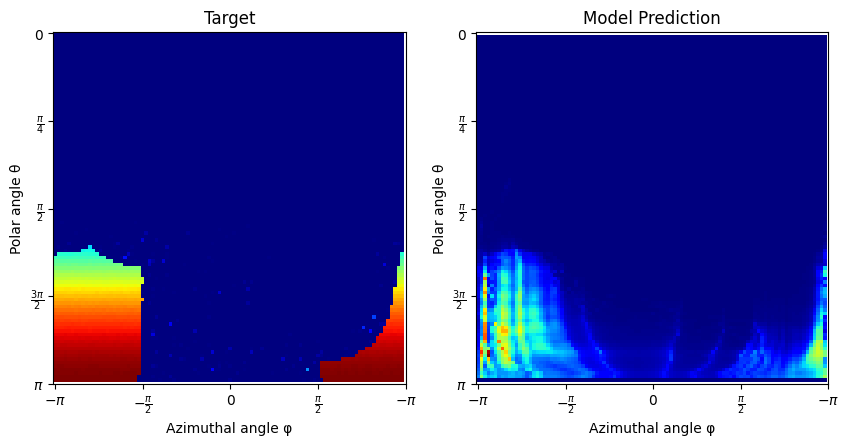

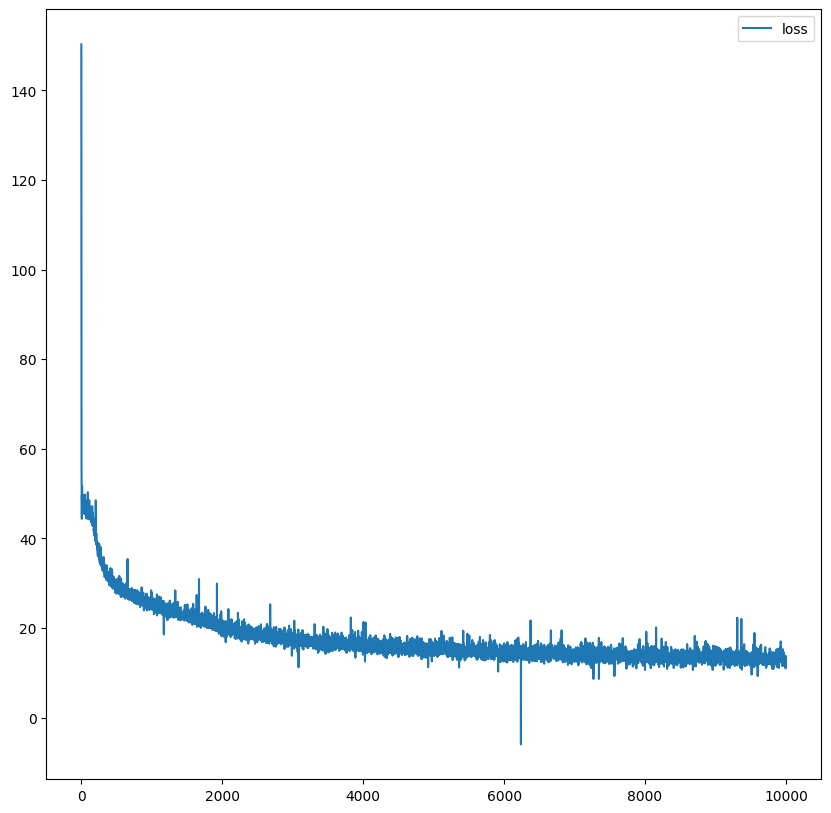

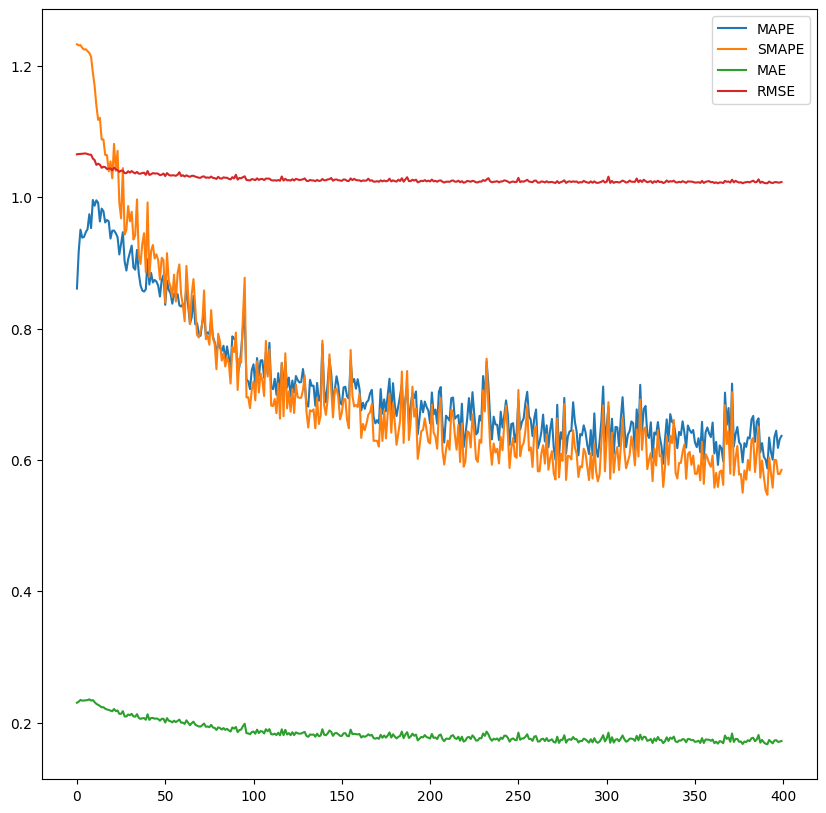

In [14]:
### Mult Hashgrids inv cbox

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 10000,
    bounces=5, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

exp = run_experiment(setup, training_context, "hashgrid_setups_multiple_10k.pkl")

del(exp)

using device: cuda
using device: cuda


  0%|          | 0/50000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:85: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
100%|██████████| 50000/50000 [53:38<00:00, 15.54it/s]
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


average generate_samples_time time 0.009140655679702759
average compute_gradient_time time 0.04317798221111298
average nan_check_clip_time time 0.0008009349060058594
average optimizer_time time 1.4700889587402344e-08


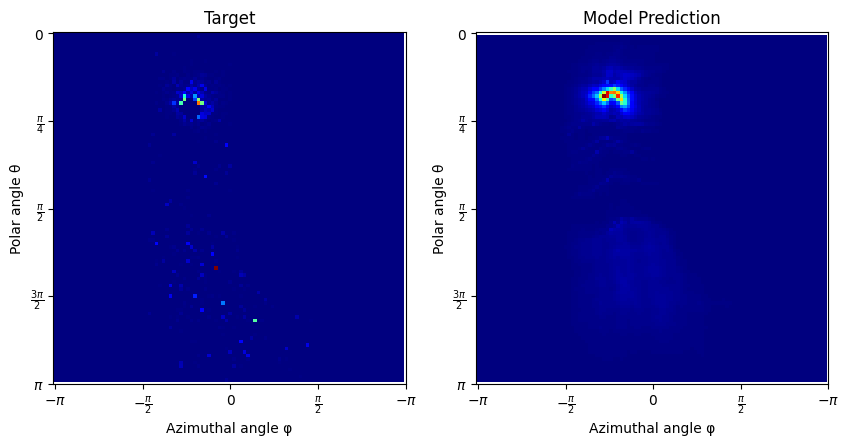

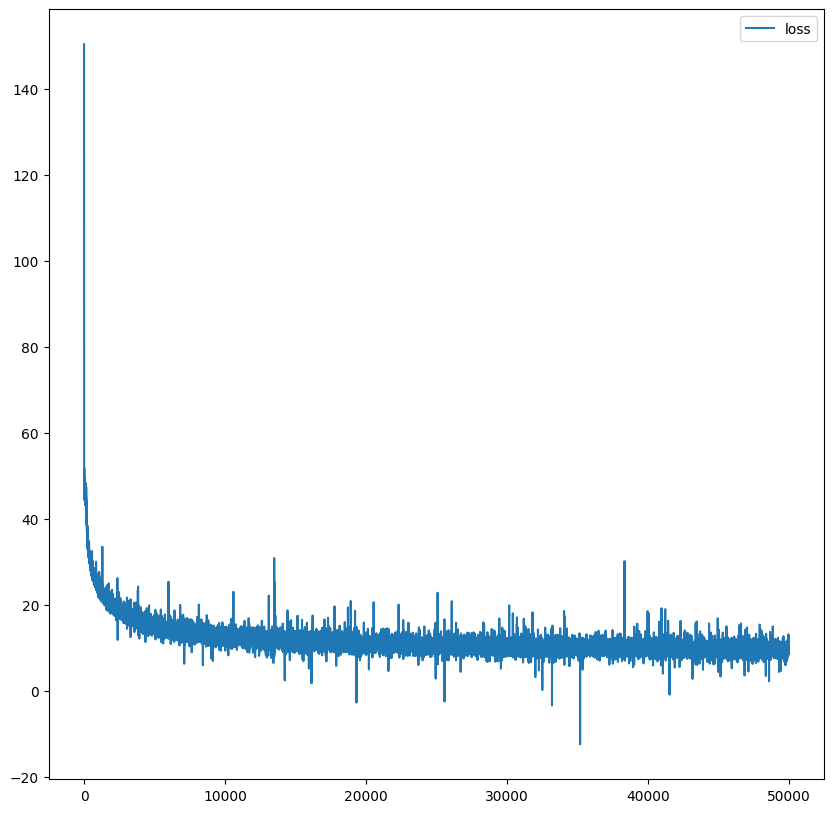

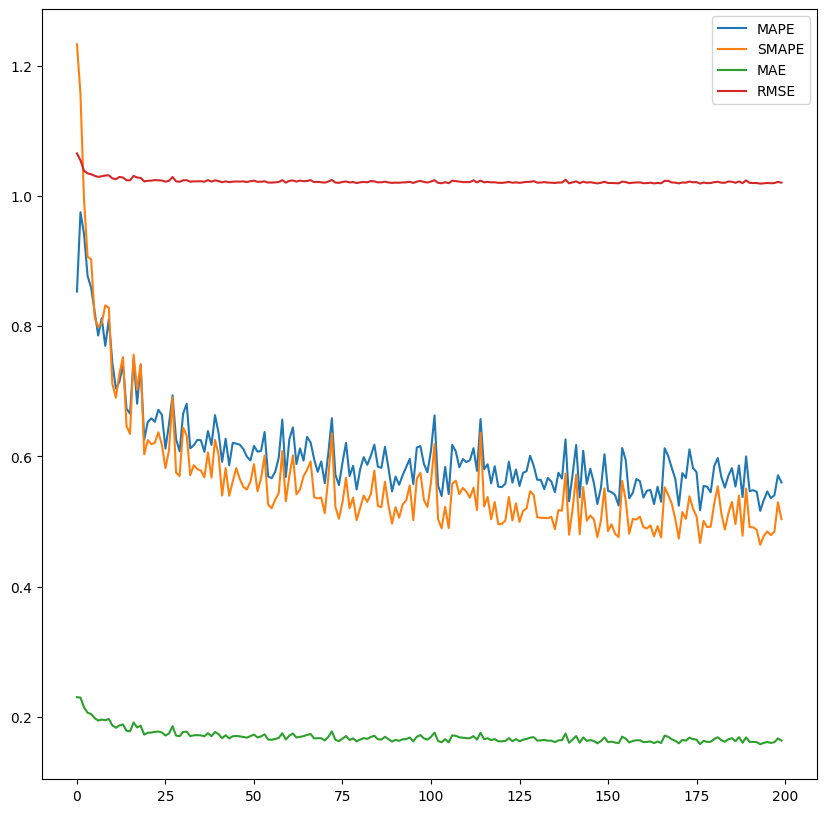

In [11]:
### Slightly Staggered Hashgrids inv cbox

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = True,

    grid_resolutions=[10, 12, 14, 16],
    grid_levels=[5, 6, 7, 8],
    grid_scale_factors=[1.0, 1.33, 1.66, 2.0],
)

model = create_model_from_Setup(setup=setup)


num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "hashgrid_setups_staggered_slight_50k.pkl")

del(exp)

using device: cuda


100%|██████████| 50000/50000 [53:12<00:00, 15.66it/s] 


average generate_samples_time time 0.008828047814369201
average compute_gradient_time time 0.04263788542747497
average nan_check_clip_time time 0.0007913111495971679
average optimizer_time time 8.70227813720703e-09


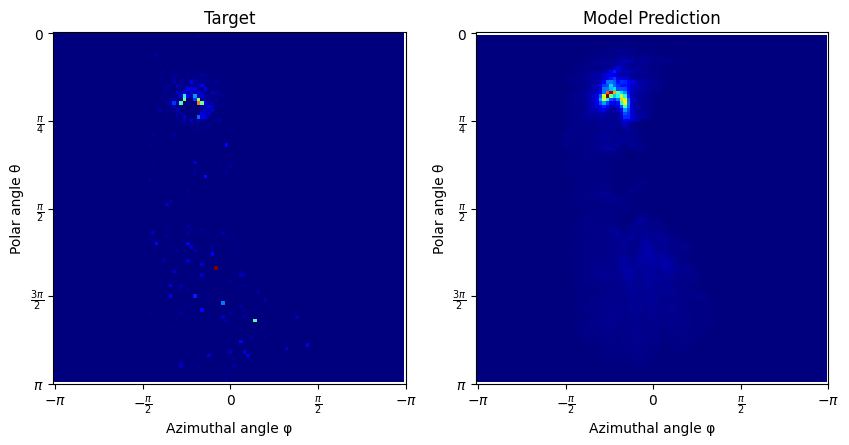

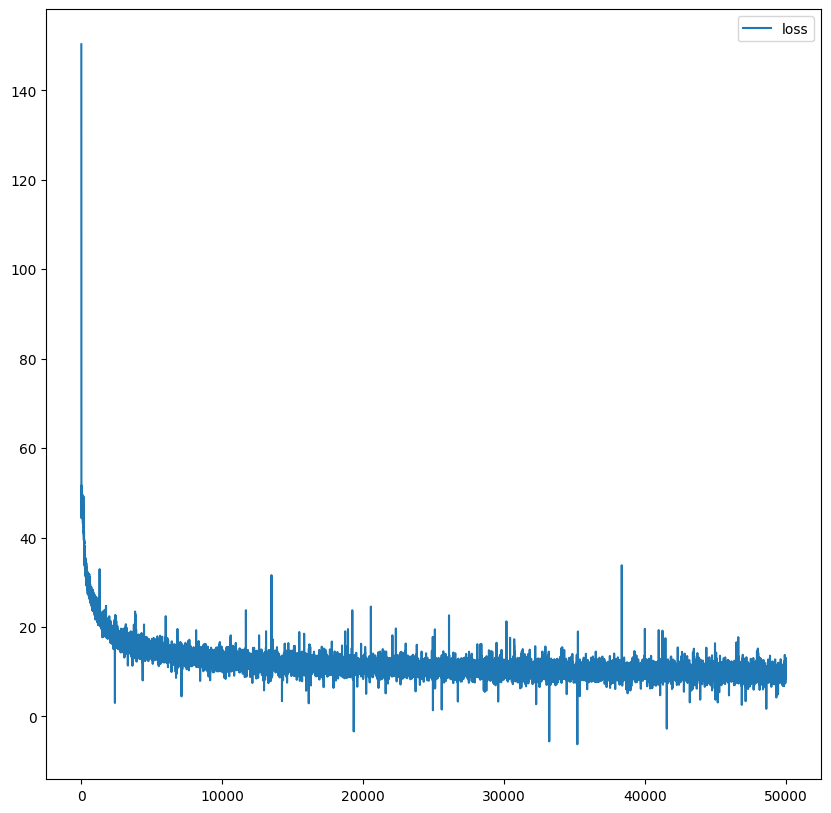

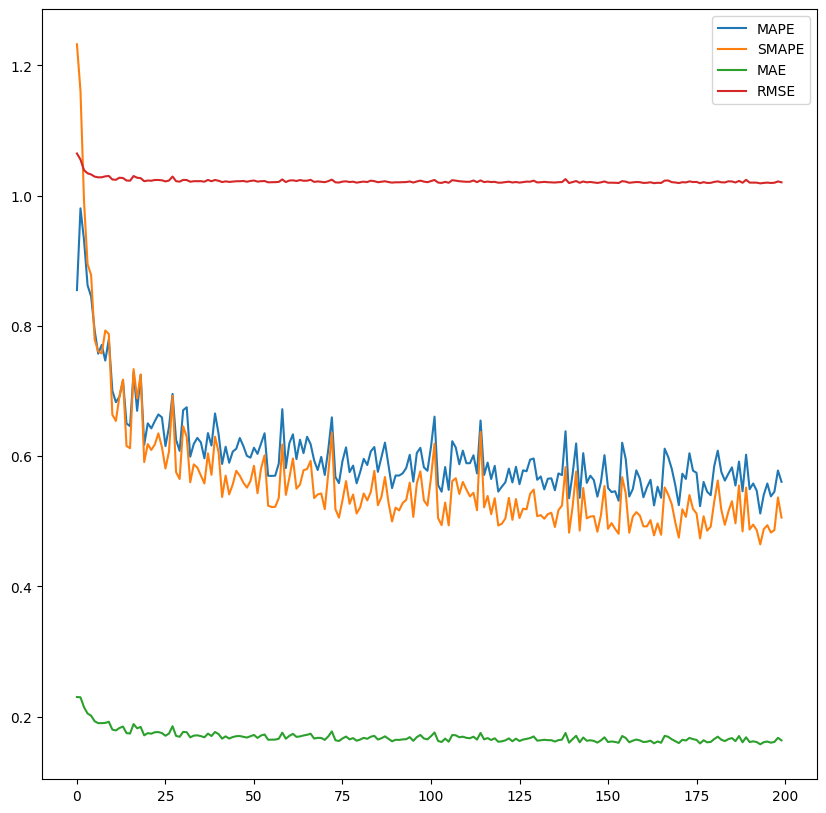

In [12]:
### Aggresively Staggered Hashgrids inv cbox

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    lr = 3e-4,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = True,

    grid_resolutions=[4, 8, 12, 16],
    grid_levels=[2, 4, 6, 8],
    grid_scale_factors=[1.0, 1.33, 1.66, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 250
)

exp = run_experiment(setup, training_context, "hashgrid_setups_staggered_aggresive_50k.pkl")

del(exp)

{'nested': [{'degree': 4, 'n_dims_to_encode': 3, 'otype': 'SphericalHarmonics'},
            {'degree': 4, 'n_dims_to_encode': 3, 'otype': 'SphericalHarmonics'},
            {'n_dims_to_encode': 3, 'otype': 'Identity'}],
 'otype': 'Composite'}
------
{'nested': [{'n_dims_to_encode': 16, 'otype': 'Identity'},
            {'n_dims_to_encode': 16, 'otype': 'Identity'},
            {'base_resolution': 16,
             'interpolation': 'Linear',
             'log2_hashmap_size': 19,
             'n_dims_to_encode': 4,
             'n_features_per_level': 2,
             'n_levels': 8,
             'otype': 'Grid',
             'per_level_scale': 2.0,
             'type': 'Hash'}],
 'otype': 'Composite'}
------
35
using device: cuda


100%|██████████| 10/10 [00:03<00:00,  2.82it/s]


average generate_samples_time time 0.029323887825012208
average compute_gradient_time time 0.10424878597259521
average nan_check_clip_time time 0.003652787208557129
average optimizer_time time 5.664825439453125e-05


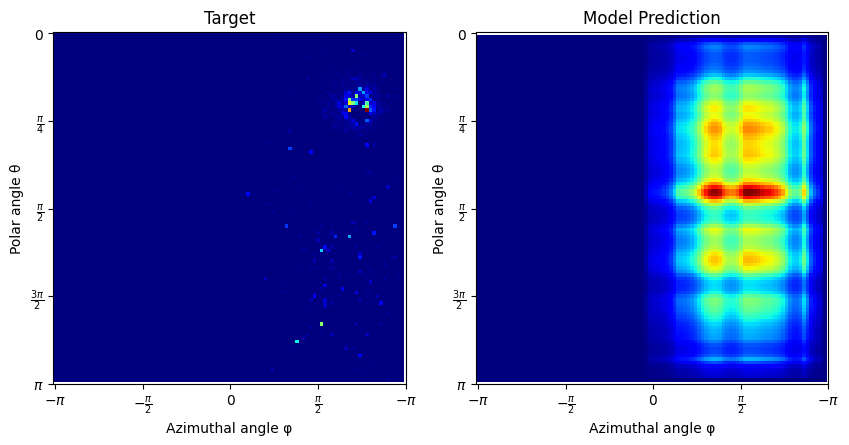

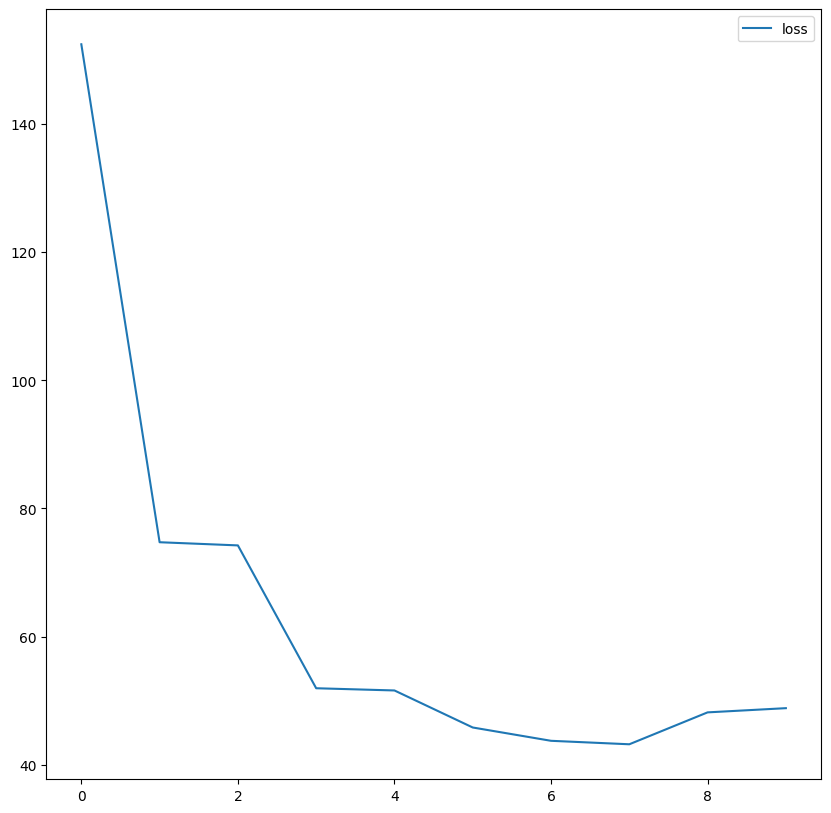

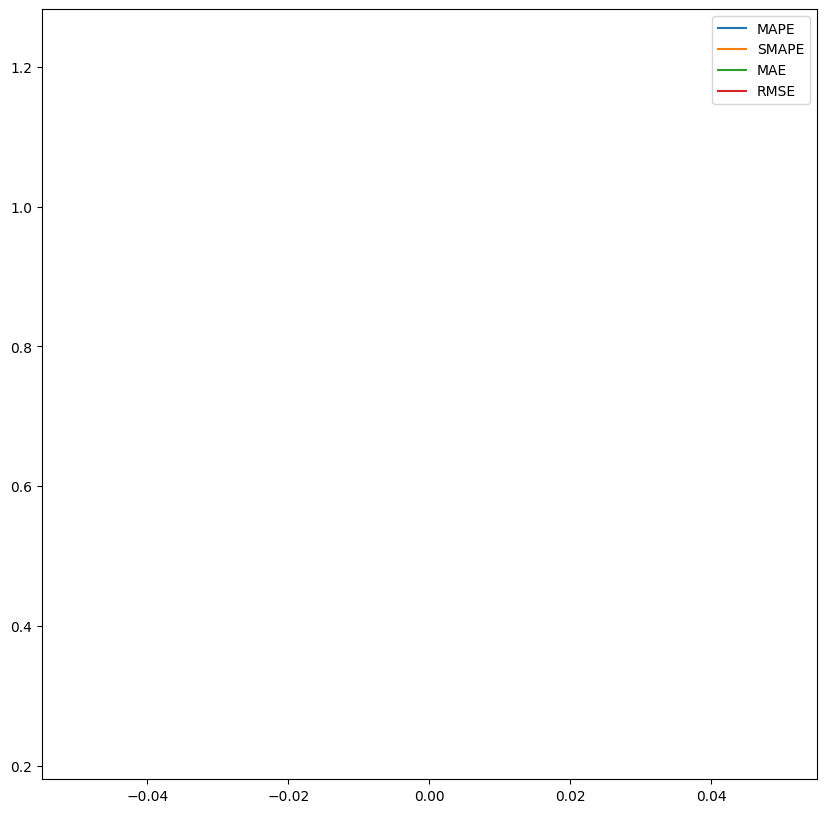

In [62]:
### Mult Hashgrids latent encode inv cbox

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 10,
    bounces=5, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

exp = run_experiment(setup, training_context, "test.pkl")

del(exp)

{'nested': [{'degree': 4, 'n_dims_to_encode': 3, 'otype': 'SphericalHarmonics'},
            {'degree': 4, 'n_dims_to_encode': 3, 'otype': 'SphericalHarmonics'},
            {'n_dims_to_encode': 3, 'otype': 'Identity'}],
 'otype': 'Composite'}
------
{'nested': [{'n_dims_to_encode': 16, 'otype': 'Identity'},
            {'n_dims_to_encode': 16, 'otype': 'Identity'},
            {'base_resolution': 16,
             'interpolation': 'Linear',
             'log2_hashmap_size': 19,
             'n_dims_to_encode': 4,
             'n_features_per_level': 2,
             'n_levels': 8,
             'otype': 'Grid',
             'per_level_scale': 2.0,
             'type': 'Hash'}],
 'otype': 'Composite'}
------
35
using device: cuda


100%|██████████| 10000/10000 [21:18<00:00,  7.82it/s]


average generate_samples_time time 0.012438747954368591
average compute_gradient_time time 0.03276926431655884
average nan_check_clip_time time 0.0005678357124328613
average optimizer_time time 5.421638488769531e-08


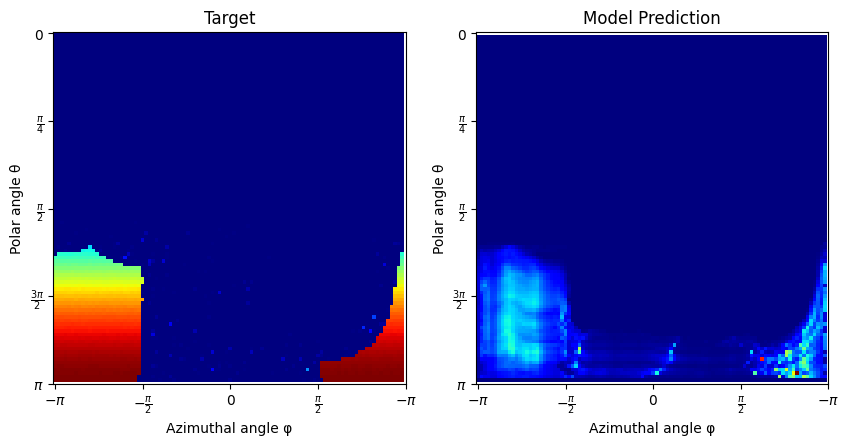

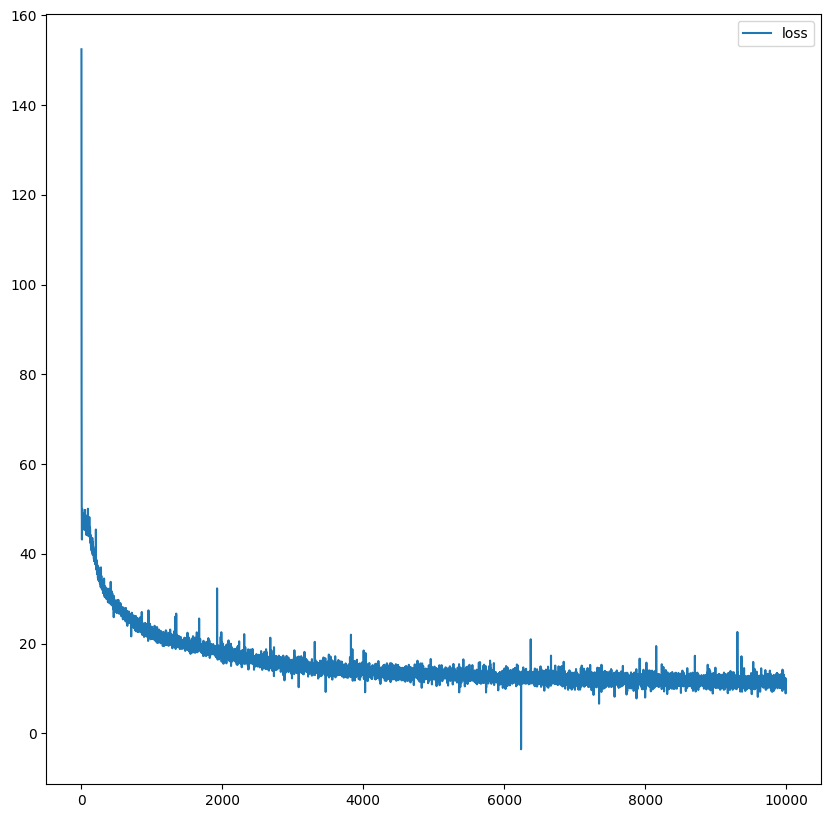

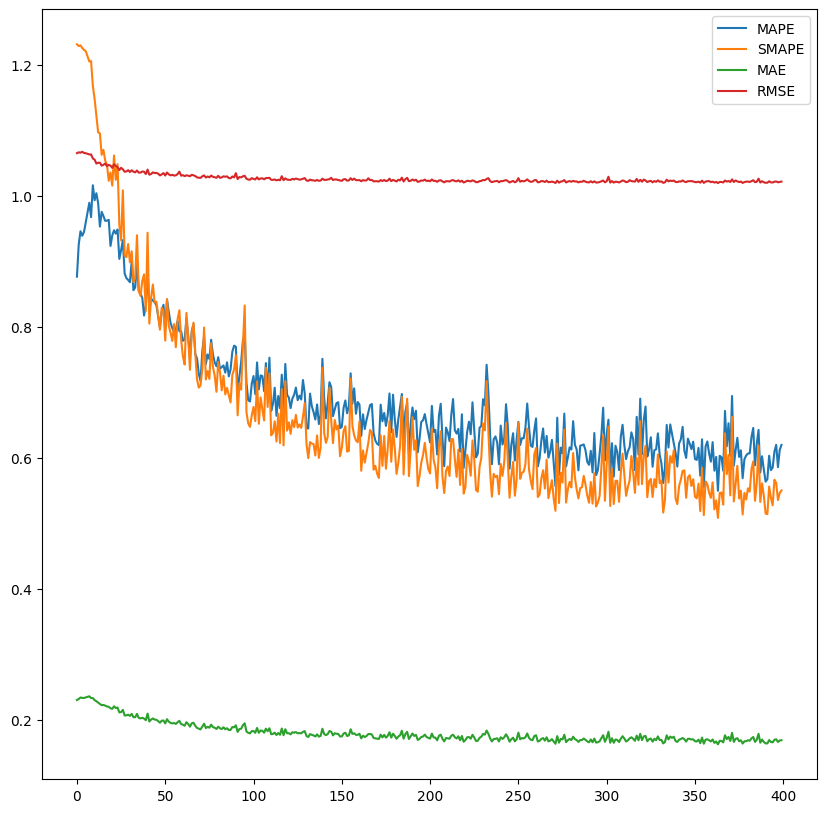

In [14]:
### Slight Staggered Hashgrids latent encode inv cbox

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = True,

    grid_resolutions=[10, 12, 14, 16],
    grid_levels=[5, 6, 7, 8],
    grid_scale_factors=[1.0, 1.33, 1.66, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 10000,
    bounces=5, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

exp = run_experiment(setup, training_context, "hashgrid_setups_staggered_slight_latent_encode_10k.pkl")

del(exp)

{'nested': [{'degree': 4, 'n_dims_to_encode': 3, 'otype': 'SphericalHarmonics'},
            {'degree': 4, 'n_dims_to_encode': 3, 'otype': 'SphericalHarmonics'},
            {'n_dims_to_encode': 3, 'otype': 'Identity'}],
 'otype': 'Composite'}
------
{'nested': [{'n_dims_to_encode': 16, 'otype': 'Identity'},
            {'n_dims_to_encode': 16, 'otype': 'Identity'},
            {'base_resolution': 16,
             'interpolation': 'Linear',
             'log2_hashmap_size': 19,
             'n_dims_to_encode': 4,
             'n_features_per_level': 2,
             'n_levels': 8,
             'otype': 'Grid',
             'per_level_scale': 2.0,
             'type': 'Hash'}],
 'otype': 'Composite'}
------
35
using device: cuda


100%|██████████| 10000/10000 [21:47<00:00,  7.65it/s]


average generate_samples_time time 0.011989612674713135
average compute_gradient_time time 0.03206963896751404
average nan_check_clip_time time 0.0005480375051498414
average optimizer_time time 4.360675811767578e-08


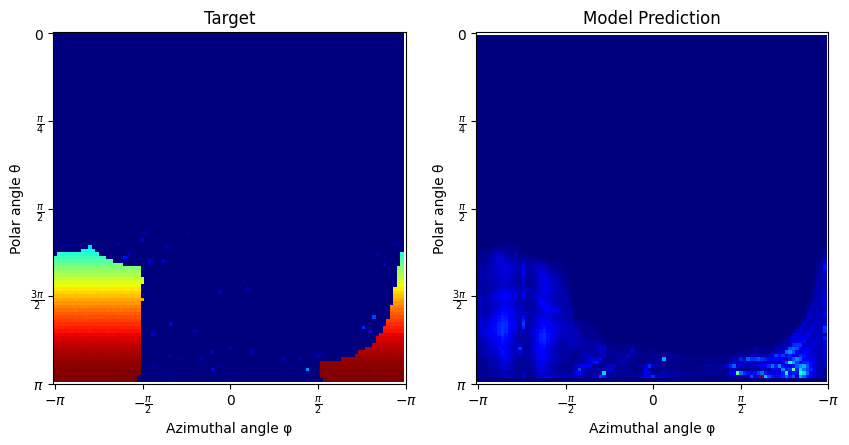

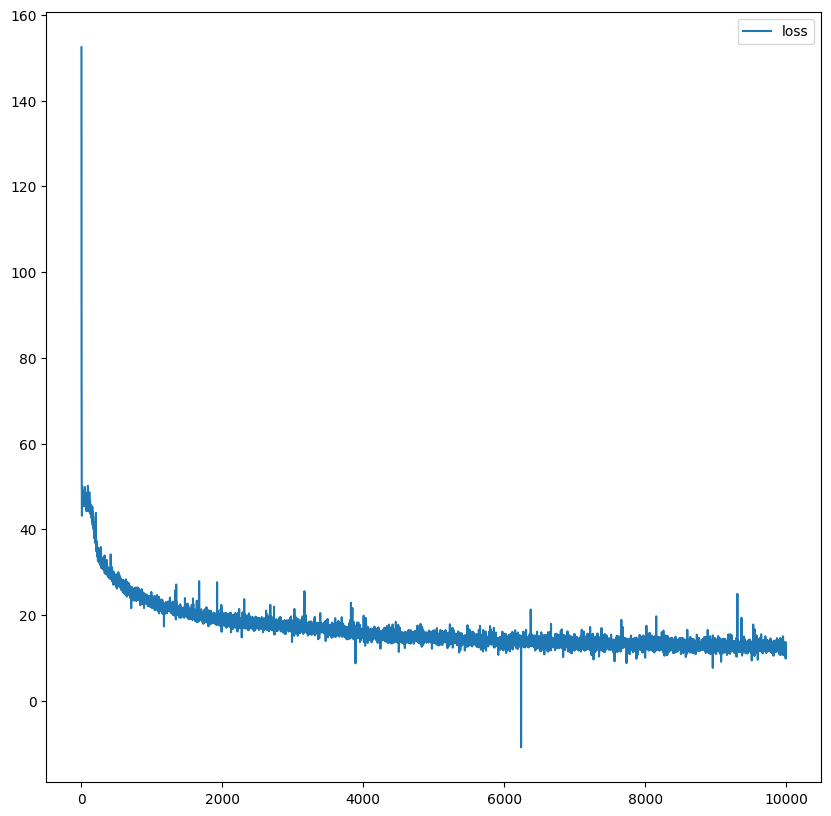

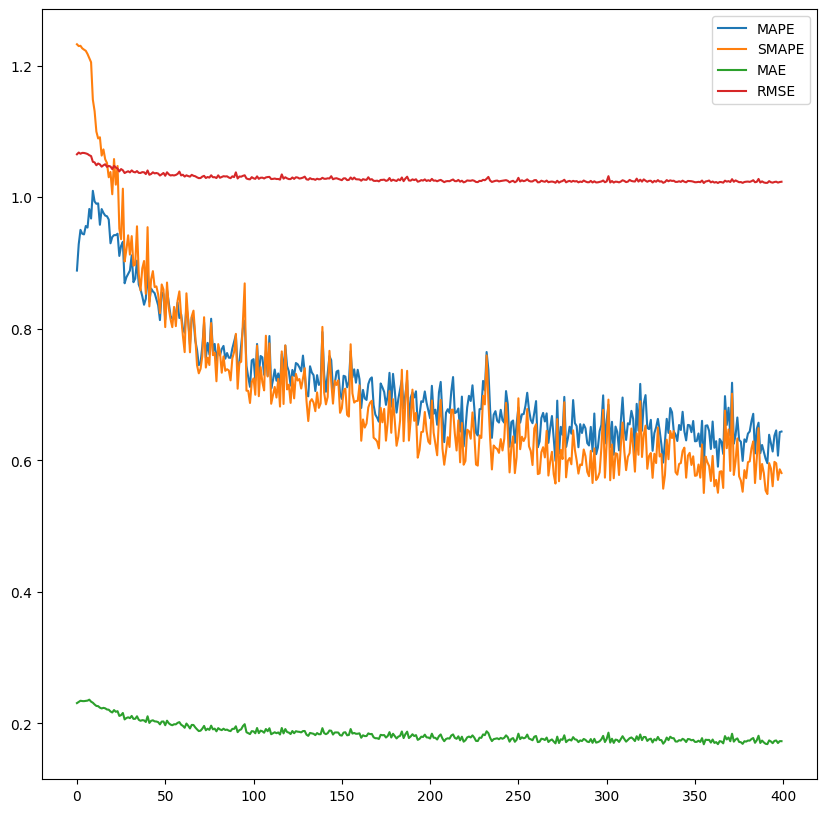

In [15]:
### Agressively Staggered Hashgrids inv cbox

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = True,

    grid_resolutions=[4, 8, 12, 16],
    grid_levels=[2, 4, 6, 8],
    grid_scale_factors=[1.0, 1.33, 1.66, 2.0],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 10000,
    bounces=5, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 25
)

exp = run_experiment(setup, training_context, "hashgrid_setups_staggered_aggresive_latent_encode_10k.pkl")

del(exp)

## ---- Multiple grids with and without latent many iterations

## TMP: TODO run the next 2

using device: cuda


  0%|          | 0/150000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:85: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
100%|██████████| 150000/150000 [2:10:41<00:00, 19.13it/s] 
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


average generate_samples_time time 0.010793319980303447
average compute_gradient_time time 0.032509442057609556
average nan_check_clip_time time 0.0005932035811742147
average optimizer_time time 3.0310948689778646e-09


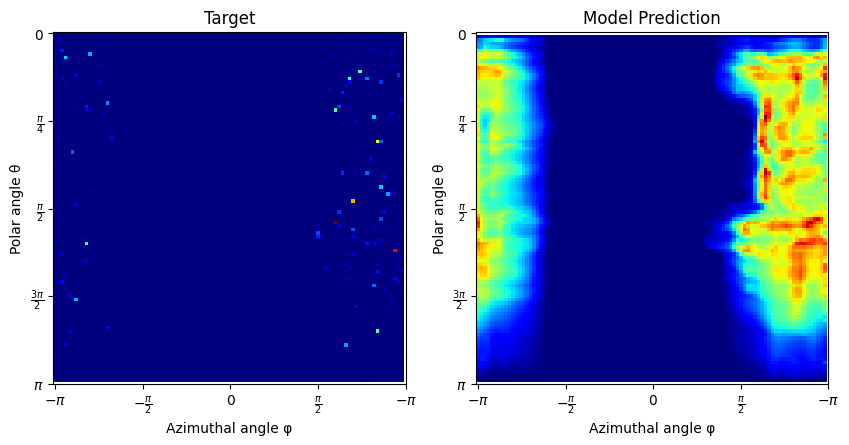

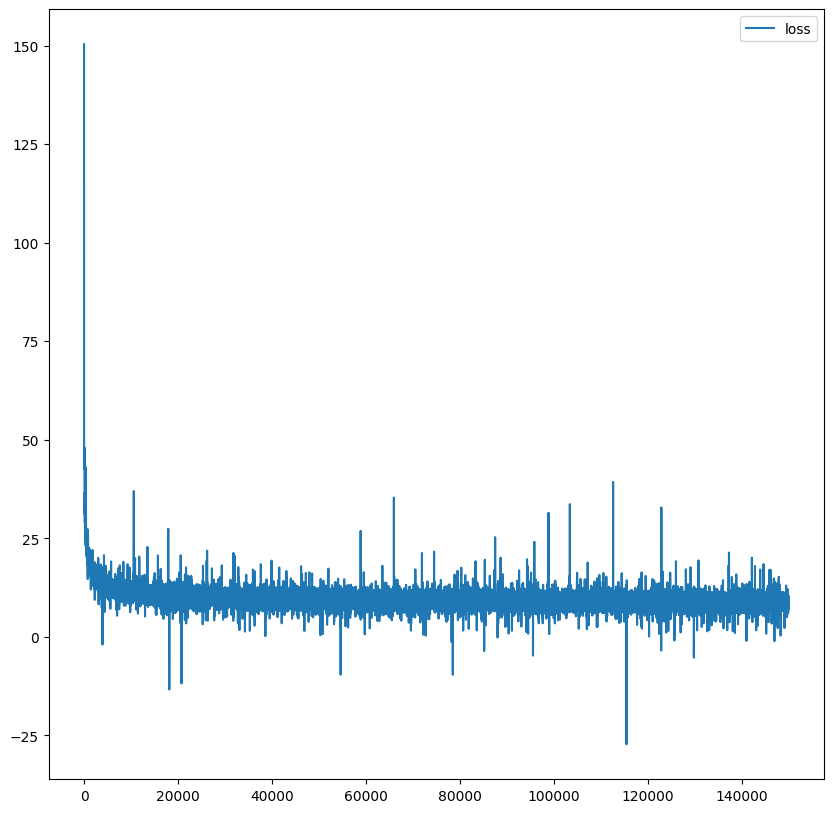

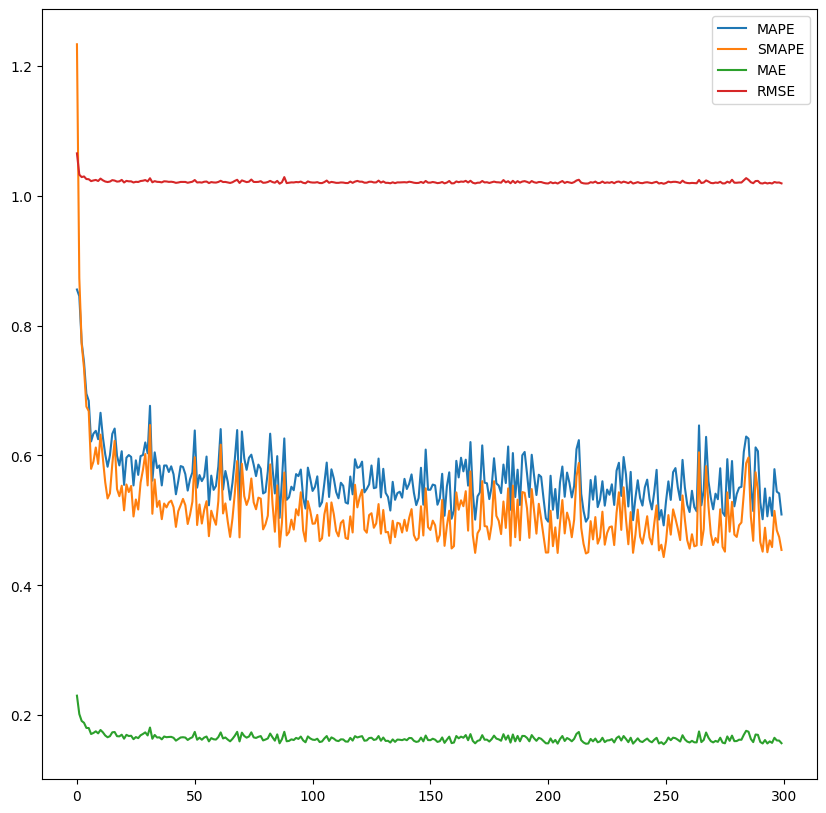

In [11]:
### Mult Hashgrids inv cbox

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 1e-3,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 150000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 500
)

exp = run_experiment(setup, training_context, "hashgrid_setups_multiple_150k_lr_1e-3.pkl")

del(exp)

using device: cuda


100%|██████████| 150000/150000 [2:26:45<00:00, 17.03it/s] 


average generate_samples_time time 0.012200069362322489
average compute_gradient_time time 0.035049683210055034
average nan_check_clip_time time 0.0005474835538864136
average optimizer_time time 3.021558125813802e-09


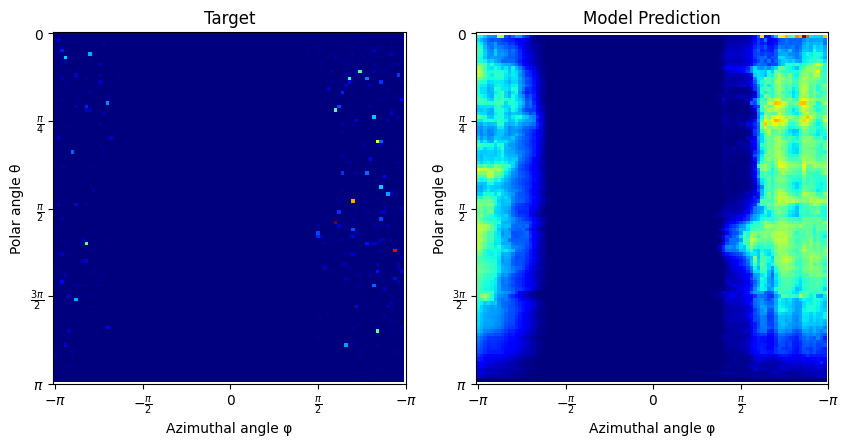

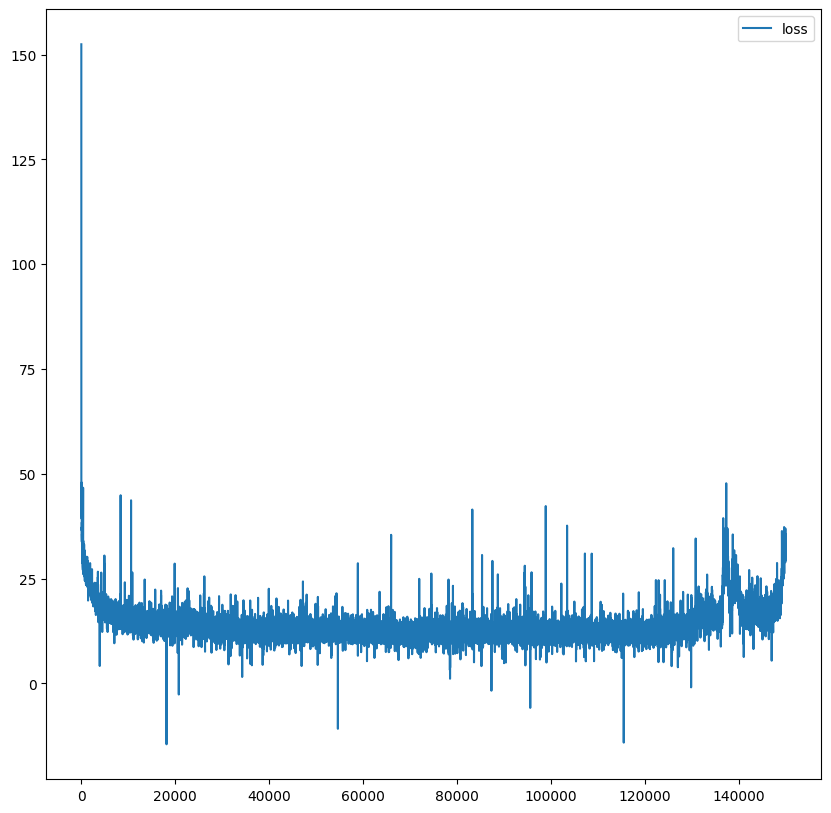

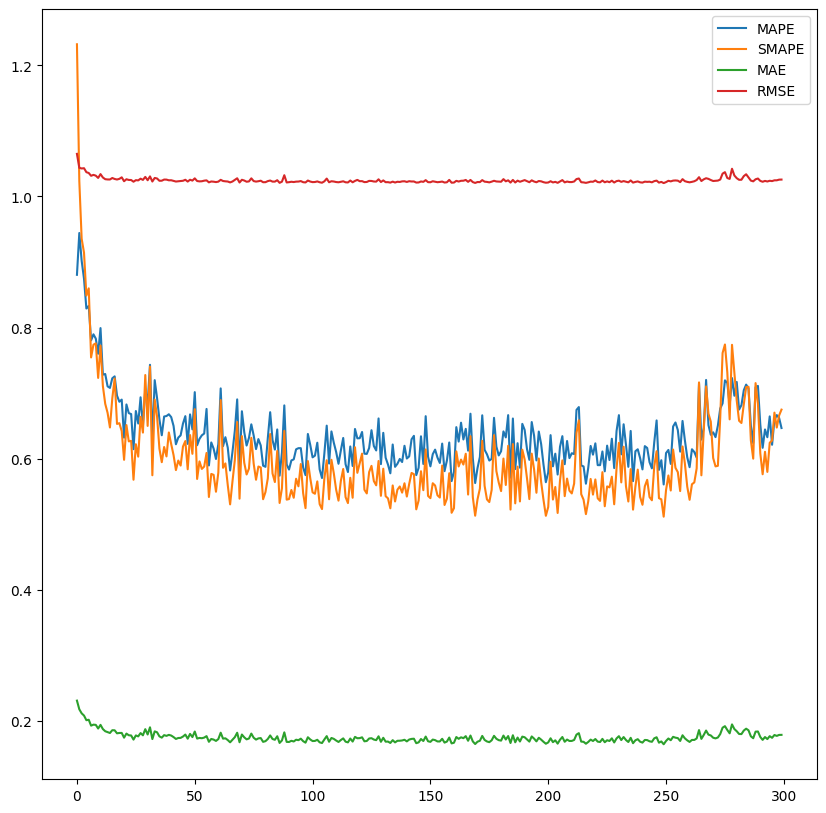

In [12]:
### Mult Hashgrids latent encode inv cbox

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'cbox_inverted_light',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 1e-3,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = True,
    latent_to_hashgrid = True,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 150000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 500
)

exp = run_experiment(setup, training_context, "hashgrid_setups_multiple_latent_encode_150k_lr_1e-3.pkl")
 
del(exp)

## ---- General Spaceship

using device: cuda


  0%|          | 0/50000 [00:00<?, ?it/s]d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:85: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1
100%|██████████| 50000/50000 [51:39<00:00, 16.13it/s]
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


average generate_samples_time time 0.024588149433135986
average compute_gradient_time time 0.030483345646858215
average nan_check_clip_time time 0.0005787183046340942
average optimizer_time time 1.0442733764648437e-08


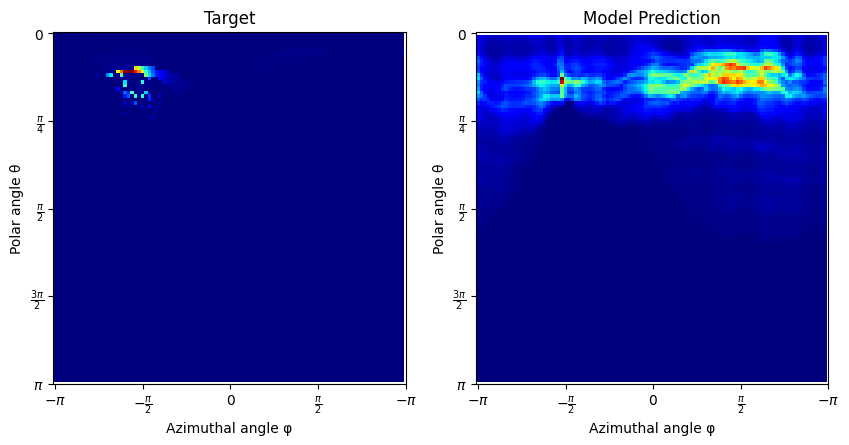

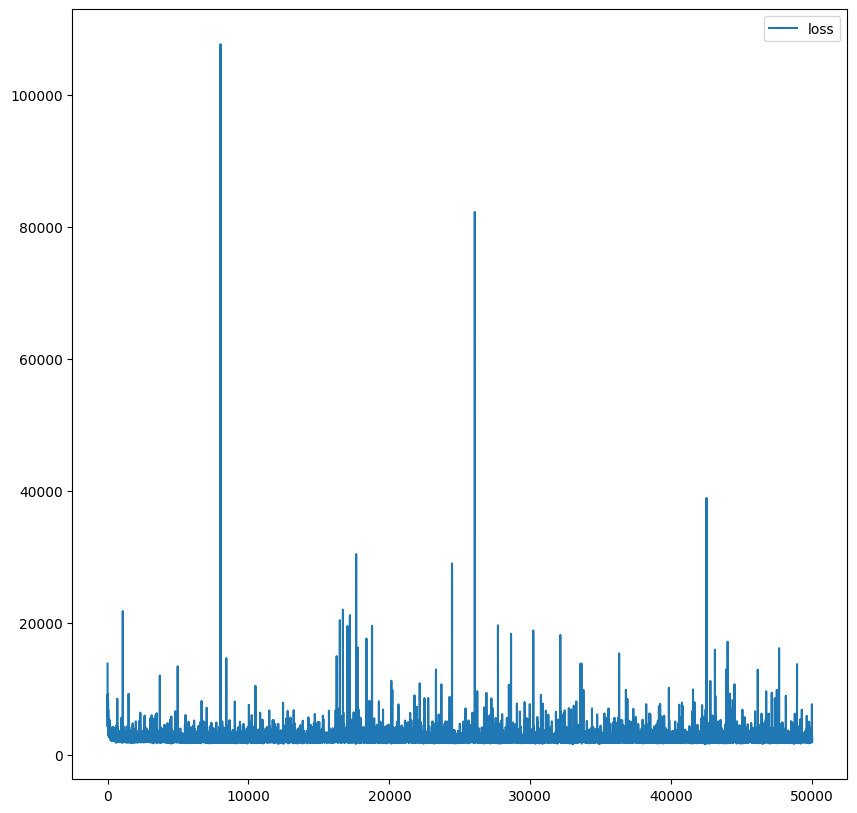

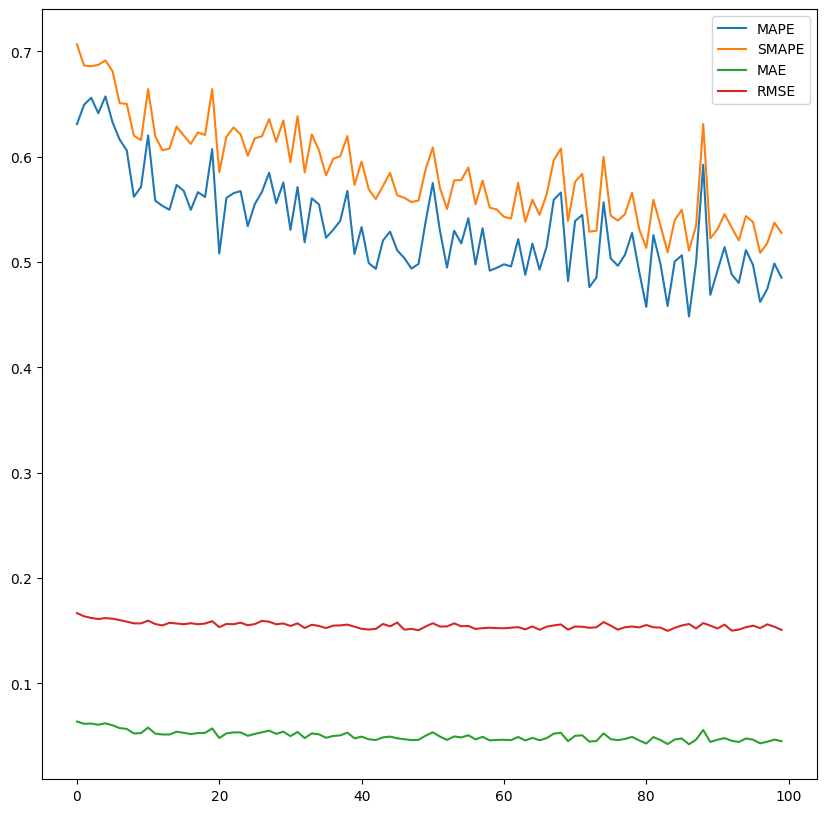

In [11]:
### Spaceship cosine 50k

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='cosine',
    scene_name = 'spaceship',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 500
)

exp = run_experiment(setup, training_context, "spaceship_cosine_50k.pkl")
 
del(exp)

d:\Studium\Masters\Masters\scripts\..\src\priors.py:23: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("domain", torch.tensor(domain))


using device: cuda


100%|██████████| 50000/50000 [51:18<00:00, 16.24it/s]


average generate_samples_time time 0.02482447090625763
average compute_gradient_time time 0.029686234240531923
average nan_check_clip_time time 0.0005632426071166992
average optimizer_time time 8.85009765625e-09


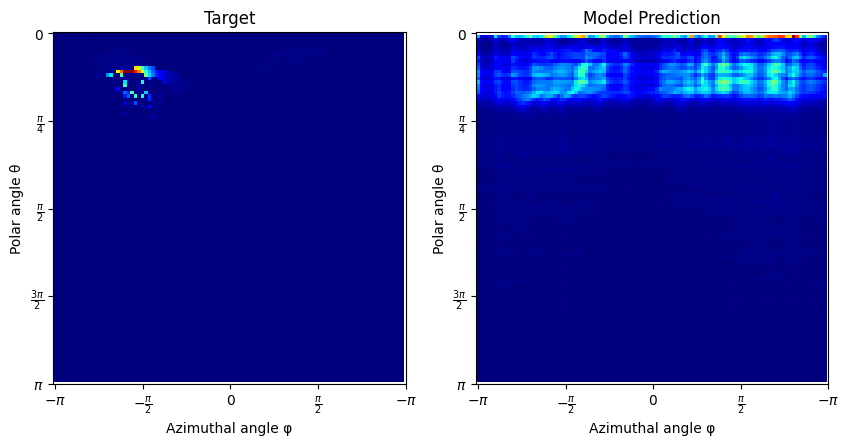

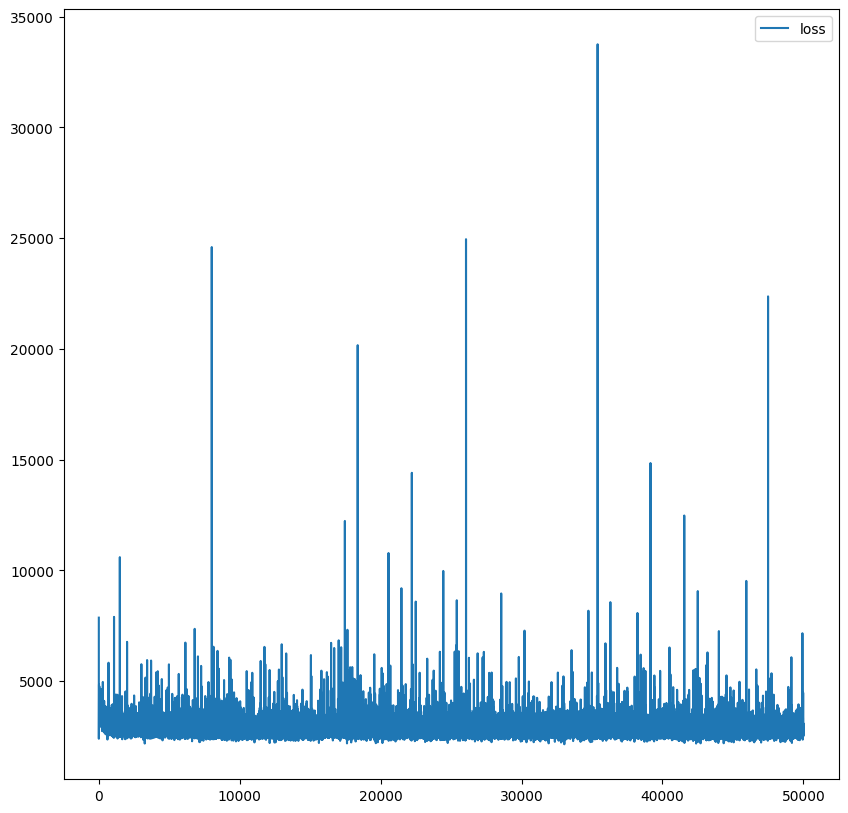

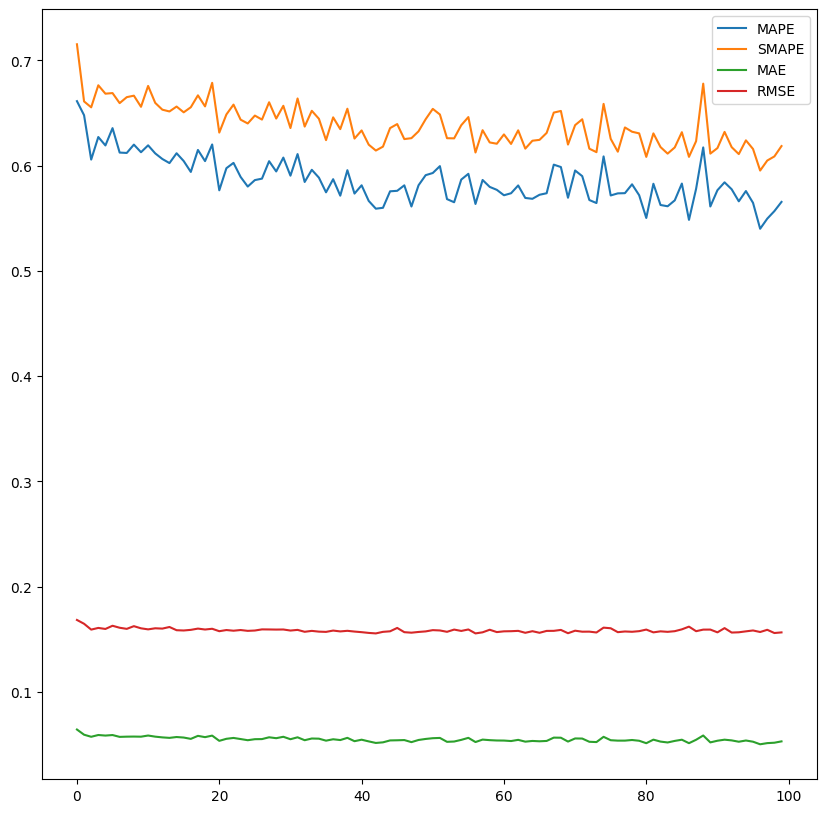

In [12]:
### Spaceship uniform 50k

setup = ExperimentSetup(
    coordinate_system=CoordinateSystem.Spherical,
    prior_str='uniform',
    scene_name = 'spaceship',

    num_flows = 4,
    num_bins  = 16,
    hidden_units = 64,
    hidden_layers = 4,

    lr = 3e-4,

    do_normal_encoding = True,
    do_in_dir_encoding = True,
    do_pos_encoding    = True,

    pos_is_hash_grid=True,
    encode_pos_each_flow = False,
    latent_to_hashgrid = False,
    do_scaling_grid_sizes = False,

    grid_resolutions=[],
    grid_levels=[],
    grid_scale_factors=[],
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(
    iterations = 50000,
    bounces=4, 
    spp=1, 
    num_samples = num_samples,
    width = width,
    height = height,
    include_brdf = setup.do_in_dir_encoding,
    sample_generation_strategy = "light_tracing",
    # sample_generation_strategy = "sensor_sampling",
    sample_model = True,
    clip_error_calcs = True,
    track_error = True, 
    track_error_every = 500
)

exp = run_experiment(setup, training_context, "spaceship_uniform_50k.pkl")
 
del(exp)

## ----

100%|██████████| 5000/5000 [08:28<00:00,  9.83it/s]


average generate_samples_time time 0.005349697256088257
average compute_gradient_time time 0.03257879462242126
average nan_check_clip_time time 0.0005871468544006347
average optimizer_time time 1.0471343994140625e-07


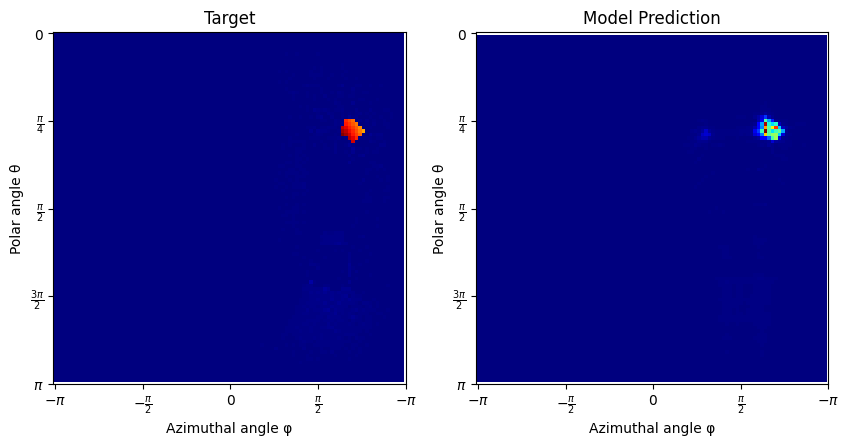

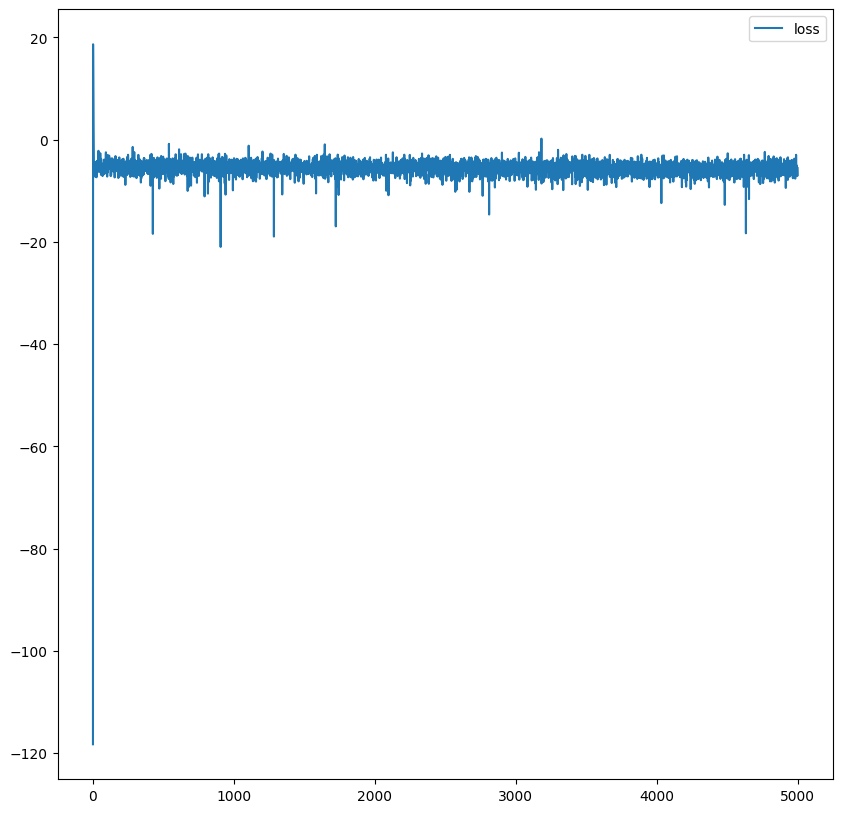

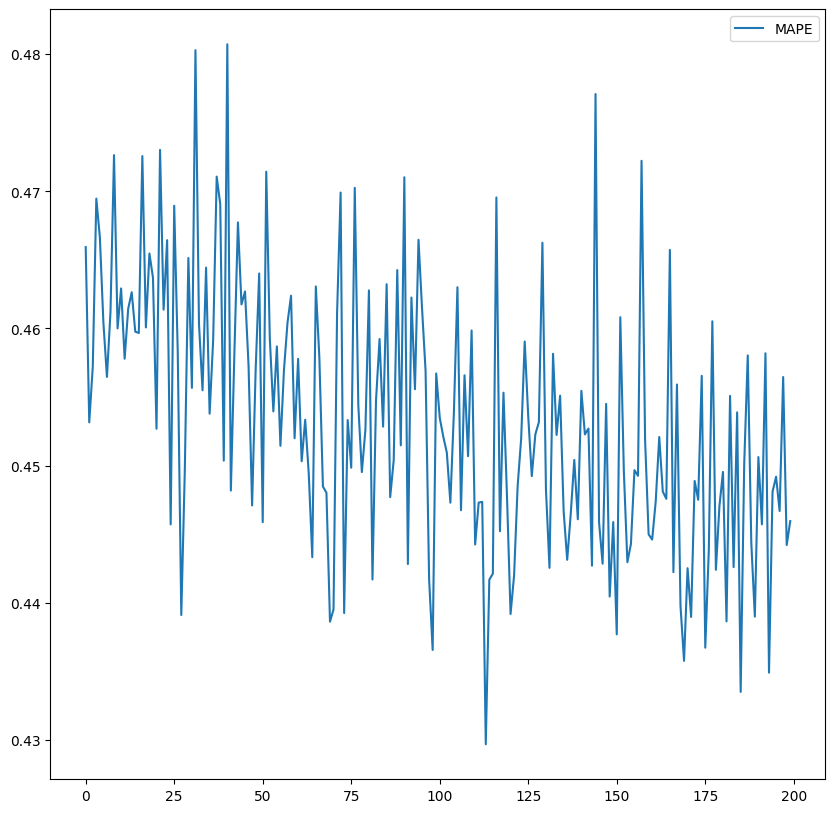

100%|██████████| 5000/5000 [08:43<00:00,  9.56it/s]


average generate_samples_time time 0.006469518756866455
average compute_gradient_time time 0.03313626008033752
average nan_check_clip_time time 0.0005839308738708496
average optimizer_time time 9.107589721679688e-08


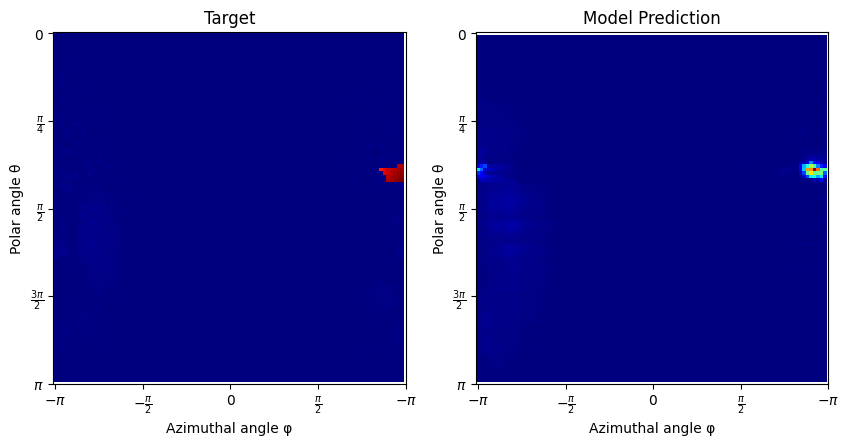

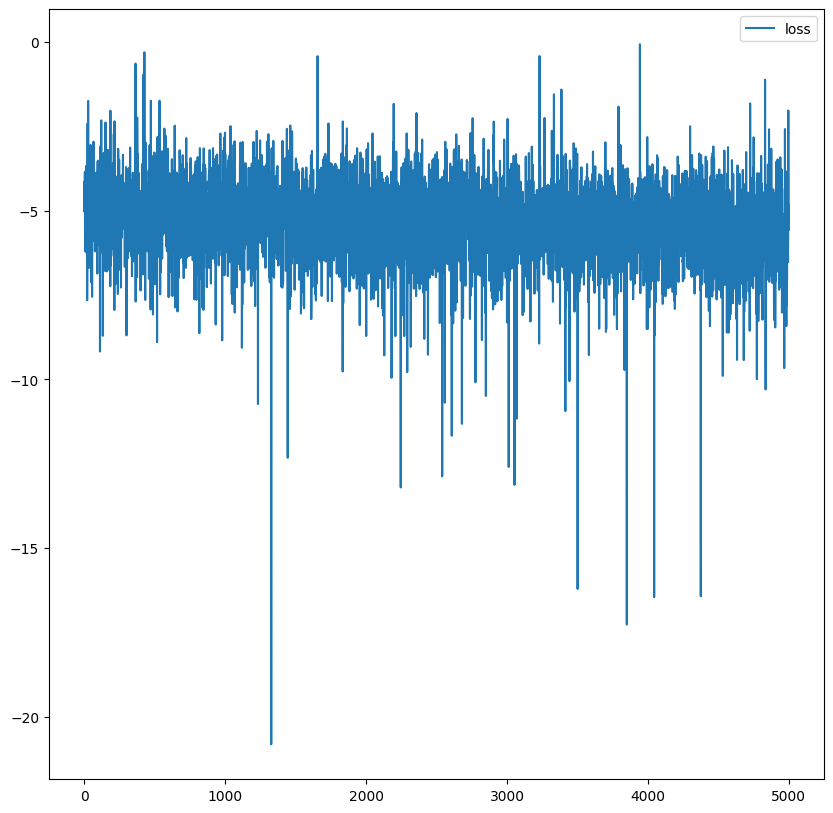

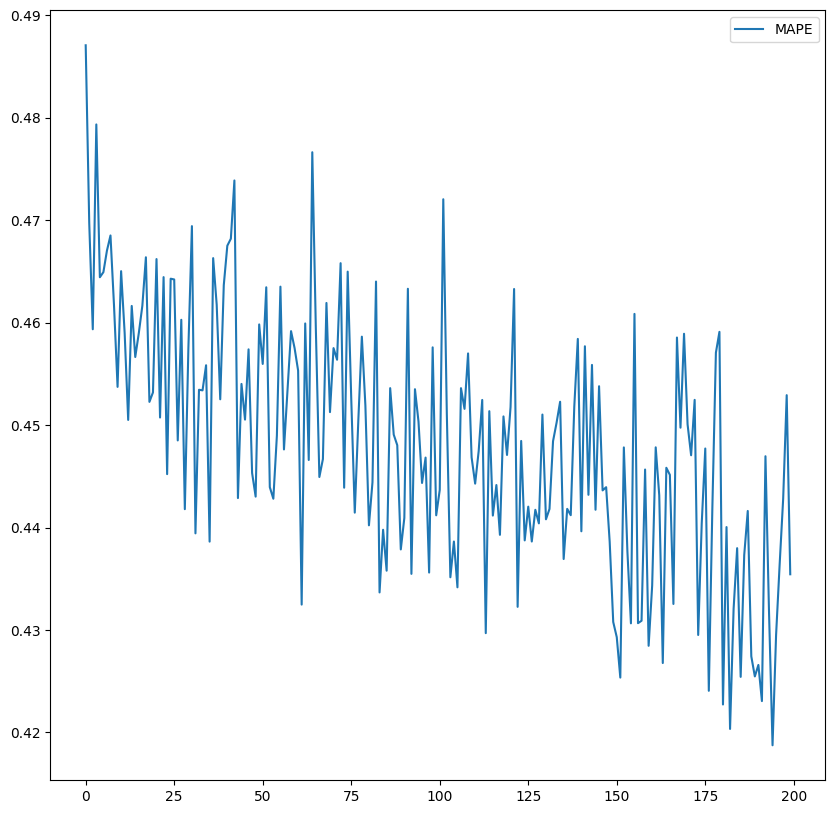

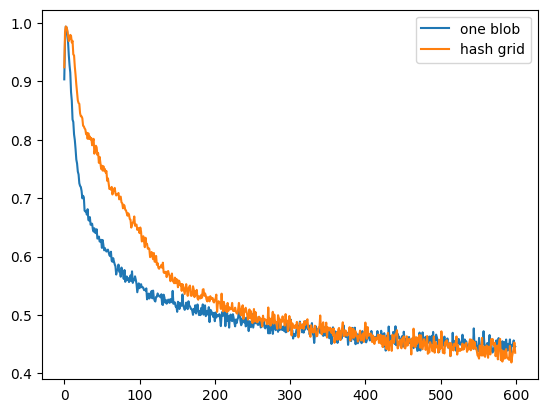

In [ ]:
### One blob vs Hash Grid experiment - Old

scene = scenes.cbox()

context = Context(bounces=4, spp=1, bsdf_sampling=True, emitter_sampling=True, mis_beta=2.0),

# model_one_blob, renderer = create_model(
#     coordinate_system=CoordinateSystem.Spherical, 
#     # prior_str='uniform',
#     prior_str='cosine',
#     scene = scene,
#     context = context,
#     do_normal_encoding = True, 
#     do_in_dir_encoding = True, 
#     do_pos_encoding    = True, 
#     num_flows = 4, 
#     num_bins  = 16, 
#     hidden_units = 64, 
#     hidden_layers = 4, 
#     pos_is_hash_grid=False,
#     encode_pos_each_flow = True, 
#     latent_to_hash_enc = False,
#     scaling_grid_sizes = False
# )

# model_hash_grid, renderer = create_model(
#     coordinate_system=CoordinateSystem.Spherical, 
#     # prior_str='uniform',
#     prior_str='cosine',
#     scene = scene,
#     context = context,
#     do_normal_encoding = True, 
#     do_in_dir_encoding = True, 
#     do_pos_encoding    = True, 
#     num_flows = 4, 
#     num_bins  = 16, 
#     hidden_units = 64, 
#     hidden_layers = 4, 
#     pos_is_hash_grid=True,
#     encode_pos_each_flow = False, 
#     latent_to_hash_enc = False,
#     scaling_grid_sizes = False
# )

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(bounces=6, 
                                  spp=1, 
                                  num_samples = num_samples,
                                  width = width,
                                  height = height,
                                  include_brdf = model_one_blob.has_incoming_encoding,
                                  sample_generation_strategy = "light_tracing",
                                  sample_model = True
                                  )

renderer = rr.Renderer(scene, training_context, model_one_blob.coordinate_system)

_, errors_one_blob_2 = train(model_one_blob,
                        renderer, 
                        iterations=5000,
                        train_context=training_context,
                        track_error_metric=True,
                        track_error_every=25,
                        test_spp=4,
                        clamp = True,
                        num_plots=0,
                        lr = 3e-4)

_, errors_hash_grid_2 = train(model_hash_grid,
                        renderer, 
                        iterations=5000,
                        train_context=training_context,
                        track_error_metric=True,
                        track_error_every=25,
                        test_spp=4,
                        clamp = True,
                        num_plots=0,
                        lr = 3e-4)

errors_one_blob_comb = np.append(errors_one_blob, errors_one_blob_2)
errors_hash_grid_comb = np.append(errors_hash_grid, errors_hash_grid_2)

plt.plot(errors_one_blob_comb, label="one blob")
plt.plot(errors_hash_grid_comb, label="hash grid")
plt.legend()
plt.show()

using device: cuda


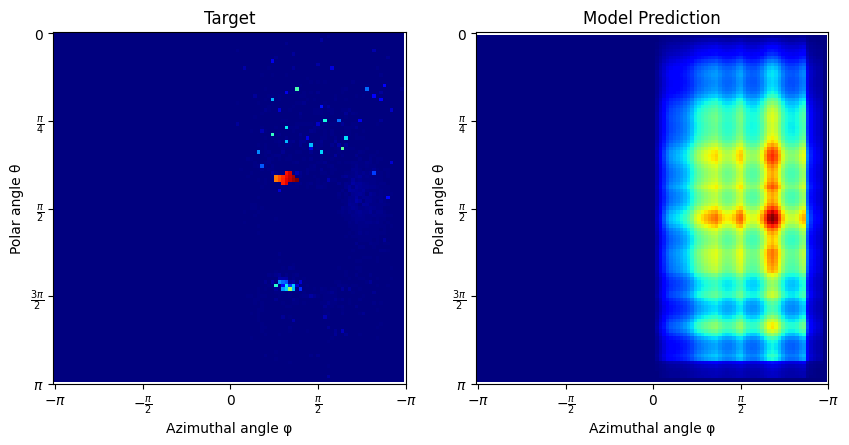

100%|██████████| 10000/10000 [24:31<00:00,  6.80it/s]


average generate_samples_time time 0.10239519441127777
average compute_gradient_time time 0.034953405594825744
average nan_check_clip_time time 0.0005587493658065796
average optimizer_time time 4.458427429199219e-08


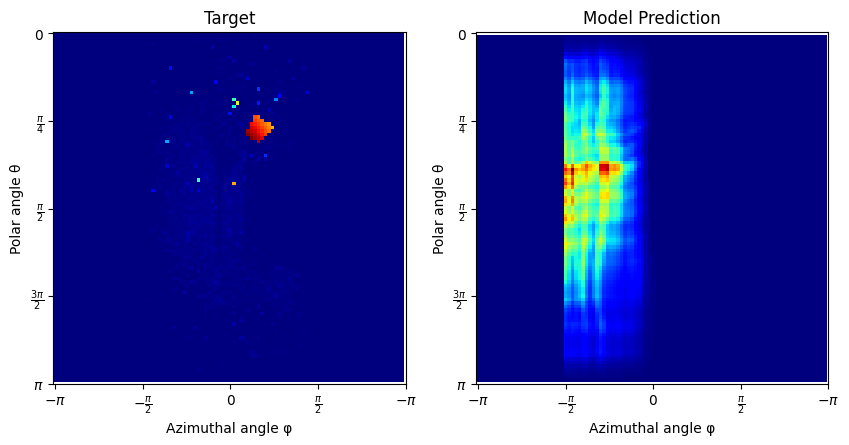

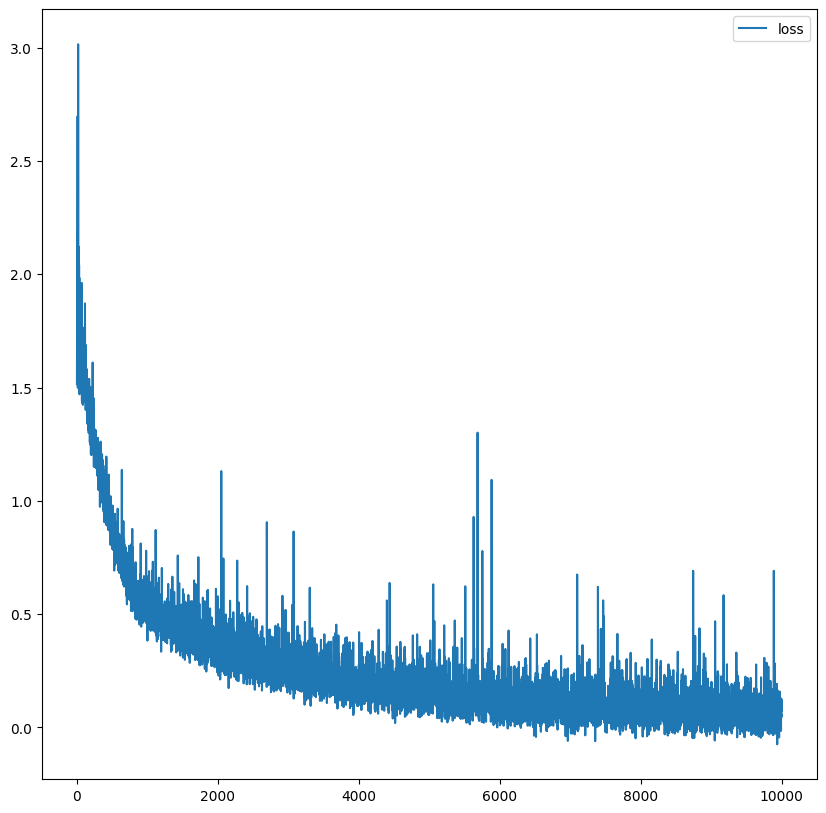

In [ ]:
### Glossy CBox Experiment -> Old

scene = scenes.glossy_cbox()

context = Context(bounces=4, spp=1, bsdf_sampling=True, emitter_sampling=True, mis_beta=2.0),

model_no_in_dir, renderer = create_model(
    coordinate_system=CoordinateSystem.Spherical, 
    # prior_str='uniform',
    prior_str='cosine',
    scene = scene,
    context = context,
    do_normal_encoding = True, 
    do_in_dir_encoding = False, 
    do_pos_encoding    = True, 
    num_flows = 4, 
    num_bins  = 16, 
    hidden_units = 64, 
    hidden_layers = 4, 
    encode_pos_each_flow = True, 
    latent_to_hash_enc = True,
    scaling_grid_sizes = True
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(bounces=6, 
                                  spp=1, 
                                  num_samples = num_samples,
                                  width = width,
                                  height = height,
                                  include_brdf = model_no_in_dir.has_incoming_encoding,
                                  # sample_generation_strategy = "light_tracing",
                                  sample_generation_strategy = "sensor_sampling",
                                  sample_model = True
                                  )

renderer = rr.Renderer(scene, training_context, model_no_in_dir.coordinate_system)

train(model_no_in_dir,
      renderer, 
      iterations=10000,
      train_context=training_context,
      num_plots=1,
      lr = 1e-4)

context = Context(bounces=4, spp=1, bsdf_sampling=True, emitter_sampling=True, mis_beta=2.0),

model_full_integrand, renderer = create_model(
    coordinate_system=CoordinateSystem.Spherical, 
    # prior_str='uniform',
    prior_str='cosine',
    scene = scene,
    context = context,
    do_normal_encoding = True, 
    do_in_dir_encoding = True, 
    do_pos_encoding    = True, 
    num_flows = 4, 
    num_bins  = 16, 
    hidden_units = 64, 
    hidden_layers = 4, 
    encode_pos_each_flow = True, 
    latent_to_hash_enc = True,
    scaling_grid_sizes = True
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(bounces=6, 
                                  spp=1, 
                                  num_samples = num_samples,
                                  width = width,
                                  height = height,
                                  include_brdf = model_full_integrand.has_incoming_encoding,
                                  # sample_generation_strategy = "light_tracing",
                                  sample_generation_strategy = "sensor_sampling",
                                  sample_model = True
                                  )

renderer = rr.Renderer(scene, training_context, model_full_integrand.coordinate_system)

train(model_full_integrand,
      renderer, 
      iterations=10000,
      train_context=training_context,
      num_plots=1,
      lr = 1e-4)

using device: cuda


p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
d:\Studium\Masters\Masters\scripts\..\src\normalizing_flows.py:85: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  idx = torch.searchsorted(vertices_y, y) - 1


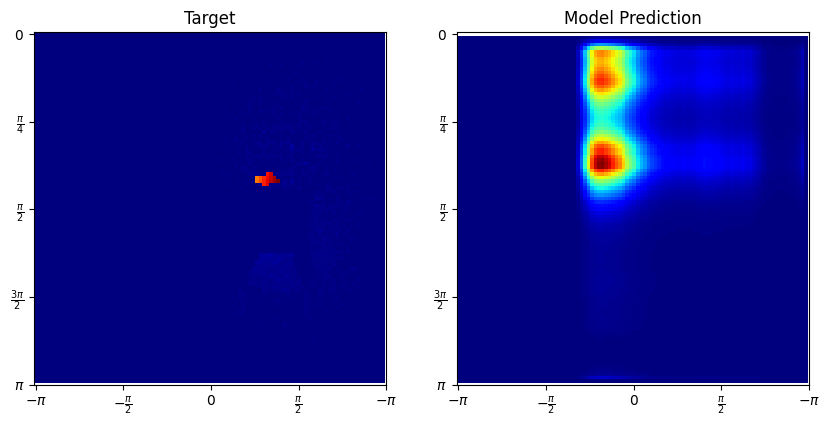

100%|██████████| 50000/50000 [2:36:42<00:00,  5.32it/s]  


average generate_samples_time time 0.0359447029542923
average compute_gradient_time time 0.13000311951160431
average nan_check_clip_time time 0.0010420526885986329
average optimizer_time time 1.7709732055664062e-08


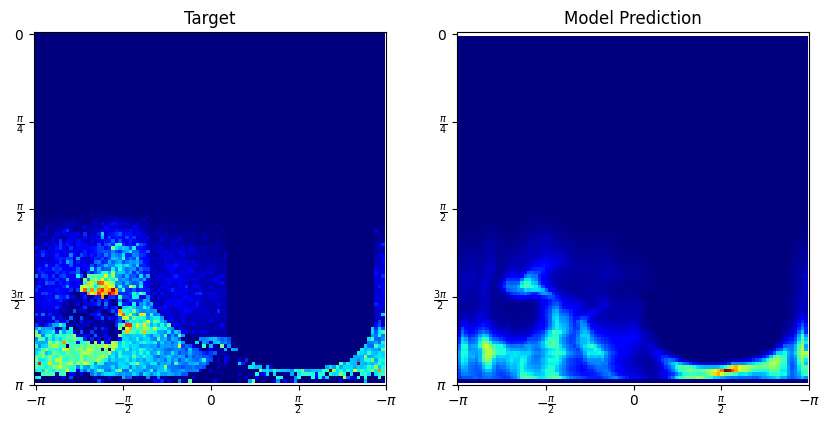

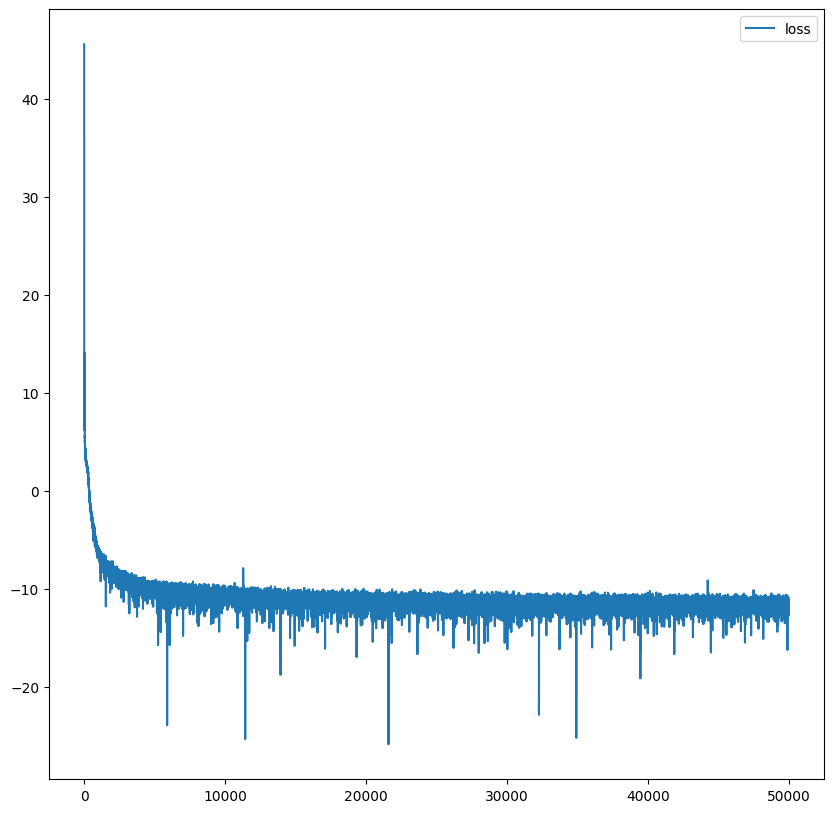

RMSE: 0.09678437560796738


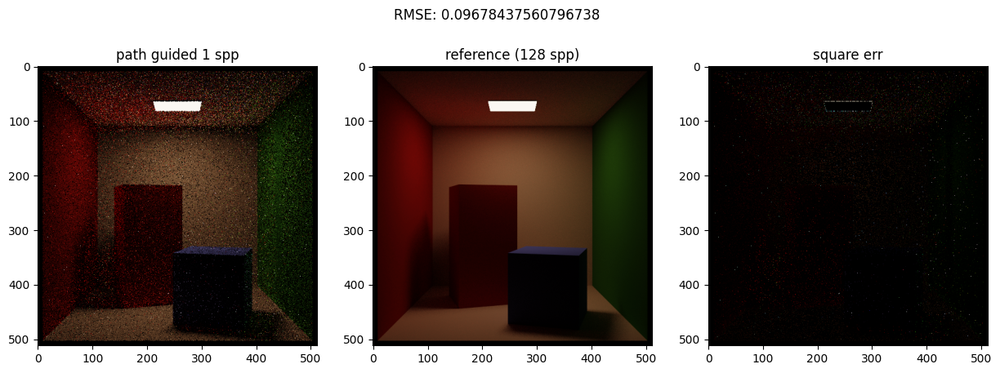

using device: cuda


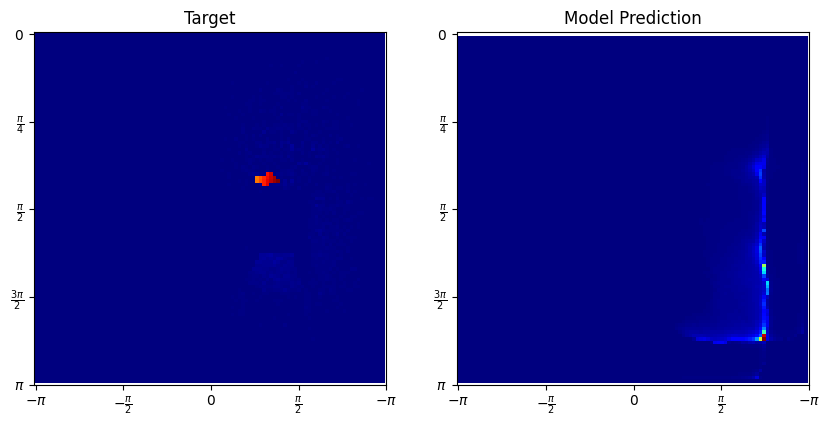

100%|██████████| 50000/50000 [2:10:50<00:00,  6.37it/s]  


average generate_samples_time time 0.029083802075386047
average compute_gradient_time time 0.11713626498222351
average nan_check_clip_time time 0.0010416424226760864
average optimizer_time time 1.7385482788085937e-08


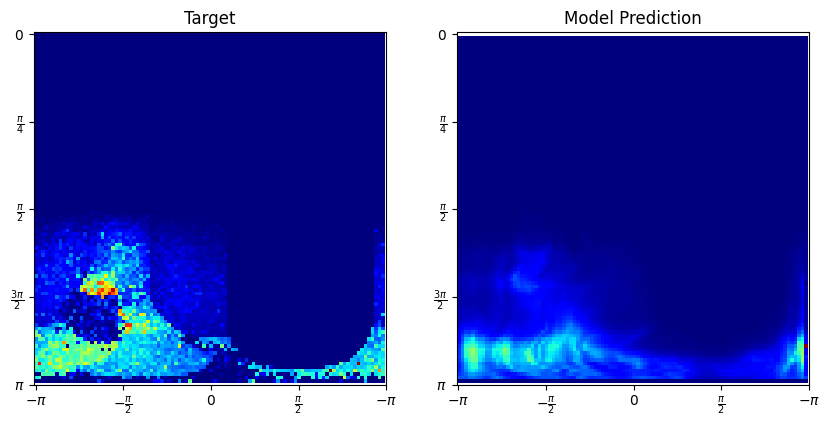

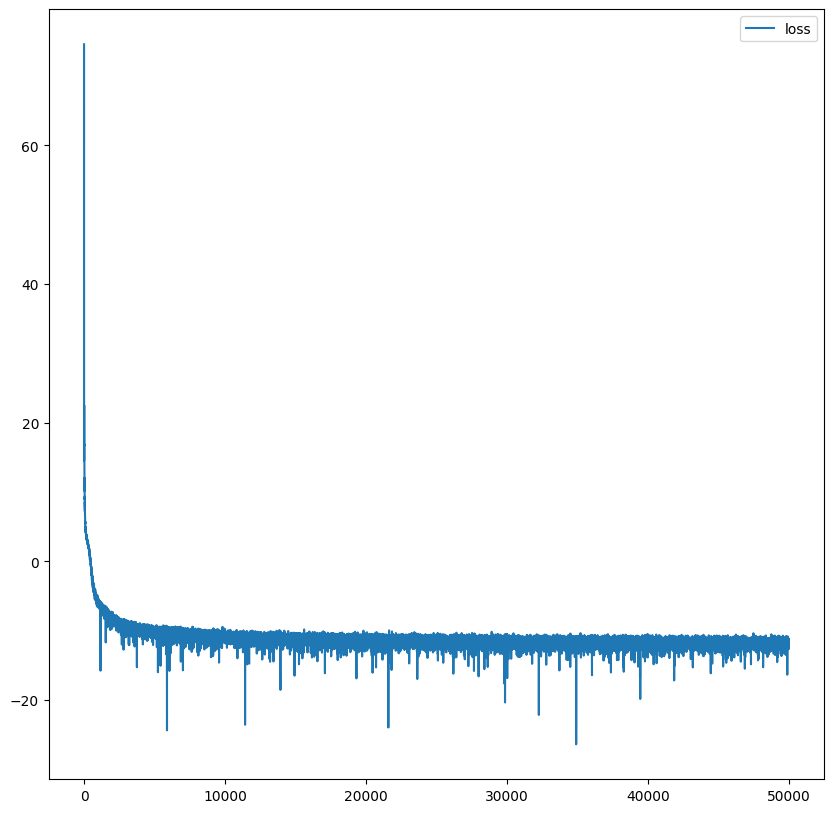

RMSE: 0.09612864255905151


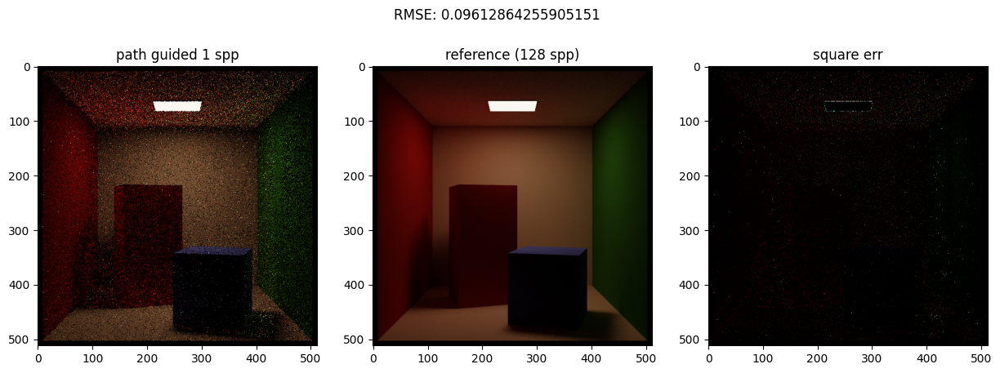

using device: cuda


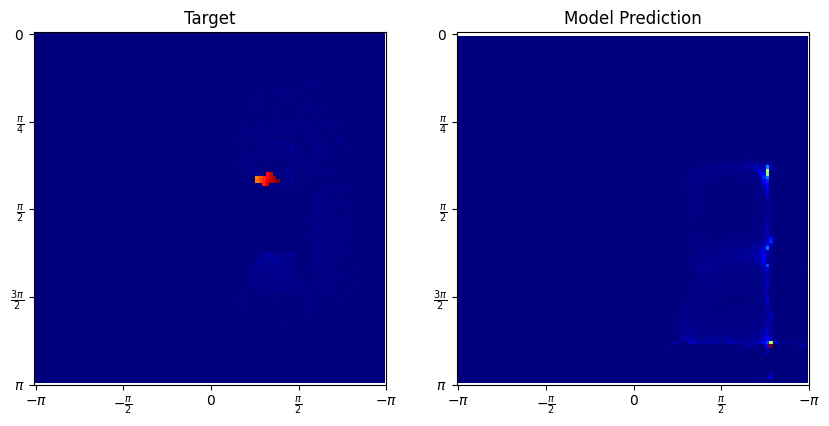

100%|██████████| 50000/50000 [1:51:28<00:00,  7.48it/s]


average generate_samples_time time 0.0069568596458435055
average compute_gradient_time time 0.1228493419933319
average nan_check_clip_time time 0.0010489462184906006
average optimizer_time time 2.940654754638672e-08


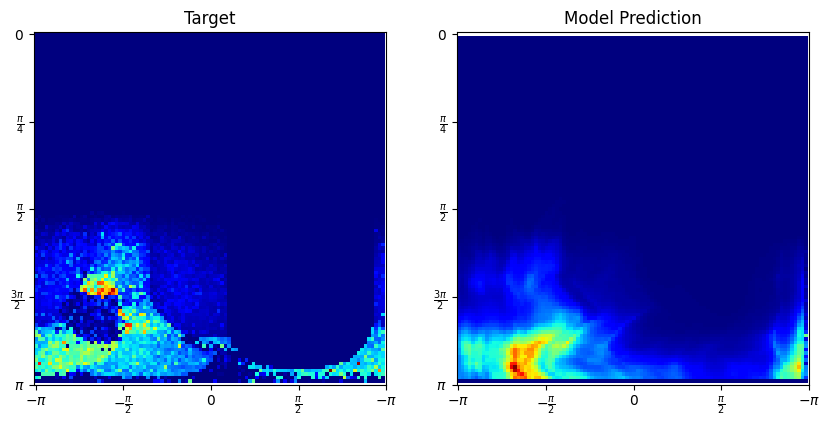

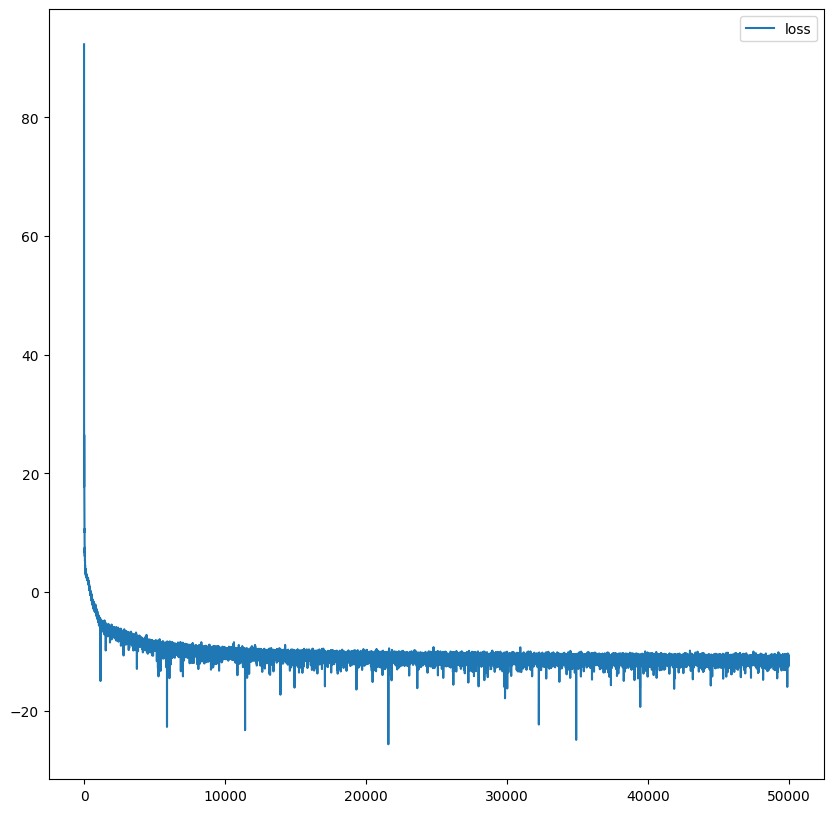

RMSE: 0.1012590155005455


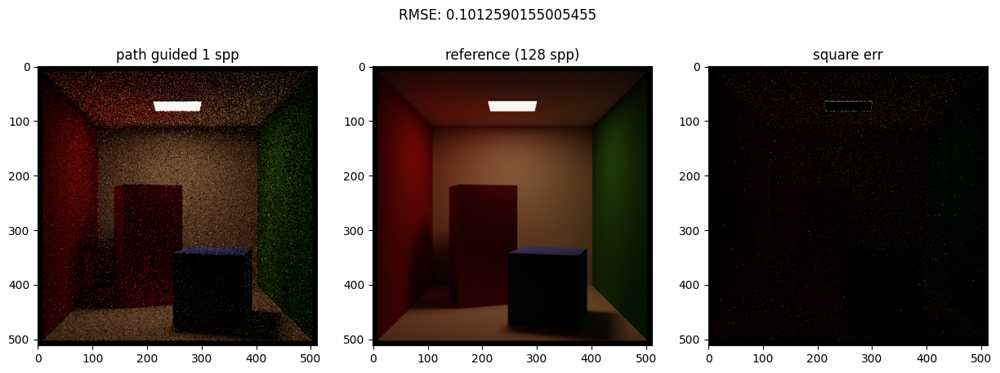

In [ ]:
# Triple model 50k - Old

scene = scenes.cbox()

iterations = 50000

context = Context(bounces=4, spp=1, bsdf_sampling=True, emitter_sampling=True, mis_beta=2.0),

model, renderer = create_model(
    coordinate_system=CoordinateSystem.Spherical, 
    prior_str='cosine',
    scene = scene,
    context = context,
    do_normal_encoding = True, 
    do_in_dir_encoding = True, 
    do_pos_encoding    = True, 
    num_flows = 16, 
    num_bins  = 8, 
    hidden_units = 64, 
    hidden_layers = 4, 
    encode_pos_each_flow = True, 
    latent_to_hash_enc = True
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(bounces=4, 
                                  spp=1, 
                                  num_samples = num_samples,
                                  width = width,
                                  height = height,
                                  include_brdf = model.has_incoming_encoding,
                                  sample_generation_strategy = SampleGenStrategy.LightTracing,
                                  # sample_model = True
                                  )

renderer = rr.Renderer(scene, context, model.coordinate_system)

train(model,
      renderer, 
      iterations=iterations,
      train_context=training_context,
      num_plots=1,
      lr = 1e-4)

computeRMSE(renderer, model, 512, 512)

save_model(model, "../assets/models/16_8_64_4__50k_4d_grid_each")
del_model(model)

model, renderer = create_model(
    coordinate_system=CoordinateSystem.Spherical, 
    prior_str='cosine',
    scene = scene,
    context = context,
    do_normal_encoding = True, 
    do_in_dir_encoding = True, 
    do_pos_encoding    = True, 
    num_flows = 16, 
    num_bins  = 8, 
    hidden_units = 64, 
    hidden_layers = 4, 
    encode_pos_each_flow = True, 
    latent_to_hash_enc = False
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(bounces=4, 
                                  spp=1, 
                                  num_samples = num_samples,
                                  width = width,
                                  height = height,
                                  include_brdf = model.has_incoming_encoding,
                                  sample_generation_strategy = SampleGenStrategy.LightTracing,
                                  # sample_model = True
                                  )

renderer = rr.Renderer(scene, context, model.coordinate_system)

train(model,
      renderer, 
      iterations=iterations,
      train_context=training_context,
      num_plots=1,
      lr = 1e-4)

computeRMSE(renderer, model, 512, 512)

save_model(model, "../assets/models/16_8_64_4__50k_3d_grid_each")
del_model(model)

model, renderer = create_model(
    coordinate_system=CoordinateSystem.Spherical, 
    prior_str='cosine',
    scene = scene,
    context = context,
    do_normal_encoding = True, 
    do_in_dir_encoding = True, 
    do_pos_encoding    = True, 
    num_flows = 16, 
    num_bins  = 8, 
    hidden_units = 64, 
    hidden_layers = 4, 
    encode_pos_each_flow = False, 
    latent_to_hash_enc = False
)

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(bounces=4, 
                                  spp=1, 
                                  num_samples = num_samples,
                                  width = width,
                                  height = height,
                                  include_brdf = model.has_incoming_encoding,
                                  sample_generation_strategy = SampleGenStrategy.LightTracing,
                                  # sample_model = True
                                  )

renderer = rr.Renderer(scene, context, model.coordinate_system)

train(model,
      renderer, 
      iterations=iterations,
      train_context=training_context,
      num_plots=1,
      lr = 1e-4)

computeRMSE(renderer, model, 512, 512)

save_model(model, "../assets/models/16_8_64_4__50k_3d_grid_once")
del_model(model)

# Other Visualisations and Debug Tools

In [ ]:
### Bsdf prior debug help
exp = load_Experiment("inv_cbox_10k_bsdf_hash_grid.pkl")

print(exp.mape_list)

In [14]:
### Old model creation

# scene = scenes.env_scene_sphere()
# scene = scenes.env_scene_sphere_metallic()
# scene = scenes.env_scene_sphere_dielectric()
# scene = scenes.env_scene_empty()
scene = scenes.cbox()
# scene = scenes.glossy_cbox()
# scene = scenes.spaceship()
# scene = scenes.env_scene_sphere_rough_dielectric()
# scene = scenes.kitchen()
# scene = scenes.living_room_2()
# scene = scenes.veach_mis_scene()

context = Context(bounces=4, spp=1, bsdf_sampling=True, emitter_sampling=True, mis_beta=2.0),

model = create_model(
    coordinate_system=CoordinateSystem.Spherical, 
    # prior_str='uniform',
    prior_str='cosine',
    scene = scene,
    do_normal_encoding = True, 
    do_in_dir_encoding = True, 
    do_pos_encoding    = True, 
    num_flows = 4, 
    num_bins  = 16, 
    hidden_units = 64, 
    hidden_layers = 4, 
    pos_is_hash_grid=False,
    encode_pos_each_flow = True, 
    latent_to_hash_enc = False,
    scaling_grid_sizes = False
)

using device: cuda


In [ ]:
### Old training loop

num_samples = 2 ** 14
width = 128
height = 128

training_context = Context(bounces=6, 
                                  spp=1, 
                                  num_samples = num_samples,
                                  width = width,
                                  height = height,
                                  include_brdf = model.has_incoming_encoding,
                                  sample_generation_strategy = "light_tracing",
                                  # sample_generation_strategy = "sensor_sampling",
                                  sample_model = True
                                  )

renderer = rr.Renderer(scene, training_context, model.coordinate_system)

losses, errors = train(model,
                        renderer, 
                        iterations=1000,
                        train_context=training_context,
                        track_error_metric=True,
                        track_error_every=500,
                        test_spp=4,
                        clamp = False,
                        num_plots=1,
                        lr = 3e-4)

In [15]:
### Model sampling distribution vis
num_samples = 100000
bins = 100
domain_area = (domain[:, 1] - domain[:, 0]).prod()


active = dr.full(dr.auto.ad.Bool, True, num_samples)
bsdf_ctx: mi.BSDFContext = mi.BSDFContext(mode = mi.TransportMode.Radiance)
rng = dr.rng(0)

p = mi.Point3f([0, 0, -1])
p = dr.repeat(p, num_samples)
look_at = mi.Point3f(0, 0, 0)
look_at = dr.repeat(look_at, num_samples)

dir = dr.normalize(look_at - p)

ray = mi.Ray3f(p, dir)

si: mi.SurfaceInteraction3f = scene.ray_intersect(ray)

bsdf: mi.BSDFPtr = si.bsdf()
active &= bsdf is not None

model_samples, model_sample_pdf = kernels.sample_from_model(model, active, si.n, si.to_world(si.wi), si.p)

bsdf_sample, _ = kernels.sample_new_dir_bsdf(si, rng, bsdf, bsdf_ctx, num_samples, active)

out_dir = si.to_world(bsdf_sample.wo)

angles = mi.Point2f(kernels.directions_to_angles(out_dir)).torch().transpose(0, 1)

normal = si.n.torch().transpose(0, 1)
in_dir = si.to_world(si.wi).torch().transpose(0, 1)
pos    = si.p.torch().transpose(0, 1)

ray = si.spawn_ray(out_dir)
si: mi.SurfaceInteraction3f = scene.ray_intersect(ray)

direct = kernels.direct_light(si, scene, active)
direct = dr.mean(direct, axis=0)

probs = model.log_prob(angles, normal, in_dir, pos).exp()

direct_samples = direct.torch().detach().cpu()

angles = angles.detach().cpu()
probs = probs.detach().cpu()

model_angles = model_samples.torch().transpose(0, 1).detach().cpu()
model_samples_probs = model_sample_pdf.torch().detach().cpu()

domainc = domain.cpu()

model_sample_grid, _, _ = np.histogram2d(
    model_angles[:, 0], model_angles[:, 1],
    bins=bins,
    range=domainc
)



model_samples_pdf_grid, _, _ = np.histogram2d(
    model_angles[:, 0], model_angles[:, 1],
    bins=bins,
    range=domainc,
    weights=model_samples_probs
)



# average, safely handling empty bins
model_samples_pdf_grid = np.divide(model_samples_pdf_grid, model_sample_grid)
model_samples_pdf_grid[(np.isnan(model_samples_pdf_grid)) | (np.isinf(model_samples_pdf_grid))] = 0

pdf_sum_unnorm = model_samples_pdf_grid.sum()
pdf_sum_norm = pdf_sum_unnorm / (bins * bins) * domain_area
print(pdf_sum_norm)

sample_grid, _, _ = np.histogram2d(
    angles[:, 0], angles[:, 1],
    bins=bins,
    range=domainc
)


env_grid, _, _ = np.histogram2d(
    angles[:, 0], angles[:, 1],
    bins=bins,
    range=domainc,
    weights=direct_samples
)

# average, safely handling empty bins
env_grid = np.divide(env_grid, sample_grid)
env_grid[(np.isnan(env_grid)) | (np.isinf(env_grid))] = 0


model_probs_grid, _, _ = np.histogram2d(
    angles[:, 0], angles[:, 1],
    bins=bins,
    range=domainc,
    weights=probs
)

# average, safely handling empty bins
model_probs_grid = np.divide(model_probs_grid, sample_grid)
model_probs_grid[(np.isnan(model_probs_grid)) | (np.isinf(model_probs_grid))] = 0

xx, yy = torch.meshgrid(
    torch.linspace(domain[0][0], domain[0][1], bins), 
    torch.linspace(domain[1][0], domain[1][1], bins)
)

zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)
zz = zz.to('cuda')

render_target = targets.RendererTarget(renderer, coordinate_system)

normal = normal[0]
target_probs = render_target.log_prob(zz, normal).exp().view(*xx.shape).detach().cpu()

target_probs_sum_unnorm = target_probs.sum()
target_probs_sum_norm = target_probs_sum_unnorm / (bins * bins) * domain_area

print(target_probs_sum_norm)

fig, axs = plt.subplots(2, 3, figsize=(15, 10))

axs[0, 0].pcolormesh(xx, yy, target_probs)
axs[0, 0].set_title("target distribution")

axs[0, 1].pcolormesh(sample_grid.T)
axs[0, 1].set_title("hemisphere sampling")

axs[0, 2].pcolormesh(env_grid.T)
axs[0, 2].set_title("sampled env values (no lambert cos)")

axs[1, 0].pcolormesh(model_probs_grid.T)
axs[1, 0].set_title("model eval on hemisphere")

axs[1, 1].pcolormesh(model_sample_grid.T)
axs[1, 1].set_title("model out direction samples")

axs[1, 2].pcolormesh(model_samples_pdf_grid.T)
axs[1, 2].set_title("model out direction pdf")

plt.show()


NameError: name 'domain' is not defined

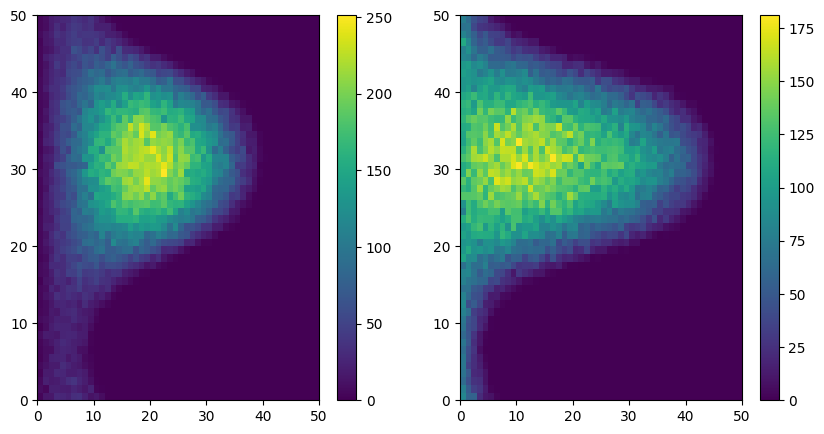

In [ ]:
domain_sph = utils.get_domain_from_coords(CoordinateSystem.Spherical, device='cpu')
domain_cyl = utils.get_domain_from_coords(CoordinateSystem.Cylindrical, device='cpu')

resolution = [500, 500]

xx_sph, yy_sph = torch.meshgrid(
    torch.linspace(domain_sph[0][0], domain_sph[0][1], resolution[0]), 
    torch.linspace(domain_sph[1][0], domain_sph[1][1], resolution[1])
)

zz_sph = torch.cat([xx_sph.unsqueeze(2), yy_sph.unsqueeze(2)], 2).view(-1, 2)


xx_cyl, yy_cyl = torch.meshgrid(
    torch.linspace(domain_cyl[0][0], domain_cyl[0][1], resolution[0]), 
    torch.linspace(domain_cyl[1][0], domain_cyl[1][1], resolution[1])
)

zz_cyl = torch.cat([xx_cyl.unsqueeze(2), yy_cyl.unsqueeze(2)], 2).view(-1, 2)

prior_sph = priors.CosineWeighted(CoordinateSystem.Spherical)
prior_cyl = priors.CosineWeighted(CoordinateSystem.Cylindrical)

zz_cyl = utils.cartesian_to_cylindrical(utils.cylindrical_to_cartesian(zz_cyl))

dirs_sph = utils.spherical_to_cartesian(zz_sph).view((*xx_sph.shape, 3)).transpose(1, 0)
dirs_cyl = utils.cylindrical_to_cartesian(zz_cyl).view((*xx_cyl.shape, 3)).transpose(1, 0)

N = torch.tensor([[1, 1, 1]], dtype=torch.float32, device='cpu')
N = N / torch.norm(N)
sph_probs = prior_sph.prob(zz_sph, N).view(*xx_sph.shape)
cyl_probs = prior_cyl.prob(zz_cyl, N).view(*xx_cyl.shape)

num_samples = 100000
bins = 50

samples_sph = prior_sph.sample(num_samples, N).detach().numpy()
samples_cyl = prior_cyl.sample(num_samples, N).detach().numpy()


sample_grid_sph, _, _ = np.histogram2d(
    samples_sph[:, 0], samples_sph[:, 1],
    bins=bins,
    range=domain_sph
)


sample_grid_cyl, _, _ = np.histogram2d(
    samples_cyl[:, 0], samples_cyl[:, 1],
    bins=bins,
    range=domain_cyl
)



fig, axs = plt.subplots(1, 2, figsize = (10, 5))

dim = 1

# map0 = axs[0].pcolormesh(dirs_sph[..., dim])
map0 = axs[0].pcolormesh(sample_grid_sph)
fig.colorbar(map0, ax = axs[0])

# map1 = axs[1].pcolormesh(dirs_cyl[..., dim])
map1 = axs[1].pcolormesh(sample_grid_cyl)
fig.colorbar(map1, ax = axs[1])

C:\Users\janlu\AppData\Local\Temp\ipykernel_3944\4256003646.py:71: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


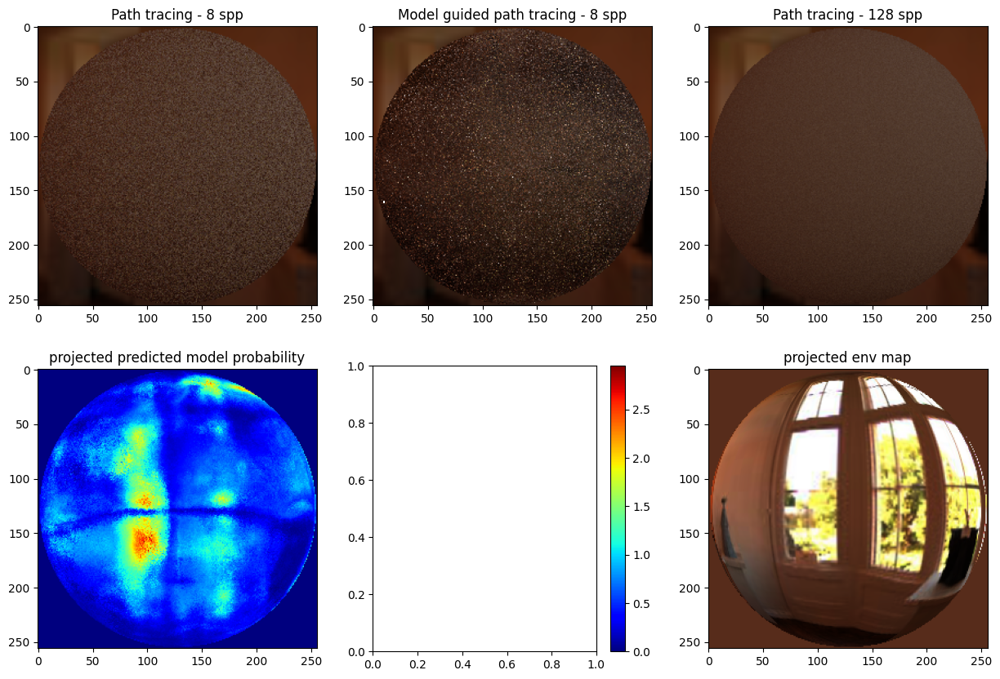

In [ ]:
import scenes
importlib.reload(scenes)
import scenes

import kernels
importlib.reload(kernels)
import kernels


context: rr.RenderContext = rr.RenderContext(bounces=2, spp=1, bsdf_sampling=True, emitter_sampling=False, mis_beta=4.0)

scene = scenes.env_scene_sphere()

renderer = rr.Renderer(scene, context, coordinate_system)

compare_width = 256
compare_height = 256

test_spp = 8
ref_spp = 128

context: rr.RenderContext = rr.RenderContext(bounces=2, spp=test_spp, bsdf_sampling=True, emitter_sampling=False, mis_beta=4.0)
ref_context: rr.RenderContext = rr.RenderContext(bounces=2, spp=ref_spp, bsdf_sampling=True, emitter_sampling=False, mis_beta=4.0)


out_pt = renderer.render(compare_width, compare_height, context)
out_ref = renderer.render(compare_width, compare_height, ref_context)
# out_npg = renderer.render_with_model(compare_width, compare_height, model, context)
out_npg = renderer.compute_path_model_single_bounce(compare_width, compare_height, model, context)


rays = renderer.sample_sensor(compare_width, compare_height)

out_model_proj = kernels.project_model_prediction(rays, renderer.scene, model)
out_env_proj = kernels.project_env(rays, renderer.scene)

out_pt_np =  utils.tonemap(utils.res_to_numpy_3(out_pt, compare_width, compare_height))
out_npg_np = utils.tonemap(utils.res_to_numpy_3(out_npg, compare_width, compare_height))
out_ref_np = utils.tonemap(utils.res_to_numpy_3(out_ref, compare_width, compare_height))

# out_pt_np =  utils.res_to_numpy_3(out_pt, compare_width, compare_height)
# out_npg_np = utils.res_to_numpy_3(out_npg, compare_width, compare_height)
# out_ref_np = utils.res_to_numpy_3(out_ref, compare_width, compare_height)


out_env_m_np = utils.res_to_numpy_1(out_model_proj, compare_width, compare_height)
out_env_np = utils.res_to_numpy_3(out_env_proj, compare_width, compare_height)

fig, axs = plt.subplots(2, 3, figsize=(15, 10))

vmin = 0.0
vmax = 1.0

axs[0, 0].imshow(out_pt_np, vmin=vmin, vmax=vmax)
axs[0, 0].set_title(f"Path tracing - {test_spp} spp")

axs[0, 1].imshow(out_npg_np, vmin=vmin, vmax=vmax)
axs[0, 1].set_title(f"Model guided path tracing - {test_spp} spp")


axs[0, 2].imshow(out_ref_np, vmin=vmin, vmax=vmax)
axs[0, 2].set_title(f"Path tracing - {ref_spp} spp")

sm = axs[1, 0].imshow(out_env_m_np, cmap='jet')
fig.colorbar(sm, ax=axs[1, 1])
axs[1, 0].set_title("projected predicted model probability")

axs[1, 2].imshow(out_env_np)
axs[1, 2].set_title("projected env map")

fig.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..2.908142].
C:\Users\janlu\AppData\Local\Temp\ipykernel_9716\532381518.py:82: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


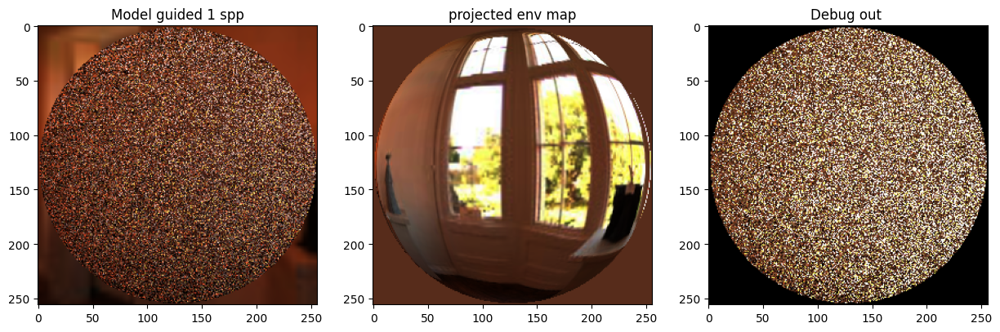

In [ ]:
import scenes
importlib.reload(scenes)
import scenes

import kernels
importlib.reload(kernels)
import kernels

import renderers
importlib.reload(renderers)
import renderers



context: rr.RenderContext = rr.RenderContext(bounces=2, spp=1, bsdf_sampling=True, emitter_sampling=False, mis_beta=4.0)

scene = scenes.env_scene_sphere()

renderer = rr.Renderer(scene, context, coordinate_system)

compare_width = 256
compare_height = 256

test_spp = 1
ref_spp = 128

context: rr.RenderContext = rr.RenderContext(bounces=2, spp=test_spp, bsdf_sampling=True, emitter_sampling=False, mis_beta=4.0)
ref_context: rr.RenderContext = rr.RenderContext(bounces=2, spp=ref_spp, bsdf_sampling=True, emitter_sampling=False, mis_beta=4.0)
rng = dr.rng(0)

rays = renderer.sample_sensor(compare_width, compare_height)

# out_npg = renderer.render_with_model(compare_width, compare_height, model, context)
out_npg = renderer.compute_path_model_single_bounce(compare_width, compare_height, model, context)

# out_model_proj = kernels.project_model_prediction(rays, renderer.scene, model)
out_model_proj = kernels.project_model_prediction(rays, renderer.scene, model)


out_env_proj = kernels.project_env(rays, renderer.scene)

its = 1

out_debug = kernels.compute_model_debug(rays, renderer.scene, model, context, rng)
for _ in range(its - 1):
    out_debug += kernels.compute_model_debug(rays, renderer.scene, model, context, rng)

out_debug /= its


out_npg_np = utils.res_to_numpy_3(out_npg, compare_width, compare_height)

out_env_m_np = utils.res_to_numpy_1(out_model_proj, compare_width, compare_height)
out_env_np = utils.res_to_numpy_3(out_env_proj, compare_width, compare_height)

debug_3_channel = out_debug.shape[0] == 3
if debug_3_channel:
    out_debug_np = utils.res_to_numpy_3(out_debug, compare_width, compare_height).reshape(compare_width, compare_height, 3)
else:
    out_debug_np = utils.res_to_numpy_1(out_debug, compare_width, compare_height).reshape(compare_width, compare_height)


fig, axs = plt.subplots(1, 3, figsize=(15, 5))

vmin = 0.0
vmax = 1.0

# cb0 = axs[0].imshow(out_env_m_np, cmap='jet')
# fig.colorbar(cb0, ax=axs[0])
# axs[0].set_title(f"Model projected")

axs[0].imshow(out_npg_np)
axs[0].set_title(f"Model guided {test_spp} spp")

axs[1].imshow(out_env_np, vmin=vmin, vmax=vmax)
axs[1].set_title(f"projected env map")

cb2 = axs[2].imshow(out_debug_np, cmap='jet')
# fig.colorbar(cb2, ax=axs[2])
axs[2].set_title(f"Debug out ")

fig.show()

C:\Users\janlu\AppData\Local\Temp\ipykernel_16576\3688031454.py:190: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


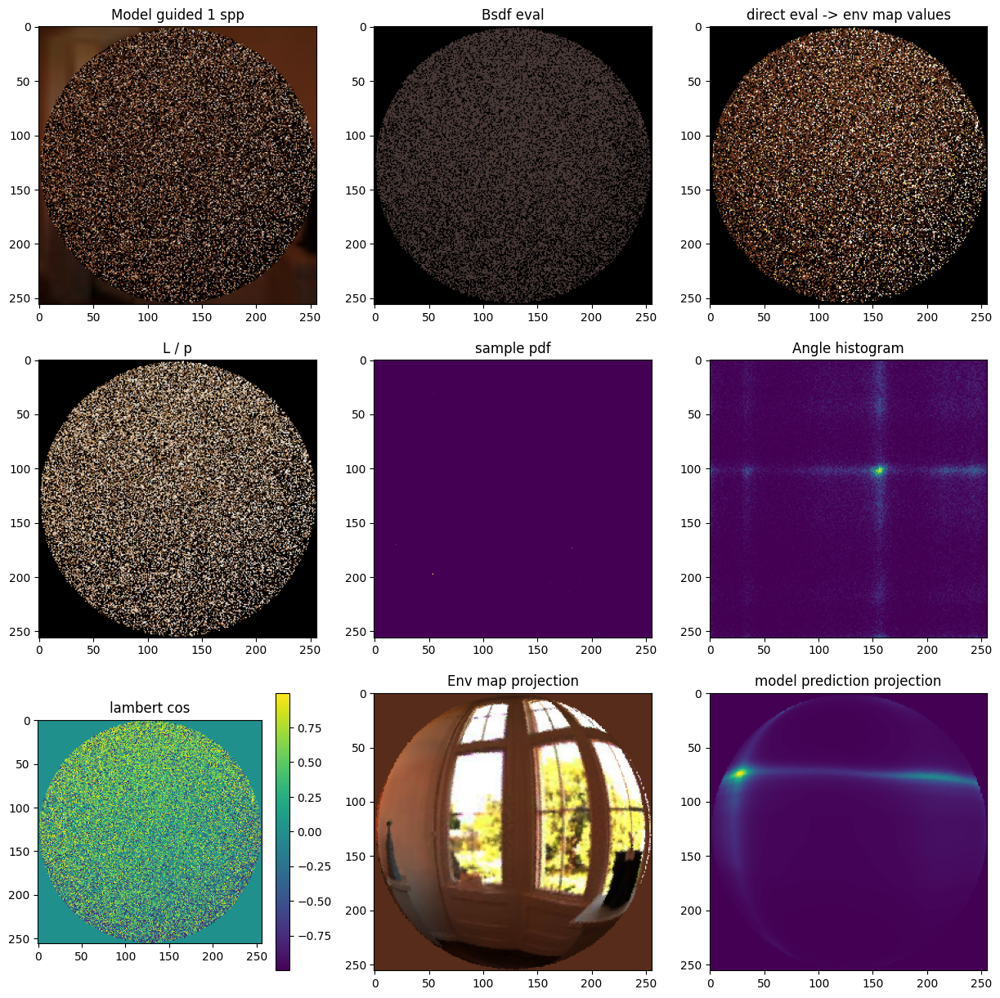

In [17]:
import scenes
importlib.reload(scenes)
import scenes

import kernels
importlib.reload(kernels)
import kernels

import renderers
importlib.reload(renderers)
import renderers

coordinate_system = CoordinateSystem.Spherical

context: Context = Context(bounces=2, spp=1, bsdf_sampling=True, emitter_sampling=False, mis_beta=4.0)

scene = scenes.env_scene_sphere()

renderer = rr.Renderer(scene, context, coordinate_system)

compare_width = 256
compare_height = 256
bins = compare_width

test_spp = 1

context: Context = Context(bounces=2, spp=test_spp, bsdf_sampling=True, emitter_sampling=False, mis_beta=4.0)
rng = dr.rng(0)

spp = 1


rays = renderer.sample_sensor(compare_width, compare_height)

# out_npg = renderer.render_with_model(compare_width, compare_height, model, context)
out, bsdf_eval, direct, pdf, new_dir, samples, lambert_cos, mask = kernels.compute_path_model_single_bounce_debug(rays, 
                                                                                                renderer.scene, 
                                                                                                model, 
                                                                                                context, 
                                                                                                rng=rng)

    # out_model_proj = kernels.project_model_prediction(rays, renderer.scene, model)

domainc = utils.get_domain_from_coords(coordinate_system, device = 'cpu')

out_np = utils.tonemap(utils.res_to_numpy_3(out, compare_width, compare_height))
bsdf_np = utils.res_to_numpy_3(bsdf_eval, compare_width, compare_height)
direct_np = utils.res_to_numpy_3(direct, compare_width, compare_height)
pdf_np = utils.res_to_numpy_1(pdf, compare_width, compare_height)
new_dir_np = utils.res_to_numpy_3(new_dir, compare_width, compare_height)
lambert_np = utils.res_to_numpy_1(lambert_cos, compare_width, compare_height)

samples_np = mi.TensorXf(samples).numpy().reshape(2, compare_width * compare_height).transpose((1, 0))

mask_np = mi.TensorXb(mask).numpy()

masked_samples = samples_np[mask_np]
angles_hist, _, _ = np.histogram2d(
    masked_samples[:, 0], masked_samples[:, 1],
    bins=bins,
    range=domainc
)

active_image = np.select((mask_np, ), (1.0, ), 0.0).reshape(compare_width, compare_height)


for i in range(spp - 1):
    rays = renderer.sample_sensor(compare_width, compare_height)

    # out_npg = renderer.render_with_model(compare_width, compare_height, model, context)
    out, bsdf_eval, direct, pdf, new_dir, samples, lambert_cos, mask = kernels.compute_path_model_single_bounce_debug(rays, 
                                                                                                renderer.scene, 
                                                                                                model, 
                                                                                                context, 
                                                                                                rng=rng)

    # out_model_proj = kernels.project_model_prediction(rays, renderer.scene, model)

    domainc = domain.cpu()

    out_np += utils.tonemap(utils.res_to_numpy_3(out, compare_width, compare_height))
    bsdf_np += utils.res_to_numpy_3(bsdf_eval, compare_width, compare_height)
    direct_np += utils.res_to_numpy_3(direct, compare_width, compare_height)
    pdf_np += utils.res_to_numpy_1(pdf, compare_width, compare_height)
    new_dir_np += utils.res_to_numpy_3(new_dir, compare_width, compare_height)
    lambert_np += utils.res_to_numpy_1(lambert_cos, compare_width, compare_height)

    samples_np = mi.TensorXf(samples).numpy().reshape(2, compare_width * compare_height).transpose((1, 0))

    mask_np = mi.TensorXb(mask).numpy()

    masked_samples = samples_np[mask_np]
    angles_hist_tmp, _, _ = np.histogram2d(
        masked_samples[:, 0], masked_samples[:, 1],
        bins=bins,
        range=domainc
    )

    angles_hist += angles_hist_tmp

    active_image += np.select((mask_np, ), (1.0, ), 0.0).reshape(compare_width, compare_height)


out_np = out_np / spp
bsdf_np = bsdf_np / spp
direct_np = direct_np / spp
pdf_np = pdf_np / spp
new_dir_np = new_dir_np / spp
lambert_np = lambert_np / spp

angles_hist = angles_hist / spp

active_image = active_image / spp


out_model_proj = kernels.project_model_prediction(rays, renderer.scene, model)
out_env_proj = kernels.project_env(rays, renderer.scene)


out_env_m_np = utils.res_to_numpy_1(out_model_proj, compare_width, compare_height)
out_env_np = utils.res_to_numpy_3(out_env_proj, compare_width, compare_height)


# its = 1

# out_debug = kernels.compute_model_debug(rays, renderer.scene, model, context, rng)
# for _ in range(its - 1):
#     out_debug += kernels.compute_model_debug(rays, renderer.scene, model, context, rng)

# out_debug /= its



# debug_3_channel = out_debug.shape[0] == 3
# if debug_3_channel:
#     out_debug_np = res_to_numpy_3(out_debug, compare_width, compare_height).reshape(compare_width, compare_height, 3)
# else:
#     out_debug_np = res_to_numpy_1(out_debug, compare_width, compare_height).reshape(compare_width, compare_height)


fig, axs = plt.subplots(3, 3, figsize=(15, 15))

vmin = 0.0
vmax = 1.0

# cb0 = axs[0].imshow(out_env_m_np, cmap='jet')
# fig.colorbar(cb0, ax=axs[0])
# axs[0].set_title(f"Model projected")

axs[0, 0].imshow(out_np)
axs[0, 0].set_title(f"Model guided {spp} spp")

axs[0, 1].imshow(bsdf_np)
axs[0, 1].set_title(f"Bsdf eval")

axs[0, 2].imshow(direct_np)
axs[0, 2].set_title(f"direct eval -> env map values")

# axs[1, 0].imshow(new_dir_np)
# axs[1, 0].set_title(f"new sampled direction")

axs[1, 0].imshow(utils.tonemap(direct_np / np.expand_dims(pdf_np, axis=-1)))
axs[1, 0].set_title(f"L / p")

axs[1, 1].imshow(pdf_np)
axs[1, 1].set_title(f"sample pdf")

axs[1, 2].imshow(np.flip(np.transpose(angles_hist, (1, 0)), 1))
axs[1, 2].set_title(f"Angle histogram")

# axs[2, 0].imshow(active_image)
# axs[2, 0].set_title(f"Active pixels")



m = axs[2, 0].imshow(lambert_np)
fig.colorbar(m, ax = axs[2, 0])
axs[2, 0].set_title(f"lambert cos")

axs[2, 1].imshow(out_env_np)
axs[2, 1].set_title(f"Env map projection")

axs[2, 2].imshow(out_env_m_np)
axs[2, 2].set_title(f"model prediction projection")

# cb2 = axs[2].imshow(out_debug_np, cmap='jet')
# # fig.colorbar(cb2, ax=axs[2])
# axs[2].set_title(f"Debug out ")

fig.show()

C:\Users\janlu\AppData\Local\Temp\ipykernel_9512\122382534.py:41: RuntimeWarning: invalid value encountered in divide
  pdf_grid = np.divide(pdf_grid, sample_grid)


Text(0.5, 1.0, 'pdf')

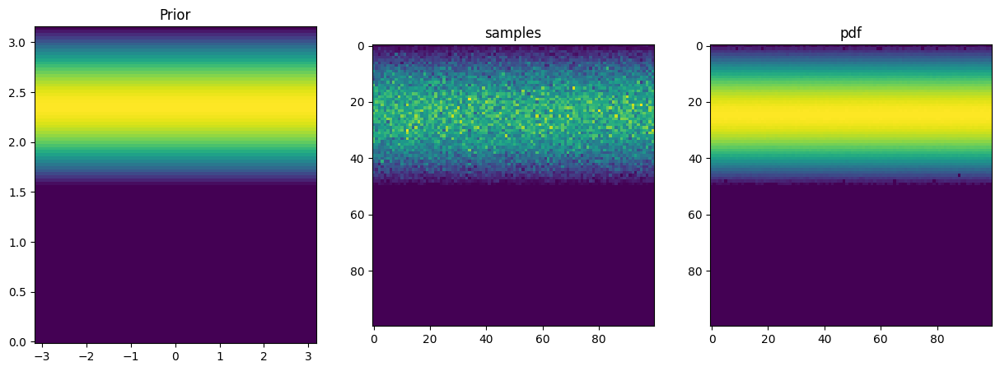

In [ ]:
bins = 100
num_samples = 100000

domainc = domain.cpu()

xx, yy = torch.meshgrid(
    torch.linspace(domain[0][0], domain[0][1], bins), 
    torch.linspace(domain[1][0], domain[1][1], bins)
)

zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)
zz = zz.to('cuda')

prior = priors.CosineWeighted()

N = torch.tensor([0, -1, 0], device = 'cuda', dtype=torch.float32)

prior_probs = prior.prob(zz, N, solid_angle=False).view(*xx.shape).detach().cpu()

# samples = prior.sample(num_samples, N.unsqueeze(0)).detach().cpu()
samples, pdf = prior.sample_with_pdf(num_samples, N.unsqueeze(0))
samples = samples.detach().cpu()
pdf = pdf.detach().cpu()

sample_grid, _, _ = np.histogram2d(
    samples[:, 0], samples[:, 1],
    bins=bins,
    range=domainc
)

pdf_grid, _, _ = np.histogram2d(
    samples[:, 0], samples[:, 1],
    bins=bins,
    range=domainc,
    weights=pdf
)



# average, safely handling empty bins
pdf_grid = np.divide(pdf_grid, sample_grid)
pdf_grid[(np.isnan(pdf_grid)) | (np.isinf(pdf_grid))] = 0

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].pcolormesh(xx, yy, prior_probs)
axs[0].set_title("Prior")

axs[1].imshow(np.flip(np.transpose(sample_grid, (1, 0)), 0))
axs[1].set_title("samples")

axs[2].imshow(np.flip(np.transpose(pdf_grid, (1, 0)), 0))
axs[2].set_title("pdf")


In [ ]:
rng = dr.rng(0)

p1 = rng.random(mi.Point2f, (2, 1))
p2 = rng.random(mi.Point2f, (2, 1))

print(p1)
print(p2)

p = dr.unravel(mi.Point2f, dr.concat([p1, p2], axis = None))

a = dr.arange(mi.Float, 3)  # [0, 1, 2]
b = dr.arange(mi.Float, 3, 6)  # [3, 4, 5]

case = dr.concat([a, b])  # -> [0, 1, 2, 3, 4, 5]

print(p)

10

(3, 10)


In [ ]:
### Old training loop

iterations = 5000

num_training_plots = 5
plot_every = int(iterations / num_training_plots if num_training_plots > 0 else iterations + 1)

loss_hist = np.array([])

clip_grad = True
clip_max_norm = 10

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

torch.autograd.set_detect_anomaly(False)

import time

generate_samples_time = 0.0
compute_gradient_time = 0.0
nan_check_clip_time   = 0.0
optimizer_time        = 0.0


num_samples = 2 ** 14
width = 256
height = 256

reset_opt = True

for it in tqdm.tqdm(range(iterations)):
    if reset_opt:
        optimizer.zero_grad()
        reset_opt = False

    start = time.time()

    with torch.no_grad():
        ## Ignores bsdf_pdf for mis aware optimization for now
        values, angles, normal, in_dir, pos, sample_pdf, _ = renderer.generate_samples(training_context, coordinate_system, model)

        values = values.mean(dim=-1)
        generate_samples_time += time.time() - start
    
    start = time.time()
    loss = model.compute_batch_gradient(probs_p = values,
                                        batch = angles, 
                                        normal=normal, 
                                        in_dir = in_dir,
                                        position=pos,
                                        batch_pdf = sample_pdf)
    

    # if it > 100:
    #     mult = 1.13
    #     if (loss > loss_hist[-1] * mult and
    #         loss > loss_hist[-2] * mult and
    #         loss > loss_hist[-3] * mult):

    #         print(f"Found increasing loss over the last 5 in iteration {it}")

    #         base_path = "./../../data/run_saves/"

    #         np.savetxt(base_path + f"values_{it}.txt", values.cpu().detach().numpy())
    #         np.savetxt(base_path + f"angles_{it}.txt", angles.cpu().detach().numpy())
    #         np.savetxt(base_path + f"normal_{it}.txt", normal.cpu().detach().numpy())
    #         np.savetxt(base_path + f"in_dir_{it}.txt", in_dir.cpu().detach().numpy())
    #         np.savetxt(base_path + f"pos_{it}.txt", pos.cpu().detach().numpy())
    #         np.savetxt(base_path + f"pdf_{it}.txt", sample_pdf.cpu().detach().numpy())


    compute_gradient_time += time.time() - start


    start = time.time()
    for p in model.parameters():
        if p.grad is not None:
            p.grad = torch.nan_to_num(p.grad)

    if clip_grad:
        ### Network and Encoding clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=clip_max_norm)

    nan_check_clip_time += time.time() - start


    loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())


    start = time.time()

    if it % 1 == 0 or it == iterations - 1:        
        optimizer.step()
        reset_opt = True
    optimizer_time = time.time() - start
    
    if (it != 0 or plot_every < iterations) and it % plot_every == 0: 
        fig = model.visualize(renderer, only_direct = training_context.only_direct, only_indirect = training_context.only_indirect)
        plt.show()


print(f"average generate_samples_time time {generate_samples_time / iterations}")
print(f"average compute_gradient_time time {compute_gradient_time / iterations}")
print(f"average nan_check_clip_time time {nan_check_clip_time / iterations}")
print(f"average optimizer_time time {optimizer_time / iterations}")


fig = model.visualize(renderer, only_direct = training_context.only_direct, only_indirect = training_context.only_indirect)
plt.show()

plt.figure(figsize=(10, 10))
plt.plot(loss_hist, label='loss')
plt.legend()
plt.show()

In [ ]:
# enable_cuda = True
# device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')


# coordinate_system = CoordinateSystem.Spherical
# # coordinate_system = CoordinateSystem.Cylindrical
# domain = utils.get_domain_from_coords(coordinate_system, device)


# # prior = priors.CosineWeighted(coordinate_system)
# prior = priors.UniformPrior(domain, coordinate_system)


# context = Context(bounces=4, spp=1, bsdf_sampling=True, emitter_sampling=True, mis_beta=2.0)


# # scene = scenes.env_scene_sphere()
# # scene = scenes.env_scene_sphere_metallic()
# # scene = scenes.env_scene_empty()
# scene = scenes.cbox()
# # scene = scenes.spaceship()
# # scene = scenes.kitchen()

# renderer = rr.Renderer(scene, context, coordinate_system)


# do_normal_encoding = True
# do_in_dir_encoding = True
# do_pos_encoding    = True

# model: models.AbstractModel = build_Normflow_model(prior, 
#                                                    domain, 
#                                                    coordinate_system,
#                                                    scene=scene,
#                                                    num_flows = 32, 
#                                                    num_bins = 12, 
#                                                    hidden_units=64, 
#                                                    hidden_layers=4,
#                                                    do_normal_encoding=do_normal_encoding,
#                                                    do_in_dir_encoding=do_in_dir_encoding,
#                                                    do_pos_encoding=do_pos_encoding,
#                                                    encode_pos_each_flow = True,
#                                                    latent_to_hash_enc   = True)





# def get_default_target(domain, normalize = False):
#     img = plt.imread('../assets/test_distributions/museum.jpg').sum(axis=-1)
#     # img = plt.imread('../assets/test_distributions/Uniform_Env.png').sum(axis=-1)
#     # img = plt.imread('../assets/test_distributions/Checkerboard.png')
#     # img = plt.imread('../assets/test_distributions/TestDist2.png').sum(axis=-1)
#     return targets.ImageTarget(img, domain = domain, normalize=normalize)


# target: targets.Target = targets.RendererTarget(renderer, coordinate_system)
# # target = get_default_target(domain).to(device)

# model.to(device)
# print(f"using device: {device}")

# # normal = None
# # if do_normal_encoding:
# #     normal = sample_normals(1, device = device).squeeze(0)


# # fig = model.visualize_old(target, normal = normal)
# # fig.show()


# fig = model.visualize(renderer)
# plt.show()

In [ ]:
p = {
    'type': 'plastic',
    'int_ior': 1.61,
    'diffuse_reflectance': {
        'type': 'rgb',
        'value': 0.5
    }
}


b: mi.BSDF = mi.load_dict(p)

si = renderer.sample_sensor_first_si()


for c in b.m_components:
    c &= 127
    # print(c)


ctx_delta = mi.BSDFContext(mode = mi.TransportMode.Radiance, type_mask=mi.BSDFFlags.Delta)
ctx_smooth = mi.BSDFContext(mode = mi.TransportMode.Radiance, type_mask=mi.BSDFFlags.Smooth)
ctx_all = mi.BSDFContext(mode = mi.TransportMode.Radiance)

sample1 =  renderer.rng.random(mi.Float, (1, ))
sample2 = renderer.rng.random(mi.Point2f, (2, 1))

bsdf_sample_all, _ =    b.sample(ctx_all, si, sample1, sample2)
bsdf_sample_delta, _ =  b.sample(ctx_delta, si, sample1, sample2)
bsdf_sample_smooth, _ = b.sample(ctx_smooth, si, sample1, sample2)

print(bsdf_sample_all.sampled_type)
print(bsdf_sample_all.pdf)
print(bsdf_sample_smooth.pdf)
print(bsdf_sample_delta.pdf)

print("-------------\n")

if (bsdf_sample_all.sampled_type[0] & mi.BSDFFlags.Smooth != 0):
    print(f"sampled smooth")
    print(f"p(x, l) = {bsdf_sample_all.pdf[0]}")
    print(f"p(x | l) = {bsdf_sample_smooth.pdf[0]}")
    print(f"p(l) = {bsdf_sample_all.pdf[0] / bsdf_sample_smooth.pdf[0]}")
elif (bsdf_sample_all.sampled_type[0] & mi.BSDFFlags.Delta != 0):
    print(f"sampled delta")
    print(f"p(x, l) = {bsdf_sample_all.pdf[0]}")
    print(f"p(x | l) = {bsdf_sample_delta.pdf[0]}")
    print(f"p(l) = {bsdf_sample_all.pdf[0] / bsdf_sample_delta.pdf[0]}")

print("-------------\n")

print(bsdf_sample_all.wo)
print(bsdf_sample_smooth.wo)
print(bsdf_sample_delta.wo)

In [ ]:
resolution = [100, 100]
colormap = 'jet'
only_direct = False
only_indirect = False

coord_system = CoordinateSystem.Spherical

domain = utils.get_domain_from_coords(coord_system, 'cuda')

xx, yy = torch.meshgrid(
    torch.linspace(domain[0][0], domain[0][1], resolution[0], ), 
    torch.linspace(domain[1][0], domain[1][1], resolution[1])
)

zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)
zz = zz.to('cuda')


si = renderer.sample_sensor_first_si()
        
### Evaluate target

context = contexts.Context(bounces = 4, 
    spp = 1,
    bsdf_sampling = True, 
    emitter_sampling = True,
    only_direct=only_direct,
    only_indirect=only_indirect
    )
        
distribution = renderer.build_distribution_on_surface(si, 
    resolution=resolution, 
    coordinate_system=coord_system, 
    include_brdf=True,
    render_context=context)

context = Context(bounces=4, spp=8, bsdf_sampling=True, emitter_sampling=True, mis_beta=2.0)

# distribution = renderer.build_distribution_floating(
#     si.p,
#     resolution=resolution, 
#     coordinate_system=coord_system, 
#     render_context = context
# )
        
target_prob = utils.res_to_numpy_1(distribution, resolution[0], resolution[1])

N = si.n.torch().transpose(0, 1)
wi = si.to_world(si.wi).torch().transpose(0, 1)
P = si.p.torch().transpose(0, 1)

# log_prob = self.log_prob(zz, N, wi, P)
# prob = log_prob.exp()

# prob = prob.to('cpu').view(*xx.shape) 
# prob[torch.isnan(prob)] = 0
# prob = np.transpose(prob.detach().numpy(), (1, 0))

ticks = np.linspace(0, 1, num = 5)
x_ticks = ticks * resolution[0]
y_ticks = ticks * resolution[1]
tick_labels = utils.get_plt_ticks_from_coords(coord_system)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

ax1.imshow(target_prob, cmap=colormap) 
ax1.set_title("Target")
ax1.set_xticks(ticks=x_ticks, labels = tick_labels[0])
ax1.set_yticks(ticks=y_ticks, labels = tick_labels[1])

# ax2.imshow(prob, cmap=colormap)
# ax2.set_title("Model Prediction")
# ax2.set_xticks(ticks=x_ticks, labels = tick_labels[0])
# ax2.set_yticks(ticks=y_ticks, labels = tick_labels[1])